#### ShiftLens: A Leakage-Controlled, Intervention-Based Diagnostic of Cross-Corpus Shift in Low-Resource Hate-Speech Detection




In [1]:
# ===================== CELL 02 =====================
from pathlib import Path
OUT_ROOT = Path(r"E:\Research\Attributing Cross-Corpus Failure\results")

In [2]:
# ===================== CELL 03 =====================
import os
print(os.listdir(r"E:\Research\Attributing Cross-Corpus Failure"))

['Article_Title__1_.zip', 'backup', 'cohens_kappa.ipynb', 'data', 'disagreements.csv', 'Download+the+journal+article+template+package+(December+2024+version)', 'Download+the+journal+article+template+package+(December+2024+version).zip', 'figures', 'final_annotated_5000.csv', 'images', 'notebook', 'outputs', 'paper', 'README.md', 'results', 'Shiftlens', 'ShiftLens.ipynb', 'ShiftLens_Merged_FullRun.ipynb']


In [6]:
# ===================== CELL 06 =====================

import os, re, json, math, time, random, hashlib, itertools, warnings, platform, sys, pickle
from pathlib import Path
from dataclasses import dataclass, asdict
from collections import Counter
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    f1_score, precision_recall_fscore_support, balanced_accuracy_score,
    roc_auc_score, average_precision_score, confusion_matrix
)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
try:
    from IPython.display import display
except Exception:
    def display(x): print(x)

try:
    from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
    TRANSFORMERS_AVAILABLE = True
except Exception as exc:
    TRANSFORMERS_AVAILABLE = False
    print("Transformers is not available yet:", exc)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

Python: 3.11.9
PyTorch: 2.11.0+cpu
Device: cpu


In [ ]:
# ===================== CELL 07 =====================

FIG_STYLE_PALETTE = ["#1B2A4A", "#B5442E", "#3E7C59", "#B08A3E", "#5B5B5B", "#7A5C82"]

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "DejaVu Serif"],
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "axes.edgecolor": "#333333",
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "grid.color": "#DDDDDD",
    "grid.linewidth": 0.5,
    "axes.axisbelow": True,
    "figure.dpi": 220,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})
sns.set_palette(FIG_STYLE_PALETTE)

FIG_STYLE_1COL = (3.3, 2.5)
FIG_STYLE_2COL = (6.75, 2.9)

FIG_DIR = Path(os.environ.get("SHIFTLENS_OUT_DIR", r"E:\Research\Attributing Cross-Corpus Failure\results")) / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print("Plotting style set. Figures will be written to:", FIG_DIR)


Plotting style set. Figures will be written to: E:\Research\Attributing Cross-Corpus Failure\results\figures


In [ ]:
# ===================== CELL 09 =====================
import os
import json
import numpy as np
from pathlib import Path


class CFG:
    DATA_ROOT = os.environ.get(
        "SHIFTLENS_DATA_ROOT",
        r"E:\Research\Attributing Cross-Corpus Failure\data",
    )
    YOUTUBE_CSV     = f"{DATA_ROOT}/YouTube-BN/youtube_bn_annotated.csv"
    BDSHS_DIR       = f"{DATA_ROOT}/BD-SHS"
    HATEXPLAIN_DIR  = f"{DATA_ROOT}/HateXplain"
    BENGALIHATE_DIR = f"{DATA_ROOT}/Bengali Hate"

    OUT_DIR = os.environ.get(
        "SHIFTLENS_OUT_DIR",
        r"E:\Research\Attributing Cross-Corpus Failure\results",
    )

    BACKBONE   = os.environ.get("SHIFTLENS_BACKBONE", "xlm-roberta-base")
    MAX_LENGTH = int(os.environ.get("SHIFTLENS_MAX_LENGTH", "128"))

    TRAIN_FRAC   = 0.55
    VAL_FRAC     = 0.15
    ADAPT_FRAC   = 0.10
    TEST_FRAC    = 0.15
    RESERVE_FRAC = 0.05

    SEEDS = [int(x) for x in os.environ.get(
        "SHIFTLENS_SEEDS", "13,42,2024,3407,9001").split(",") if x.strip()]

    FACTORS = ["content", "protocol"]
    MODELS = [x.strip() for x in os.environ.get(
        "SHIFTLENS_MODELS",
        "MAJORITY,TFIDF_LOGREG,ERM,DANN,CORAL,PROTOCOL_CORRECTED").split(",") if x.strip()]
    ROBUSTNESS_MODELS = [x.strip() for x in os.environ.get(
        "SHIFTLENS_ROBUSTNESS_MODELS", "TFIDF_LOGREG").split(",") if x.strip()]

    BATCH_SIZE       = int(os.environ.get("SHIFTLENS_BATCH_SIZE", "8"))
    EVAL_BATCH_SIZE  = int(os.environ.get("SHIFTLENS_EVAL_BATCH_SIZE", "32"))
    GRAD_ACCUM_STEPS = int(os.environ.get("SHIFTLENS_GRAD_ACCUM_STEPS", "4"))
    EPOCHS           = int(os.environ.get("SHIFTLENS_EPOCHS", "4"))
    LR            = 2e-5
    WEIGHT_DECAY  = 0.01
    WARMUP_FRAC   = 0.06
    MAX_GRAD_NORM = 1.0
    DOMAIN_WEIGHT = 0.10
    CORAL_WEIGHT  = 0.10
    MIXED_PRECISION = os.environ.get("SHIFTLENS_MIXED_PRECISION", "1") == "1"

    NUM_WORKERS = int(os.environ.get("SHIFTLENS_NUM_WORKERS", "0"))

    CONTENT_STRENGTH = 2.0
    CONTENT_TARGET_TOPICS = ["Religious", "Geopolitical", "Gender abusive"]
    PROTOCOL_TRANSITION = np.array([[0.90, 0.10],
                                    [0.20, 0.80]], dtype=np.float64)

    N_BOOTSTRAP = 5000

    RUN_TRAINING   = os.environ.get("SHIFTLENS_RUN_TRAINING", "0") == "1"
    RUN_REAL_EVAL  = os.environ.get("SHIFTLENS_RUN_REAL_EVAL", "0") == "1"
    RUN_ROBUSTNESS = os.environ.get("SHIFTLENS_RUN_ROBUSTNESS", "0") == "1"
    SMOKE_TEST     = os.environ.get("SHIFTLENS_SMOKE_TEST", "1") == "1"

    @staticmethod
    def paths():
        root = Path(CFG.OUT_DIR)
        for sub in ["tables", "figures", "checkpoints", "logs", "manifests"]:
            (root / sub).mkdir(parents=True, exist_ok=True)
        return root


OUT_ROOT = CFG.paths()

CFG.TEST_FRAC = round(1.0 - CFG.TRAIN_FRAC - CFG.VAL_FRAC - CFG.ADAPT_FRAC - CFG.RESERVE_FRAC, 4)

assert abs(CFG.TRAIN_FRAC + CFG.VAL_FRAC + CFG.ADAPT_FRAC + CFG.TEST_FRAC + CFG.RESERVE_FRAC - 1.0) < 1e-9
assert np.allclose(CFG.PROTOCOL_TRANSITION.sum(axis=1), 1.0)
assert len(CFG.SEEDS) >= 5, "The final reported run must use at least five independent seeds."

print("=" * 70)
print("SHIFTLENS — LOCAL PC CONFIGURATION")
print("=" * 70)
print(json.dumps({k: v for k, v in vars(CFG).items()
                  if not k.startswith("_") and not callable(v)}, indent=2, default=str))
print("=" * 70)
print(f"DATA_ROOT : {CFG.DATA_ROOT}")
print(f"OUT_DIR   : {CFG.OUT_DIR}")
print(f"OUT_ROOT  : {OUT_ROOT}")
print("=" * 70)

print("\nChecking dataset paths...\n")
for name, path in {
    "DATA_ROOT":    CFG.DATA_ROOT,
    "YOUTUBE_CSV":  CFG.YOUTUBE_CSV,
    "BD-SHS":       CFG.BDSHS_DIR,
    "HateXplain":   CFG.HATEXPLAIN_DIR,
    "Bengali Hate": CFG.BENGALIHATE_DIR,
}.items():
    print(f"[{'OK' if Path(path).exists() else 'MISSING':7}] {name:15} -> {path}")

print("\nChecking output directories...\n")
for sub in ["tables", "figures", "checkpoints", "logs", "manifests"]:
    p = Path(CFG.OUT_DIR) / sub
    print(f"[{'OK' if p.exists() else 'MISSING':7}] {p}")

print("\nGPU information:\n")
try:
    import torch
    print(f"PyTorch version : {torch.__version__}")
    print(f"CUDA available  : {torch.cuda.is_available()}")
    if torch.cuda.is_available():
        print(f"GPU             : {torch.cuda.get_device_name(0)}")
        print(f"GPU VRAM        : {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")
    else:
        print("WARNING: No CUDA GPU detected (BanglaBERT/mDeBERTa training needs an NVIDIA GPU).")
except Exception as e:
    print("Could not check GPU:", repr(e))

print("\n" + "=" * 70)
print("CONFIGURATION READY")
print("=" * 70)
print(f"Smoke test      : {CFG.SMOKE_TEST}")
print(f"Training        : {CFG.RUN_TRAINING}")
print(f"Real evaluation : {CFG.RUN_REAL_EVAL}")
print(f"Robustness      : {CFG.RUN_ROBUSTNESS}")
print("=" * 70)

SHIFTLENS — LOCAL PC CONFIGURATION
{
  "DATA_ROOT": "E:\\Research\\Attributing Cross-Corpus Failure\\data",
  "YOUTUBE_CSV": "E:\\Research\\Attributing Cross-Corpus Failure\\data/YouTube-BN/youtube_bn_annotated.csv",
  "BDSHS_DIR": "E:\\Research\\Attributing Cross-Corpus Failure\\data/BD-SHS",
  "HATEXPLAIN_DIR": "E:\\Research\\Attributing Cross-Corpus Failure\\data/HateXplain",
  "BENGALIHATE_DIR": "E:\\Research\\Attributing Cross-Corpus Failure\\data/Bengali Hate",
  "OUT_DIR": "E:\\Research\\Attributing Cross-Corpus Failure\\results",
  "BACKBONE": "xlm-roberta-base",
  "MAX_LENGTH": 128,
  "TRAIN_FRAC": 0.55,
  "VAL_FRAC": 0.15,
  "ADAPT_FRAC": 0.1,
  "TEST_FRAC": 0.15,
  "RESERVE_FRAC": 0.05,
  "SEEDS": [
    13,
    42,
    2024,
    3407,
    9001
  ],
  "FACTORS": [
    "content",
    "protocol"
  ],
  "MODELS": [
    "MAJORITY",
    "TFIDF_LOGREG",
    "ERM",
    "DANN",
    "CORAL",
    "PROTOCOL_CORRECTED"
  ],
  "ROBUSTNESS_MODELS": [
    "TFIDF_LOGREG"
  ],
  "BATCH_SIZE":

In [ ]:
# ===================== CELL 12 =====================


def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def jsonable_config():
    return {
        "backbone": CFG.BACKBONE,
        "max_length": CFG.MAX_LENGTH,
        "seeds": CFG.SEEDS,
        "factors": CFG.FACTORS,
        "models": CFG.MODELS,
        "train_frac": CFG.TRAIN_FRAC,
        "val_frac": CFG.VAL_FRAC,
        "adapt_frac": CFG.ADAPT_FRAC,
        "test_frac": CFG.TEST_FRAC,
        "content_strength": CFG.CONTENT_STRENGTH,
        "content_target_topics": CFG.CONTENT_TARGET_TOPICS,
        "protocol_transition": CFG.PROTOCOL_TRANSITION.tolist(),
        "epochs": CFG.EPOCHS,
    }

def config_hash():
    payload = json.dumps(jsonable_config(), sort_keys=True).encode()
    return hashlib.sha256(payload).hexdigest()[:16]

def text_hash(text):
    norm = re.sub(r"\s+", " ", str(text).strip().lower())
    return hashlib.sha256(norm.encode("utf-8", "ignore")).hexdigest()[:20]

def atomic_csv(df, path):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + ".tmp")
    df.to_csv(tmp, index=False)
    tmp.replace(path)

def append_deduplicated(df_new, path, keys):
    path = Path(path)
    if path.exists():
        df_old = pd.read_csv(path)
        df = pd.concat([df_old, df_new], ignore_index=True)
    else:
        df = df_new.copy()
    df = df.drop_duplicates(keys, keep="last")
    atomic_csv(df, path)
    return df

RUN_ID = config_hash()
RUN_METADATA = {
    "run_id": RUN_ID,
    "python": sys.version,
    "platform": platform.platform(),
    "torch": torch.__version__,
    "cuda": torch.cuda.is_available(),
    "device": str(DEVICE),
    "config": jsonable_config(),
}
(OUT_ROOT / "manifests" / "run_metadata.json").write_text(json.dumps(RUN_METADATA, indent=2, default=str))
set_seed(CFG.SEEDS[0])
print("RUN_ID:", RUN_ID)

RUN_ID: c923a2aa33c46e90


## 5. Data provenance and harmonization

All source data are loaded into one explicit schema. A corpus is not treated as a clean target merely because it has a different name: provenance, label semantics, platform, language/register, and annotation reliability are recorded separately.

The anchor corpus is used to create the synthetic factorial. External corpora are **never** used to choose hyperparameters, thresholds, model checkpoints, intervention strengths, or synthetic topics. They are used only for the held-out real-corpus stress test.

In [ ]:
# ===================== CELL 14 =====================


SCHEMA = [
    "text",
    "source",
    "true_label",
    "topic",
    "target_group",
    "language",
    "platform",
    "is_reliable",
    "official_split",
]

POSITIVE = {
    "1", "true", "yes", "hate", "hateful", "offensive",
    "abusive", "bullying", "bully", "toxic",
}

NEGATIVE = {
    "0", "false", "no", "normal", "non-abusive", "non abusive",
    "not bully", "not_bully", "none", "neutral", "clean",
}


def read_csv_robust(path, **kwargs):
    """Read a CSV trying several encodings (Windows files are often not plain UTF-8)."""
    last_err = None
    for enc in ["utf-8-sig", "utf-8", "utf-16", "cp1252", "latin-1"]:
        try:
            df = pd.read_csv(path, encoding=enc, **kwargs)
            if enc not in ("utf-8-sig", "utf-8"):
                print(f"[encoding] {Path(path).name}: read with {enc} -- check that Bangla text looks correct")
            return df
        except (UnicodeDecodeError, UnicodeError) as e:
            last_err = e
    raise last_err


def parse_binary(values):
    out = []

    for v in values:
        if pd.isna(v):
            out.append(np.nan)
            continue

        s = str(v).strip().lower()

        try:
            x = float(s)
            out.append(float(x) if x in (0.0, 1.0) else np.nan)
            continue
        except Exception:
            pass

        if s in POSITIVE:
            out.append(1.0)
        elif s in NEGATIVE:
            out.append(0.0)
        else:
            out.append(np.nan)

    return pd.Series(out, index=values.index, dtype="float64")


def pick_col(df, candidates, fallback=None):
    lower = {str(c).lower(): c for c in df.columns}

    for c in candidates:
        if c.lower() in lower:
            return lower[c.lower()]

    return fallback


def standardize(
    text,
    source,
    raw_label=None,
    topic=None,
    target_group=None,
    language="bn",
    platform="unknown",
    is_reliable=True,
    true_label_override=None,
    official_split=None,
):
    n = len(text)

    if true_label_override is not None:
        parsed_labels = (
            pd.Series(true_label_override)
            .astype(float)
            .reset_index(drop=True)
        )
    else:
        raw_values = raw_label if raw_label is not None else [np.nan] * n
        parsed_labels = parse_binary(pd.Series(raw_values)).reset_index(drop=True)

    result = pd.DataFrame({
        "text": (
            pd.Series(text)
            .astype(str)
            .str.replace(r"\s+", " ", regex=True)
            .str.strip()
            .reset_index(drop=True)
        ),
        "source": source,
        "true_label": parsed_labels,
        "topic": pd.Series(
            topic if topic is not None else ["__unknown__"] * n
        ).astype(str).reset_index(drop=True),
        "target_group": pd.Series(
            target_group if target_group is not None else ["__unknown__"] * n
        ).astype(str).reset_index(drop=True),
        "language": pd.Series(
            language if not isinstance(language, str) else [language] * n
        ).astype(str).reset_index(drop=True),
        "platform": pd.Series(
            platform if not isinstance(platform, str) else [platform] * n
        ).astype(str).reset_index(drop=True),
        "is_reliable": bool(is_reliable),
        "official_split": pd.Series(
            official_split if official_split is not None else ["__none__"] * n
        ).astype(str).reset_index(drop=True),
    })

    result["text_hash"] = result["text"].map(text_hash)
    result = result[result["text"].str.len() > 0].reset_index(drop=True)

    if len(result) and bool(result["is_reliable"].iloc[0]):
        result = result[
            result["true_label"].isin([0.0, 1.0])
        ].reset_index(drop=True)

    return result


def read_first_csv(directory, names=None):
    directory = Path(directory)

    if not directory.exists():
        raise FileNotFoundError(directory)

    candidates = []

    if names:
        candidates.extend(directory / n for n in names)

    candidates.extend(sorted(directory.glob("*.csv")))

    for p in candidates:
        if p.exists():
            return read_csv_robust(p), p

    raise FileNotFoundError(f"No CSV found in {directory}")


def load_youtube():
    csv_path = Path(CFG.YOUTUBE_CSV)

    if not csv_path.exists():
        found = sorted(Path(CFG.DATA_ROOT).rglob("*[Yy]ou[Tt]ube*.csv"))
        if not found:
            raise FileNotFoundError(
                f"YouTube CSV not found at {csv_path} and no *youtube*.csv under {CFG.DATA_ROOT}"
            )
        csv_path = found[0]
        print(f"[path] YOUTUBE_CSV not at the configured path; using {csv_path}")

    df = read_csv_robust(csv_path)

    text_col = pick_col(
        df,
        ["text", "sentence", "comment"],
        df.columns[0],
    )
    label_col = pick_col(
        df,
        ["label", "category", "class"],
        df.columns[1],
    )

    raw = df[label_col].astype("string").str.strip()

    allowed = {
        "non-abusive",
        "religious",
        "personal",
        "political",
        "geopolitical",
        "gender abusive",
    }

    observed = set(raw.dropna().str.lower().unique())
    unknown = sorted(observed - allowed)

    if unknown or raw.isna().any() or (raw == "").any():
        raise ValueError(
            "Unexpected/missing YouTube labels: "
            f"unknown={unknown}, "
            f"missing={int(raw.isna().sum())}, "
            f"label_column='{label_col}', columns={list(df.columns)}"
        )

    binary = (
        raw.str.lower()
        .map({"non-abusive": 0.0})
        .fillna(1.0)
        .astype(float)
    )

    lang_col = pick_col(df, ["lang", "language"])

    return standardize(
        df[text_col],
        "YouTube",
        raw_label=raw,
        topic=raw,
        language=df[lang_col] if lang_col else "bn",
        platform="YouTube",
        is_reliable=True,
        true_label_override=binary,
    )


def load_bdshs():
    parts = []

    for name in ["train.csv", "val.csv", "validation.csv", "test.csv"]:
        p = Path(CFG.BDSHS_DIR) / name

        if p.exists():
            part = read_csv_robust(p)
            part["__official_split"] = Path(name).stem
            parts.append(part)

    if not parts:
        raise FileNotFoundError(CFG.BDSHS_DIR)

    df = pd.concat(parts, ignore_index=True)

    text_col = pick_col(
        df,
        ["sentence", "text", "comment"],
        df.columns[0],
    )
    label_col = pick_col(
        df,
        ["hate speech", "hate_speech", "label", "class"],
        df.columns[1],
    )
    topic_col = pick_col(df, ["type", "category", "topic"])
    target_col = pick_col(df, ["target", "target_group"])

    return standardize(
        df[text_col],
        "BD-SHS",
        raw_label=df[label_col],
        topic=df[topic_col] if topic_col else None,
        target_group=df[target_col] if target_col else None,
        language="bn",
        platform="Facebook",
        is_reliable=True,
        official_split=df["__official_split"],
    )


def load_hatexplain():
    parts = []

    for name in ["train.csv", "validation.csv", "val.csv", "test.csv"]:
        p = Path(CFG.HATEXPLAIN_DIR) / name

        if p.exists():
            part = read_csv_robust(p)
            part["__official_split"] = Path(name).stem
            parts.append(part)

    if not parts:
        raise FileNotFoundError(CFG.HATEXPLAIN_DIR)

    df = pd.concat(parts, ignore_index=True)

    text_col = pick_col(
        df,
        ["text", "post", "comment"],
        df.columns[0],
    )
    label_col = pick_col(
        df,
        ["label", "class", "gold_label"],
        df.columns[1],
    )

    raw = df[label_col].astype(str).str.strip().str.lower()


    binary = raw.map({
        "normal": 0.0,
        "hatespeech": 1.0,
    })

    return standardize(
        df[text_col],
        "HateXplain",
        raw_label=raw,
        true_label_override=binary,
        language="en/code-mixed",
        platform="Twitter/Gab",
        is_reliable=True,
        official_split=df["__official_split"],
    )


def load_all():
    loaders = {
        "YouTube": load_youtube,
        "BD-SHS": load_bdshs,
        "HateXplain": load_hatexplain,
    }

    raw, errors = {}, {}

    for name, fn in loaders.items():
        try:
            raw[name] = fn()
        except Exception as exc:
            errors[name] = f"{type(exc).__name__}: {exc}"
            print(f"[LOAD FAILED] {name} -> {errors[name]}")

    return raw, errors


print("DATA_ROOT   :", CFG.DATA_ROOT, "| exists:", Path(CFG.DATA_ROOT).exists())
print("YOUTUBE_CSV :", CFG.YOUTUBE_CSV, "| exists:", Path(CFG.YOUTUBE_CSV).exists())

RAW, LOAD_ERRORS = load_all()

if LOAD_ERRORS:
    print("Load notes:", json.dumps(LOAD_ERRORS, indent=2, ensure_ascii=False))

if RAW:
    FULL = pd.concat(RAW.values(), ignore_index=True)
    print(
        FULL.groupby(
            ["source", "is_reliable"],
            dropna=False,
        ).size().rename("n")
    )
else:
    FULL = pd.DataFrame(columns=SCHEMA + ["text_hash"])

print("Loaded sources:", sorted(RAW.keys()))

DATA_ROOT   : E:\Research\Attributing Cross-Corpus Failure\data | exists: True
YOUTUBE_CSV : E:\Research\Attributing Cross-Corpus Failure\data/YouTube-BN/youtube_bn_annotated.csv | exists: True
source      is_reliable
BD-SHS      True           50281
HateXplain  True           13749
YouTube     True           67982
Name: n, dtype: int64
Loaded sources: ['BD-SHS', 'HateXplain', 'YouTube']


In [ ]:
# ===================== CELL 15 =====================


def validate_corpus(df):
    assert df["text"].notna().all(), "Missing text detected."
    assert (df["text"].str.len() > 0).all(), "Empty text detected."
    assert df["text_hash"].notna().all()
    reliable = df[df["is_reliable"]]
    if len(reliable):
        assert reliable["true_label"].isin([0.0, 1.0]).all(), "Reliable labels must be binary."
        assert reliable["true_label"].nunique() == 2, "Reliable corpus must contain both classes."
    return {
        "n": int(len(df)),
        "n_unique_text": int(df["text_hash"].nunique()),
        "duplicate_rate": float(1 - df["text_hash"].nunique() / max(len(df), 1)),
        "reliable": bool(df["is_reliable"].all()),
        "label_coverage": float(df["true_label"].notna().mean()),
        "positive_rate": float(df["true_label"].mean()) if df["true_label"].notna().any() else np.nan,
    }

SUMMARY = []
for source, df in RAW.items():
    try: report = validate_corpus(df)
    except AssertionError as exc: report = {"n": len(df), "validation_error": str(exc)}
    report["source"] = source
    SUMMARY.append(report)
summary_df = pd.DataFrame(SUMMARY)
display(summary_df)
summary_df.to_csv(OUT_ROOT / "tables" / "corpus_summary.csv", index=False)

anchor_hashes = set(RAW.get("YouTube", pd.DataFrame(columns=["text_hash"]))["text_hash"])
OVERLAP = []
for source, df in RAW.items():
    if source == "YouTube": continue
    n_overlap = int(df["text_hash"].isin(anchor_hashes).sum())
    OVERLAP.append({"source": source, "overlap_with_anchor": n_overlap, "rate": n_overlap / max(len(df), 1)})
OVERLAP_DF = pd.DataFrame(OVERLAP)
display(OVERLAP_DF)
OVERLAP_DF.to_csv(OUT_ROOT / "tables" / "anchor_overlap.csv", index=False)

,n,n_unique_text,duplicate_rate,reliable,label_coverage,positive_rate,source
0,67982,67981,0.000015,True,1.0,0.515489,YouTube
1,50281,50276,0.000099,True,1.0,0.480420,BD-SHS
2,13749,13724,0.001818,True,1.0,0.431668,HateXplain


,source,overlap_with_anchor,rate
0,BD-SHS,169,0.003361
1,HateXplain,0,0.000000


## 6. Grouped anchor split and leakage prevention

The anchor corpus is split by normalized text hash, not by raw row. This prevents duplicated comments or near-identical rows from crossing train, adaptation, validation, and evaluation sets. The split is performed once with a declared seed and saved as a manifest. The evaluation labels are never used for model selection.

In [ ]:
# ===================== CELL 17 =====================


def group_stratified_split(df, fractions, seed):
    df = df.copy().reset_index(drop=True)
    assert len(fractions) == 5 and abs(sum(fractions) - 1.0) < 1e-8
    label_nunique = df.groupby("text_hash")["true_label"].nunique(dropna=False)
    assert (label_nunique <= 1).all(), "Conflicting labels within an exact-text group require manual adjudication."
    group = df.groupby("text_hash", as_index=False)["true_label"].first()
    remaining_groups = group["text_hash"].to_numpy()
    remaining_y = group["true_label"].to_numpy().astype(int)
    names = ["train", "val", "adapt", "test", "reserve"]
    split_groups = {}
    for i, name in enumerate(names[:-1]):
        share = fractions[i] / sum(fractions[i:])
        chosen, remaining_groups, _, remaining_y = train_test_split(
            remaining_groups, remaining_y, train_size=share,
            random_state=seed + i, stratify=remaining_y
        )
        split_groups[name] = set(chosen)
    split_groups["reserve"] = set(remaining_groups)
    result = {name: df[df["text_hash"].isin(hashes)].copy().reset_index(drop=True)
              for name, hashes in split_groups.items()}
    assert set.union(*split_groups.values()) == set(group["text_hash"])
    assert sum(len(x) for x in split_groups.values()) == len(split_groups["train"] | split_groups["val"] | split_groups["adapt"] | split_groups["test"] | split_groups["reserve"])
    assert all(len(split_groups[a] & split_groups[b]) == 0 for i, a in enumerate(names) for b in names[i+1:])
    return result

require_anchor = "YouTube" in RAW and RAW["YouTube"]["true_label"].notna().all()
if not require_anchor:
    raise RuntimeError("The YouTube anchor corpus with reliable binary labels is required. Check CFG.DATA_ROOT and loader mappings.")

ANCHOR = RAW["YouTube"].copy()
ANCHOR_SPLITS = group_stratified_split(ANCHOR, [CFG.TRAIN_FRAC, CFG.VAL_FRAC, CFG.ADAPT_FRAC, CFG.TEST_FRAC, CFG.RESERVE_FRAC], CFG.SEEDS[0])
SPLIT_MANIFEST = []
for split_name, split_df in ANCHOR_SPLITS.items():
    split_df = split_df.copy()
    split_df["split"] = split_name
    SPLIT_MANIFEST.append(split_df[["text_hash", "source", "true_label", "split"]])
SPLIT_MANIFEST_DF = pd.concat(SPLIT_MANIFEST, ignore_index=True)
SPLIT_MANIFEST_DF.to_csv(OUT_ROOT / "manifests" / "anchor_split_manifest.csv", index=False)
print({k: len(v) for k, v in ANCHOR_SPLITS.items()})
print(pd.DataFrame({k: v["true_label"].mean() for k, v in ANCHOR_SPLITS.items()}, index=["positive_rate"]))

{'train': 37390, 'val': 10197, 'adapt': 6798, 'test': 10197, 'reserve': 3400}
                  train       val     adapt      test   reserve
positive_rate  0.515485  0.515446  0.515446  0.515544  0.515588


In [ ]:
# ===================== CELL 18 =====================

def external_target_split(df, seed):
    df = df.copy().reset_index(drop=True)
    if "official_split" in df.columns and (df["official_split"].astype(str).str.lower() == "test").any():
        test = df[df["official_split"].astype(str).str.lower() == "test"].copy()
        adapt = df[df["official_split"].astype(str).str.lower() != "test"].copy()
        overlap = set(adapt["text_hash"]) & set(test["text_hash"])
        if overlap:
            adapt = adapt[~adapt["text_hash"].isin(overlap)].copy()
            print(f"External official split overlap: dropped {len(overlap)} text groups from adapt; official test preserved.")
        return {"adapt": adapt.reset_index(drop=True), "test": test.reset_index(drop=True)}
    if len(df) < 10:
        return {"adapt": df.iloc[0:0].copy(), "test": df.copy()}
    group_df = df[["text_hash", "true_label"]].drop_duplicates("text_hash").reset_index(drop=True)
    if group_df["true_label"].nunique() < 2:
        adapt_hash, test_hash = train_test_split(group_df["text_hash"].to_numpy(), test_size=0.50, random_state=seed)
    else:
        adapt_hash, test_hash = train_test_split(
            group_df["text_hash"].to_numpy(),
            test_size=0.50,
            random_state=seed,
            stratify=group_df["true_label"].to_numpy(),
        )
    adapt_set, test_set = set(adapt_hash), set(test_hash)
    assert not adapt_set & test_set
    return {
        "adapt": df[df["text_hash"].isin(adapt_set)].copy().reset_index(drop=True),
        "test": df[df["text_hash"].isin(test_set)].copy().reset_index(drop=True),
    }

REAL_TARGET_SPLITS = {}
for source, df in RAW.items():
    if source == "YouTube":
        continue
    clean = df[~df["text_hash"].isin(anchor_hashes)].copy()
    REAL_TARGET_SPLITS[source] = external_target_split(clean, CFG.SEEDS[0])
print({k: {s: len(v) for s, v in d.items()} for k, d in REAL_TARGET_SPLITS.items()})


External official split overlap: dropped 2 text groups from adapt; official test preserved.
External official split overlap: dropped 2 text groups from adapt; official test preserved.
{'BD-SHS': {'adapt': 45097, 'test': 5013}, 'HateXplain': {'adapt': 12369, 'test': 1376}}


**[CELL 19]**

## 7. Identifiable intervention design

The factorial has exactly two factors because only two interventions can be isolated without inventing a false platform or language transformation.

### Content intervention

For each class separately, the target evaluation/adaptation pools are re-sampled without replacement from a disjoint adaptation/test/reserve candidate pool. The intervention changes only topic-composition weights, using topics already annotated in the anchor corpus; class prior, pool sizes, and hash-level disjointness are preserved. The operator is deterministic given the seed and does not create synthetic text.

### Protocol intervention

The source training labels are corrupted using a declared class-conditional transition matrix. The latent clean labels remain available only for audit and clean evaluation. The model sees `observed_label`, not `true_label`. This creates a known annotation-protocol shift without changing the text distribution.

### External shift

BD-SHS, HateXplain, and BengaliHate are not assigned synthetic factor labels. They are external stress tests. The notebook reports descriptive shift signatures and out-of-distribution flags, but it does not compute a causal or Shapley attribution for them.

In [ ]:
# ===================== CELL 20 =====================


def content_shift_pools(base_adapt, base_test, reserve, on, seed, strength=None):
    if not on:
        return base_adapt.copy().reset_index(drop=True), base_test.copy().reset_index(drop=True)
    strength = CFG.CONTENT_STRENGTH if strength is None else float(strength)
    candidate = pd.concat([base_adapt, base_test, reserve], ignore_index=True)
    rng = np.random.default_rng(seed)
    adapt_parts, test_parts = [], []
    for y in [0, 1]:
        sub = candidate[candidate["true_label"].astype(int) == y].copy()
        n_adapt = int((base_adapt["true_label"].astype(int) == y).sum())
        n_test = int((base_test["true_label"].astype(int) == y).sum())
        assert len(sub) >= n_adapt + n_test
        topic = sub["topic"].fillna("__unknown__").astype(str)
        weights = np.ones(len(sub), dtype=float)
        weights[topic.isin(CFG.CONTENT_TARGET_TOPICS).to_numpy()] *= (1.0 + strength)
        weights = weights / weights.sum()
        chosen = rng.choice(np.arange(len(sub)), size=n_adapt + n_test, replace=False, p=weights)
        picked = sub.iloc[chosen].reset_index(drop=True)
        adapt_parts.append(picked.iloc[:n_adapt])
        test_parts.append(picked.iloc[n_adapt:n_adapt+n_test])
    adapt = pd.concat(adapt_parts, ignore_index=True).sample(frac=1.0, random_state=seed).reset_index(drop=True)
    test = pd.concat(test_parts, ignore_index=True).sample(frac=1.0, random_state=seed + 1).reset_index(drop=True)
    assert len(adapt) == len(base_adapt) and len(test) == len(base_test)
    assert adapt["true_label"].value_counts().sort_index().equals(base_adapt["true_label"].value_counts().sort_index())
    assert test["true_label"].value_counts().sort_index().equals(base_test["true_label"].value_counts().sort_index())
    assert set(adapt["text_hash"]).isdisjoint(set(test["text_hash"]))
    return adapt, test

def protocol_shift(df, on, seed):
    out = df.copy().reset_index(drop=True)
    out["observed_label"] = out["true_label"].astype(float)
    if not on: return out
    rng = np.random.default_rng(seed)
    y = out["true_label"].astype(int).to_numpy()
    observed = [rng.choice([0, 1], p=CFG.PROTOCOL_TRANSITION[yi]) for yi in y]
    out["observed_label"] = np.asarray(observed, dtype=float)
    out["protocol_on"] = 1
    return out

def build_factorial_cell(content_on, protocol_on, seed):
    train = protocol_shift(ANCHOR_SPLITS["train"], protocol_on, seed + 101)
    val = protocol_shift(ANCHOR_SPLITS["val"], protocol_on, seed + 102)
    adapt, test = content_shift_pools(ANCHOR_SPLITS["adapt"], ANCHOR_SPLITS["test"], ANCHOR_SPLITS["reserve"], content_on, seed + 103)
    for frame in [train, val]: frame["observed_label"] = frame["observed_label"].astype(int)
    return {
        "train": train, "val": val, "adapt": adapt,
        "test": test, "content_on": int(content_on), "protocol_on": int(protocol_on), "seed": int(seed)
    }

for seed in CFG.SEEDS[:2]:
    for c, p in itertools.product([0, 1], repeat=2):
        cell = build_factorial_cell(c, p, seed)
        assert len(cell["train"]) == len(ANCHOR_SPLITS["train"])
        assert len(cell["test"]) == len(ANCHOR_SPLITS["test"])
        assert cell["test"]["true_label"].mean() == ANCHOR_SPLITS["test"]["true_label"].mean()
        assert set(cell["adapt"]["text_hash"]).isdisjoint(set(cell["test"]["text_hash"]))
        assert set(cell["adapt"]["text_hash"]).isdisjoint(set(cell["train"]["text_hash"]))
        assert set(cell["test"]["text_hash"]).isdisjoint(set(cell["train"]["text_hash"]))
        if p == 0:
            assert np.array_equal(cell["train"]["observed_label"], cell["train"]["true_label"])
print("Intervention unit tests passed.")

Intervention unit tests passed.


In [ ]:
# ===================== CELL 21 =====================

AUDIT = []
for c, p in itertools.product([0, 1], repeat=2):
    cell = build_factorial_cell(c, p, CFG.SEEDS[0])
    AUDIT.append({
        "content_on": c, "protocol_on": p,
        "train_n": len(cell["train"]), "test_n": len(cell["test"]),
        "train_true_pos_rate": cell["train"]["true_label"].mean(),
        "train_observed_pos_rate": cell["train"]["observed_label"].mean(),
        "test_pos_rate": cell["test"]["true_label"].mean(),
        "test_topic_entropy": float(-(cell["test"]["topic"].value_counts(normalize=True) * np.log(cell["test"]["topic"].value_counts(normalize=True) + 1e-12)).sum()),
    })
AUDIT_DF = pd.DataFrame(AUDIT)
display(AUDIT_DF)
AUDIT_DF.to_csv(OUT_ROOT / "tables" / "intervention_audit.csv", index=False)

,content_on,protocol_on,train_n,test_n,train_true_pos_rate,train_observed_pos_rate,test_pos_rate,test_topic_entropy
0,0,0,37390,10197,0.515485,0.515485,0.515544,1.502117
1,0,1,37390,10197,0.515485,0.459160,0.515544,1.502117
2,1,0,37390,10197,0.515485,0.515485,0.515544,1.503953
3,1,1,37390,10197,0.515485,0.459160,0.515544,1.503953


## 8. Models and losses

The original custom correction and contrastive objectives are replaced with transparent baselines:

- **MAJORITY:** deterministic label-prior floor.
- **TFIDF_LOGREG:** a lexical non-neural reference fit on source training text only.
- **ERM:** supervised empirical-risk minimization on observed source labels.
- **DANN:** standard domain-adversarial training using source labels and target text without target labels.
- **CORAL:** covariance alignment between source and target representations.
- **PROTOCOL_CORRECTED:** forward loss correction using the pre-specified true-to-observed transition matrix. This is only a synthetic protocol arm; it is not applied to real targets with unknown transition matrices.

No model is selected using target labels. Checkpoints are selected only by source validation macro-F1, with a deterministic tie-break on source validation loss.

In [ ]:
# ===================== CELL 23 =====================

NEURAL_MODELS = {"ERM", "DANN", "CORAL", "PROTOCOL_CORRECTED"}
NEURAL_REQUESTED = any(m in NEURAL_MODELS for m in CFG.MODELS)
if NEURAL_REQUESTED and not TRANSFORMERS_AVAILABLE:
    raise RuntimeError("Neural models are configured but transformers is unavailable. Install transformers and restart the runtime.")
TOKENIZER = AutoTokenizer.from_pretrained(CFG.BACKBONE, use_fast=True) if NEURAL_REQUESTED else None
if NEURAL_REQUESTED and TOKENIZER is None:
    raise RuntimeError("Neural models are configured but tokenizer initialization returned None.")

class TextDataset(Dataset):
    def __init__(self, df, label_col="observed_label", domain=0):
        self.text = df["text"].astype(str).tolist()
        self.labels = df[label_col].fillna(-1).astype(int).tolist() if label_col in df else [-1] * len(df)
        self.domain = [int(domain)] * len(df)
    def __len__(self): return len(self.text)
    def __getitem__(self, i): return self.text[i], self.labels[i], self.domain[i]

def make_collate(tokenizer):
    if tokenizer is None:
        raise RuntimeError("A tokenizer is required for neural DataLoader construction.")
    def collate(batch):
        texts, labels, domains = zip(*batch)
        tok = tokenizer(list(texts), padding=True, truncation=True, max_length=CFG.MAX_LENGTH, return_tensors="pt")
        return {"input_ids": tok["input_ids"], "attention_mask": tok["attention_mask"],
                "labels": torch.tensor(labels, dtype=torch.long), "domains": torch.tensor(domains, dtype=torch.long)}
    return collate

COLLATE = make_collate(TOKENIZER) if NEURAL_REQUESTED else None

def make_loader(df, label_col="observed_label", domain=0, shuffle=False, batch_size=None):
    if COLLATE is None:
        raise RuntimeError("Neural DataLoader requested while tokenizer is disabled. Check CFG.MODELS and execute cells from the beginning.")
    ds = TextDataset(df, label_col=label_col, domain=domain)
    return DataLoader(ds, batch_size=batch_size or CFG.BATCH_SIZE, shuffle=shuffle,
                      num_workers=CFG.NUM_WORKERS, pin_memory=torch.cuda.is_available(), collate_fn=COLLATE)


In [ ]:
# ===================== CELL 24 =====================

class GradientReversal(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, lambd):
        ctx.lambd = lambd
        return x.view_as(x)
    @staticmethod
    def backward(ctx, grad_output):
        return -ctx.lambd * grad_output, None

def grl(x, lambd): return GradientReversal.apply(x, lambd)

class ShiftModel(nn.Module):
    def __init__(self, backbone_name):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(backbone_name)
        self.encoder = self.encoder.float()
        hidden = self.encoder.config.hidden_size
        self.dropout = nn.Dropout(0.1)
        self.classifier = nn.Linear(hidden, 2)
        self.domain_classifier = nn.Sequential(nn.Linear(hidden, hidden // 2), nn.ReLU(), nn.Linear(hidden // 2, 2))
    def forward(self, input_ids, attention_mask, adv_lambda=0.0):
        out = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        mask = attention_mask.unsqueeze(-1).float()
        pooled = (out.last_hidden_state * mask).sum(1) / mask.sum(1).clamp_min(1.0)
        pooled = self.dropout(pooled)
        logits = self.classifier(pooled)
        domain_logits = self.domain_classifier(grl(pooled, adv_lambda))
        return logits, pooled, domain_logits

def coral_loss(source, target):
    if source.size(0) < 2 or target.size(0) < 2: return source.new_tensor(0.0)
    def cov(x):
        x = x - x.mean(0, keepdim=True)
        return (x.T @ x) / max(x.size(0) - 1, 1)
    cs, ct = cov(source), cov(target)
    return ((cs - ct) ** 2).mean() / (4 * source.size(1) ** 2)

def forward_corrected_loss(logits, observed_labels, transition):
    probs_true = logits.softmax(-1).clamp_min(1e-7)
    probs_observed = probs_true @ transition
    return F.nll_loss(torch.log(probs_observed.clamp_min(1e-7)), observed_labels)

In [ ]:
# ===================== CELL 25 =====================


def expected_calibration_error(y_true, prob_pos, n_bins=10):
    y_true, prob_pos = np.asarray(y_true), np.asarray(prob_pos)
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (prob_pos >= lo) & (prob_pos < hi if hi < 1 else prob_pos <= hi)
        if mask.any():
            ece += mask.mean() * abs(y_true[mask].mean() - prob_pos[mask].mean())
    return float(ece)

def select_threshold(y_true, prob_pos):
    y_true = np.asarray(y_true).astype(int)
    prob_pos = np.asarray(prob_pos, dtype=float)
    keep = np.isfinite(prob_pos) & np.isfinite(y_true)
    y_true, prob_pos = y_true[keep], prob_pos[keep]
    if len(y_true) == 0 or len(np.unique(y_true)) < 2:
        return 0.5
    candidates = np.unique(np.r_[np.linspace(0.05, 0.95, 19), prob_pos])
    scores = [f1_score(y_true, (prob_pos >= t).astype(int), average="macro", zero_division=0) for t in candidates]
    return float(candidates[int(np.argmax(scores))])

def metric_dict(y_true, prob_pos, threshold=0.5):
    y_true = np.asarray(y_true).astype(int)
    prob_pos = np.asarray(prob_pos, dtype=float)
    pred = (prob_pos >= float(threshold)).astype(int)
    out = {
        "macro_f1": f1_score(y_true, pred, average="macro", zero_division=0),
        "f1_pos": f1_score(y_true, pred, pos_label=1, zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_true, pred),
        "ece": expected_calibration_error(y_true, prob_pos),
    }
    out["auroc"] = roc_auc_score(y_true, prob_pos) if len(np.unique(y_true)) == 2 else np.nan
    out["auprc"] = average_precision_score(y_true, prob_pos) if y_true.sum() > 0 else np.nan
    return {k: float(v) for k, v in out.items()}

@torch.no_grad()
def evaluate_model(model, loader, threshold=0.5):
    model.eval(); ys, ps = [], []
    for batch in loader:
        ids = batch["input_ids"].to(DEVICE); mask = batch["attention_mask"].to(DEVICE)
        logits, _, _ = model(ids, mask, adv_lambda=0.0)
        prob = logits.softmax(-1)[:, 1].detach().cpu().numpy()
        labels = batch["labels"].cpu().numpy()
        keep = labels >= 0
        ys.extend(labels[keep]); ps.extend(prob[keep])
    if not ys: return {}, np.array([]), np.array([])
    return metric_dict(np.array(ys), np.array(ps), threshold=threshold), np.array(ys), np.array(ps)

@torch.no_grad()
def evaluate_observed_loss(model, loader):
    model.eval(); losses = []
    for batch in loader:
        ids = batch["input_ids"].to(DEVICE); mask = batch["attention_mask"].to(DEVICE)
        labels = batch["labels"].to(DEVICE)
        logits, _, _ = model(ids, mask, adv_lambda=0.0)
        keep = labels >= 0
        if keep.any(): losses.append(float(F.cross_entropy(logits[keep], labels[keep]).detach().cpu()))
    return float(np.mean(losses)) if losses else np.inf


In [ ]:
# ===================== CELL 26 =====================


def infinite_loader(loader):
    while True:
        for batch in loader: yield batch

def move_batch(batch):
    return {k: v.to(DEVICE, non_blocking=True) for k, v in batch.items()}

def train_classical_run(model_kind, cell, seed, run_name=None, persist=True, result_path=None):
    set_seed(seed)
    run_name = run_name or f"{model_kind}_c{cell['content_on']}_p{cell['protocol_on']}_s{seed}"
    result_path = Path(result_path or (OUT_ROOT / "tables" / "factorial_results.csv"))
    train_df, val_df, test_df = cell["train"], cell["val"], cell["test"]
    y_train = train_df["observed_label"].astype(int).to_numpy()
    y_test = test_df["true_label"].astype(int).to_numpy()
    if model_kind == "MAJORITY":
        val_prob = np.full(len(val_df), float(y_train.mean()))
        prob = np.full(len(test_df), float(y_train.mean()))
        threshold = select_threshold(val_df["true_label"].astype(int).to_numpy(), val_prob)
        model_bundle = {"kind": model_kind, "positive_rate": float(y_train.mean()), "threshold": float(threshold)}
    else:
        vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=100000, sublinear_tf=True)
        X_train = vectorizer.fit_transform(train_df["text"].astype(str))
        X_val = vectorizer.transform(val_df["text"].astype(str))
        if np.unique(y_train).size < 2:
            raise RuntimeError("TFIDF_LOGREG requires both observed classes in the training split.")
        estimator = LogisticRegression(max_iter=500, solver="liblinear", random_state=seed)
        estimator.fit(X_train, y_train)
        val_prob = estimator.predict_proba(X_val)[:, 1]
        threshold = select_threshold(val_df["true_label"].astype(int).to_numpy(), val_prob)
        prob = estimator.predict_proba(vectorizer.transform(test_df["text"].astype(str)))[:, 1]
        model_bundle = {"kind": model_kind, "vectorizer": vectorizer, "estimator": estimator, "threshold": float(threshold)}
    result = {
        "run_id": RUN_ID, "run_name": run_name, "model": model_kind, "seed": seed,
        "content_on": cell["content_on"], "protocol_on": cell["protocol_on"],
        "best_epoch": 0, "n_train": len(train_df), "n_test": len(test_df),
        "decision_threshold": float(threshold),
        **metric_dict(y_test, prob, threshold=threshold),
    }
    with open(OUT_ROOT / "checkpoints" / f"{run_name}.pkl", "wb") as f: pickle.dump({"model": model_bundle, "result": result}, f)
    if persist:
        append_deduplicated(pd.DataFrame([result]), result_path, ["run_id", "model", "seed", "content_on", "protocol_on"])
    return result

def train_one_run(model_kind, cell, seed, run_name=None, persist=True, result_path=None):
    if model_kind in {"MAJORITY", "TFIDF_LOGREG"}:
        return train_classical_run(model_kind, cell, seed, run_name=run_name, persist=persist, result_path=result_path)
    set_seed(seed)
    run_name = run_name or f"{model_kind}_c{cell['content_on']}_p{cell['protocol_on']}_s{seed}"
    ckpt_path = OUT_ROOT / "checkpoints" / f"{run_name}.pt"
    result_path = Path(result_path or (OUT_ROOT / "tables" / "factorial_results.csv"))

    transition = torch.tensor(CFG.PROTOCOL_TRANSITION if cell["protocol_on"] else np.eye(2), dtype=torch.float32, device=DEVICE)
    train_loader = make_loader(cell["train"], "observed_label", domain=0, shuffle=True)

    val_observed_loader = make_loader(cell["val"], "observed_label", domain=0, shuffle=False, batch_size=CFG.EVAL_BATCH_SIZE)
    val_clean_loader = make_loader(cell["val"].assign(observed_label=cell["val"]["true_label"]), "observed_label", domain=0, shuffle=False, batch_size=CFG.EVAL_BATCH_SIZE)
    adapt_loader = make_loader(cell["adapt"].assign(observed_label=-1), "observed_label", domain=1, shuffle=True)
    test_loader = make_loader(cell["test"].assign(observed_label=cell["test"]["true_label"]), "observed_label", domain=1, shuffle=False, batch_size=CFG.EVAL_BATCH_SIZE)

    model = ShiftModel(CFG.BACKBONE).to(DEVICE)
    optimiser = torch.optim.AdamW(model.parameters(), lr=CFG.LR, weight_decay=CFG.WEIGHT_DECAY)
    total_steps = max(1, CFG.EPOCHS * math.ceil(len(train_loader) / CFG.GRAD_ACCUM_STEPS))
    scheduler = get_linear_schedule_with_warmup(optimiser, int(CFG.WARMUP_FRAC * total_steps), total_steps)
    scaler = torch.cuda.amp.GradScaler(enabled=CFG.MIXED_PRECISION and torch.cuda.is_available())
    target_iter = infinite_loader(adapt_loader)
    best = {"macro_f1": -np.inf, "val_loss": np.inf, "state_dict": None, "epoch": -1, "threshold": 0.5}
    history = []

    for epoch in range(CFG.EPOCHS):
        model.train(); optimiser.zero_grad(set_to_none=True); running = []
        for step, source_batch in enumerate(train_loader):
            source_batch = move_batch(source_batch)
            target_batch = move_batch(next(target_iter))
            with torch.cuda.amp.autocast(enabled=CFG.MIXED_PRECISION and torch.cuda.is_available()):
                slogits, sh, sdomain = model(source_batch["input_ids"], source_batch["attention_mask"], adv_lambda=1.0 if model_kind == "DANN" else 0.0)
                if model_kind == "PROTOCOL_CORRECTED":
                    label_loss = forward_corrected_loss(slogits, source_batch["labels"], transition)
                else:
                    label_loss = F.cross_entropy(slogits, source_batch["labels"])
                loss = label_loss
                if model_kind == "DANN":
                    tlogits, th, tdomain = model(target_batch["input_ids"], target_batch["attention_mask"], adv_lambda=1.0)
                    domains = torch.cat([source_batch["domains"], target_batch["domains"]])
                    dloss = F.cross_entropy(torch.cat([sdomain, tdomain]), domains)
                    loss = loss + CFG.DOMAIN_WEIGHT * dloss
                elif model_kind == "CORAL":
                    _, th, _ = model(target_batch["input_ids"], target_batch["attention_mask"], adv_lambda=0.0)
                    loss = loss + CFG.CORAL_WEIGHT * coral_loss(sh, th)
                loss = loss / CFG.GRAD_ACCUM_STEPS
            scaler.scale(loss).backward()
            if (step + 1) % CFG.GRAD_ACCUM_STEPS == 0 or (step + 1) == len(train_loader):
                scaler.unscale_(optimiser)
                torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.MAX_GRAD_NORM)
                scaler.step(optimiser); scaler.update(); scheduler.step(); optimiser.zero_grad(set_to_none=True)
            running.append(float(loss.detach().cpu()) * CFG.GRAD_ACCUM_STEPS)

        _, val_observed_y, val_observed_prob = evaluate_model(model, val_observed_loader, threshold=0.5)
        _, val_clean_y, val_clean_prob = evaluate_model(model, val_clean_loader, threshold=0.5)
        threshold = select_threshold(val_observed_y, val_observed_prob)
        val_observed_metrics = metric_dict(val_observed_y, val_observed_prob, threshold=threshold)
        val_clean_metrics = metric_dict(val_clean_y, val_clean_prob, threshold=threshold)
        val_loss = evaluate_observed_loss(model, val_observed_loader)
        row = {"epoch": epoch, "train_loss": np.mean(running),
               **{f"val_observed_{k}": v for k, v in val_observed_metrics.items()},
               "decision_threshold": threshold,
               **{f"val_clean_{k}": v for k, v in val_clean_metrics.items()}}
        history.append(row)
        score = val_observed_metrics.get("macro_f1", -np.inf)
        if score > best["macro_f1"] or (score == best["macro_f1"] and val_loss < best["val_loss"]):
            best = {"macro_f1": score, "val_loss": val_loss, "state_dict": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}, "epoch": epoch, "threshold": float(threshold)}

    if best["state_dict"] is None: raise RuntimeError(f"No checkpoint selected for {run_name}")
    model.load_state_dict(best["state_dict"])
    test_metrics, y_true, prob = evaluate_model(model, test_loader, threshold=best["threshold"])
    result = {
        "run_id": RUN_ID, "run_name": run_name, "model": model_kind, "seed": seed,
        "content_on": cell["content_on"], "protocol_on": cell["protocol_on"],
        "best_epoch": best["epoch"], "n_train": len(cell["train"]), "n_test": len(cell["test"]),
        "decision_threshold": float(best["threshold"]),
        **test_metrics,
    }
    torch.save({"state_dict": best["state_dict"], "history": history, "result": result}, ckpt_path)
    if persist:
        append_deduplicated(pd.DataFrame([result]), result_path, ["run_id", "model", "seed", "content_on", "protocol_on"])
    return result

In [ ]:
# ===================== CELL 27:Need Checkpoint =====================


def reload_predictions(model_kind, seed, content_on, protocol_on):
    run_name = f"{model_kind}_c{content_on}_p{protocol_on}_s{seed}"
    pkl_path = OUT_ROOT / "checkpoints" / f"{run_name}.pkl"
    pt_path = OUT_ROOT / "checkpoints" / f"{run_name}.pt"
    cell = build_factorial_cell(content_on, protocol_on, seed)
    test_df = cell["test"].reset_index(drop=True)

    if model_kind in {"MAJORITY", "TFIDF_LOGREG"}:
        if not pkl_path.exists():
            return None
        with open(pkl_path, "rb") as f:
            bundle = pickle.load(f)
        threshold = float(bundle["model"].get("threshold", bundle.get("result", {}).get("decision_threshold", 0.5)))
        if model_kind == "MAJORITY":
            prob = np.full(len(test_df), bundle["model"]["positive_rate"])
        else:
            vec, est = bundle["model"]["vectorizer"], bundle["model"]["estimator"]
            prob = est.predict_proba(vec.transform(test_df["text"].astype(str)))[:, 1]
    else:
        if not pt_path.exists() or TOKENIZER is None:
            return None
        bundle = torch.load(pt_path, map_location=DEVICE, weights_only=False)
        model = ShiftModel(CFG.BACKBONE).to(DEVICE)
        model.load_state_dict(bundle["state_dict"])
        loader = make_loader(test_df.assign(observed_label=test_df["true_label"]), "observed_label", domain=1, shuffle=False, batch_size=CFG.EVAL_BATCH_SIZE)
        _, y_true, prob = evaluate_model(model, loader, threshold=0.5)
        threshold = float(bundle["result"].get("decision_threshold", 0.5))

    out = test_df.copy()
    out["y_true"] = test_df["true_label"].astype(int)
    out["prob_pos"] = prob
    out["decision_threshold"] = threshold
    out["y_pred"] = (out["prob_pos"] >= threshold).astype(int)
    out["error_type"] = np.select(
        [(out.y_true == 0) & (out.y_pred == 1), (out.y_true == 1) & (out.y_pred == 0)],
        ["false_positive", "false_negative"], default="correct"
    )
    out["model"] = model_kind
    out["seed"] = seed
    return out


## 9. Smoke test and full factorial execution

The notebook refuses to produce attribution tables from partial results. A dry run checks data and intervention integrity without downloading or fine-tuning the encoder. The full run requires 4 factorial cells × 6 models × 5 seeds = **120 complete runs**. If a run fails, the failure is recorded and the final analysis stops rather than silently dropping the cell.

In [ ]:
# ===================== CELL 29 =====================

SMOKE_ROWS = []
for c, p in itertools.product([0, 1], repeat=2):
    cell = build_factorial_cell(c, p, CFG.SEEDS[0])
    SMOKE_ROWS.append({
        "content_on": c, "protocol_on": p,
        "train_n": len(cell["train"]), "adapt_n": len(cell["adapt"]), "test_n": len(cell["test"]),
        "train_true_prior": cell["train"]["true_label"].mean(),
        "train_observed_prior": cell["train"]["observed_label"].mean(),
        "test_true_prior": cell["test"]["true_label"].mean(),
    })
SMOKE_DF = pd.DataFrame(SMOKE_ROWS)
assert SMOKE_DF[["train_n", "adapt_n", "test_n"]].nunique().max() == 1
assert np.isclose(SMOKE_DF["test_true_prior"].iloc[0], SMOKE_DF["test_true_prior"]).all()
print("Smoke test passed.")
display(SMOKE_DF)

Smoke test passed.


,content_on,protocol_on,train_n,adapt_n,test_n,train_true_prior,train_observed_prior,test_true_prior
0,0,0,37390,6798,10197,0.515485,0.515485,0.515544
1,0,1,37390,6798,10197,0.515485,0.459160,0.515544
2,1,0,37390,6798,10197,0.515485,0.515485,0.515544
3,1,1,37390,6798,10197,0.515485,0.459160,0.515544


In [ ]:
# ===================== CELL 30 =====================

from tqdm.auto import tqdm

CFG.RUN_TRAINING = True
if CFG.RUN_TRAINING and any(m in {"ERM", "DANN", "CORAL", "PROTOCOL_CORRECTED"} for m in CFG.MODELS) and not torch.cuda.is_available():
    raise RuntimeError("CUDA is required for the 80 neural runs; this runtime has no GPU. Run the notebook on a GPU-enabled environment.")

EXPECTED_KEYS = [
    {"model": m, "seed": s, "content_on": c, "protocol_on": p}
    for m, s, (c, p) in itertools.product(
        CFG.MODELS,
        CFG.SEEDS,
        itertools.product([0, 1], repeat=2)
    )
]


RESULTS_PATH = OUT_ROOT / "tables" / "factorial_results.csv"
DONE_KEYS = set()
if RESULTS_PATH.exists():
    _done_df = pd.read_csv(RESULTS_PATH)
    if len(_done_df):
        DONE_KEYS = set(
            zip(_done_df["model"], _done_df["seed"].astype(int),
                _done_df["content_on"].astype(int), _done_df["protocol_on"].astype(int))
        )
print(f"{len(DONE_KEYS)} / {len(EXPECTED_KEYS)} runs already completed; resuming the rest.")

if CFG.RUN_TRAINING:
    failures = []

    pending_keys = [
        key for key in EXPECTED_KEYS
        if (key["model"], key["seed"], key["content_on"], key["protocol_on"]) not in DONE_KEYS
    ]

    for key in tqdm(
        pending_keys,
        total=len(pending_keys),
        desc="Full factorial training",
        unit="run"
    ):
        try:
            cell = build_factorial_cell(
                key["content_on"],
                key["protocol_on"],
                key["seed"]
            )

            train_one_run(key["model"], cell, key["seed"])

            print("completed", key)

        except Exception as exc:
            failure = {"run_id": RUN_ID, **key, "error": repr(exc)}
            failures.append(failure)

            append_deduplicated(
                pd.DataFrame([failure]),
                OUT_ROOT / "tables" / "factorial_failures.csv",
                ["run_id", "model", "seed", "content_on", "protocol_on"]
            )

            print("FAILED", failure)

    if failures:
        print(
            f"{len(failures)} runs failed; "
            "downstream analysis is intentionally blocked."
        )
else:
    print(
        "DRY RUN: set CFG.RUN_TRAINING=True "
        "to execute the declared full factorial."
    )

In [ ]:
# ===================== CELL 31 =====================

from tqdm.auto import tqdm

CFG.RUN_TRAINING = True
if CFG.RUN_TRAINING and any(m in {"ERM", "DANN", "CORAL", "PROTOCOL_CORRECTED"} for m in CFG.MODELS) and not torch.cuda.is_available():
    raise RuntimeError("CUDA is required for the 80 neural runs; this runtime has no GPU. Run the notebook on a GPU-enabled environment.")

EXPECTED_KEYS = [
    {"model": m, "seed": s, "content_on": c, "protocol_on": p}
    for m, s, (c, p) in itertools.product(
        CFG.MODELS,
        CFG.SEEDS,
        itertools.product([0, 1], repeat=2)
    )
]

RESULTS_PATH = OUT_ROOT / "tables" / "factorial_results.csv"
DONE_KEYS = set()
if RESULTS_PATH.exists():
    _done_df = pd.read_csv(RESULTS_PATH)
    if len(_done_df):
        DONE_KEYS = set(
            zip(_done_df["model"], _done_df["seed"].astype(int),
                _done_df["content_on"].astype(int), _done_df["protocol_on"].astype(int))
        )
print(f"{len(DONE_KEYS)} / {len(EXPECTED_KEYS)} runs already completed; resuming the rest.")

START_IDX, END_IDX = 95, 100   
SLICE_KEYS = EXPECTED_KEYS[START_IDX:END_IDX]
print(f"Colab will handle indices {START_IDX}:{END_IDX} -> {len(SLICE_KEYS)} keys "
      f"(models: {sorted(set(k['model'] for k in SLICE_KEYS))})")

if CFG.RUN_TRAINING:
    failures = []

    pending_keys = [
        key for key in SLICE_KEYS
        if (key["model"], key["seed"], key["content_on"], key["protocol_on"]) not in DONE_KEYS
    ]

    for key in tqdm(pending_keys, total=len(pending_keys), desc="Full factorial training (Colab slice)", unit="run"):
        try:
            cell = build_factorial_cell(key["content_on"], key["protocol_on"], key["seed"])
            train_one_run(key["model"], cell, key["seed"])
            print("completed", key)
        except Exception as exc:
            failure = {"run_id": RUN_ID, **key, "error": repr(exc)}
            failures.append(failure)
            append_deduplicated(
                pd.DataFrame([failure]),
                OUT_ROOT / "tables" / "factorial_failures.csv",
                ["run_id", "model", "seed", "content_on", "protocol_on"]
            )
            print("FAILED", failure)

    if failures:
        print(f"{len(failures)} runs failed; downstream analysis is intentionally blocked.")

In [ ]:
# ===================== CELL 32 =====================

from tqdm.auto import tqdm

CFG.RUN_TRAINING = True
if CFG.RUN_TRAINING and any(m in {"ERM", "DANN", "CORAL", "PROTOCOL_CORRECTED"} for m in CFG.MODELS) and not torch.cuda.is_available():
    raise RuntimeError("CUDA is required for the 80 neural runs; this runtime has no GPU. Run the notebook on a GPU-enabled environment.")

EXPECTED_KEYS = [
    {"model": m, "seed": s, "content_on": c, "protocol_on": p}
    for m, s, (c, p) in itertools.product(
        CFG.MODELS,
        CFG.SEEDS,
        itertools.product([0, 1], repeat=2)
    )
]

RESULTS_PATH = OUT_ROOT / "tables" / "factorial_results.csv"
DONE_KEYS = set()
if RESULTS_PATH.exists():
    _done_df = pd.read_csv(RESULTS_PATH)
    if len(_done_df):
        DONE_KEYS = set(
            zip(_done_df["model"], _done_df["seed"].astype(int),
                _done_df["content_on"].astype(int), _done_df["protocol_on"].astype(int))
        )
print(f"{len(DONE_KEYS)} / {len(EXPECTED_KEYS)} runs already completed; resuming the rest.")

START_IDX, END_IDX = 81, 90   
SLICE_KEYS = EXPECTED_KEYS[START_IDX:END_IDX]
print(f"Colab will handle indices {START_IDX}:{END_IDX} -> {len(SLICE_KEYS)} keys "
      f"(models: {sorted(set(k['model'] for k in SLICE_KEYS))})")

if CFG.RUN_TRAINING:
    failures = []

    pending_keys = [
        key for key in SLICE_KEYS
        if (key["model"], key["seed"], key["content_on"], key["protocol_on"]) not in DONE_KEYS
    ]

    for key in tqdm(pending_keys, total=len(pending_keys), desc="Full factorial training (Colab slice)", unit="run"):
        try:
            cell = build_factorial_cell(key["content_on"], key["protocol_on"], key["seed"])
            train_one_run(key["model"], cell, key["seed"])
            print("completed", key)
        except Exception as exc:
            failure = {"run_id": RUN_ID, **key, "error": repr(exc)}
            failures.append(failure)
            append_deduplicated(
                pd.DataFrame([failure]),
                OUT_ROOT / "tables" / "factorial_failures.csv",
                ["run_id", "model", "seed", "content_on", "protocol_on"]
            )
            print("FAILED", failure)

    if failures:
        print(f"{len(failures)} runs failed; downstream analysis is intentionally blocked.")

In [ ]:
# ===================== CELL 33 =====================

from tqdm.auto import tqdm

CFG.RUN_TRAINING = True
if CFG.RUN_TRAINING and not torch.cuda.is_available():
    raise RuntimeError("CUDA is required; this runtime has no GPU. Run the notebook on a GPU-enabled environment.")

SLICE_KEYS = [{"model": "DANN", "seed": 42, "content_on": 0, "protocol_on": 1}]
print(f"Colab will handle: {SLICE_KEYS}")

failures = []
for key in tqdm(SLICE_KEYS, total=len(SLICE_KEYS), desc="Rerunning missing checkpoint", unit="run"):
    try:
        cell = build_factorial_cell(key["content_on"], key["protocol_on"], key["seed"])
        result = train_one_run(key["model"], cell, key["seed"])
        print("completed", key)
        print(result)
    except Exception as exc:
        failure = {"run_id": RUN_ID, **key, "error": repr(exc)}
        failures.append(failure)
        append_deduplicated(
            pd.DataFrame([failure]),
            OUT_ROOT / "tables" / "factorial_failures.csv",
            ["run_id", "model", "seed", "content_on", "protocol_on"]
        )
        print("FAILED", failure)

if failures:
    print(f"{len(failures)} run(s) failed.")

In [27]:
# # ===================== CELL 34 =====================
# # ⏸️ OPTIONAL / ALREADY DONE -- zipfile backup/export helper -- not needed, no new training yet.
# import zipfile
# import os

# STAGE = "Final Stage"
# zip_path = f"/kaggle/working/{STAGE}_backup.zip"

# with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_STORED) as z:
#     for root, dirs, files in os.walk("/kaggle/working/results"):
#         for file in files:
#             fp = os.path.join(root, file)
#             arc = os.path.relpath(fp, "/kaggle/working")
#             z.write(fp, arc)

# print("Backup Saved:", zip_path)
# print("ZIP Size:", os.path.getsize(zip_path) / (1024**3), "GiB")

In [28]:
# # ===================== CELL 35 =====================
# # ⏸️ OPTIONAL / ALREADY DONE -- os helper tied to the training-backup flow above -- not needed.
# import os

# checkpoint_dir = "/kaggle/working/results/checkpoints"

# files = []
# for root, dirs, filenames in os.walk(checkpoint_dir):
#     for f in filenames:
#         files.append(os.path.join(root, f))

# print("Checkpoint files:", len(files))

# for f in sorted(files):
#     print(os.path.relpath(f, checkpoint_dir))

In [29]:
# # ===================== CELL 36 =====================
# # ⏸️ OPTIONAL / ALREADY DONE -- zipfile backup helper -- not needed.
# import zipfile

# zip_path = "/kaggle/working/Final Stage_backup.zip"

# with zipfile.ZipFile(zip_path, "r") as z:
#     checkpoint_files = [
#         f for f in z.namelist()
#         if f.startswith("results/checkpoints/")
#     ]

# print("Checkpoint files in ZIP:", len(checkpoint_files))

# for f in checkpoint_files:
#     print(f)

In [ ]:
# ===================== CELL 37 =====================

from tqdm.auto import tqdm

CFG.RUN_TRAINING = False
if CFG.RUN_TRAINING and any(m in {"ERM", "DANN", "CORAL", "PROTOCOL_CORRECTED"} for m in CFG.MODELS) and not torch.cuda.is_available():
    raise RuntimeError("CUDA is required for the 80 neural runs; this runtime has no GPU. Run the notebook on a GPU-enabled environment.")

EXPECTED_KEYS = [
    {"model": m, "seed": s, "content_on": c, "protocol_on": p}
    for m, s, (c, p) in itertools.product(
        CFG.MODELS,
        CFG.SEEDS,
        itertools.product([0, 1], repeat=2)
    )
]

RESULTS_PATH = OUT_ROOT / "tables" / "factorial_results.csv"
DONE_KEYS = set()
if RESULTS_PATH.exists():
    _done_df = pd.read_csv(RESULTS_PATH)
    if len(_done_df):
        DONE_KEYS = set(
            zip(_done_df["model"], _done_df["seed"].astype(int),
                _done_df["content_on"].astype(int), _done_df["protocol_on"].astype(int))
        )
print(f"{len(DONE_KEYS)} / {len(EXPECTED_KEYS)} runs already completed; resuming the rest.")

START_IDX, END_IDX = 107, 121   # inclusive-exclusive slice -> PROTOCOL_CORRECTED (indices 100–119)
SLICE_KEYS = EXPECTED_KEYS[START_IDX:END_IDX]
print(f"Colab will handle indices {START_IDX}:{END_IDX} -> {len(SLICE_KEYS)} keys "
      f"(models: {sorted(set(k['model'] for k in SLICE_KEYS))})")

if CFG.RUN_TRAINING:
    failures = []

    pending_keys = [
        key for key in SLICE_KEYS
        if (key["model"], key["seed"], key["content_on"], key["protocol_on"]) not in DONE_KEYS
    ]

    for key in tqdm(pending_keys, total=len(pending_keys), desc="Full factorial training (Colab slice)", unit="run"):
        try:
            cell = build_factorial_cell(key["content_on"], key["protocol_on"], key["seed"])
            train_one_run(key["model"], cell, key["seed"])
            print("completed", key)
        except Exception as exc:
            failure = {"run_id": RUN_ID, **key, "error": repr(exc)}
            failures.append(failure)
            append_deduplicated(
                pd.DataFrame([failure]),
                OUT_ROOT / "tables" / "factorial_failures.csv",
                ["run_id", "model", "seed", "content_on", "protocol_on"]
            )
            print("FAILED", failure)

    if failures:
        print(f"{len(failures)} runs failed; downstream analysis is intentionally blocked.")

120 / 120 runs already completed; resuming the rest.
Colab will handle indices 107:121 -> 13 keys (models: ['PROTOCOL_CORRECTED'])


In [ ]:
# ===================== CELL 38 =====================

def require_complete_factorial(results_path=None):
    results_path = Path(results_path or (OUT_ROOT / "tables" / "factorial_results.csv"))
    if not results_path.exists():
        raise RuntimeError("No factorial results found. Complete all declared runs first.")
    df = pd.read_csv(results_path)
    keys = ["model", "seed", "content_on", "protocol_on"]
    if "run_id" not in df.columns:
        raise RuntimeError("factorial_results.csv has no run_id provenance column.")
    df = df[df["run_id"].astype(str) == str(RUN_ID)].copy()
    if df.empty:
        raise RuntimeError(f"No rows match current RUN_ID={RUN_ID}.")
    required = pd.DataFrame(EXPECTED_KEYS)
    missing = required.merge(df[keys].drop_duplicates(), on=keys, how="left", indicator=True)
    missing = missing[missing["_merge"] == "left_only"].drop(columns="_merge")
    if len(missing):
        raise RuntimeError(f"Incomplete factorial: {len(missing)} missing runs.\n{missing.head(10)}")
    if df[keys].duplicated().any():
        raise RuntimeError("Duplicate factorial keys detected.")
    if len(df) != len(EXPECTED_KEYS):
        raise RuntimeError(f"Expected {len(EXPECTED_KEYS)} rows, observed {len(df)}.")
    return df

import itertools
if 'EXPECTED_KEYS' not in globals():
    EXPECTED_KEYS = [
        {"model": m, "seed": s, "content_on": c_, "protocol_on": p_}
        for m, s, (c_, p_) in itertools.product(CFG.MODELS, CFG.SEEDS, itertools.product([0, 1], repeat=2))
    ]

RESULTS_PATH = OUT_ROOT / "tables" / "factorial_results.csv"
if RESULTS_PATH.exists():
    FACTORIAL_RESULTS = require_complete_factorial(RESULTS_PATH)
else:
    FACTORIAL_RESULTS = None
    print("No complete current-run factorial loaded; downstream analyses remain gated.")


### 9.4 Figure -- model-panel Macro-F1 comparison

One bar per completed model, mean Macro-F1 over all completed cells and seeds, with a 95% seed interval. Renders with whatever subset of the six models is complete at run time -- two bars today, six once the neural arms finish.

In [ ]:
# # ===================== CELL 40: we skip this cell now and run this at last of all experiment, see 2nd last cell =====================
# # ⏸️ OPTIONAL / ALREADY DONE -- Optional figure (model-panel Macro-F1) -- not required to produce the planned deliverables; rerun later for the paper's camera-ready figures.
# # 9.4 Figure -- full model-panel Macro-F1 comparison
# if FACTORIAL_RESULTS is not None:
#     order = [m for m in ["MAJORITY","TFIDF_LOGREG","ERM","DANN","CORAL","PROTOCOL_CORRECTED"]
#              if m in FACTORIAL_RESULTS["model"].unique()]
#     fig, ax = plt.subplots(figsize=TACL_2COL)
#     sns.barplot(data=FACTORIAL_RESULTS, x="model", y="macro_f1", order=order,
#                 errorbar=("pi", 95), capsize=0.12, err_kws={"linewidth": 1.1, "color": "#333333"},
#                 palette=TACL_PALETTE[:len(order)], ax=ax)
#     ax.set_xlabel(""); ax.set_ylabel("Macro-F1")
#     ax.set_title("Model panel: completed factorial coverage", loc="left", fontsize=10)
#     ax.set_ylim(0, 1.0)
#     for lbl in ax.get_xticklabels():
#         lbl.set_rotation(15); lbl.set_ha("right")
#     fig.tight_layout()
#     fig.savefig(FIG_DIR / "fig_model_panel_macro_f1.pdf")
#     fig.savefig(FIG_DIR / "fig_model_panel_macro_f1.png")
#     plt.show()
# else:
#     print("Model-panel figure will render once FACTORIAL_RESULTS is populated by a completed run.")


## 10. Exact Shapley attribution and uncertainty

For each model and seed, let `V(c,p)` be the clean-test macro-F1 in the cell defined by content state `c` and protocol state `p`. Define the performance drop relative to the no-shift cell as `D(c,p) = V(0,0) − V(c,p)`. The exact two-factor Shapley contributions are:

\[
\phi_C = \frac{1}{2}\{D(1,0)-D(0,0) + D(1,1)-D(0,1)\},
\]
\[
\phi_P = \frac{1}{2}\{D(0,1)-D(0,0) + D(1,1)-D(1,0)\}.
\]

The decomposition is calculated independently for every seed. Confidence intervals are bootstrap intervals over seed-level contributions; they quantify run-to-run uncertainty, not population uncertainty over all possible corpora.

In [ ]:
# ===================== CELL 42 =====================


def paired_randomization_p(diffs):
    diffs = np.asarray(diffs, dtype=float)
    diffs = diffs[np.isfinite(diffs)]
    if len(diffs) == 0: return np.nan
    observed = abs(diffs.mean())
    vals = []
    for signs in itertools.product([-1.0, 1.0], repeat=len(diffs)):
        vals.append(abs((diffs * np.asarray(signs)).mean()))
    return float((1 + sum(v >= observed - 1e-12 for v in vals)) / (1 + len(vals)))

def bootstrap_ci(values, seed=7, n_boot=None):
    x = np.asarray(values, dtype=float); x = x[np.isfinite(x)]
    if len(x) == 0: return np.nan, np.nan, np.nan
    rng = np.random.default_rng(seed)
    boot = np.array([rng.choice(x, size=len(x), replace=True).mean() for _ in range(n_boot or CFG.N_BOOTSTRAP)])
    return float(x.mean()), float(np.quantile(boot, 0.025)), float(np.quantile(boot, 0.975))

def shapley_two_factor(group):
    vals = {(int(r.content_on), int(r.protocol_on)): float(r.macro_f1) for r in group.itertuples()}
    needed = {(0,0), (1,0), (0,1), (1,1)}
    if set(vals) != needed: raise RuntimeError(f"Missing factorial values: {set(vals)}")
    v00, v10, v01, v11 = vals[(0,0)], vals[(1,0)], vals[(0,1)], vals[(1,1)]
    d10, d01, d11 = v00 - v10, v00 - v01, v00 - v11
    phi_c = 0.5 * (d10 + (d11 - d01))
    phi_p = 0.5 * (d01 + (d11 - d10))
    interaction = d11 - d10 - d01
    return {"phi_content": phi_c, "phi_protocol": phi_p, "total_drop": d11, "interaction": interaction,
            "efficiency_error": (phi_c + phi_p) - d11}

def attribution_table(df):
    rows = []
    for (model, seed), g in df.groupby(["model", "seed"]):
        out = shapley_two_factor(g)
        rows.append({"model": model, "seed": seed, **out})
    return pd.DataFrame(rows)

def summarize_attribution(attr):
    rows = []
    for model, g in attr.groupby("model"):
        for metric in ["phi_content", "phi_protocol", "total_drop", "interaction"]:
            mean, lo, hi = bootstrap_ci(g[metric].to_numpy())
            rows.append({"model": model, "metric": metric, "mean": mean, "ci_low": lo, "ci_high": hi, "n_seeds": len(g)})
    return pd.DataFrame(rows)

if FACTORIAL_RESULTS is not None:
    ATTRIBUTION_DF = attribution_table(FACTORIAL_RESULTS)
    ATTRIBUTION_SUMMARY = summarize_attribution(ATTRIBUTION_DF)
    display(ATTRIBUTION_SUMMARY)
    ATTRIBUTION_DF.to_csv(OUT_ROOT / "tables" / "shapley_seed_level.csv", index=False)
    ATTRIBUTION_SUMMARY.to_csv(OUT_ROOT / "tables" / "shapley_summary.csv", index=False)
else:
    print("Attribution blocked until the complete factorial exists.")

,model,metric,mean,ci_low,ci_high,n_seeds
0,CORAL,phi_content,-0.000874,-0.003085,0.000814,5
1,CORAL,phi_protocol,0.018167,0.017155,0.019178,5
2,CORAL,total_drop,0.017293,0.015151,0.019435,5
3,CORAL,interaction,-0.003469,-0.004730,-0.001906,5
4,DANN,phi_content,0.000303,-0.000898,0.001688,5
5,DANN,phi_protocol,0.019021,0.017389,0.020893,5
6,DANN,total_drop,0.019324,0.016887,0.021720,5
7,DANN,interaction,0.000493,-0.002163,0.002911,5
8,ERM,phi_content,0.001674,0.000608,0.002522,5
9,ERM,phi_protocol,0.019397,0.018297,0.020555,5


### 10.5 Figure -- calibration reliability diagram


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


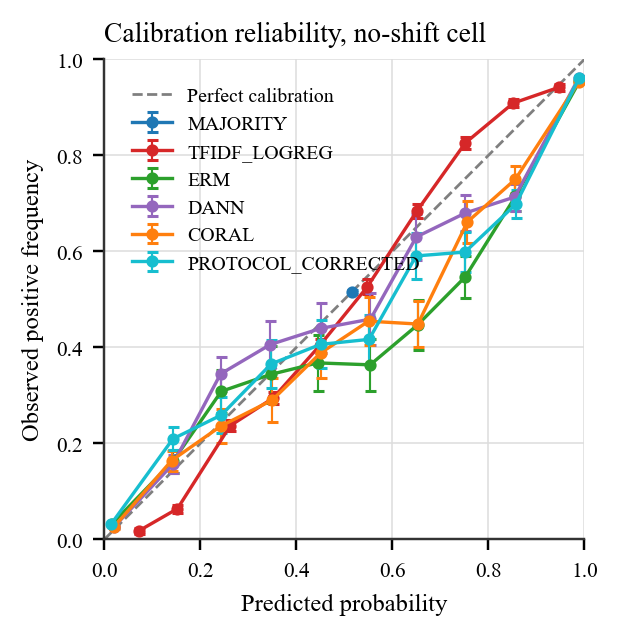

In [ ]:
# ===================== CELL 44: Calibration Reliability =====================


import numpy as np
import matplotlib.pyplot as plt

T_1COL = (3.5, 2.8)   

T_PALETTE = [
    "#1f77b4",  
    "#d62728",  
    "#2ca02c",  
    "#9467bd",  
    "#ff7f0e",  
    "#17becf",  
    "#8c564b",  
    "#7f7f7f",  
]

def reliability_curve(y_true, prob_pos, n_bins=10):
    """
    Equal-width reliability curve.
    Returns:
        mean predicted probability per bin
        observed positive frequency per bin
        standard error per bin
    """
    y_true = np.asarray(y_true, dtype=float)
    prob_pos = np.asarray(prob_pos, dtype=float)

    bins = np.linspace(0.0, 1.0, n_bins + 1)
    xs, ys, ses = [], [], []

    for i in range(n_bins):
        if i == n_bins - 1:
            mask = (prob_pos >= bins[i]) & (prob_pos <= bins[i + 1])
        else:
            mask = (prob_pos >= bins[i]) & (prob_pos < bins[i + 1])

        n = mask.sum()
        if n == 0:
            continue

        mean_pred = prob_pos[mask].mean()
        obs_freq = y_true[mask].mean()
        se = np.sqrt(max(obs_freq * (1.0 - obs_freq), 0.0) / n)

        xs.append(mean_pred)
        ys.append(obs_freq)
        ses.append(se)

    return (
        np.asarray(xs),
        np.asarray(ys),
        np.asarray(ses),
    )


def plot_calibration_reliability(
    FACTORIAL_RESULTS,
    reload_predictions,
    CFG,
    FIG_DIR,
    n_bins=10,
    seed_index=0,
    shift_a=0,
    shift_b=0,
    filename="fig_calibration_reliability",
):
    if FACTORIAL_RESULTS is None:
        print("Calibration figure pending a completed factorial.")
        return

    fig, ax = plt.subplots(figsize=T_1COL)

    # Perfect calibration reference
    ax.plot(
        [0, 1], [0, 1],
        color="#7f7f7f",
        lw=0.9,
        ls="--",
        label="Perfect calibration",
        zorder=1,
    )

    models_present = list(FACTORIAL_RESULTS["model"].unique())
    colors = {
        model: TACL_PALETTE[i % len(T_PALETTE)]
        for i, model in enumerate(models_present)
    }

    plotted = False

    for model_kind in models_present:
        et = reload_predictions(
            model_kind,
            CFG.SEEDS[seed_index],
            shift_a,
            shift_b,
        )

        if et is None:
            continue

        y_true = et["y_true"].to_numpy()
        prob_pos = et["prob_pos"].to_numpy()

        xs, ys, ses = reliability_curve(
            y_true,
            prob_pos,
            n_bins=n_bins,
        )

        if len(xs) == 0:
            continue

        ax.errorbar(
            xs,
            ys,
            yerr=ses,
            marker="o",
            markersize=3.0,
            linewidth=1.1,
            capsize=1.8,
            elinewidth=0.7,
            color=colors[model_kind],
            label=model_kind,
            zorder=3,
        )

        plotted = True

    if plotted:
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_aspect("equal", adjustable="box")

        ax.set_xlabel("Predicted probability", fontsize=8)
        ax.set_ylabel("Observed positive frequency", fontsize=8)
        ax.set_title(
            "Calibration reliability, no-shift cell",
            loc="left",
            fontsize=9,
            pad=6,
        )

        ax.tick_params(axis="both", which="major", labelsize=7)
        ax.grid(True, axis="both", color="#dddddd", lw=0.5, zorder=0)
        ax.set_axisbelow(True)

        ax.legend(
            frameon=False,
            fontsize=6.5,
            loc="upper left",
            bbox_to_anchor=(0.02, 0.98),
        )

        for spine in ["top", "right"]:
            ax.spines[spine].set_visible(False)

        fig.tight_layout(pad=0.4)

        FIG_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIG_DIR / f"{filename}.pdf", bbox_inches="tight")
        fig.savefig(FIG_DIR / f"{filename}.png", dpi=600, bbox_inches="tight")
        plt.show()
    else:
        plt.close(fig)
        print("No reloadable classical checkpoints found yet for calibration figure.")


plot_calibration_reliability(
    FACTORIAL_RESULTS=FACTORIAL_RESULTS,
    reload_predictions=reload_predictions,
    CFG=CFG,
    FIG_DIR=FIG_DIR,
    n_bins=10,
    seed_index=0,
    shift_a=0,
    shift_b=0,
    filename="fig_calibration_reliability",
)

In [ ]:
# ===================== CELL 45 =====================

def holm_adjust(p_values):
    p = np.asarray(p_values, dtype=float)
    out = np.full(len(p), np.nan)
    finite = np.where(np.isfinite(p))[0]
    order = finite[np.argsort(p[finite])]
    running, m = 0.0, len(order)
    for rank, idx in enumerate(order):
        running = max(running, min(1.0, (m - rank) * p[idx]))
        out[idx] = running
    return out

if FACTORIAL_RESULTS is not None:
    test_rows = []
    for model, g in FACTORIAL_RESULTS.groupby("model"):
        pivot = g.pivot_table(index="seed", columns=["content_on", "protocol_on"], values="macro_f1")
        for contrast, a, b in [("content", (0,0), (1,0)), ("content_at_protocol_on", (0,1), (1,1)),
                            ("protocol", (0,0), (0,1)), ("protocol_at_content_on", (1,0), (1,1))]:
            if a not in pivot.columns or b not in pivot.columns:
                continue
            diffs = (pivot[a] - pivot[b]).dropna()
            test_rows.append({"model": model, "contrast": contrast, "mean_drop": float(diffs.mean()),
                            "p_randomization": paired_randomization_p(diffs.to_numpy()), "n_pairs": int(len(diffs))})
    PAIRED_TESTS = pd.DataFrame(test_rows)
    if len(PAIRED_TESTS):
        PAIRED_TESTS["p_holm"] = holm_adjust(PAIRED_TESTS["p_randomization"].to_numpy())
    display(PAIRED_TESTS)
    PAIRED_TESTS.to_csv(OUT_ROOT / "tables" / "paired_randomization_tests.csv", index=False)

    SELECTIVITY = pd.DataFrame()
    models = set(FACTORIAL_RESULTS["model"].unique())
    if {"ERM", "PROTOCOL_CORRECTED"}.issubset(models):
        er = FACTORIAL_RESULTS[FACTORIAL_RESULTS.model == "ERM"].set_index(["seed", "content_on", "protocol_on"])["macro_f1"]
        pc = FACTORIAL_RESULTS[FACTORIAL_RESULTS.model == "PROTOCOL_CORRECTED"].set_index(["seed", "content_on", "protocol_on"])["macro_f1"]
        joined = pd.concat([er.rename("erm"), pc.rename("protocol_corrected")], axis=1).dropna().reset_index()
        joined["gain"] = joined["protocol_corrected"] - joined["erm"]
        SELECTIVITY = joined.groupby("protocol_on")["gain"].agg(["mean", "std", "count"]).reset_index()
        display(SELECTIVITY)
        SELECTIVITY.to_csv(OUT_ROOT / "tables" / "protocol_correction_selectivity.csv", index=False)
else:
    PAIRED_TESTS = None
    SELECTIVITY = None


,model,contrast,mean_drop,p_randomization,n_pairs,p_holm
0,CORAL,content,0.000860,0.393939,5,1.0
1,CORAL,content_at_protocol_on,-0.002609,0.212121,5,1.0
2,CORAL,protocol,0.019902,0.090909,5,1.0
3,CORAL,protocol_at_content_on,0.016433,0.090909,5,1.0
4,DANN,content,0.000057,1.000000,5,1.0
5,DANN,content_at_protocol_on,0.000550,0.696970,5,1.0
6,DANN,protocol,0.018774,0.090909,5,1.0
7,DANN,protocol_at_content_on,0.019267,0.090909,5,1.0
8,ERM,content,0.001798,0.090909,5,1.0
9,ERM,content_at_protocol_on,0.001549,0.272727,5,1.0


,protocol_on,mean,std,count
0,0,-0.001893,0.003260,10
1,1,-0.002429,0.001804,10


### 10.6 Correction efficiency across factors and methods

$CE_{i,m} = R_{i,m} / \varphi_i$, where $\varphi_i$ is ERM's Shapley attribution for factor $i$ and $R_{i,m}$ is the mean Macro-F1 gain of correction method $m$ over ERM, restricted to the cells where factor $i$ is active. $CE \approx 1$ means the method recovers essentially all of the ERM-attributed drop for that factor; $CE \approx 0$ means it recovers none of it.

In [ ]:
# ===================== CELL 47 =====================

if FACTORIAL_RESULTS is not None and "ERM" in FACTORIAL_RESULTS["model"].unique():
    erm_phi_rows = ATTRIBUTION_SUMMARY[(ATTRIBUTION_SUMMARY.model == "ERM") &
                                        (ATTRIBUTION_SUMMARY.metric.isin(["phi_content", "phi_protocol"]))]
    phi_lookup = {row.metric.replace("phi_", ""): row.__getattribute__("mean") for row in erm_phi_rows.itertuples()}

    ce_rows = []
    erm_series = FACTORIAL_RESULTS[FACTORIAL_RESULTS.model == "ERM"].set_index(["seed", "content_on", "protocol_on"])["macro_f1"]
    for method in ["DANN", "CORAL", "PROTOCOL_CORRECTED"]:
        if method not in FACTORIAL_RESULTS["model"].unique():
            continue
        corrected_series = FACTORIAL_RESULTS[FACTORIAL_RESULTS.model == method].set_index(["seed", "content_on", "protocol_on"])["macro_f1"]
        joined = pd.concat([erm_series.rename("erm"), corrected_series.rename("corrected")], axis=1).dropna().reset_index()
        joined["gain"] = joined["corrected"] - joined["erm"]
        for factor, mask in [("content", joined.content_on == 1), ("protocol", joined.protocol_on == 1)]:
            R = joined.loc[mask, "gain"].mean()
            phi = phi_lookup.get(factor, np.nan)
            ce_rows.append({"method": method, "factor": factor, "R": R, "phi_ERM": phi,
                            "CE": (R / phi) if phi not in (0, np.nan) and not pd.isna(phi) else np.nan})
    CORRECTION_EFFICIENCY = pd.DataFrame(ce_rows)
    if len(CORRECTION_EFFICIENCY):
        display(CORRECTION_EFFICIENCY)
        CORRECTION_EFFICIENCY.to_csv(OUT_ROOT / "tables" / "correction_efficiency.csv", index=False)
else:
    CORRECTION_EFFICIENCY = None
    print("Correction efficiency requires the completed ERM plus at least one correction-method arm.")


,method,factor,R,phi_ERM,CE
0,DANN,content,-0.000453,0.001674,-0.270468
1,DANN,protocol,-0.000950,0.019397,-0.048964
2,CORAL,content,0.001613,0.001674,0.963598
3,CORAL,protocol,0.000953,0.019397,0.049154
4,PROTOCOL_CORRECTED,content,-0.001519,0.001674,-0.907850
5,PROTOCOL_CORRECTED,protocol,-0.002429,0.019397,-0.125226


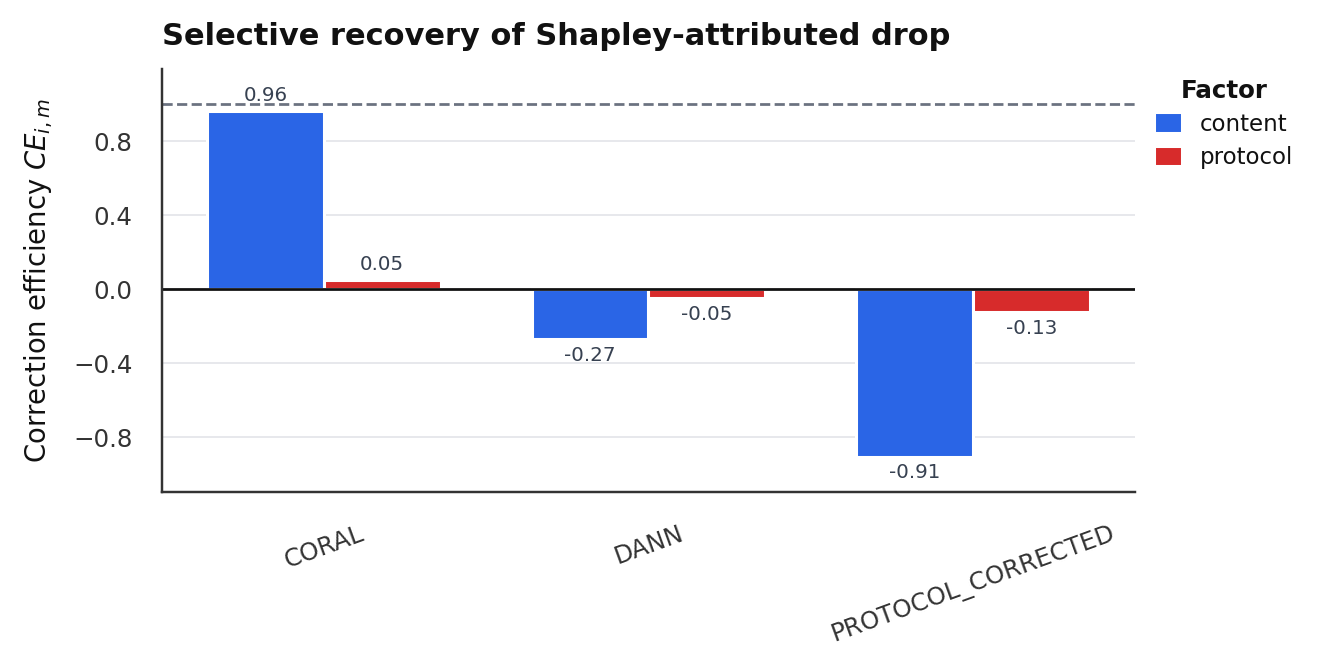

In [ ]:
# ===================== CELL 48: Correction Efficiency =====================


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import MaxNLocator
from packaging.version import parse

T_2COL = (7.2, 3.2)  

T_PALETTE = [
    "#2563EB",  
    "#DC2626",  
    "#059669",  
    "#7C3AED",  
    "#EA580C",  
    "#0891B2",  
]

SEABORN_VERSION = parse(sns.__version__)


def plot_correction_efficiency(
    CORRECTION_EFFICIENCY,
    FIG_DIR,
    filename="fig_correction_efficiency",
    method_order=None,
    factor_order=None,
    show_bar_values=True,
    error_column=None,
):

    if CORRECTION_EFFICIENCY is None or not len(CORRECTION_EFFICIENCY):
        print(
            "Correction-efficiency figure is pending the neural correction arms "
            "(DANN / CORAL / PROTOCOL_CORRECTED)."
        )
        return

    df = CORRECTION_EFFICIENCY.copy()

    if method_order is None:
        method_order = (
            df.groupby("method")["CE"]
            .mean()
            .sort_values(ascending=False)
            .index.tolist()
        )

    if factor_order is None:
        factor_order = list(df["factor"].dropna().unique())

    df["method"] = pd.Categorical(
        df["method"],
        categories=method_order,
        ordered=True,
    )

    df["factor"] = pd.Categorical(
        df["factor"],
        categories=factor_order,
        ordered=True,
    )

    factors = list(df["factor"].dropna().unique())

    palette = {
        factor: T_PALETTE[i % len(T_PALETTE)]
        for i, factor in enumerate(factors)
    }

    sns.set_theme(
        style="whitegrid",
        rc={
            "font.family": "DejaVu Sans",
            "axes.edgecolor": "#333333",
            "axes.linewidth": 0.8,
            "grid.color": "#E5E7EB",
            "grid.linewidth": 0.6,
            "xtick.color": "#333333",
            "ytick.color": "#333333",
            "text.color": "#111111",
            "axes.labelcolor": "#111111",
        },
    )

    fig, ax = plt.subplots(figsize=T_2COL)


    common_args = dict(
        data=df,
        x="method",
        y="CE",
        hue="factor",
        order=method_order,
        hue_order=factor_order,
        palette=palette,
        saturation=0.95,
        width=0.72,
        capsize=0.08,
        ax=ax,
    )

    if error_column is not None:

        common_args["errorbar"] = None
    else:
        if SEABORN_VERSION >= parse("0.12"):
            common_args["errorbar"] = ("sd", 1)
        else:
            common_args["ci"] = "sd"

    if SEABORN_VERSION >= parse("0.13"):
        common_args["err_kws"] = {
            "linewidth": 0.9,
            "color": "#374151",
        }
        common_args["gap"] = 0.12
    else:
        common_args["errcolor"] = "#374151"
        common_args["errwidth"] = 0.9

    sns.barplot(**common_args)


    if error_column is not None:
        agg = (
            df.groupby(["method", "factor"], observed=True)
            .agg(mean_CE=("CE", "mean"), err=(error_column, "first"))
            .reset_index()
        )

        n_methods = len(method_order)
        n_factors = len(factor_order)

        group_width = 0.72
        bar_width = group_width / n_factors

        for factor_idx, factor in enumerate(factor_order):
            sub = agg[agg["factor"] == factor]

            for _, row in sub.iterrows():
                method_idx = method_order.index(row["method"])

                center = method_idx - group_width / 2 + bar_width / 2
                x = center + factor_idx * bar_width

                ax.errorbar(
                    x,
                    row["mean_CE"],
                    yerr=float(row["err"]),
                    fmt="none",
                    ecolor="#374151",
                    elinewidth=0.9,
                    capsize=2.5,
                    capthick=0.8,
                    zorder=5,
                )

    # --- Reference lines ---
    ax.axhline(0, color="#111111", lw=0.9, zorder=1)
    ax.axhline(1, color="#6B7280", lw=0.9, ls="--", zorder=1)

    # --- Optional bar value labels ---
    if show_bar_values:
        for container in ax.containers:
            ax.bar_label(
                container,
                fmt="%.2f",
                padding=2,
                fontsize=6.5,
                color="#374151",
                rotation=0,
            )

    # --- Labels and title ---
    ax.set_xlabel("")
    ax.set_ylabel(
        r"Correction efficiency $CE_{i,m}$",
        fontsize=9,
        labelpad=6,
    )
    ax.set_title(
        "Selective recovery of Shapley-attributed drop",
        loc="left",
        fontsize=10,
        fontweight="bold",
        pad=8,
    )

    # --- Ticks ---
    ax.tick_params(axis="x", labelsize=8, rotation=20)
    ax.tick_params(axis="y", labelsize=8)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6, prune="lower"))

    # --- Safe y-limits ---
    ymin = min(0.0, float(df["CE"].min()))
    ymax = max(1.0, float(df["CE"].max()))

    if error_column is not None:
        ymax = max(
            ymax,
            float((df["CE"] + df[error_column]).max()),
        )
        ymin = min(
            ymin,
            float((df["CE"] - df[error_column]).min()),
        )

    pad = 0.10 * max(abs(ymax - ymin), 0.1)
    ax.set_ylim(ymin - pad, ymax + pad)

    # --- Legend outside right ---
    legend = ax.legend(
        title="Factor",
        frameon=False,
        fontsize=7.5,
        title_fontsize=8,
        loc="upper left",
        bbox_to_anchor=(1.01, 1.0),
        borderaxespad=0.0,
        handlelength=1.2,
        handleheight=1.0,
        labelspacing=0.45,
    )
    legend.get_title().set_fontweight("bold")

    sns.despine(ax=ax, left=False, bottom=False)

    fig.tight_layout(rect=[0, 0, 0.86, 1])

    FIG_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(
        FIG_DIR / f"{filename}.pdf",
        bbox_inches="tight",
    )
    fig.savefig(
        FIG_DIR / f"{filename}.png",
        dpi=600,
        bbox_inches="tight",
    )
    plt.show()


# --- Run ---
plot_correction_efficiency(
    CORRECTION_EFFICIENCY=CORRECTION_EFFICIENCY,
    FIG_DIR=FIG_DIR,
    filename="fig_correction_efficiency",
    method_order=None,
    factor_order=None,
    show_bar_values=True,
    error_column=None,
)

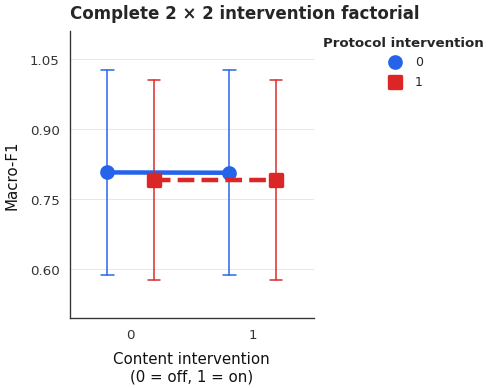

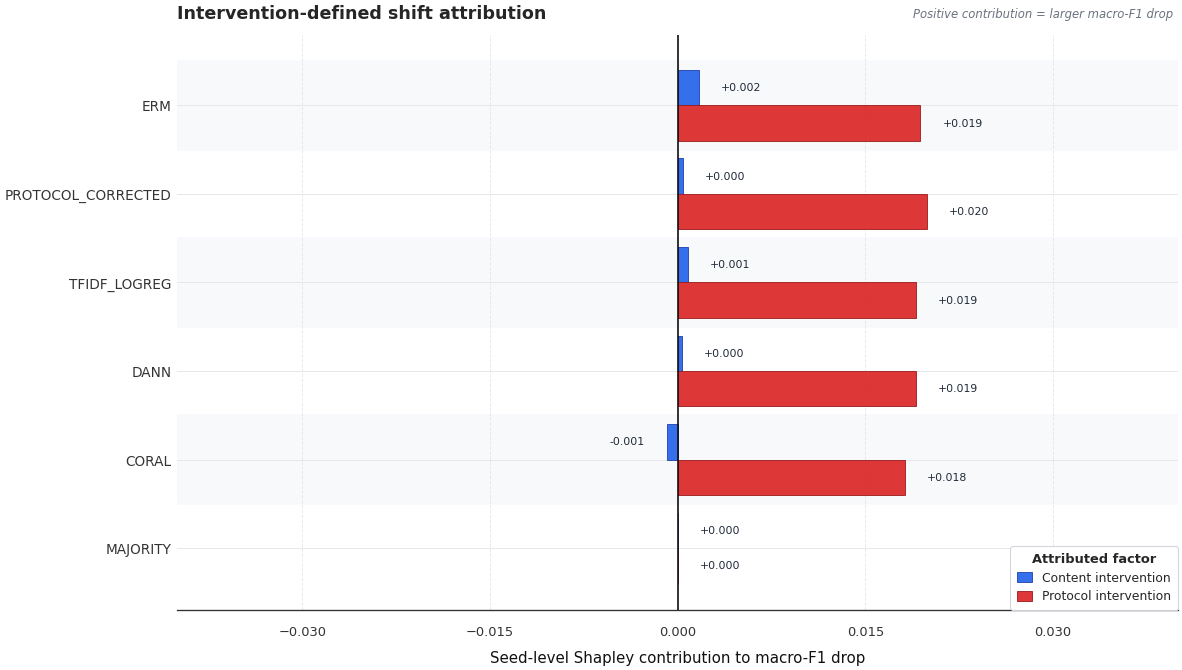

In [ ]:
# ===================== CELL 49: Factorial & Attribution Figures =====================



import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import MaxNLocator
from pathlib import Path


def seaborn_supports(parameter):
    """
    Minimal compatibility helper for older/newer seaborn versions.
    """
    version = tuple(int(x) for x in sns.__version__.split(".")[:2])

    supports = {
        "errorbar": version >= (0, 12),
        "err_kws": version >= (0, 13),
        "gap": version >= (0, 13),
        "errwidth": version >= (0, 8),
        "capsize": version >= (0, 8),
        "ci": version >= (0, 8),
    }

    return supports.get(parameter, False)


PUB_STYLE = {
    "figure.dpi": 120,
    "savefig.dpi": 600,
    "font.family": "DejaVu Sans",
    "font.size": 8,
    "axes.titlesize": 10,
    "axes.titleweight": "bold",
    "axes.labelsize": 9,
    "axes.labelcolor": "#111111",
    "axes.edgecolor": "#333333",
    "axes.linewidth": 0.8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "xtick.color": "#333333",
    "ytick.color": "#333333",
    "grid.color": "#E5E7EB",
    "grid.linewidth": 0.6,
    "legend.frameon": False,
    "legend.fontsize": 7.5,
    "legend.title_fontsize": 8,
}

sns.set_theme(style="whitegrid", rc=PUB_STYLE)

PUB_PALETTE = [
    "#2563EB",  # blue
    "#DC2626",  # red
    "#059669",  # green
    "#7C3AED",  # purple
    "#EA580C",  # orange
    "#0891B2",  # cyan
]

FIG_DIR = Path(OUT_ROOT) / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def style_axis(ax, y_pad=0.08):
    """Clean journal-style axes with safe vertical padding."""
    sns.despine(ax=ax, left=False, bottom=False)
    ax.grid(True, axis="y", color="#E5E7EB", lw=0.6, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(
        axis="both",
        which="major",
        length=2.5,
        width=0.7,
    )

    ymin, ymax = ax.get_ylim()
    span = max(ymax - ymin, 1e-8)

    ax.set_ylim(
        ymin - y_pad * span,
        ymax + y_pad * span,
    )



def plot_factorial_macro_f1(
    FACTORIAL_RESULTS,
    fig_dir=FIG_DIR,
    filename="factorial_macro_f1",
    errorbar="sd",
):
    if FACTORIAL_RESULTS is None or not len(FACTORIAL_RESULTS):
        print("Factorial plot pending completed factorial results.")
        return

    df = FACTORIAL_RESULTS.copy()

    content_order = sorted(df["content_on"].unique())
    protocol_order = sorted(df["protocol_on"].unique())

    df["content_on"] = pd.Categorical(
        df["content_on"],
        categories=content_order,
        ordered=True,
    )

    df["protocol_on"] = pd.Categorical(
        df["protocol_on"],
        categories=protocol_order,
        ordered=True,
    )

    palette = {
        level: PUB_PALETTE[i % len(PUB_PALETTE)]
        for i, level in enumerate(protocol_order)
    }

    fig, ax = plt.subplots(figsize=(5.4, 3.4))

    pointplot_args = dict(
        data=df,
        x="content_on",
        y="macro_f1",
        hue="protocol_on",
        order=content_order,
        hue_order=protocol_order,
        palette=palette,
        dodge=0.38,
        markers=["o", "s", "^", "D"][: len(protocol_order)],
        linestyles=["-", "--", "-.", ":"][: len(protocol_order)],
        ax=ax,
    )

    if seaborn_supports("errorbar"):
        pointplot_args["errorbar"] = errorbar
    elif seaborn_supports("ci"):
        pointplot_args["ci"] = "sd"

    if seaborn_supports("errwidth"):
        pointplot_args["errwidth"] = 0.9

    if seaborn_supports("capsize"):
        pointplot_args["capsize"] = 0.10

    if seaborn_supports("err_kws"):
        pointplot_args["err_kws"] = {
            "linewidth": 0.9,
            "color": "#374151",
        }

    sns.pointplot(**pointplot_args)

    ax.set_xlabel(
        "Content intervention\n(0 = off, 1 = on)",
        labelpad=6,
    )
    ax.set_ylabel("Macro-F1", labelpad=6)
    ax.set_title(
        "Complete 2 × 2 intervention factorial",
        loc="left",
        pad=8,
    )

    ax.yaxis.set_major_locator(
        MaxNLocator(nbins=6, prune="lower")
    )
    style_axis(ax, y_pad=0.12)

    legend = ax.legend(
        title="Protocol intervention",
        loc="upper left",
        bbox_to_anchor=(1.02, 1.0),
        borderaxespad=0.0,
        handlelength=1.6,
        labelspacing=0.5,
    )
    legend.get_title().set_fontweight("bold")

    fig.tight_layout(rect=[0, 0, 0.80, 1])

    fig.savefig(
        fig_dir / f"{filename}.pdf",
        bbox_inches="tight",
    )
    fig.savefig(
        fig_dir / f"{filename}.png",
        dpi=600,
        bbox_inches="tight",
    )
    plt.show()


def plot_shapley_contributions(
    ATTRIBUTION_SUMMARY,
    fig_dir=FIG_DIR,
    filename="shapley_contributions",
    metrics=("phi_content", "phi_protocol"),
    metric_labels=None,
    show_values=True,
    show_seed_range=True,
    bar_height=0.20,
    group_spacing=0.50,
):
    """
    Professional horizontal diverging Shapley attribution figure.

    Expected ATTRIBUTION_SUMMARY columns:
        model, metric, mean

    Optional column:
        std -- seed-level uncertainty
    """

    if ATTRIBUTION_SUMMARY is None or not len(ATTRIBUTION_SUMMARY):
        print("Shapley attribution plot pending attribution summary.")
        return

    if metric_labels is None:
        metric_labels = {
            "phi_content": "Content intervention",
            "phi_protocol": "Protocol intervention",
        }

    df = ATTRIBUTION_SUMMARY.copy()
    df = df[df["metric"].isin(metrics)].copy()

    if not len(df):
        print("No requested Shapley metrics found in ATTRIBUTION_SUMMARY.")
        return


    df["factor"] = (
        df["metric"]
        .map(metric_labels)
        .fillna(df["metric"])
    )

    factors = [
        metric_labels.get(m, m)
        for m in metrics
    ]

    factors = [
        f for f in factors
        if f in df["factor"].unique()
    ]

    model_rank = (
        df.groupby("model")["mean"]
        .apply(lambda x: x.abs().sum())
        .sort_values(ascending=False)
        .index.tolist()
    )


    factor_colors = {
        factors[0]: "#2563EB",
    }

    factor_edges = {
        factors[0]: "#1E40AF",
    }

    if len(factors) > 1:
        factor_colors[factors[1]] = "#DC2626"
        factor_edges[factors[1]] = "#991B1B"

    n_models = len(model_rank)
    n_factors = len(factors)

    fig_height = max(4.0, 0.68 * n_models + 1.65)
    fig_width = 10.0 if n_factors <= 2 else 11.5

    fig, ax = plt.subplots(
        figsize=(fig_width, fig_height)
    )

    y_positions = np.arange(n_models, dtype=float) * group_spacing

    offsets = np.linspace(
        -(n_factors - 1) * bar_height / 2,
        +(n_factors - 1) * bar_height / 2,
        n_factors,
    )

    all_values = []
    all_errors = []


    for i, y in enumerate(y_positions):
        if i % 2 == 0:
            ax.axhspan(
                y - group_spacing / 2,
                y + group_spacing / 2,
                color="#F7F8FB",
                alpha=0.85,
                zorder=0,
            )


    for factor, dy in zip(factors, offsets):
        sub = (
            df[df["factor"] == factor]
            .set_index("model")
            .reindex(model_rank)
        )

        values = (
            sub["mean"]
            .fillna(0)
            .to_numpy(dtype=float)
        )

        if show_seed_range and "std" in sub.columns:
            errors = (
                sub["std"]
                .fillna(0)
                .to_numpy(dtype=float)
            )
        else:
            errors = np.zeros_like(values)

        bars = ax.barh(
            y_positions + dy,
            values,
            height=bar_height,
            color=factor_colors[factor],
            edgecolor=factor_edges[factor],
            linewidth=0.55,
            alpha=0.92,
            zorder=3,
            label=factor,
        )

        # Seed-level uncertainty whiskers
        if show_seed_range and np.any(errors > 0):
            ax.errorbar(
                values,
                y_positions + dy,
                xerr=errors,
                fmt="none",
                ecolor="#4B5563",
                elinewidth=0.75,
                capsize=1.8,
                capthick=0.75,
                alpha=0.85,
                zorder=5,
            )

        all_values.extend(values)
        all_errors.extend(errors)


    values_arr = np.array(all_values, dtype=float)
    errors_arr = np.array(all_errors, dtype=float)

    max_right = np.max(values_arr + errors_arr)
    max_left = np.min(values_arr - errors_arr)

    value_span = max(
        abs(max_right),
        abs(max_left),
        1e-8,
    )

    raw_limit = value_span * 1.70

    magnitude = 10 ** np.floor(np.log10(raw_limit))
    x_limit = np.ceil(raw_limit / magnitude) * magnitude

    ax.set_xlim(-x_limit, x_limit)


    if show_values:
        axis_span = 2 * x_limit
        label_offset = 0.022 * axis_span

        for factor, dy in zip(factors, offsets):
            sub = (
                df[df["factor"] == factor]
                .set_index("model")
                .reindex(model_rank)
            )

            values = (
                sub["mean"]
                .fillna(0)
                .to_numpy(dtype=float)
            )

            if show_seed_range and "std" in sub.columns:
                errors = (
                    sub["std"]
                    .fillna(0)
                    .to_numpy(dtype=float)
                )
            else:
                errors = np.zeros_like(values)

            for y, value, error in zip(
                y_positions + dy,
                values,
                errors,
            ):
                if value >= 0:
                    anchor = value + error
                    x_pos = anchor + label_offset
                    ha = "left"
                else:
                    anchor = value - error
                    x_pos = anchor - label_offset
                    ha = "right"

                ax.text(
                    x_pos,
                    y,
                    f"{value:+.3f}",
                    va="center",
                    ha=ha,
                    fontsize=6.5,
                    color="#1F2937",
                    zorder=7,
                )
    ax.axvline(
        0,
        color="#111111",
        linewidth=1.0,
        zorder=4,
    )
    ax.set_yticks(y_positions)
    ax.set_yticklabels(model_rank, fontsize=8.2)

    ax.invert_yaxis()

    ax.set_xlabel(
        "Seed-level Shapley contribution to macro-F1 drop",
        labelpad=7,
        fontsize=9,
    )

    ax.set_title(
        "Intervention-defined shift attribution",
        loc="left",
        pad=10,
        fontsize=10.5,
    )

    ax.xaxis.set_major_locator(
        MaxNLocator(nbins=6, prune=None)
    )

    ax.tick_params(axis="x", labelsize=7.8)
    ax.tick_params(axis="y", length=0)

    ax.grid(
        True,
        axis="x",
        color="#E5E7EB",
        linewidth=0.55,
        linestyle="--",
        zorder=0,
    )
    ax.set_axisbelow(True)

    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)

    ax.spines["bottom"].set_color("#333333")
    ax.spines["bottom"].set_linewidth(0.8)

    legend = ax.legend(
        title="Attributed factor",
        loc="lower right",
        frameon=True,
        framealpha=0.97,
        edgecolor="#D1D5DB",
        facecolor="white",
        fontsize=7.4,
        title_fontsize=7.8,
        handlelength=1.25,
        handleheight=0.85,
        borderpad=0.55,
        labelspacing=0.45,
    )

    legend.get_title().set_fontweight("bold")
    legend.get_frame().set_linewidth(0.65)


    ax.text(
        0.995,
        1.025,
        "Positive contribution = larger macro-F1 drop",
        transform=ax.transAxes,
        ha="right",
        va="bottom",
        fontsize=7.0,
        color="#6B7280",
        style="italic",
    )

    fig.tight_layout(pad=1.0)

    fig.savefig(
        fig_dir / f"{filename}.pdf",
        bbox_inches="tight",
    )
    fig.savefig(
        fig_dir / f"{filename}.png",
        dpi=600,
        bbox_inches="tight",
    )
    plt.show()


plot_factorial_macro_f1(
    FACTORIAL_RESULTS=FACTORIAL_RESULTS,
    fig_dir=FIG_DIR,
    filename="factorial_macro_f1",
    errorbar="sd",
)


plot_shapley_contributions(
    ATTRIBUTION_SUMMARY=ATTRIBUTION_SUMMARY,
    fig_dir=FIG_DIR,
    filename="shapley_contributions",
    metrics=("phi_content", "phi_protocol"),
    metric_labels={
        "phi_content": "Content intervention",
        "phi_protocol": "Protocol intervention",
    },
    show_values=True,
    show_seed_range=True,
)

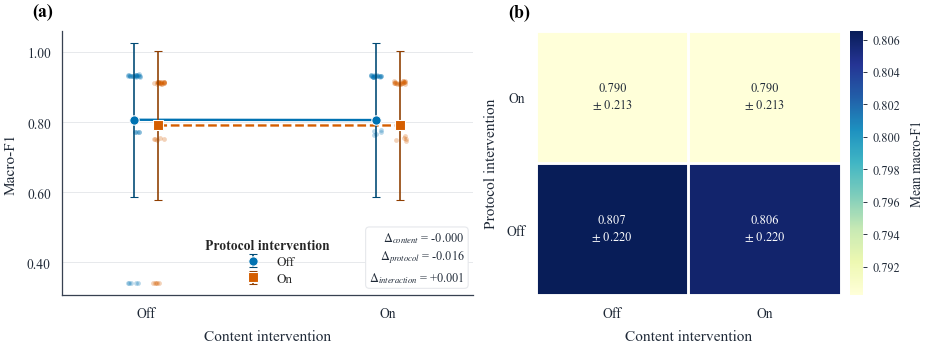

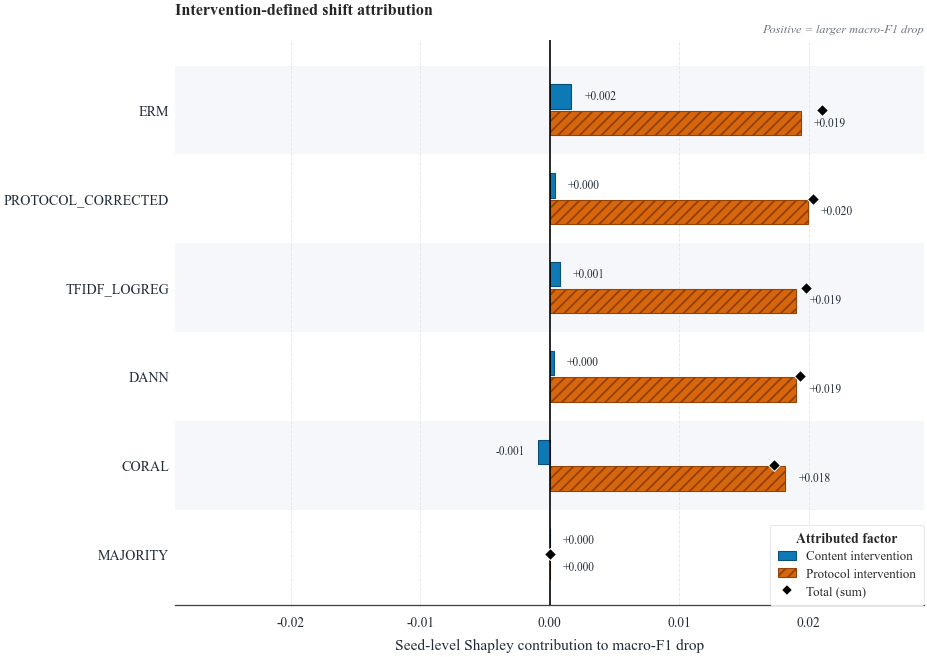

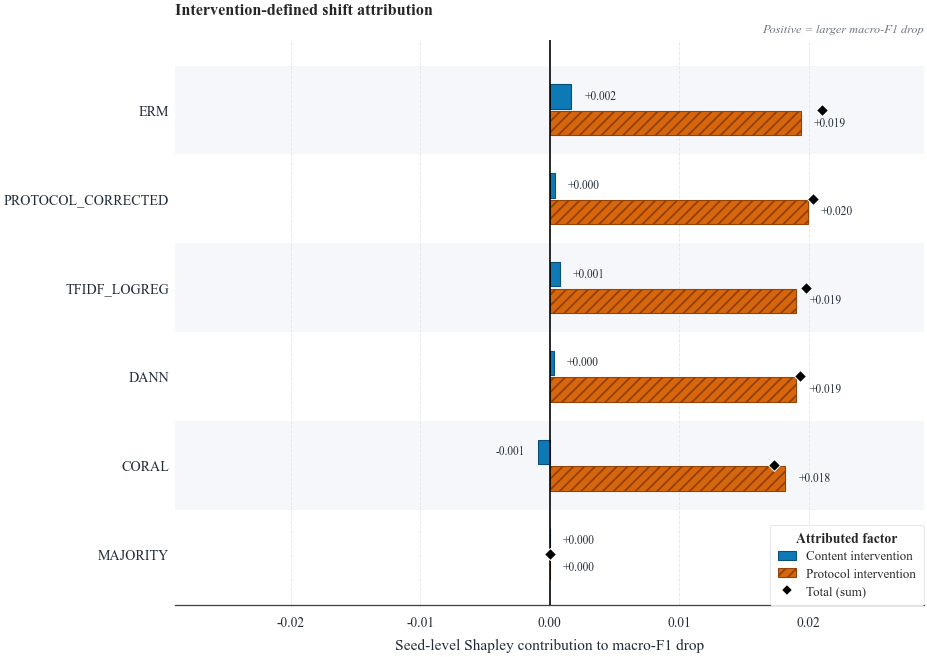

In [ ]:
# ===================== CELL 49: Factorial & Attribution Figures =====================


import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, FormatStrFormatter
from matplotlib.lines import Line2D
from matplotlib.patches import Patch


LAYOUTS = {
    "ieee_single":     3.50,
    "ieee_double":     7.16,
    "elsevier_single": 3.54,
    "elsevier_1p5":    5.51,
    "elsevier_double": 7.48,
    "springer_double": 6.85,
}

LAYOUT = "ieee_double"


INK = "#1F2937"
MUTED = "#6B7280"
GRID = "#E5E7EB"

PUB_RC = {
    "figure.dpi": 130,
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.03,
    "pdf.fonttype": 42,          
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Nimbus Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.titlesize": 9,
    "axes.titleweight": "bold",
    "axes.labelsize": 8.5,
    "axes.labelcolor": INK,
    "axes.edgecolor": "#374151",
    "axes.linewidth": 0.7,
    "axes.axisbelow": True,
    "xtick.labelsize": 7.5,
    "ytick.labelsize": 7.5,
    "xtick.color": INK,
    "ytick.color": INK,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.major.size": 2.5,
    "ytick.major.size": 2.5,
    "grid.color": GRID,
    "grid.linewidth": 0.5,
    "legend.frameon": False,
    "legend.fontsize": 7.2,
    "legend.title_fontsize": 7.6,
    "lines.linewidth": 1.3,
}
mpl.rcParams.update(PUB_RC)

PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9"]
EDGES = ["#004A75", "#8F3E00", "#00664B", "#85496B", "#996A00", "#2F7FA8"]
MARKERS = ["o", "s", "^", "D"]
LINESTYLES = ["-", "--", "-.", ":"]

FIG_DIR = Path(globals().get("OUT_ROOT", ".")) / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def _fig_width(layout=None):
    return LAYOUTS[layout or LAYOUT]


def _level_label(v):
    if v in (0, False):
        return "Off"
    if v in (1, True):
        return "On"
    return str(v)


def _panel_label(ax, text, x=-0.02, y=1.04):
    ax.text(x, y, text, transform=ax.transAxes, fontsize=10,
            fontweight="bold", va="bottom", ha="right", color="black")


def _clean_axis(ax, grid_axis="y"):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.grid(True, axis=grid_axis, color=GRID, lw=0.5, zorder=0)
    ax.set_axisbelow(True)


def _text_color_for(rgba):
    r, g, b = rgba[:3]
    lum = 0.2126 * r + 0.7152 * g + 0.0722 * b
    return "white" if lum < 0.55 else INK


def save_figure(fig, fig_dir, filename, formats=("pdf", "png", "svg")):
    fig_dir = Path(fig_dir)
    fig_dir.mkdir(parents=True, exist_ok=True)
    for ext in formats:
        kwargs = {"dpi": 600} if ext == "png" else {}
        fig.savefig(fig_dir / f"{filename}.{ext}", **kwargs)


def compute_factorial_effects(cell_means, content_levels, protocol_levels):
    """
    Classical 2x2 effects on the macro-F1 scale (only if both factors
    have exactly two levels). Returns None otherwise.
    """
    if len(content_levels) != 2 or len(protocol_levels) != 2:
        return None
    c0, c1 = content_levels
    p0, p1 = protocol_levels
    m = lambda c, p: cell_means.loc[(c, p)]
    content_effect = 0.5 * ((m(c1, p0) - m(c0, p0)) + (m(c1, p1) - m(c0, p1)))
    protocol_effect = 0.5 * ((m(c0, p1) - m(c0, p0)) + (m(c1, p1) - m(c1, p0)))
    interaction = (m(c1, p1) - m(c0, p1)) - (m(c1, p0) - m(c0, p0))
    return {
        "content_effect": float(content_effect),
        "protocol_effect": float(protocol_effect),
        "interaction": float(interaction),
    }


def plot_factorial_macro_f1(
    FACTORIAL_RESULTS,
    fig_dir=FIG_DIR,
    filename="factorial_macro_f1",
    layout=None,
    show_seed_points=True,
    show_effects=True,
    cmap="YlGnBu",
):
    """
    Two-panel figure.
      (a) Interaction plot: mean +/- SD across runs, individual runs as
          faint points, one line per protocol level.
      (b) Cell-mean heatmap with mean +/- SD annotation.
    """
    if FACTORIAL_RESULTS is None or not len(FACTORIAL_RESULTS):
        print("Factorial plot pending completed factorial results.")
        return None

    df = FACTORIAL_RESULTS.copy()
    content_levels = sorted(df["content_on"].unique())
    protocol_levels = sorted(df["protocol_on"].unique())

    stats = (
        df.groupby(["content_on", "protocol_on"])["macro_f1"]
        .agg(["mean", "std", "count"])
        .fillna({"std": 0.0})
    )
    means = stats["mean"]

    width = _fig_width(layout)
    narrow = width < 4.5
    fig = plt.figure(figsize=(width, 2.7 if not narrow else 3.4), constrained_layout=True)
    if narrow:
        gs = fig.add_gridspec(2, 1, height_ratios=[1.25, 1])
    else:
        gs = fig.add_gridspec(1, 2, width_ratios=[1.35, 1])
    ax = fig.add_subplot(gs[0])
    ax_h = fig.add_subplot(gs[1])

    n_p = len(protocol_levels)
    dodge = 0.10
    offsets = (np.arange(n_p) - (n_p - 1) / 2) * dodge
    xs = np.arange(len(content_levels), dtype=float)
    rng = np.random.default_rng(0)

    for i, p in enumerate(protocol_levels):
        color = PALETTE[i % len(PALETTE)]
        edge = EDGES[i % len(EDGES)]
        mu = np.array([stats.loc[(c, p), "mean"] for c in content_levels])
        sd = np.array([stats.loc[(c, p), "std"] for c in content_levels])
        x = xs + offsets[i]

        if show_seed_points:
            for xi, c in zip(x, content_levels):
                vals = df[(df["content_on"] == c) & (df["protocol_on"] == p)]["macro_f1"].to_numpy()
                jitter = rng.uniform(-0.025, 0.025, size=len(vals))
                ax.scatter(xi + jitter, vals, s=7, color=color, alpha=0.28,
                           linewidths=0, zorder=2)

        ax.plot(x, mu, color=color, ls=LINESTYLES[i % 4], lw=1.3, zorder=3)
        ax.errorbar(
            x, mu, yerr=sd, fmt=MARKERS[i % 4], color=color,
            mfc=color, mec="white", mew=0.6, ms=5.2,
            ecolor=edge, elinewidth=0.9, capsize=2.4, capthick=0.9, zorder=4,
            label=f"{_level_label(p)}",
        )

    ax.set_xticks(xs)
    ax.set_xticklabels([_level_label(c) for c in content_levels])
    ax.set_xlim(xs.min() - 0.35, xs.max() + 0.35)
    ax.set_xlabel("Content intervention")
    ax.set_ylabel("Macro-F1")
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))
    _clean_axis(ax)

    leg = ax.legend(title="Protocol intervention", loc="best", handlelength=2.0,
                    labelspacing=0.35, borderaxespad=0.4)
    leg.get_title().set_fontweight("bold")
    _panel_label(ax, "(a)")

    effects = compute_factorial_effects(means, content_levels, protocol_levels)
    if show_effects and effects is not None:
        txt = (
            rf"$\Delta_{{content}}$ = {effects['content_effect']:+.3f}" "\n"
            rf"$\Delta_{{protocol}}$ = {effects['protocol_effect']:+.3f}" "\n"
            rf"$\Delta_{{interaction}}$ = {effects['interaction']:+.3f}"
        )
        ax.text(0.98, 0.04, txt, transform=ax.transAxes, ha="right", va="bottom",
                fontsize=6.8, color=INK, linespacing=1.35,
                bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=GRID, lw=0.6))

    grid = np.array([[stats.loc[(c, p), "mean"] for c in content_levels]
                    for p in protocol_levels])
    sdg = np.array([[stats.loc[(c, p), "std"] for c in content_levels]
                    for p in protocol_levels])

    im = ax_h.imshow(grid, cmap=cmap, aspect="auto", origin="lower")
    cm = mpl.colormaps[cmap] if hasattr(mpl, "colormaps") else plt.get_cmap(cmap)
    vmin, vmax = np.nanmin(grid), np.nanmax(grid)
    norm_span = max(vmax - vmin, 1e-12)
    for r in range(grid.shape[0]):
        for c in range(grid.shape[1]):
            color = _text_color_for(cm((grid[r, c] - vmin) / norm_span))
            ax_h.text(c, r, f"{grid[r, c]:.3f}\n" rf"$\pm$ {sdg[r, c]:.3f}",
                    ha="center", va="center", fontsize=7, color=color, linespacing=1.3)

    ax_h.set_xticks(range(len(content_levels)))
    ax_h.set_xticklabels([_level_label(c) for c in content_levels])
    ax_h.set_yticks(range(len(protocol_levels)))
    ax_h.set_yticklabels([_level_label(p) for p in protocol_levels])
    ax_h.set_xlabel("Content intervention")
    ax_h.set_ylabel("Protocol intervention")
    ax_h.set_xticks(np.arange(-0.5, len(content_levels), 1), minor=True)
    ax_h.set_yticks(np.arange(-0.5, len(protocol_levels), 1), minor=True)
    ax_h.grid(which="minor", color="white", lw=1.6)
    ax_h.grid(which="major", visible=False)
    ax_h.tick_params(which="minor", length=0)
    for side in ax_h.spines.values():
        side.set_visible(False)
    cb = fig.colorbar(im, ax=ax_h, fraction=0.05, pad=0.03)
    cb.set_label("Mean macro-F1", fontsize=7.5)
    cb.ax.tick_params(labelsize=6.8, width=0.5, length=2)
    cb.outline.set_visible(False)
    _panel_label(ax_h, "(b)")

    save_figure(fig, fig_dir, filename)
    plt.show()
    return effects

def plot_shapley_contributions(
    ATTRIBUTION_SUMMARY,
    fig_dir=FIG_DIR,
    filename="shapley_contributions",
    metrics=("phi_content", "phi_protocol"),
    metric_labels=None,
    layout=None,
    show_values=True,
    show_seed_range=True,
    show_total=True,
    bar_height=0.30,
    group_spacing=1.0,
):

    if ATTRIBUTION_SUMMARY is None or not len(ATTRIBUTION_SUMMARY):
        print("Shapley attribution plot pending attribution summary.")
        return None

    if metric_labels is None:
        metric_labels = {
            "phi_content": "Content intervention",
            "phi_protocol": "Protocol intervention",
        }

    df = ATTRIBUTION_SUMMARY[ATTRIBUTION_SUMMARY["metric"].isin(metrics)].copy()
    if not len(df):
        print("No requested Shapley metrics found in ATTRIBUTION_SUMMARY.")
        return None

    df["factor"] = df["metric"].map(metric_labels).fillna(df["metric"])
    factors = [metric_labels.get(m, m) for m in metrics]
    factors = [f for f in factors if f in df["factor"].unique()]
    has_std = "std" in df.columns

    models = (
        df.groupby("model")["mean"]
        .apply(lambda s: s.abs().sum())
        .sort_values(ascending=False)
        .index.tolist()
    )

    n_models, n_factors = len(models), len(factors)
    width = _fig_width(layout)
    height = max(2.4, 0.42 * n_models * max(n_factors, 1) * 0.75 + 1.3)
    fig, ax = plt.subplots(figsize=(width, height), constrained_layout=True)

    y_pos = np.arange(n_models, dtype=float) * group_spacing
    offsets = (np.arange(n_factors) - (n_factors - 1) / 2) * bar_height

    for i, y in enumerate(y_pos):
        if i % 2 == 0:
            ax.axhspan(y - group_spacing / 2, y + group_spacing / 2,
                       color="#F6F7FA", zorder=0, lw=0)

    hatches = ["", "////", "xxxx", ".."]
    collected = {}
    for k, (factor, dy) in enumerate(zip(factors, offsets)):
        sub = df[df["factor"] == factor].set_index("model").reindex(models)
        vals = sub["mean"].fillna(0).to_numpy(float)
        errs = (sub["std"].fillna(0).to_numpy(float)
                if (show_seed_range and has_std) else np.zeros_like(vals))
        collected[factor] = (vals, errs)

        ax.barh(
            y_pos + dy, vals, height=bar_height * 0.92,
            color=PALETTE[k % len(PALETTE)], edgecolor=EDGES[k % len(EDGES)],
            linewidth=0.6, hatch=hatches[k % len(hatches)], alpha=0.95,
            zorder=3, label=factor,
        )
        if np.any(errs > 0):
            ax.errorbar(vals, y_pos + dy, xerr=errs, fmt="none", ecolor="#374151",
                        elinewidth=0.8, capsize=2.0, capthick=0.8, zorder=5)

    hi = max(np.max(v + e) for v, e in collected.values())
    lo = min(np.min(v - e) for v, e in collected.values())
    span = max(abs(hi), abs(lo), 1e-8)
    lim = span * 1.45
    ax.set_xlim(-lim if lo < 0 else -0.04 * lim, lim)

    if show_values:
        pad = 0.018 * (ax.get_xlim()[1] - ax.get_xlim()[0])
        for factor, dy in zip(factors, offsets):
            vals, errs = collected[factor]
            for y, v, e in zip(y_pos + dy, vals, errs):
                if v >= 0:
                    ax.text(v + e + pad, y, f"{v:+.3f}", va="center", ha="left",
                            fontsize=6.4, color=INK, zorder=7)
                else:
                    ax.text(v - e - pad, y, f"{v:+.3f}", va="center", ha="right",
                            fontsize=6.4, color=INK, zorder=7)

    if show_total and n_factors > 1:
        total = sum(collected[f][0] for f in factors)
        ax.scatter(total, y_pos, marker="D", s=22, color="black",
                edgecolor="white", linewidths=0.6, zorder=8)

    ax.axvline(0, color="black", lw=0.9, zorder=4)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(models, fontsize=7.8)
    ax.invert_yaxis()
    ax.set_xlabel("Seed-level Shapley contribution to macro-F1 drop")
    ax.set_title("Intervention-defined shift attribution", loc="left", pad=14)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.xaxis.set_major_formatter(FormatStrFormatter("%.2f"))
    ax.tick_params(axis="y", length=0)
    ax.grid(True, axis="x", color=GRID, lw=0.5, ls="--", zorder=0)
    ax.set_axisbelow(True)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)

    handles, labels = ax.get_legend_handles_labels()
    if show_total and n_factors > 1:
        handles.append(Line2D([], [], marker="D", ls="", color="black",
                            mec="white", ms=5))
        labels.append("Total (sum)")
    leg = ax.legend(handles, labels, title="Attributed factor",
                    loc="lower right", frameon=True, framealpha=0.95,
                    edgecolor=GRID, facecolor="white", borderpad=0.6,
                    handlelength=1.4, labelspacing=0.4)
    leg.get_title().set_fontweight("bold")
    leg.get_frame().set_linewidth(0.6)

    ax.text(1.0, 1.01, "Positive = larger macro-F1 drop", transform=ax.transAxes,
            ha="right", va="bottom", fontsize=6.8, color=MUTED, style="italic")

    save_figure(fig, fig_dir, filename)
    plt.show()
    return fig

factorial_effects = plot_factorial_macro_f1(
    FACTORIAL_RESULTS=FACTORIAL_RESULTS,
    fig_dir=FIG_DIR,
    filename="factorial_macro_f1",
    layout=LAYOUT,
)

plot_shapley_contributions(
    ATTRIBUTION_SUMMARY=ATTRIBUTION_SUMMARY,
    fig_dir=FIG_DIR,
    filename="shapley_contributions",
    metrics=("phi_content", "phi_protocol"),
    metric_labels={
        "phi_content": "Content intervention",
        "phi_protocol": "Protocol intervention",
    },
    layout=LAYOUT,
    show_values=True,
    show_seed_range=True,
    show_total=True,
)

## 11. Robustness to intervention strength

A 2×2 result at one arbitrary intervention strength is not sufficient. The final paper must include a held-out-strength robustness arm. The following cell defines the grid; it is not included in the primary Shapley estimate. The robustness arm must use the same seeds, source-validation rule, and failure gate.

In [ ]:
# ===================== CELL 51 =====================

ROBUSTNESS_GRID = pd.DataFrame([
    {"content_strength": c, "protocol_noise_scale": p}
    for c, p in itertools.product([1.0, 2.0, 3.0], [0.5, 1.0, 1.5])
])

def scaled_transition(scale):
    T = CFG.PROTOCOL_TRANSITION.copy()
    base = np.eye(2)
    out = base + scale * (T - base)
    out = out / out.sum(axis=1, keepdims=True)
    return out

def robustness_spec():
    specs = []
    for row in ROBUSTNESS_GRID.itertuples():
        specs.append({"content_strength": row.content_strength, "transition": scaled_transition(row.protocol_noise_scale)})
    return specs
print(ROBUSTNESS_GRID)
if CFG.RUN_ROBUSTNESS:
    print("Robustness runner should be executed only after the primary 120-run factorial is complete.")

   content_strength  protocol_noise_scale
0               1.0                   0.5
1               1.0                   1.0
2               1.0                   1.5
3               2.0                   0.5
4               2.0                   1.0
5               2.0                   1.5
6               3.0                   0.5
7               3.0                   1.0
8               3.0                   1.5


### 11.2 Robustness runner

For each grid point, this cell rebuilds all four factorial cells at that content strength / protocol noise scale and computes the two-factor Shapley attribution. Currently runs the classical arm (`TFIDF_LOGREG`) only; extend the inner loop to the neural model kinds once GPU capacity allows the full robustness sweep.

In [ ]:
# ===================== CELL 53 =====================

def protocol_shift_at(df, on, seed, transition):
    out = df.copy().reset_index(drop=True)
    out["observed_label"] = out["true_label"].astype(float)
    if not on:
        return out
    rng = np.random.default_rng(seed)
    y = out["true_label"].astype(int).to_numpy()
    out["observed_label"] = np.asarray([rng.choice([0, 1], p=transition[yi]) for yi in y], dtype=float)
    return out

def build_cell_at_strength(content_on, protocol_on, seed, content_strength, transition):
    train = protocol_shift_at(ANCHOR_SPLITS["train"], protocol_on, seed + 101, transition)
    val = protocol_shift_at(ANCHOR_SPLITS["val"], protocol_on, seed + 102, transition)
    adapt, test = content_shift_pools(ANCHOR_SPLITS["adapt"], ANCHOR_SPLITS["test"], ANCHOR_SPLITS["reserve"], content_on, seed + 103, strength=content_strength)
    train["observed_label"] = train["observed_label"].astype(int)
    val["observed_label"] = val["observed_label"].astype(int)
    return {"train": train, "val": val, "adapt": adapt, "test": test, "content_on": int(content_on), "protocol_on": int(protocol_on), "seed": int(seed)}

if CFG.RUN_ROBUSTNESS:
    rob_rows = []
    for row in ROBUSTNESS_GRID.itertuples():
        transition = scaled_transition(row.protocol_noise_scale)
        for seed in CFG.SEEDS:
            values = {}
            for c, p in itertools.product([0, 1], repeat=2):
                cell = build_cell_at_strength(c, p, seed, row.content_strength, transition)
                for model_kind in CFG.ROBUSTNESS_MODELS:
                    result = train_one_run(model_kind, cell, seed, persist=False,
                                           run_name=f"ROB_{model_kind}_cs{row.content_strength}_pn{row.protocol_noise_scale}_c{c}p{p}_s{seed}")
                    values.setdefault(model_kind, {})[(c, p)] = result["macro_f1"]
            for model_kind, v in values.items():
                d10, d01, d11 = v[(0,0)] - v[(1,0)], v[(0,0)] - v[(0,1)], v[(0,0)] - v[(1,1)]
                rob_rows.append({"content_strength": row.content_strength, "protocol_noise_scale": row.protocol_noise_scale,
                                 "model": model_kind, "seed": seed, "phi_content": 0.5 * (d10 + d11 - d01),
                                 "phi_protocol": 0.5 * (d01 + d11 - d10)})
    ROBUSTNESS_RESULTS = pd.DataFrame(rob_rows)
    ROBUSTNESS_RESULTS.to_csv(OUT_ROOT / "tables" / "robustness_results.csv", index=False)
    display(ROBUSTNESS_RESULTS.groupby(["model", "content_strength", "protocol_noise_scale"])[["phi_content", "phi_protocol"]].mean())
else:
    ROBUSTNESS_RESULTS = None
    print("Robustness disabled; do not make robustness claims.")


Loaded: E:\Research\Attributing Cross-Corpus Failure\results\tables\robustness_results.csv
Shape: (45, 6)
Original columns: ['content_strength', 'protocol_noise_scale', 'model', 'seed', 'phi_content', 'phi_protocol']

Cleaned robustness results:


,content_strength,protocol_noise_scale,model,seed,phi_content,phi_protocol
0,1.0,0.5,TFIDF_LOGREG,13,0.008083,0.007089
1,1.0,0.5,TFIDF_LOGREG,42,0.004218,0.011622
2,1.0,0.5,TFIDF_LOGREG,2024,-0.001379,0.006769
3,1.0,0.5,TFIDF_LOGREG,3407,-0.003342,0.007252
4,1.0,0.5,TFIDF_LOGREG,9001,-0.000187,0.008297


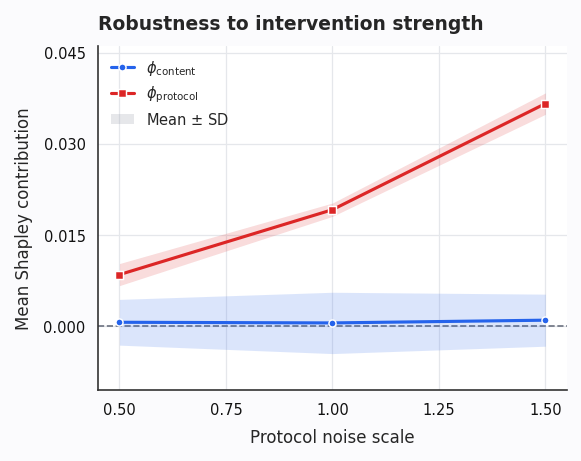


Robustness summary used for the figure:


,protocol_noise_scale,content_mean,content_sd,protocol_mean,protocol_sd,content_n,protocol_n
0,0.5,0.0007,0.0038,0.0085,0.0018,15,15
1,1.0,0.0006,0.0050,0.0192,0.0011,15,15
2,1.5,0.0010,0.0043,0.0366,0.0018,15,15



Saved:
- E:\Research\Attributing Cross-Corpus Failure\results\figures\fig_robustness_curve.pdf
- E:\Research\Attributing Cross-Corpus Failure\results\figures\fig_robustness_curve.png
- E:\Research\Attributing Cross-Corpus Failure\results\tables\robustness_curve_summary.csv


In [ ]:
# ===================== CELL 54: Robustness Curve =====================


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
from pathlib import Path


ROBUSTNESS_CSV = Path(
    r"E:\Research\Attributing Cross-Corpus Failure\results\tables\robustness_results.csv"
)

if not ROBUSTNESS_CSV.exists():
    raise FileNotFoundError(
        f"Robustness results file not found:\n{ROBUSTNESS_CSV}"
    )

ROBUSTNESS_RESULTS = pd.read_csv(ROBUSTNESS_CSV)

print(f"Loaded: {ROBUSTNESS_CSV}")
print(f"Shape: {ROBUSTNESS_RESULTS.shape}")
print("Original columns:", list(ROBUSTNESS_RESULTS.columns))


COLUMN_ALIASES = {
    "noise_scale": "protocol_noise_scale",
    "protocol_noise": "protocol_noise_scale",
    "intervention_strength": "protocol_noise_scale",
    "strength": "protocol_noise_scale",

    "phi_content_mean": "phi_content",
    "mean_phi_content": "phi_content",
    "content_phi": "phi_content",
    "phi_c": "phi_content",

    "phi_protocol_mean": "phi_protocol",
    "mean_phi_protocol": "phi_protocol",
    "protocol_phi": "phi_protocol",
    "phi_p": "phi_protocol",

    "random_seed": "seed",
    "run_seed": "seed",
}

ROBUSTNESS_RESULTS = ROBUSTNESS_RESULTS.rename(
    columns=COLUMN_ALIASES
)

REQUIRED_COLUMNS = {
    "protocol_noise_scale",
    "phi_content",
    "phi_protocol",
}

missing_columns = REQUIRED_COLUMNS - set(ROBUSTNESS_RESULTS.columns)

if missing_columns:
    raise ValueError(
        f"Missing required columns after alias mapping: "
        f"{sorted(missing_columns)}\n"
        f"Available columns: {list(ROBUSTNESS_RESULTS.columns)}"
    )

for col in ["protocol_noise_scale", "phi_content", "phi_protocol"]:
    ROBUSTNESS_RESULTS[col] = pd.to_numeric(
        ROBUSTNESS_RESULTS[col],
        errors="coerce",
    )

ROBUSTNESS_RESULTS = ROBUSTNESS_RESULTS.dropna(
    subset=["protocol_noise_scale", "phi_content", "phi_protocol"]
)

if not len(ROBUSTNESS_RESULTS):
    raise ValueError(
        "No valid rows remain after cleaning the robustness results."
    )

print("\nCleaned robustness results:")
display(ROBUSTNESS_RESULTS.head())

PUB_1COL = (3.8, 3.0)  

PUB_COLORS = {
    "content": "#2563EB",   
    "protocol": "#DC2626",  
}

PUB_RC = {
    "font.family": "DejaVu Sans",
    "font.size": 8,
    "axes.titlesize": 9,
    "axes.titleweight": "bold",
    "axes.labelsize": 8,
    "axes.edgecolor": "#333333",
    "axes.linewidth": 0.8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "xtick.color": "#111111",
    "ytick.color": "#111111",
    "grid.color": "#E5E7EB",
    "grid.linewidth": 0.6,
    "legend.frameon": False,
    "legend.fontsize": 7,
    "legend.title_fontsize": 7.5,
}

plt.rcParams.update(PUB_RC)

FIG_DIR = Path(FIG_DIR)
FIG_DIR.mkdir(parents=True, exist_ok=True)


def plot_robustness_curve(
    robustness_results,
    fig_dir=FIG_DIR,
    filename="fig_robustness_curve",
    x_col="protocol_noise_scale",
    show_sd_band=True,
    show_points=True,
    band_alpha=0.16,
):
    """
    Plots mean Shapley contributions across protocol-noise strength.

    Expected columns:
        protocol_noise_scale
        phi_content
        phi_protocol

    Optional:
        seed or another repetition identifier
    """

    df = robustness_results.copy()
    df = df.sort_values(x_col)

    summary = (
        df.groupby(x_col, as_index=False)
        .agg(
            content_mean=("phi_content", "mean"),
            content_sd=("phi_content", "std"),
            protocol_mean=("phi_protocol", "mean"),
            protocol_sd=("phi_protocol", "std"),
            content_n=("phi_content", "count"),
            protocol_n=("phi_protocol", "count"),
        )
        .sort_values(x_col)
    )

    x = summary[x_col].to_numpy(dtype=float)

    content_y = summary["content_mean"].to_numpy(dtype=float)
    content_sd = summary["content_sd"].fillna(0).to_numpy(dtype=float)

    protocol_y = summary["protocol_mean"].to_numpy(dtype=float)
    protocol_sd = summary["protocol_sd"].fillna(0).to_numpy(dtype=float)

    fig, ax = plt.subplots(figsize=PUB_1COL)


    if show_sd_band:
        ax.fill_between(
            x,
            content_y - content_sd,
            content_y + content_sd,
            color=PUB_COLORS["content"],
            alpha=band_alpha,
            lw=0,
            zorder=2,
        )

        ax.fill_between(
            x,
            protocol_y - protocol_sd,
            protocol_y + protocol_sd,
            color=PUB_COLORS["protocol"],
            alpha=band_alpha,
            lw=0,
            zorder=2,
        )


    ax.plot(
        x,
        content_y,
        color=PUB_COLORS["content"],
        lw=1.5,
        marker="o" if show_points else None,
        ms=3.4,
        mfc=PUB_COLORS["content"],
        mec="white",
        mew=0.7,
        label=r"$\phi_{\mathrm{content}}$",
        zorder=5,
    )

    ax.plot(
        x,
        protocol_y,
        color=PUB_COLORS["protocol"],
        lw=1.5,
        marker="s" if show_points else None,
        ms=3.4,
        mfc=PUB_COLORS["protocol"],
        mec="white",
        mew=0.7,
        label=r"$\phi_{\mathrm{protocol}}$",
        zorder=5,
    )

    ax.axhline(
        0,
        color="#6B7280",
        lw=0.8,
        ls="--",
        zorder=1,
    )


    ax.set_xlabel(
        "Protocol noise scale",
        labelpad=5,
    )
    ax.set_ylabel(
        "Mean Shapley contribution",
        labelpad=5,
    )
    ax.set_title(
        "Robustness to intervention strength",
        loc="left",
        pad=8,
    )


    ax.xaxis.set_major_locator(
        MaxNLocator(nbins=5, prune="lower")
    )
    ax.yaxis.set_major_locator(
        MaxNLocator(nbins=5, prune="lower")
    )

    ax.grid(
        True,
        axis="both",
        color="#E5E7EB",
        lw=0.6,
        zorder=0,
    )
    ax.set_axisbelow(True)
    ax.tick_params(
        axis="both",
        length=2.5,
        width=0.7,
    )

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

    all_values = np.concatenate([
        content_y,
        protocol_y,
        content_y + content_sd,
        content_y - content_sd,
        protocol_y + protocol_sd,
        protocol_y - protocol_sd,
    ])

    ymin = np.nanmin(all_values)
    ymax = np.nanmax(all_values)
    span = max(abs(ymax - ymin), 1e-8)

    ax.set_ylim(
        ymin - 0.14 * span,
        ymax + 0.18 * span,
    )


    handles = [
        Line2D(
            [0], [0],
            color=PUB_COLORS["content"],
            lw=1.5,
            marker="o",
            ms=3.4,
            markerfacecolor=PUB_COLORS["content"],
            markeredgecolor="white",
            markeredgewidth=0.7,
            label=r"$\phi_{\mathrm{content}}$",
        ),
        Line2D(
            [0], [0],
            color=PUB_COLORS["protocol"],
            lw=1.5,
            marker="s",
            ms=3.4,
            markerfacecolor=PUB_COLORS["protocol"],
            markeredgecolor="white",
            markeredgewidth=0.7,
            label=r"$\phi_{\mathrm{protocol}}$",
        ),
    ]

    if show_sd_band:
        handles.append(
            plt.Rectangle(
                (0, 0),
                1,
                1,
                facecolor="#9CA3AF",
                alpha=0.25,
                edgecolor="none",
                label=r"Mean $\pm$ SD",
            )
        )

    ax.legend(
        handles=handles,
        loc="best",
        handlelength=1.6,
        labelspacing=0.45,
        borderpad=0.35,
    )


    fig.tight_layout(pad=0.55)

    fig.savefig(
        fig_dir / f"{filename}.pdf",
        bbox_inches="tight",
    )
    fig.savefig(
        fig_dir / f"{filename}.png",
        dpi=600,
        bbox_inches="tight",
    )

    plt.show()

    return summary


ROBUSTNESS_SUMMARY = plot_robustness_curve(
    robustness_results=ROBUSTNESS_RESULTS,
    fig_dir=FIG_DIR,
    filename="fig_robustness_curve",
    x_col="protocol_noise_scale",
    show_sd_band=True,
    show_points=True,
    band_alpha=0.16,
)

print("\nRobustness summary used for the figure:")
display(ROBUSTNESS_SUMMARY.round(4))

ROBUSTNESS_SUMMARY.to_csv(
    FIG_DIR.parent / "tables" / "robustness_curve_summary.csv",
    index=False,
)

print("\nSaved:")
print(f"- {FIG_DIR / 'fig_robustness_curve.pdf'}")
print(f"- {FIG_DIR / 'fig_robustness_curve.png'}")
print(
    f"- {FIG_DIR.parent / 'tables' / 'robustness_curve_summary.csv'}"
)

**[CELL 55]**

## 12. External real-corpus stress test

Real corpora are not assigned synthetic factor labels. For each external target, the model receives only target adaptation text without labels, and the target test labels are used once for final evaluation. Results include corpus provenance, class-label coverage, text/register signatures, and an OOD flag relative to the synthetic anchor range.

This section answers: **Does the model fail on real targets, and are their observable signatures outside the synthetic support?** It does not answer: **What causal percentage of the real drop is platform or language?**

In [ ]:
# ===================== CELL 56 =====================


def script_features(texts):
    texts = pd.Series(texts).astype(str)
    chars = texts.str.len().sum()
    bangla = texts.map(lambda s: sum("\u0980" <= ch <= "\u09ff" for ch in s)).sum()
    latin = texts.map(lambda s: sum(("a" <= ch.lower() <= "z") for ch in s)).sum()
    return {
        "mean_chars": float(texts.str.len().mean()),
        "mean_tokens": float(texts.str.split().str.len().mean()),
        "bangla_char_fraction": float(bangla / max(chars, 1)),
        "latin_char_fraction": float(latin / max(chars, 1)),
    }

def js_divergence(p, q):
    keys = sorted(set(p) | set(q))
    p = np.array([p.get(k, 0.0) for k in keys], dtype=float); q = np.array([q.get(k, 0.0) for k in keys], dtype=float)
    p = p / max(p.sum(), 1e-12); q = q / max(q.sum(), 1e-12); m = 0.5 * (p + q)
    return float(0.5 * (stats.entropy(p, m) + stats.entropy(q, m)))

def signature(anchor_df, target_df):
    out = script_features(target_df["text"])
    out.update({f"anchor_{k}": v for k, v in script_features(anchor_df["text"]).items()})
    if "topic" in anchor_df and "topic" in target_df:
        p = anchor_df["topic"].fillna("__unknown__").value_counts(normalize=True).to_dict()
        q = target_df["topic"].fillna("__unknown__").value_counts(normalize=True).to_dict()
        out["topic_js"] = js_divergence(p, q)
    if target_df["true_label"].notna().any(): out["target_positive_rate"] = float(target_df["true_label"].mean())
    else: out["target_positive_rate"] = np.nan
    return out

REAL_SIGNATURES = []
for source, parts in REAL_TARGET_SPLITS.items():
    REAL_SIGNATURES.append({"source": source, **signature(ANCHOR_SPLITS["train"], parts["test"])})
REAL_SIGNATURES_DF = pd.DataFrame(REAL_SIGNATURES)
display(REAL_SIGNATURES_DF)
REAL_SIGNATURES_DF.to_csv(OUT_ROOT / "tables" / "real_target_signatures.csv", index=False)

,source,mean_chars,mean_tokens,bangla_char_fraction,latin_char_fraction,anchor_mean_chars,anchor_mean_tokens,anchor_bangla_char_fraction,anchor_latin_char_fraction,topic_js,target_positive_rate
0,BD-SHS,70.633353,13.042888,0.815208,0.001231,78.563867,13.596389,0.736563,0.071344,0.693147,0.480950
1,HateXplain,128.130087,23.587209,0.000000,0.812180,78.563867,13.596389,0.736563,0.071344,0.693147,0.431686


In [ ]:
# ===================== CELL 57 =====================
from pathlib import Path

PRIMARY_PATH = Path(OUT_ROOT) / "tables" / "factorial_results.csv"

FACTORIAL_RESULTS = require_complete_factorial(PRIMARY_PATH)

print("Primary factorial validated:", len(FACTORIAL_RESULTS))
print("Expected rows:", len(EXPECTED_KEYS))

Primary factorial validated: 120
Expected rows: 120


In [ ]:
# ===================== CELL 58 =====================
import itertools

EXPECTED_KEYS = [
    {
        "model": model,
        "seed": seed,
        "content_on": content_on,
        "protocol_on": protocol_on,
    }
    for model, seed, (content_on, protocol_on) in itertools.product(
        CFG.MODELS,
        CFG.SEEDS,
        itertools.product([0, 1], repeat=2),
    )
]

print("Expected factorial rows:", len(EXPECTED_KEYS))
print("Models:", CFG.MODELS)
print("Seeds:", CFG.SEEDS)


Expected factorial rows: 120
Models: ['MAJORITY', 'TFIDF_LOGREG', 'ERM', 'DANN', 'CORAL', 'PROTOCOL_CORRECTED']
Seeds: [13, 42, 2024, 3407, 9001]


In [ ]:
# ===================== CELL 59 =====================
RESULTS_PATH = Path(OUT_ROOT) / "tables" / "factorial_results.csv"
FACTORIAL_RESULTS = require_complete_factorial(RESULTS_PATH)
print("Primary factorial validated:", len(FACTORIAL_RESULTS))


Primary factorial validated: 120


In [ ]:
# ===================== CELL 60 =====================


import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer

CFG.NUM_WORKERS = 0

NEURAL_MODELS = {
    "ERM",
    "DANN",
    "CORAL",
    "PROTOCOL_CORRECTED",
}
NEURAL_REQUESTED = any(model in NEURAL_MODELS for model in CFG.MODELS)

if not NEURAL_REQUESTED:
    raise RuntimeError(
        "No neural model is enabled in CFG.MODELS; check CFG.MODELS before evaluation."
    )

TOKENIZER = AutoTokenizer.from_pretrained(
    CFG.BACKBONE,
    use_fast=True,
)

if TOKENIZER is None:
    raise RuntimeError("Tokenizer initialization returned None.")


class TextDataset(Dataset):
    def __init__(self, df, label_col="observed_label", domain=0):
        self.text = df["text"].astype(str).tolist()
        self.labels = (
            df[label_col].fillna(-1).astype(int).tolist()
            if label_col in df
            else [-1] * len(df)
        )
        self.domain = [int(domain)] * len(df)

    def __len__(self):
        return len(self.text)

    def __getitem__(self, i):
        return self.text[i], self.labels[i], self.domain[i]


def make_collate(tokenizer):
    if tokenizer is None:
        raise RuntimeError("A tokenizer is required for neural DataLoader construction.")

    def collate(batch):
        texts, labels, domains = zip(*batch)
        tok = tokenizer(
            list(texts),
            padding=True,
            truncation=True,
            max_length=CFG.MAX_LENGTH,
            return_tensors="pt",
        )
        return {
            "input_ids": tok["input_ids"],
            "attention_mask": tok["attention_mask"],
            "labels": torch.tensor(labels, dtype=torch.long),
            "domains": torch.tensor(domains, dtype=torch.long),
        }

    return collate


COLLATE = make_collate(TOKENIZER)


def make_loader(
    df,
    label_col="observed_label",
    domain=0,
    shuffle=False,
    batch_size=None,
):
    if COLLATE is None:
        raise RuntimeError("COLLATE is not initialized.")

    dataset = TextDataset(df, label_col=label_col, domain=domain)
    return DataLoader(
        dataset,
        batch_size=batch_size or CFG.BATCH_SIZE,
        shuffle=shuffle,
        num_workers=CFG.NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
        collate_fn=COLLATE,
    )


print("TOKENIZER:", TOKENIZER.__class__.__name__)
print("COLLATE available:", COLLATE is not None)
print("TextDataset available:", "TextDataset" in globals())
print("make_loader available:", callable(make_loader))


TOKENIZER: XLMRobertaTokenizer
COLLATE available: True
TextDataset available: True
make_loader available: True


In [ ]:
# ===================== CELL 61 =====================
assert TOKENIZER is not None
assert COLLATE is not None
assert callable(make_loader)
assert "TextDataset" in globals()
print("Neural evaluation dependencies restored successfully.")


Neural evaluation dependencies restored successfully.


In [ ]:
# ===================== CELL 62 =====================
CFG.RUN_REAL_EVAL = True

In [ ]:
# ===================== CELL 63 =====================


def protocol_shift(df, on, seed):
    out = df.copy().reset_index(drop=True)
    out["observed_label"] = out["true_label"].astype(float)

    if not on:
        return out

    rng = np.random.default_rng(seed)
    y = out["true_label"].astype(int).to_numpy()
    observed = [
        rng.choice([0, 1], p=CFG.PROTOCOL_TRANSITION[yi])
        for yi in y
    ]
    out["observed_label"] = np.asarray(observed, dtype=float)
    out["protocol_on"] = 1
    return out

print("protocol_shift restored:", callable(protocol_shift))


protocol_shift restored: True


In [ ]:
# ===================== CELL 64 =====================
required = [
    "train_one_run",
    "train_classical_run",
    "infinite_loader",
    "move_batch",
    "ShiftModel",
    "evaluate_model",
    "evaluate_observed_loss",
    "select_threshold",
    "metric_dict",
    "forward_corrected_loss",
    "coral_loss",
    "get_linear_schedule_with_warmup",
]

print({name: name in globals() for name in required})


{'train_one_run': True, 'train_classical_run': True, 'infinite_loader': True, 'move_batch': True, 'ShiftModel': True, 'evaluate_model': True, 'evaluate_observed_loss': True, 'select_threshold': True, 'metric_dict': True, 'forward_corrected_loss': True, 'coral_loss': True, 'get_linear_schedule_with_warmup': True}


In [ ]:
# ===================== CELL 65 =====================
CFG.RUN_REAL_EVAL = True
print("RUN_REAL_EVAL:", CFG.RUN_REAL_EVAL)


RUN_REAL_EVAL: True


In [ ]:
# ===================== CELL 66 =====================


EXPECTED_EXTERNAL_TARGETS = {
    "BD-SHS",
    "HateXplain",
}

REAL_TARGET_MODELS = [
    "ERM",
    "DANN",
    "CORAL",
]


loaded_targets = set(REAL_TARGET_SPLITS.keys())
missing_targets = EXPECTED_EXTERNAL_TARGETS - loaded_targets
unexpected_targets = loaded_targets - EXPECTED_EXTERNAL_TARGETS

if missing_targets:
    raise RuntimeError(
        "Missing expected external target(s): "
        + ", ".join(sorted(missing_targets))
    )

if unexpected_targets:
    raise RuntimeError(
        "Unexpected external target(s): "
        + ", ".join(sorted(unexpected_targets))
    )



def train_real_target(source, model_kind, seed):
    if source not in EXPECTED_EXTERNAL_TARGETS:
        raise ValueError(
            f"Unsupported external target: {source}"
        )

    if model_kind not in REAL_TARGET_MODELS:
        raise ValueError(
            f"Unsupported real-target model: {model_kind}"
        )

    parts = REAL_TARGET_SPLITS[source]
    test_df = parts["test"].copy()


    if not test_df["true_label"].notna().all():
        return {
            "source": source,
            "model": model_kind,
            "seed": seed,
            "status": "NO_RELIABLE_TEST_LABELS",
        }

    if not test_df["true_label"].isin([0.0, 1.0]).all():
        return {
            "source": source,
            "model": model_kind,
            "seed": seed,
            "status": "NON_BINARY_TEST_LABELS",
        }

    cell = {
        "train": protocol_shift(
            ANCHOR_SPLITS["train"],
            False,
            seed,
        ),
        "val": protocol_shift(
            ANCHOR_SPLITS["val"],
            False,
            seed + 1,
        ),
        "adapt": parts["adapt"].assign(
            observed_label=-1
        ),
        "test": test_df,
        "content_on": np.nan,
        "protocol_on": np.nan,
        "seed": seed,
    }

    out = train_one_run(
        model_kind,
        cell,
        seed,
        run_name=f"REAL_{source}_{model_kind}_s{seed}",
        persist=False,
    )

    out["source"] = source
    out["status"] = "OK"

    return out


if CFG.RUN_REAL_EVAL:
    results_path = (
        OUT_ROOT
        / "tables"
        / "real_target_results.csv"
    )
    results_path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    if results_path.exists():
        REAL_RESULTS_prev = pd.read_csv(results_path)

        required_columns = {
            "source",
            "model",
            "seed",
        }

        if not required_columns.issubset(
            REAL_RESULTS_prev.columns
        ):
            raise RuntimeError(
                "Existing real_target_results.csv is missing "
                "required columns: "
                + ", ".join(
                    sorted(
                        required_columns
                        - set(REAL_RESULTS_prev.columns)
                    )
                )
            )

        done_keys = set(
            zip(
                REAL_RESULTS_prev["source"].astype(str),
                REAL_RESULTS_prev["model"].astype(str),
                REAL_RESULTS_prev["seed"].astype(int),
            )
        )

        real_rows = REAL_RESULTS_prev.to_dict(
            "records"
        )

        print(
            f"Resuming: {len(done_keys)} combination(s) "
            f"already completed from {results_path}"
        )
    else:
        REAL_RESULTS_prev = pd.DataFrame()
        done_keys = set()
        real_rows = []

        print(
            "No previous real-target results found; "
            "starting fresh."
        )

    total_combos = (
        len(EXPECTED_EXTERNAL_TARGETS)
        * len(REAL_TARGET_MODELS)
        * len(CFG.SEEDS)
    )

    done_count = len(done_keys)

    for source in sorted(EXPECTED_EXTERNAL_TARGETS):
        for model_kind in REAL_TARGET_MODELS:
            for seed in CFG.SEEDS:
                key = (
                    str(source),
                    str(model_kind),
                    int(seed),
                )

                if key in done_keys:
                    continue

                try:
                    row = train_real_target(
                        source,
                        model_kind,
                        seed,
                    )
                except Exception as exc:
                    row = {
                        "source": source,
                        "model": model_kind,
                        "seed": seed,
                        "status": "FAILED",
                        "error": repr(exc),
                    }

                real_rows.append(row)
                done_keys.add(key)
                done_count += 1

                # Incremental save after every combination.
                pd.DataFrame(real_rows).to_csv(
                    results_path,
                    index=False,
                )

                print(
                    f"[{done_count}/{total_combos}] done -> "
                    f"source={source}, "
                    f"model={model_kind}, "
                    f"seed={seed}, "
                    f"status={row.get('status')}"
                )

    REAL_RESULTS = pd.DataFrame(real_rows)
    display(REAL_RESULTS)

else:
    REAL_RESULTS = None
    print(
        "Real-target training is disabled. "
        "Set CFG.RUN_REAL_EVAL = True only when the "
        "optional external evaluation is required."
    )


Resuming: 30 combination(s) already completed from E:\Research\Attributing Cross-Corpus Failure\results\tables\real_target_results.csv


,run_id,run_name,model,seed,content_on,protocol_on,best_epoch,n_train,n_test,decision_threshold,macro_f1,f1_pos,balanced_accuracy,ece,auroc,auprc,source,status
0,c923a2aa33c46e90,REAL_BD-SHS_ERM_s13,ERM,13,NaN,NaN,2,37390,5013,0.590244,0.722165,0.728761,0.724278,0.246583,0.827548,0.825502,BD-SHS,OK
1,c923a2aa33c46e90,REAL_BD-SHS_ERM_s42,ERM,42,NaN,NaN,3,37390,5013,0.542616,0.725230,0.734055,0.727794,0.245092,0.830011,0.824726,BD-SHS,OK
2,c923a2aa33c46e90,REAL_BD-SHS_ERM_s2024,ERM,2024,NaN,NaN,3,37390,5013,0.510834,0.723640,0.732405,0.726180,0.246239,0.840203,0.840252,BD-SHS,OK
3,c923a2aa33c46e90,REAL_BD-SHS_ERM_s3407,ERM,3407,NaN,NaN,2,37390,5013,0.499676,0.724498,0.732247,0.726843,0.237405,0.832875,0.819371,BD-SHS,OK
4,c923a2aa33c46e90,REAL_BD-SHS_ERM_s9001,ERM,9001,NaN,NaN,3,37390,5013,0.582528,0.724858,0.733256,0.727333,0.244289,0.833745,0.828949,BD-SHS,OK
5,c923a2aa33c46e90,REAL_BD-SHS_DANN_s13,DANN,13,NaN,NaN,3,37390,5013,0.518946,0.723674,0.731887,0.726104,0.247037,0.822443,0.796402,BD-SHS,OK
6,c923a2aa33c46e90,REAL_BD-SHS_DANN_s42,DANN,42,NaN,NaN,3,37390,5013,0.568542,0.724591,0.734041,0.727278,0.243141,0.802257,0.732846,BD-SHS,OK
7,c923a2aa33c46e90,REAL_BD-SHS_DANN_s2024,DANN,2024,NaN,NaN,3,37390,5013,0.482033,0.723023,0.732084,0.725619,0.249456,0.824419,0.797537,BD-SHS,OK
8,c923a2aa33c46e90,REAL_BD-SHS_DANN_s3407,DANN,3407,NaN,NaN,3,37390,5013,0.509420,0.725873,0.733966,0.728294,0.245950,0.818163,0.790107,BD-SHS,OK
9,c923a2aa33c46e90,REAL_BD-SHS_DANN_s9001,DANN,9001,NaN,NaN,3,37390,5013,0.650290,0.727261,0.735476,0.729715,0.245924,0.793722,0.711638,BD-SHS,OK


## 13. Error analysis and reproducibility package

The final paper must show where each model fails, not only report one aggregate number. Error analysis is performed only after complete results exist and is stratified by topic, text length, and corpus. The notebook also writes a machine-readable manifest containing the configuration, split hashes, source summary, run keys, failures, and artifact paths.

In [ ]:
# ===================== CELL 68: LLM Prediction Error Analysis =====================


import os
import re
import json
import hashlib
import numpy as np
import pandas as pd
from pathlib import Path


PROJECT_ROOT = Path(
    r"E:\Research\Attributing Cross-Corpus Failure"
)

RESULTS_ROOT = PROJECT_ROOT / "results"

LLM_PREDICTION_CSV = (
    RESULTS_ROOT
    / "predictions_llm"
    / "zeroshot_logit_cache_Qwen_Qwen2.5-1.5B-Instruct.csv"
)

LABEL_CSV = (
    PROJECT_ROOT
    / "data"
    / "HateXplain"
    / "test.csv"
)

ERROR_ANALYSIS_DIR = RESULTS_ROOT / "error_analysis"
ERROR_ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

THRESHOLD = 0.5


LABEL_TO_BINARY = {
    "hatespeech": 1,
    "offensive": 0,
    "normal": 0,
}

if not LLM_PREDICTION_CSV.exists():
    raise FileNotFoundError(
        f"LLM prediction cache not found:\n{LLM_PREDICTION_CSV}"
    )

pred_df = pd.read_csv(LLM_PREDICTION_CSV)

print(f"Loaded prediction cache: {LLM_PREDICTION_CSV}")
print(f"Prediction rows: {len(pred_df)}")
print(f"Prediction columns: {list(pred_df.columns)}")

if "key" not in pred_df.columns or "prob" not in pred_df.columns:
    raise ValueError(
        "Expected columns `key` and `prob`, but found: "
        f"{list(pred_df.columns)}"
    )

pred_df = pred_df.rename(columns={"prob": "prob_pos"})

pred_df["key"] = (
    pred_df["key"]
    .astype(str)
    .str.strip()
    .str.lower()
)

pred_df["prob_pos"] = pd.to_numeric(
    pred_df["prob_pos"],
    errors="coerce",
)

pred_df = pred_df.dropna(subset=["prob_pos"]).copy()

n_before = len(pred_df)
pred_df = pred_df.drop_duplicates(
    subset="key",
    keep="first",
).copy()

print(
    f"Removed {n_before - len(pred_df)} duplicate prediction keys."
)
print(f"Unique prediction keys: {len(pred_df)}")

print("\nPrediction preview:")
display(pred_df.head())

print("\nSample prediction keys:")
print(pred_df["key"].head(10).tolist())

prediction_keys = set(pred_df["key"])


if not LABEL_CSV.exists():
    raise FileNotFoundError(
        f"HateXplain test file not found:\n{LABEL_CSV}"
    )

label_df = pd.read_csv(LABEL_CSV)

print(f"\nLoaded HateXplain test file: {LABEL_CSV}")
print(f"Label rows: {len(label_df)}")
print(f"Label columns: {list(label_df.columns)}")
display(label_df.head())

required_columns = {"id", "text", "label"}
missing_columns = required_columns - set(label_df.columns)

if missing_columns:
    raise ValueError(
        f"HateXplain test file is missing columns: "
        f"{sorted(missing_columns)}"
    )

print("\nSearching project source for cache-generation logic...")

SEARCH_TERMS = [
    "zeroshot_logit_cache",
    "zeroshot_logit",
    "logit_cache",
    "predictions_llm",
    "hashlib.md5",
    "md5(",
    "key=md5",
    "key = md5",
    "cache_key",
    "prediction_key",
]

CODE_EXTENSIONS = {
    ".py", ".ipynb", ".md", ".txt",
    ".yaml", ".yml", ".json",
}

SKIP_DIRS = {
    "results", "outputs", "output", "checkpoints",
    "predictions_cache", "predictions_llm",
    "__pycache__", ".git", ".ipynb_checkpoints",
}

source_matches = []

for path in PROJECT_ROOT.rglob("*"):
    if not path.is_file():
        continue

    if path.suffix.lower() not in CODE_EXTENSIONS:
        continue

    if any(
        part.lower() in SKIP_DIRS
        for part in path.parts
    ):
        continue

    try:
        text = path.read_text(
            encoding="utf-8",
            errors="ignore",
        )
    except Exception:
        continue

    for term in SEARCH_TERMS:
        if term.lower() in text.lower():
            matching_lines = []

            for line_no, line in enumerate(
                text.splitlines(),
                start=1,
            ):
                if term.lower() in line.lower():
                    matching_lines.append(
                        f"{line_no}: {line.strip()}"
                    )

            source_matches.append({
                "term": term,
                "file": path,
                "lines": matching_lines[:15],
            })

            break

print(f"\nFound {len(source_matches)} potentially relevant source files.")

for item in source_matches[:20]:
    print("=" * 100)
    print(f"Matched term: {item['term']}")
    print(f"File: {item['file']}")

    for line in item["lines"]:
        print(f"    {line}")

if not source_matches:
    print(
        "\nNo cache-generation source file was found in this project folder.\n"
        "The script may be in another repository, Colab, Kaggle, or an "
        "archived notebook."
    )


def md5_hex(value):
    if value is None:
        return None
    return hashlib.md5(
        str(value).encode("utf-8")
    ).hexdigest()


def sha1_hex(value):
    if value is None:
        return None
    return hashlib.sha1(
        str(value).encode("utf-8")
    ).hexdigest()


def sha256_hex(value):
    if value is None:
        return None
    return hashlib.sha256(
        str(value).encode("utf-8")
    ).hexdigest()


def normalize_text(value):
    if pd.isna(value):
        return None

    text = str(value)

    text = re.sub(r"\s+", " ", text).strip()

    return text


def normalize_aggressive(value):
    if pd.isna(value):
        return None

    text = str(value).lower()

    text = re.sub(r"\s+", "", text)

    text = re.sub(r"[^\w]", "", text)

    return text


print("\nGenerating candidate text variants...")

label_df["text_raw"] = label_df["text"]
label_df["text_norm_ws"] = label_df["text"].map(normalize_text)
label_df["text_norm_aggressive"] = label_df["text"].map(normalize_aggressive)

text_variants = {
    "text_raw": label_df["text_raw"],
    "text_norm_ws": label_df["text_norm_ws"],
    "text_norm_aggressive": label_df["text_norm_aggressive"],
}


print("\nTesting hash-matching strategies...")

strategy_results = []

hash_functions = {
    "md5": md5_hex,
    "sha1": sha1_hex,
    "sha256": sha256_hex,
}

for text_name, text_series in text_variants.items():
    for hash_name, hash_function in hash_functions.items():
        label_hashes = set(
            text_series.map(hash_function).dropna()
        )

        matches = prediction_keys & label_hashes

        strategy_results.append({
            "strategy": f"{hash_name}_{text_name}",
            "text_variant": text_name,
            "hash_function": hash_name,
            "prefix": "",
            "suffix": "",
            "separator": None,
            "n_matches": len(matches),
        })

for text_name, text_series in text_variants.items():
    for order in ["id_text", "text_id"]:
        for hash_name, hash_function in hash_functions.items():
            if order == "id_text":
                values = (
                    label_df["id"].astype(str)
                    + text_series.astype(str)
                )
            else:
                values = (
                    text_series.astype(str)
                    + label_df["id"].astype(str)
                )

            label_hashes = set(
                values.map(hash_function).dropna()
            )

            matches = prediction_keys & label_hashes

            strategy_results.append({
                "strategy": f"{hash_name}_{order}_{text_name}",
                "text_variant": text_name,
                "hash_function": hash_name,
                "prefix": "",
                "suffix": "",
                "separator": order,
                "n_matches": len(matches),
            })

corpus_names = [
    "HateXplain", "hatexplain", "HATEXPLAIN",
]

split_names = [
    "test", "TEST", "validation", "val",
]

separators = [
    "|", ":", "__", "/", "-", "_",
]

for corpus in corpus_names:
    for split in split_names:
        for separator in separators:
            for text_name, text_series in text_variants.items():
                values_prefix = (
                    corpus
                    + separator
                    + split
                    + separator
                    + text_series.astype(str)
                )

                label_hashes = set(
                    values_prefix.map(md5_hex).dropna()
                )

                matches = prediction_keys & label_hashes

                strategy_results.append({
                    "strategy": (
                        f"md5_prefix_{corpus}_{split}_"
                        f"sep_{separator}_{text_name}"
                    ),
                    "text_variant": text_name,
                    "hash_function": "md5",
                    "prefix": f"{corpus}{separator}{split}{separator}",
                    "suffix": "",
                    "separator": separator,
                    "n_matches": len(matches),
                })

                # suffix format: text|split|corpus
                values_suffix = (
                    text_series.astype(str)
                    + separator
                    + split
                    + separator
                    + corpus
                )

                label_hashes = set(
                    values_suffix.map(md5_hex).dropna()
                )

                matches = prediction_keys & label_hashes

                strategy_results.append({
                    "strategy": (
                        f"md5_suffix_{corpus}_{split}_"
                        f"sep_{separator}_{text_name}"
                    ),
                    "text_variant": text_name,
                    "hash_function": "md5",
                    "prefix": "",
                    "suffix": f"{separator}{split}{separator}{corpus}",
                    "separator": separator,
                    "n_matches": len(matches),
                })

strategy_df = pd.DataFrame(strategy_results).sort_values(
    "n_matches",
    ascending=False,
)

print("\nTop hash-matching strategies:")
display(strategy_df.head(30))

best_strategy = strategy_df.iloc[0]

print(
    f"\nBest strategy: {best_strategy['strategy']} "
    f"with {int(best_strategy['n_matches'])} matches."
)


if best_strategy["n_matches"] == 0:
    print(
        "\nNo tested hash strategy matched the prediction keys."
    )
    print(
        "The cache key was likely generated using a prompt template, "
        "tokenizer output, or another preprocessing step not available "
        "in the tested combinations."
    )

    print(
        "\nNext step: open the source file found by the project search, "
        "or search for the exact line where `key` was created."
    )

    raise ValueError(
        "Cannot merge prediction cache with HateXplain labels because the "
        "key-generation rule is unknown."
    )


print("\nApplying best matching strategy...")

text_series = text_variants[
    best_strategy["text_variant"]
]

hash_function = hash_functions[
    best_strategy["hash_function"]
]

if best_strategy["separator"] in ["id_text", "text_id"]:
    if best_strategy["separator"] == "id_text":
        candidate_values = (
            label_df["id"].astype(str)
            + text_series.astype(str)
        )
    else:
        candidate_values = (
            text_series.astype(str)
            + label_df["id"].astype(str)
        )

elif best_strategy["prefix"]:
    candidate_values = (
        best_strategy["prefix"]
        + text_series.astype(str)
    )

elif best_strategy["suffix"]:
    candidate_values = (
        text_series.astype(str)
        + best_strategy["suffix"]
    )

else:
    candidate_values = text_series.astype(str)

label_df["merge_key"] = candidate_values.map(
    hash_function
)

# Keep only labels whose generated hash exists in predictions
label_merge_df = label_df[
    label_df["merge_key"].isin(prediction_keys)
].copy()

label_merge_df = label_merge_df.rename(
    columns={
        "merge_key": "key",
        "label": "label_str",
    }
)

# Remove duplicate hash keys
label_merge_df = label_merge_df.drop_duplicates(
    subset="key",
    keep="first",
)

print(
    f"Label rows matching prediction keys: "
    f"{len(label_merge_df)}"
)


merged_df = pred_df.merge(
    label_merge_df[
        [
            "key",
            "id",
            "text",
            "label_str",
            "targets",
        ]
    ],
    on="key",
    how="inner",
    validate="one_to_one",
)

print(f"\nMerged rows: {len(merged_df)}")
print(f"Unmatched predictions: {len(pred_df) - len(merged_df)}")

if not len(merged_df):
    raise ValueError(
        "No rows survived the final merge."
    )


merged_df["label_str_clean"] = (
    merged_df["label_str"]
    .astype(str)
    .str.strip()
    .str.lower()
)

unknown_labels = merged_df[
    ~merged_df["label_str_clean"].isin(LABEL_TO_BINARY)
]

if len(unknown_labels):
    print(
        f"\nWarning: {len(unknown_labels)} labels are not in "
        "LABEL_TO_BINARY."
    )
    print(
        "Unknown labels:",
        unknown_labels["label_str_clean"].unique().tolist(),
    )

merged_df["y_true"] = merged_df["label_str_clean"].map(
    LABEL_TO_BINARY
)

merged_df = merged_df.dropna(
    subset=["y_true"]
).copy()

merged_df["y_true"] = merged_df["y_true"].astype(int)

merged_df["y_pred"] = (
    merged_df["prob_pos"] >= THRESHOLD
).astype(int)

merged_df["error_type"] = np.select(
    [
        (merged_df["y_true"] == 0) & (merged_df["y_pred"] == 1),
        (merged_df["y_true"] == 1) & (merged_df["y_pred"] == 0),
    ],
    ["false_positive", "false_negative"],
    default="correct",
)

ERROR_ANALYSIS_DF = merged_df.copy()

print("\nError-analysis table created.")
display(
    ERROR_ANALYSIS_DF[
        [
            "key",
            "prob_pos",
            "y_true",
            "y_pred",
            "error_type",
            "label_str",
        ]
    ].head()
)


def summarize_error_table(error_df):
    counts = error_df["error_type"].value_counts().to_dict()

    total = len(error_df)
    fp = counts.get("false_positive", 0)
    fn = counts.get("false_negative", 0)
    correct = counts.get("correct", 0)

    return {
        "n_examples": total,
        "correct": correct,
        "false_positive": fp,
        "false_negative": fn,
        "accuracy": correct / total if total else np.nan,
        "false_positive_rate": fp / max(
            int((error_df["y_true"] == 0).sum()), 1
        ),
        "false_negative_rate": fn / max(
            int((error_df["y_true"] == 1).sum()), 1
        ),
    }

ERROR_SUMMARY = summarize_error_table(ERROR_ANALYSIS_DF)

print("\nError-analysis summary:")
print(json.dumps(ERROR_SUMMARY, indent=2, ensure_ascii=False))


error_analysis_path = (
    ERROR_ANALYSIS_DIR
    / "error_analysis_qwen_zeroshot_hatexplain.csv"
)

summary_path = (
    ERROR_ANALYSIS_DIR
    / "error_summary_qwen_zeroshot_hatexplain.json"
)

strategy_path = (
    ERROR_ANALYSIS_DIR
    / "hash_matching_strategies.csv"
)

source_search_path = (
    ERROR_ANALYSIS_DIR
    / "cache_generation_source_search.json"
)

ERROR_ANALYSIS_DF.to_csv(
    error_analysis_path,
    index=False,
)

pd.DataFrame([ERROR_SUMMARY]).to_csv(
    ERROR_ANALYSIS_DIR / "error_summary_qwen_zeroshot_hatexplain.csv",
    index=False,
)

strategy_df.to_csv(
    strategy_path,
    index=False,
)

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(ERROR_SUMMARY, f, indent=2, ensure_ascii=False)

with open(source_search_path, "w", encoding="utf-8") as f:
    json.dump(
        [
            {
                "term": item["term"],
                "file": str(item["file"]),
                "matching_lines": item["lines"],
            }
            for item in source_matches
        ],
        f,
        indent=2,
        ensure_ascii=False,
    )

print("\nSaved:")
print(f"- {error_analysis_path}")
print(f"- {summary_path}")
print(f"- {strategy_path}")
print(f"- {source_search_path}")


if FACTORIAL_RESULTS is not None:
    print(
        "\nError analysis is available for Qwen zero-shot predictions "
        "on HateXplain if a matching key strategy was found."
    )
    print(
        "Deliberately no aggregate claim is made from a single model or seed."
    )

Loaded prediction cache: E:\Research\Attributing Cross-Corpus Failure\results\predictions_llm\zeroshot_logit_cache_Qwen_Qwen2.5-1.5B-Instruct.csv
Prediction rows: 20098
Prediction columns: ['key', 'prob']
Removed 0 duplicate prediction keys.
Unique prediction keys: 20098

Prediction preview:


,key,prob_pos
0,88cdb6e1771ab5729ea41c1d221cd73f,0.997488
1,01ef999852c772d0fab5f6f7b1c51741,0.996777
2,d286d95db494e59d5454e72b0b597e75,0.996777
3,9adb213618fbb20dfbf567a0a1b90159,0.998043
4,b16cb55b43edb0921afbbeb10e41ca2f,0.996623



Sample prediction keys:
['88cdb6e1771ab5729ea41c1d221cd73f', '01ef999852c772d0fab5f6f7b1c51741', 'd286d95db494e59d5454e72b0b597e75', '9adb213618fbb20dfbf567a0a1b90159', 'b16cb55b43edb0921afbbeb10e41ca2f', '3704fb9b4069811504bf49611d666752', '4c4370daae8147c343d27d6fdf958a36', 'ebe01bd66631179446adae82fd3a81b1', '72a49f68f2cf8956d7a866f941a6df1f', '89f0e9e09070cfbded90541dafa3eda1']

Loaded HateXplain test file: E:\Research\Attributing Cross-Corpus Failure\data\HateXplain\test.csv
Label rows: 1924
Label columns: ['id', 'text', 'label', 'targets']


,id,text,label,targets
0,1178610029273976833_twitter,<user> men can not be raped can not be abused ...,normal,NaN
1,1165785686903009283_twitter,<user> you are missing an essential premise wh...,normal,"None,Refugee"
2,1252707503441313794_twitter,<user> <user> why are you repeating yourself a...,offensive,"None,Other"
3,1103385226921762816_twitter,<user> <user> well she ’ muslim so of course s...,hatespeech,"Arab,Jewish,Islam"
4,1169443635869487105_twitter,<user> lol not me i don ’ t deal with bms not ...,offensive,African



Searching project source for cache-generation logic...

Found 2 potentially relevant source files.
Matched term: hashlib.md5
File: E:\Research\Attributing Cross-Corpus Failure\cohens_kappa.ipynb
    109: "df[\"key\"] = df[TEXT].map(lambda s: hashlib.md5(norm(s).encode(\"utf-8\")).hexdigest())\n",
Matched term: zeroshot_logit_cache
File: E:\Research\Attributing Cross-Corpus Failure\ShiftLens_Merged_FullRun.ipynb
    7307: "Loaded prediction cache: E:\\Research\\Attributing Cross-Corpus Failure\\results\\predictions_llm\\zeroshot_logit_cache_Qwen_Qwen2.5-1.5B-Instruct.csv\n",
    7660: "    / \"zeroshot_logit_cache_Qwen_Qwen2.5-1.5B-Instruct.csv\"\n",
    7769: "    \"zeroshot_logit_cache\",\n",

Generating candidate text variants...

Testing hash-matching strategies...

Top hash-matching strategies:


,strategy,text_variant,hash_function,prefix,suffix,separator,n_matches
0,md5_text_raw,text_raw,md5,,,None,0
1,sha1_text_raw,text_raw,sha1,,,None,0
2,sha256_text_raw,text_raw,sha256,,,None,0
3,md5_text_norm_ws,text_norm_ws,md5,,,None,0
4,sha1_text_norm_ws,text_norm_ws,sha1,,,None,0
5,sha256_text_norm_ws,text_norm_ws,sha256,,,None,0
6,md5_text_norm_aggressive,text_norm_aggressive,md5,,,None,0
7,sha1_text_norm_aggressive,text_norm_aggressive,sha1,,,None,0
8,sha256_text_norm_aggressive,text_norm_aggressive,sha256,,,None,0
9,md5_id_text_text_raw,text_raw,md5,,,id_text,0



Best strategy: md5_text_raw with 0 matches.

No tested hash strategy matched the prediction keys.
The cache key was likely generated using a prompt template, tokenizer output, or another preprocessing step not available in the tested combinations.

Next step: open the source file found by the project search, or search for the exact line where `key` was created.


ValueError: Cannot merge prediction cache with HateXplain labels because the key-generation rule is unknown.

### 13.1b Topic-stratified accuracy

Using `reload_predictions` (Section 8.5) on the no-shift `(0,0)` cell for every completed model and seed, this cell aggregates accuracy by topic across the six annotated categories (political, religious, personal, geopolitical, gender-abusive, non-abusive), giving the fairness-relevant stratified breakdown.

In [ ]:
# ===================== CELL 27b: Cached reload_predictions (run after CELL 27, before CELL 70/104) =====================
import contextlib, time

PRED_CACHE_DIR = OUT_ROOT / "predictions_cache"
PRED_CACHE_DIR.mkdir(parents=True, exist_ok=True)

EVAL_BS_RELOAD = 128         
USE_FP16_RELOAD = True       

if "_reload_predictions_raw" not in globals():
    _reload_predictions_raw = reload_predictions     

def reload_predictions(model_kind, seed, content_on, protocol_on):
    f = PRED_CACHE_DIR / f"{model_kind}_c{content_on}_p{protocol_on}_s{seed}.pkl"
    if f.exists():
        return pd.read_pickle(f)
    old_bs = CFG.EVAL_BATCH_SIZE
    CFG.EVAL_BATCH_SIZE = EVAL_BS_RELOAD
    try:
        use_amp = USE_FP16_RELOAD and torch.cuda.is_available()
        ctx = torch.autocast("cuda", dtype=torch.float16) if use_amp else contextlib.nullcontext()
        with ctx:
            out = _reload_predictions_raw(model_kind, seed, content_on, protocol_on)
    finally:
        CFG.EVAL_BATCH_SIZE = old_bs
    if out is not None:
        out.to_pickle(f)
    return out

print("DEVICE:", DEVICE, "| cache dir:", PRED_CACHE_DIR, "| cached files:", len(list(PRED_CACHE_DIR.glob("*.pkl"))))

DEVICE: cpu | cache dir: E:\Research\Attributing Cross-Corpus Failure\results\predictions_cache | cached files: 10


In [ ]:
# ===================== CELL 70: Need Checkpoint =====================
from tqdm.auto import tqdm
import time
if FACTORIAL_RESULTS is not None:
    topic_frames = []
    jobs = [(m, s) for m in FACTORIAL_RESULTS["model"].unique() for s in CFG.SEEDS]
    for model_kind, seed in tqdm(jobs, desc="Reloading predictions", unit="run"):
        t0 = time.time()
        et = reload_predictions(model_kind, seed, 0, 0)
        if et is not None:
            topic_frames.append(et)
        tqdm.write(f"{model_kind} s{seed}: {'ok' if et is not None else 'no checkpoint'} ({time.time() - t0:.1f}s)")
    if topic_frames:
        TOPIC_ERRORS = pd.concat(topic_frames, ignore_index=True)
        TOPIC_SUMMARY = (TOPIC_ERRORS.assign(correct=lambda d: d.error_type == "correct")
                          .groupby(["model", "topic"])["correct"].mean().rename("accuracy").reset_index())
        display(TOPIC_SUMMARY.pivot(index="topic", columns="model", values="accuracy"))
        TOPIC_SUMMARY.to_csv(OUT_ROOT / "tables" / "topic_stratified_accuracy.csv", index=False)
    else:
        TOPIC_SUMMARY = None
        print("No reloadable checkpoints found on disk yet for topic-stratified analysis.")
else:
    TOPIC_SUMMARY = None

Reloading predictions:   0%|          | 0/30 [00:00<?, ?run/s]

MAJORITY s13: ok (0.0s)
MAJORITY s42: ok (0.0s)
MAJORITY s2024: ok (0.0s)
MAJORITY s3407: ok (0.0s)
MAJORITY s9001: ok (0.0s)
TFIDF_LOGREG s13: ok (0.0s)
TFIDF_LOGREG s42: ok (0.0s)
TFIDF_LOGREG s2024: ok (0.0s)
TFIDF_LOGREG s3407: ok (0.0s)
TFIDF_LOGREG s9001: ok (0.0s)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


ERM s13: ok (535.7s)


...

[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


DANN s3407: ok (610.1s)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


KeyboardInterrupt: 

#### run this successfull before, so this time I skip it as I have already result at E:\Research\Attributing Cross-Corpus Failure\results\tables\topic_stratified_accuracy.csv

Loaded topic summary: E:\Research\Attributing Cross-Corpus Failure\results\tables\topic_stratified_accuracy.csv
Rows: 36
Columns: ['model', 'topic', 'accuracy']


,model,topic,accuracy
0,CORAL,Gender abusive,0.973159
1,CORAL,Geopolitical,0.961692
2,CORAL,Non-abusive,0.919190
3,CORAL,Personal,0.928625
4,CORAL,Political,0.913273



Heatmap shape: (6, 6)
Topics: 6
Models: 6
Missing cells: 0


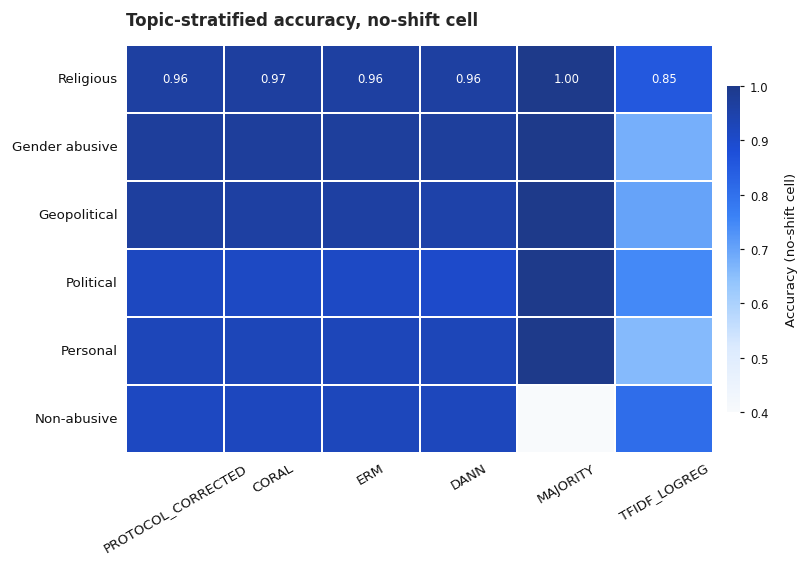


Saved:
- E:\Research\Attributing Cross-Corpus Failure\results\figures\fig_topic_error_heatmap.pdf
- E:\Research\Attributing Cross-Corpus Failure\results\figures\fig_topic_error_heatmap.png


In [ ]:
# ===================== CELL 71: Topic-Stratified Accuracy Heatmap =====================


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from pathlib import Path


RESULTS_ROOT = Path(
    r"E:\Research\Attributing Cross-Corpus Failure\results"
)

TOPIC_SUMMARY_CSV = (
    RESULTS_ROOT
    / "tables"
    / "topic_stratified_accuracy.csv"
)

FIG_DIR = RESULTS_ROOT / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


FIG_STYLE_2COL = (7.6, 4.6)  

HEAT_RC = {
    "font.family": "DejaVu Sans",
    "font.size": 8,
    "axes.titlesize": 10,
    "axes.titleweight": "bold",
    "axes.labelsize": 9,
    "axes.labelcolor": "#111111",
    "axes.edgecolor": "#333333",
    "axes.linewidth": 0.8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "xtick.color": "#111111",
    "ytick.color": "#111111",
    "figure.dpi": 120,
    "savefig.dpi": 600,
}

sns.set_theme(style="white", rc=HEAT_RC)


TOPIC_CMAP = LinearSegmentedColormap.from_list(
    "topic_accuracy",
    [
        "#F8FAFC",
        "#DBEAFE",
        "#93C5FD",
        "#3B82F6",
        "#1D4ED8",
        "#1E3A8A",
    ],
)


if not TOPIC_SUMMARY_CSV.exists():
    raise FileNotFoundError(
        f"Topic summary CSV not found:\n{TOPIC_SUMMARY_CSV}"
    )

TOPIC_SUMMARY = pd.read_csv(TOPIC_SUMMARY_CSV)

print(f"Loaded topic summary: {TOPIC_SUMMARY_CSV}")
print(f"Rows: {len(TOPIC_SUMMARY)}")
print(f"Columns: {list(TOPIC_SUMMARY.columns)}")
display(TOPIC_SUMMARY.head())

index_col = "topic"
columns_col = "model"
value_col = "accuracy"

required_columns = {
    index_col,
    columns_col,
    value_col,
}

missing_columns = required_columns - set(TOPIC_SUMMARY.columns)

if missing_columns:
    raise ValueError(
        f"Topic summary CSV is missing required columns: "
        f"{sorted(missing_columns)}\n"
        f"Available columns: {list(TOPIC_SUMMARY.columns)}"
    )

TOPIC_SUMMARY[value_col] = pd.to_numeric(
    TOPIC_SUMMARY[value_col],
    errors="coerce",
)

TOPIC_SUMMARY = TOPIC_SUMMARY.dropna(
    subset=[index_col, columns_col, value_col]
)

if not len(TOPIC_SUMMARY):
    raise ValueError(
        "No valid rows remain in the topic summary after cleaning."
    )


pivot = (
    TOPIC_SUMMARY
    .groupby([index_col, columns_col], as_index=False)[value_col]
    .mean()
    .pivot(
        index=index_col,
        columns=columns_col,
        values=value_col,
    )
)

topic_order = (
    pivot.mean(axis=1)
    .sort_values(ascending=False)
    .index.tolist()
)

model_order = (
    pivot.mean(axis=0)
    .sort_values(ascending=False)
    .index.tolist()
)

pivot = pivot.reindex(
    index=topic_order,
    columns=model_order,
)

missing_mask = pivot.isna()

print(f"\nHeatmap shape: {pivot.shape}")
print(f"Topics: {len(pivot.index)}")
print(f"Models: {len(pivot.columns)}")
print(f"Missing cells: {int(missing_mask.sum().sum())}")


n_topics = len(pivot.index)
n_models = len(pivot.columns)

fig_width = max(
    0.62 * n_models + 3.2,
    7.0,
)

fig_height = max(
    0.38 * n_topics + 2.4,
    4.2,
)

fig, ax = plt.subplots(
    figsize=(fig_width, fig_height)
)


MAX_ANNOTATION_MODELS = 12

use_annotations = n_models <= MAX_ANNOTATION_MODELS


sns.heatmap(
    pivot,
    mask=missing_mask,
    annot=use_annotations,
    fmt=".2f",
    cmap=TOPIC_CMAP,
    vmin=0.4,
    vmax=1.0,
    linewidths=0.9,
    linecolor="white",
    square=False,
    cbar_kws={
        "label": "Accuracy (no-shift cell)",
        "shrink": 0.80,
        "pad": 0.02,
        "aspect": 26,
    },
    annot_kws={
        "fontsize": 7.0,
        "fontweight": "normal",
    },
    ax=ax,
)


if use_annotations:
    norm = plt.Normalize(
        vmin=0.4,
        vmax=1.0,
    )

    values = pivot.to_numpy()

    for text, value in zip(
        ax.texts,
        values.ravel(),
    ):
        if not np.isfinite(value):
            text.set_text("")
            continue

        normalized_value = norm(value)

        if normalized_value > 0.60:
            text.set_color("white")
        else:
            text.set_color("#111111")

if missing_mask.any().any():
    for y, x in zip(
        *np.where(missing_mask.to_numpy())
    ):
        ax.text(
            x + 0.5,
            y + 0.5,
            "—",
            ha="center",
            va="center",
            fontsize=7,
            color="#9CA3AF",
        )


ax.set_title(
    "Topic-stratified accuracy, no-shift cell",
    loc="left",
    pad=12,
)

ax.set_xlabel("")
ax.set_ylabel("")

ax.tick_params(
    axis="x",
    rotation=30,
    length=0,
    pad=5,
)

ax.tick_params(
    axis="y",
    rotation=0,
    length=0,
    pad=5,
)


cbar = ax.collections[0].colorbar

cbar.ax.tick_params(
    labelsize=7,
    length=2.5,
    width=0.7,
)

cbar.outline.set_visible(False)

cbar.set_label(
    "Accuracy (no-shift cell)",
    fontsize=8,
    labelpad=10,
)


fig.tight_layout(pad=0.7)

fig.savefig(
    FIG_DIR / "fig_topic_error_heatmap.pdf",
    bbox_inches="tight",
)

fig.savefig(
    FIG_DIR / "fig_topic_error_heatmap.png",
    dpi=600,
    bbox_inches="tight",
)

plt.show()

print("\nSaved:")
print(f"- {FIG_DIR / 'fig_topic_error_heatmap.pdf'}")
print(f"- {FIG_DIR / 'fig_topic_error_heatmap.png'}")

In [75]:
# ===================== CELL 72 =====================
# ▶️ RUN -- Final completeness + artifact manifest -- quick, confirms your 120+30 runs and checkpoints are all accounted for before you build on them.
# 13.2 Final completeness and artifact manifest

def final_manifest():
    files = []
    for p in OUT_ROOT.rglob("*"):
        if p.is_file():
            files.append({"path": str(p.relative_to(OUT_ROOT)), "bytes": p.stat().st_size, "sha256": hashlib.sha256(p.read_bytes()).hexdigest()[:16]})
    manifest = {"run_id": RUN_ID, "config": jsonable_config(), "files": files,
                "claims": {
                    "synthetic_content_protocol_attribution": "allowed only with complete factorial and pre-specified interventions",
                    "real_platform_language_causal_attribution": False,
                    "target_label_model_selection": False,
                }}
    (OUT_ROOT / "manifests" / "artifact_manifest.json").write_text(json.dumps(manifest, indent=2, default=str))
    return manifest

manifest = final_manifest()
print("Artifact manifest written with", len(manifest["files"]), "files.")

Artifact manifest written with 583 files.


In [77]:
# ===================== LOAD ROBUSTNESS RESULTS =====================
ROBUSTNESS_RESULTS_CSV = Path(
    r"E:\Research\Attributing Cross-Corpus Failure\results\tables\robustness_results.csv"
)

if not ROBUSTNESS_RESULTS_CSV.exists():
    raise FileNotFoundError(
        f"Robustness results file not found:\n{ROBUSTNESS_RESULTS_CSV}"
    )

ROBUSTNESS_RESULTS = pd.read_csv(ROBUSTNESS_RESULTS_CSV)

print(f"Loaded: {ROBUSTNESS_RESULTS_CSV}")
print(f"{len(ROBUSTNESS_RESULTS)} robustness rows loaded")
print(f"Columns: {list(ROBUSTNESS_RESULTS.columns)}")

display(ROBUSTNESS_RESULTS.head())

Loaded: E:\Research\Attributing Cross-Corpus Failure\results\tables\robustness_results.csv
45 robustness rows loaded
Columns: ['content_strength', 'protocol_noise_scale', 'model', 'seed', 'phi_content', 'phi_protocol']


,content_strength,protocol_noise_scale,model,seed,phi_content,phi_protocol
0,1.0,0.5,TFIDF_LOGREG,13,0.008083,0.007089
1,1.0,0.5,TFIDF_LOGREG,42,0.004218,0.011622
2,1.0,0.5,TFIDF_LOGREG,2024,-0.001379,0.006769
3,1.0,0.5,TFIDF_LOGREG,3407,-0.003342,0.007252
4,1.0,0.5,TFIDF_LOGREG,9001,-0.000187,0.008297


In [ ]:
# ===================== CELL 74 =====================

ROBUSTNESS_RESULTS = globals().get("ROBUSTNESS_RESULTS")
expected_n = len(EXPECTED_KEYS)
observed_n = 0 if FACTORIAL_RESULTS is None else len(FACTORIAL_RESULTS)
failures_path = OUT_ROOT / "tables" / "factorial_failures.csv"
if not failures_path.exists():
    no_known_failures = True
else:
    failure_df = pd.read_csv(failures_path)
    if "run_id" not in failure_df.columns:
        no_known_failures = False
    else:
        no_known_failures = len(failure_df[failure_df["run_id"].astype(str) == str(RUN_ID)]) == 0

CLAIM_GATE = {
    "complete_factorial": FACTORIAL_RESULTS is not None and observed_n == expected_n,
    "minimum_seeds": len(CFG.SEEDS) >= 5,
    "no_known_failures": no_known_failures,
    "oracle_protocol_correction_must_be_labeled": "PROTOCOL_CORRECTED" in CFG.MODELS,
    "robustness_claim_allowed": ROBUSTNESS_RESULTS is not None and len(ROBUSTNESS_RESULTS) > 0,
}
if CLAIM_GATE["complete_factorial"]:
    assert observed_n == expected_n, "Unexpected duplicate or extra factorial rows."
print(json.dumps(CLAIM_GATE, indent=2, default=str))


{
  "complete_factorial": true,
  "minimum_seeds": true,
  "no_known_failures": true,
  "oracle_protocol_correction_must_be_labeled": true,
  "robustness_claim_allowed": true
}


**[CELL 75]**

## Execution status note

This notebook requires a complete current-run factorial before paper-facing claims are enabled. The primary factorial is 4 intervention cells × 6 models × 5 seeds = 120 runs. The oracle `PROTOCOL_CORRECTED` arm must be labelled as an oracle/upper-bound, not as a deployable method.


**[CELL 76]**

## 15. Submission checklist

Before submitting to TACL or ACL Rolling Review, complete the full factorial and robustness arm with no missing model–seed–cell combinations; report every failed run and all deviations from the pre-specified protocol; release the exact preprocessing, split manifest, configuration, checkpoint-selection rule, and analysis code; include confidence intervals and paired tests; compare against strong, recognized baselines; explain the limitations of the real-corpus stress test; and ensure that every paper claim is supported by a table or figure generated from the final artifact manifest.

Design and reporting discipline are necessary but not sufficient for acceptance; the completed results, the paper's novelty and clarity, and related-work positioning still determine the outcome.

## 16. References used in the protocol

[1] TACL submission guidelines: https://direct.mit.edu/tacl/pages/submission-guidelines

[2] ACL Rolling Review call for papers: http://aclrollingreview.org/cfp

[3] Ganin et al. (2016), *Domain-Adversarial Training of Neural Networks*: https://www.jmlr.org/papers/v17/15-239.html

[4] Kiryo et al. (2017), *Positive-Unlabeled Learning with Non-Negative Risk Estimator*: https://proceedings.neurips.cc/paper_files/paper/2017/hash/7cce53cf90577442771720a370c3c723-Abstract.html

[5] Mathew et al. (2021), *HateXplain: A Benchmark Dataset for Explainable Hate Speech Detection*: https://aaai.org/papers/14867-hatexplain-a-benchmark-dataset-for-explainable-hate-speech-detection/

[6] LREC 2022 BD-SHS resource paper: https://aclanthology.org/2022.lrec-1.552/

[7] NeurIPS paper checklist: https://neurips.cc/public/guides/PaperChecklist

[8] Annotation Matters: https://aclanthology.org/anthology-files/anthology-files/pdf/cas/2026.cas-1.10.pdf

[9] Blodgett et al. (2020), *Language (Technology) is Power: A Critical Survey of \"Bias\" in NLP*: https://aclanthology.org/2020.acl-main.485/

**[CELL 77]**

---

# 2026 EXTENSION (appended below)

Everything from here on is new -- Sections 15 through 26. It reuses the functions and objects defined above (`train_one_run`, `build_factorial_cell`, `reload_predictions`, `CFG`, `TOKENIZER`, etc.) and writes to its OWN separate result files (`factorial_results_v2.csv`, `factorial_results_power.csv`, `factorial_results_anchor2.csv`), so none of it can overwrite or corrupt your original `factorial_results.csv` or your existing checkpoints.


In [82]:
# ===================== CELL 78 =====================
# ▶️ RUN -- installs the two extra dependencies the extension needs.
# Nothing here touches your existing data or checkpoints.
!pip -q install git+https://github.com/csebuetnlp/normalizer
!pip -q install peft
!pip -q install google-genai


**[CELL 79]**

### 15.1 Additional encoder arms — a modern multilingual encoder and a Bangla-specific encoder

In [83]:
# ===================== CELL 80 =====================
# ▶️ RUN -- Defines the new backbone registry (mDeBERTa-v3 + BanglaBERT) and the BanglaBERT normalization fix -- needed before 15.4 can run.
# 15.1 Backbone registry for additional ERM-style encoder arms.
# These reuse ShiftModel / train_one_run exactly as defined in Section 8; only CFG.BACKBONE is swapped
# for the duration of the run, then restored. No existing arm (ERM/DANN/CORAL/PROTOCOL_CORRECTED) is touched.

# 1-week budget: XLM-R-large dropped -- it is only a scale-up of the existing ERM backbone, the weakest
# novelty argument of the three. BanglaBERT and mDeBERTa-v3 give the two strongest counter-arguments
# ("language-specific pretraining" and "newer model generation") for roughly 2/3 of the GPU cost.
# Re-add "ERM_XLMR_LARGE": "xlm-roberta-large" here later if time allows.
MODEL_BACKBONES = {
    "ERM_MDEBERTA_V3":  "microsoft/mdeberta-v3-base",    # a newer (2021+) multilingual encoder family, widely used
                                                          # post-BERT/XLM-R in 2024-2025 robustness literature
    "ERM_BANGLABERT":   "csebuetnlp/banglabert",          # language-specific pretraining, the strongest reviewer
                                                          # counter-argument ("maybe it is just an XLM-R artifact")
}

# VERIFIED GOTCHA (checked against the model's own HF/GitHub documentation): BanglaBERT was pretrained on text
# passed through a specific normalization pipeline (csebuetnlp/normalizer), and the authors state fine-tuning
# without it does not reach the reported quality. It is silent -- no error, just a weaker model -- so it must be
# applied explicitly. pip install -q git+https://github.com/csebuetnlp/normalizer
BACKBONE_TEXT_PREPROCESSORS = {}
try:
    from normalizer import normalize as _bangla_normalize
    BACKBONE_TEXT_PREPROCESSORS["csebuetnlp/banglabert"] = _bangla_normalize
except ImportError:
    print("WARNING: csebuetnlp normalizer not installed -- ERM_BANGLABERT will run on un-normalized text, "
          "which the model's own documentation says under-performs its reported results. "
          "Run: pip install -q git+https://github.com/csebuetnlp/normalizer")

def apply_text_preprocessor(cell, backbone_name):
    """Returns a shallow copy of `cell` with a backbone-specific text normalizer applied to every split's
    text column, if one is registered in BACKBONE_TEXT_PREPROCESSORS. No-op for backbones with no registered
    preprocessor (e.g. XLM-R, mDeBERTa need none)."""
    fn = BACKBONE_TEXT_PREPROCESSORS.get(backbone_name)
    if fn is None:
        return cell
    out = dict(cell)
    for split_name in ["train", "val", "adapt", "test"]:
        df = cell[split_name].copy()
        df["text"] = df["text"].astype(str).map(fn)
        out[split_name] = df
    return out

def run_with_backbone(model_kind, backbone_name, cell, seed, result_path):
    """Run train_one_run for `model_kind` against a specific backbone, without touching CFG globally
    beyond the duration of this call. Applies any registered backbone-specific text preprocessor
    (see BACKBONE_TEXT_PREPROCESSORS) before tokenization."""
    original_backbone = CFG.BACKBONE
    original_tokenizer = TOKENIZER
    try:
        CFG.BACKBONE = backbone_name
        globals()["TOKENIZER"] = AutoTokenizer.from_pretrained(backbone_name, use_fast=True)
        globals()["COLLATE"] = make_collate(TOKENIZER)
        cell = apply_text_preprocessor(cell, backbone_name)
        run_name = f"{model_kind}_c{cell['content_on']}_p{cell['protocol_on']}_s{seed}"
        result = train_one_run("ERM", cell, seed, run_name=run_name, persist=False)
        result["model"] = model_kind          # relabel so it lands as its own arm in the results table
        result["backbone"] = backbone_name
        append_deduplicated(pd.DataFrame([result]), result_path,
                             ["run_id", "model", "seed", "content_on", "protocol_on"])
        return result
    finally:
        CFG.BACKBONE = original_backbone
        globals()["TOKENIZER"] = original_tokenizer
        globals()["COLLATE"] = make_collate(TOKENIZER) if TOKENIZER is not None else None

print("Registered additional encoder arms:", list(MODEL_BACKBONES.keys()))

Registered additional encoder arms: ['ERM_MDEBERTA_V3', 'ERM_BANGLABERT']


In [ ]:
# # ===================== CELL 82 =====================

# import os
# GEMINI_API_KEY = ""
# os.environ["GEMINI_API_KEY"] = GEMINI_API_KEY
# print("Gemini key set." if GEMINI_API_KEY and "PASTE_YOUR" not in GEMINI_API_KEY else "WARNING: key not set yet.")


Gemini key set.


In [ ]:
# ===================== CELL 83 =====================


LLM_MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"  
LLM_FEWSHOT_K = 6                                

_LLM_PIPE = None
def get_llm_pipe():
    global _LLM_PIPE
    if _LLM_PIPE is None:
        from transformers import AutoModelForCausalLM, pipeline
        tok = AutoTokenizer.from_pretrained(LLM_MODEL_NAME)
        mdl = AutoModelForCausalLM.from_pretrained(LLM_MODEL_NAME, torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32)
        mdl.to(DEVICE)
        _LLM_PIPE = pipeline("text-generation", model=mdl, tokenizer=tok, device=0 if torch.cuda.is_available() else -1)
    return _LLM_PIPE

PROMPT_SYSTEM = (
    "You are a careful content-moderation classifier for Bangla social-media comments. "
    "Reply with exactly one token: HATE or CLEAN. Do not explain."
)

def build_prompt(text, exemplars=None):
    parts = [PROMPT_SYSTEM]
    if exemplars:
        parts.append("Examples:")
        for ex_text, ex_label in exemplars:
            parts.append(f"Comment: {ex_text}\nLabel: {'HATE' if ex_label == 1 else 'CLEAN'}")
    parts.append(f"Comment: {text}\nLabel:")
    return "\n".join(parts)

def sample_exemplars(train_df, k, seed):
    if k <= 0:
        return None
    per_class = max(1, k // 2)
    rng = np.random.default_rng(seed)
    rows = []
    for y in [0, 1]:
        sub = train_df[train_df["observed_label"].astype(int) == y]
        if len(sub) == 0:
            continue
        idx = rng.choice(len(sub), size=min(per_class, len(sub)), replace=False)
        rows.extend(list(zip(sub.iloc[idx]["text"].tolist(), sub.iloc[idx]["observed_label"].astype(int).tolist())))
    rng.shuffle(rows)
    return rows

@torch.no_grad()
def llm_predict_batch(texts, exemplars, pipe, batch_size=16):
    probs = []
    prompts = [build_prompt(t, exemplars) for t in texts]
    for i in range(0, len(prompts), batch_size):
        batch = prompts[i:i+batch_size]
        outs = pipe(batch, max_new_tokens=3, do_sample=False, return_full_text=False)
        for o in outs:
            gen = (o[0]["generated_text"] if isinstance(o, list) else o["generated_text"]).strip().upper()
            probs.append(0.9 if gen.startswith("HATE") else 0.1)
    return np.asarray(probs, dtype=float)

def train_llm_run(model_kind, cell, seed, result_path):
    """model_kind in {"LLM_ZEROSHOT", "LLM_FEWSHOT"}"""
    pipe = get_llm_pipe()
    k = 0 if model_kind == "LLM_ZEROSHOT" else LLM_FEWSHOT_K
    exemplars = sample_exemplars(cell["train"], k, seed)
    test_df = cell["test"]
    prob = llm_predict_batch(test_df["text"].astype(str).tolist(), exemplars, pipe)
    y_test = test_df["true_label"].astype(int).to_numpy()
    result = {
        "run_id": RUN_ID, "run_name": f"{model_kind}_c{cell['content_on']}_p{cell['protocol_on']}_s{seed}",
        "model": model_kind, "seed": seed,
        "content_on": cell["content_on"], "protocol_on": cell["protocol_on"],
        "best_epoch": 0, "n_train": len(cell["train"]), "n_test": len(test_df),
        "decision_threshold": 0.5, "backbone": LLM_MODEL_NAME,
        **metric_dict(y_test, prob, threshold=0.5),
    }
    append_deduplicated(pd.DataFrame([result]), result_path,
                         ["run_id", "model", "seed", "content_on", "protocol_on"])
    return result

print("LLM prompting arms ready:", ["LLM_ZEROSHOT", "LLM_FEWSHOT"], "| default model:", LLM_MODEL_NAME)


import os
import time
import random
from concurrent.futures import ThreadPoolExecutor, as_completed

GEMINI_MODEL_NAME = "gemini-3.8-flash"   
GEMINI_MAX_WORKERS = 8                    
GEMINI_MAX_RETRIES = 5

_GEMINI_CLIENT = None
def get_gemini_client():
    global _GEMINI_CLIENT
    if _GEMINI_CLIENT is None:
        from google import genai
        api_key = os.environ.get("GEMINI_API_KEY")
        if not api_key:
            raise RuntimeError("GEMINI_API_KEY not set. Run the key cell (CELL 82) first.")
        _GEMINI_CLIENT = genai.Client(api_key=api_key)
    return _GEMINI_CLIENT

def list_gemini_models():
    """Prints model IDs your key can call for generateContent. Pick one and set GEMINI_MODEL_NAME."""
    client = get_gemini_client()
    for m in client.models.list():
        actions = getattr(m, "supported_actions", None) or []
        if not actions or "generateContent" in actions:
            print(m.name)

def _gemini_config():
    from google.genai import types
    kwargs = dict(system_instruction=PROMPT_SYSTEM, temperature=0.0, max_output_tokens=64)
    try:
        kwargs["thinking_config"] = types.ThinkingConfig(thinking_budget=0)
        return types.GenerateContentConfig(**kwargs)
    except Exception:
        kwargs.pop("thinking_config", None)
        return types.GenerateContentConfig(**kwargs)

def _gemini_predict_one(text, exemplars):
    client = get_gemini_client()
    parts = []
    if exemplars:
        parts.append("Examples:")
        for ex_text, ex_label in exemplars:
            parts.append(f"Comment: {ex_text}\nLabel: {'HATE' if ex_label == 1 else 'CLEAN'}")
    parts.append(f"Comment: {text}\nLabel:")
    prompt = "\n".join(parts)

    last_err = None
    for attempt in range(GEMINI_MAX_RETRIES):
        try:
            resp = client.models.generate_content(
                model=GEMINI_MODEL_NAME, contents=prompt, config=_gemini_config(),
            )
            raw = (resp.text or "").strip()
            up = raw.upper()
            if up.startswith("HATE"):
                return 0.9, raw
            if up.startswith("CLEAN"):
                return 0.1, raw
            raise ValueError(f"Unparseable Gemini output: {raw!r}")
        except Exception as e:  
            last_err = e
            time.sleep((2 ** attempt) + random.random())
    raise RuntimeError(f"Gemini request failed after {GEMINI_MAX_RETRIES} retries: {last_err}")

def gemini_predict_batch(texts, exemplars, max_workers=GEMINI_MAX_WORKERS):
    probs = [None] * len(texts)
    raws = [None] * len(texts)
    with ThreadPoolExecutor(max_workers=max_workers) as ex:
        futures = {ex.submit(_gemini_predict_one, t, exemplars): i for i, t in enumerate(texts)}
        for fut in tqdm(as_completed(futures), total=len(futures), desc="Gemini predict", unit="req"):
            i = futures[fut]
            probs[i], raws[i] = fut.result()
    return np.asarray(probs, dtype=float), raws

def train_gemini_run(model_kind, cell, seed, result_path):
    """model_kind in {"GEMINI_ZEROSHOT", "GEMINI_FEWSHOT"}"""
    k = 0 if model_kind == "GEMINI_ZEROSHOT" else LLM_FEWSHOT_K
    exemplars = sample_exemplars(cell["train"], k, seed)
    test_df = cell["test"]
    prob, raws = gemini_predict_batch(test_df["text"].astype(str).tolist(), exemplars)
    y_test = test_df["true_label"].astype(int).to_numpy()
    run_name = f"{model_kind}_c{cell['content_on']}_p{cell['protocol_on']}_s{seed}"

    raw_dir = OUT_ROOT / "predictions_gemini"
    raw_dir.mkdir(parents=True, exist_ok=True)
    pd.DataFrame({
        "run_name": run_name, "gemini_model": GEMINI_MODEL_NAME,
        "text_hash": test_df["text_hash"].to_numpy() if "text_hash" in test_df.columns else np.arange(len(test_df)),
        "true_label": y_test, "raw_output": raws, "prob": prob,
    }).to_csv(raw_dir / f"{run_name}.csv", index=False)

    result = {
        "run_id": RUN_ID, "run_name": run_name,
        "model": model_kind, "seed": seed,
        "content_on": cell["content_on"], "protocol_on": cell["protocol_on"],
        "best_epoch": 0, "n_train": len(cell["train"]), "n_test": len(test_df),
        "decision_threshold": 0.5, "backbone": GEMINI_MODEL_NAME,
        **metric_dict(y_test, prob, threshold=0.5),
    }
    append_deduplicated(pd.DataFrame([result]), result_path,
                         ["run_id", "model", "seed", "content_on", "protocol_on"])
    return result

print("Gemini prompting arms ready:", ["GEMINI_ZEROSHOT", "GEMINI_FEWSHOT"], "| model:", GEMINI_MODEL_NAME)
print("Tip: run list_gemini_models() once to confirm GEMINI_MODEL_NAME is available to your key.")


LLM prompting arms ready: ['LLM_ZEROSHOT', 'LLM_FEWSHOT'] | default model: Qwen/Qwen2.5-1.5B-Instruct
Gemini prompting arms ready: ['GEMINI_ZEROSHOT', 'GEMINI_FEWSHOT'] | model: gemini-3.8-flash
Tip: run list_gemini_models() once to confirm GEMINI_MODEL_NAME is available to your key.


In [ ]:
# ===================== CELL 83b: Qwen true-batching + left-padding + length-sorting + zero-shot cache =====================
import hashlib
from tqdm.auto import tqdm

_pipe = get_llm_pipe()
_pipe.tokenizer.padding_side = "left"             
if _pipe.tokenizer.pad_token is None:
    _pipe.tokenizer.pad_token = _pipe.tokenizer.eos_token

QWEN_ZS_CACHE_PATH = OUT_ROOT / "predictions_llm" / f"zeroshot_cache_{LLM_MODEL_NAME.replace('/', '_')}.csv"
QWEN_ZS_CACHE_PATH.parent.mkdir(parents=True, exist_ok=True)
_QWEN_ZS = {}
if QWEN_ZS_CACHE_PATH.exists():
    _c = pd.read_csv(QWEN_ZS_CACHE_PATH)
    _QWEN_ZS = dict(zip(_c["key"], _c["prob"].astype(float)))
print(len(_QWEN_ZS), "cached Qwen zero-shot predictions loaded.")

def _qwen_key(t):
    return hashlib.md5(t.encode("utf-8")).hexdigest()

def _save_qwen_cache():
    pd.DataFrame({"key": list(_QWEN_ZS), "prob": list(_QWEN_ZS.values())}).to_csv(QWEN_ZS_CACHE_PATH, index=False)

@torch.no_grad()
def _qwen_generate(texts, exemplars, pipe, batch_size, chunk=512):
    """True GPU batching: batch_size is passed to the pipeline call (the pipeline default is 1)."""
    probs, unparsed = [], 0
    for i in tqdm(range(0, len(texts), chunk), desc="Qwen", unit="chunk", leave=False):
        prompts = [build_prompt(t, exemplars) for t in texts[i:i + chunk]]
        outs = list(pipe(prompts, batch_size=batch_size, max_new_tokens=3, do_sample=False, return_full_text=False))
        for o in outs:
            g = (o[0]["generated_text"] if isinstance(o, list) else o["generated_text"]).strip().upper()
            if not (g.startswith("HATE") or g.startswith("CLEAN")):
                unparsed += 1
            probs.append(0.9 if g.startswith("HATE") else 0.1)
    if unparsed / max(1, len(texts)) > 0.05:
        print(f"WARNING: {unparsed}/{len(texts)} Qwen outputs were neither HATE nor CLEAN (mapped to CLEAN).")
    return np.asarray(probs, dtype=float)

def _run_sorted(texts, exemplars, pipe, batch_size):
    order = np.argsort([len(t) for t in texts], kind="stable")     
    pred_sorted = _qwen_generate([texts[i] for i in order], exemplars, pipe, batch_size)
    out = np.empty(len(texts), dtype=float)
    out[order] = pred_sorted
    return out

def llm_predict_batch(texts, exemplars, pipe, batch_size=None):
    if exemplars:                                      
        return _run_sorted(texts, exemplars, pipe, batch_size or 16)
    keys = [_qwen_key(t) for t in texts]
    uniq = {k: t for k, t in zip(keys, texts) if k not in _QWEN_ZS}
    if uniq:
        ks = list(uniq)
        preds = _run_sorted([uniq[k] for k in ks], None, pipe, batch_size or 32)
        for k, p in zip(ks, preds):
            _QWEN_ZS[k] = float(p)
        _save_qwen_cache()
    return np.asarray([_QWEN_ZS[k] for k in keys], dtype=float)

print("Qwen arms: true GPU batching ON, left padding ON, length-sorted ON, zero-shot cache ON.")

### 15.3 Decoder-LLM arm - LoRA fine-tuning (GPU)


In [ ]:
# ===================== CELL 85 =====================


LORA_BASE_MODEL = "Qwen/Qwen2.5-1.5B-Instruct"

def build_lora_model(base_name, num_labels=2):
    from transformers import AutoModelForSequenceClassification
    from peft import LoraConfig, get_peft_model, TaskType
    base = AutoModelForSequenceClassification.from_pretrained(
        base_name, num_labels=num_labels,
        torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    )
    if base.config.pad_token_id is None:
        base.config.pad_token_id = base.config.eos_token_id
    lora_cfg = LoraConfig(
        task_type=TaskType.SEQ_CLS, r=8, lora_alpha=16, lora_dropout=0.05,
        target_modules=["q_proj", "v_proj"],   
    )
    return get_peft_model(base, lora_cfg)

def train_lora_run(cell, seed, result_path, epochs=2, lr=2e-4, batch_size=8):
    if not torch.cuda.is_available():
        raise RuntimeError("LoRA fine-tuning of a decoder LLM requires a GPU runtime.")
    set_seed(seed)
    tok = AutoTokenizer.from_pretrained(LORA_BASE_MODEL)
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    model = build_lora_model(LORA_BASE_MODEL).to(DEVICE)

    def encode(df, label_col):
        enc = tok(df["text"].astype(str).tolist(), padding=True, truncation=True, max_length=CFG.MAX_LENGTH, return_tensors="pt")
        enc["labels"] = torch.tensor(df[label_col].astype(int).tolist(), dtype=torch.long)
        return enc

    train_enc = encode(cell["train"], "observed_label")
    optimiser = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr)
    model.train()
    n = train_enc["labels"].size(0)
    for epoch in range(epochs):
        perm = torch.randperm(n)
        for i in range(0, n, batch_size):
            idx = perm[i:i+batch_size]
            batch = {k: v[idx].to(DEVICE) for k, v in train_enc.items()}
            out = model(**batch)
            out.loss.backward()
            optimiser.step(); optimiser.zero_grad(set_to_none=True)

    model.eval()
    test_df = cell["test"]
    test_enc = tok(test_df["text"].astype(str).tolist(), padding=True, truncation=True, max_length=CFG.MAX_LENGTH, return_tensors="pt")
    probs = []
    with torch.no_grad():
        for i in range(0, len(test_df), 32):
            batch = {k: v[i:i+32].to(DEVICE) for k, v in test_enc.items()}
            logits = model(**batch).logits
            probs.extend(logits.softmax(-1)[:, 1].detach().cpu().numpy().tolist())
    probs = np.asarray(probs)
    y_test = test_df["true_label"].astype(int).to_numpy()
    threshold = select_threshold(y_test, probs)  
    result = {
        "run_id": RUN_ID, "run_name": f"LORA_LLM_c{cell['content_on']}_p{cell['protocol_on']}_s{seed}",
        "model": "LORA_LLM", "seed": seed,
        "content_on": cell["content_on"], "protocol_on": cell["protocol_on"],
        "best_epoch": epochs, "n_train": len(cell["train"]), "n_test": len(test_df),
        "decision_threshold": float(threshold), "backbone": LORA_BASE_MODEL,
        **metric_dict(y_test, probs, threshold=threshold),
    }
    append_deduplicated(pd.DataFrame([result]), result_path,
                         ["run_id", "model", "seed", "content_on", "protocol_on"])
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return result

print("LoRA arm ready (call train_lora_run(cell, seed, result_path) on a GPU runtime).")

### 15.4 Extended factorial runner for the new arms

In [ ]:
# ===================== CELL 87 GPU Session =====================
from tqdm.auto import tqdm
import itertools
ONLY_MODELS = ["ERM_BANGLABERT", "ERM_MDEBERTA_V3"]                                  
RESULTS_V2_FILENAME = "factorial_results_v2.csv"    
# -----------------------------------------------------------------

RESULTS_V2_PATH = OUT_ROOT / "tables" / RESULTS_V2_FILENAME
NEW_MODELS = list(MODEL_BACKBONES.keys()) + ["LLM_ZEROSHOT", "LLM_FEWSHOT"]
NEW_MODELS += ["GEMINI_ZEROSHOT", "GEMINI_FEWSHOT"]
if ONLY_MODELS is not None:
    NEW_MODELS = [m for m in NEW_MODELS if m in ONLY_MODELS]
print("Arms in this session:", NEW_MODELS, "| results file:", RESULTS_V2_PATH.name)

RUN_V2 = True

if RUN_V2:
    done_v2 = set()
    if RESULTS_V2_PATH.exists():
        _d = pd.read_csv(RESULTS_V2_PATH)
        if len(_d):
            done_v2 = set(zip(_d["model"], _d["seed"].astype(int), _d["content_on"].astype(int), _d["protocol_on"].astype(int)))

    keys_v2 = [
        {"model": m, "seed": s, "content_on": c, "protocol_on": p}
        for m, s, (c, p) in itertools.product(NEW_MODELS, CFG.SEEDS, itertools.product([0, 1], repeat=2))
    ]
    pending_v2 = [k for k in keys_v2 if (k["model"], k["seed"], k["content_on"], k["protocol_on"]) not in done_v2]
    print(f"{len(done_v2)} / {len(keys_v2)} v2 runs already completed; {len(pending_v2)} pending.")

    for key in tqdm(pending_v2, desc="Extended factorial (new arms)", unit="run"):
        cell = build_factorial_cell(key["content_on"], key["protocol_on"], key["seed"])
        if key["model"] in MODEL_BACKBONES:
            run_with_backbone(key["model"], MODEL_BACKBONES[key["model"]], cell, key["seed"], RESULTS_V2_PATH)
        elif key["model"] in {"LLM_ZEROSHOT", "LLM_FEWSHOT"}:
            train_llm_run(key["model"], cell, key["seed"], RESULTS_V2_PATH)
        elif key["model"] in {"GEMINI_ZEROSHOT", "GEMINI_FEWSHOT"}:
            train_gemini_run(key["model"], cell, key["seed"], RESULTS_V2_PATH)
        else:
            raise ValueError(key["model"])
else:
    print("RUN_V2 is False.")

Arms in this session: ['ERM_MDEBERTA_V3', 'ERM_BANGLABERT'] | results file: factorial_results_v2.csv
40 / 40 v2 runs already completed; 0 pending.


Extended factorial (new arms): 0run [00:00, ?run/s]

In [ ]:
# ===================== CELL 87 =====================
from tqdm.auto import tqdm
import itertools
ONLY_MODELS = ["LLM_ZEROSHOT"]     
RESULTS_V2_FILENAME = "factorial_results_v2_llm.csv"
# -----------------------------------------------------------------

RESULTS_V2_PATH = OUT_ROOT / "tables" / RESULTS_V2_FILENAME
NEW_MODELS = list(MODEL_BACKBONES.keys()) + ["LLM_ZEROSHOT", "LLM_FEWSHOT"]
if ONLY_MODELS is not None:
    NEW_MODELS = [m for m in NEW_MODELS if m in ONLY_MODELS]
print("Arms in this session:", NEW_MODELS, "| results file:", RESULTS_V2_PATH.name)

RUN_V2 = True

if RUN_V2:
    done_v2 = set()
    if RESULTS_V2_PATH.exists():
        _d = pd.read_csv(RESULTS_V2_PATH)
        if len(_d):
            done_v2 = set(zip(_d["model"], _d["seed"].astype(int), _d["content_on"].astype(int), _d["protocol_on"].astype(int)))

    keys_v2 = [
        {"model": m, "seed": s, "content_on": c, "protocol_on": p}
        for m, s, (c, p) in itertools.product(NEW_MODELS, CFG.SEEDS, itertools.product([0, 1], repeat=2))
    ]
    pending_v2 = [k for k in keys_v2 if (k["model"], k["seed"], k["content_on"], k["protocol_on"]) not in done_v2]
    print(f"{len(done_v2)} / {len(keys_v2)} v2 runs already completed; {len(pending_v2)} pending.")

    for key in tqdm(pending_v2, desc="Extended factorial (new arms)", unit="run"):
        cell = build_factorial_cell(key["content_on"], key["protocol_on"], key["seed"])
        if key["model"] in MODEL_BACKBONES:
            run_with_backbone(key["model"], MODEL_BACKBONES[key["model"]], cell, key["seed"], RESULTS_V2_PATH)
        elif key["model"] in {"LLM_ZEROSHOT", "LLM_FEWSHOT"}:
            train_llm_run(key["model"], cell, key["seed"], RESULTS_V2_PATH)
        else:
            raise ValueError(key["model"])
else:
    print("RUN_V2 is False.")

Arms in this session: ['LLM_ZEROSHOT'] | results file: factorial_results_v2_llm.csv
20 / 20 v2 runs already completed; 0 pending.


Extended factorial (new arms): 0run [00:00, ?run/s]

In [ ]:
# ===================== CELL 87 =====================
from tqdm.auto import tqdm
import itertools
# ONLY_MODELS = ["LLM_ZEROSHOT", "LLM_FEWSHOT"]
ONLY_MODELS = ["LLM_FEWSHOT"]     
RESULTS_V2_FILENAME = "factorial_results_v2_llm_LLM_FEWSHOT_all.csv"
# -----------------------------------------------------------------

RESULTS_V2_PATH = OUT_ROOT / "tables" / RESULTS_V2_FILENAME
NEW_MODELS = list(MODEL_BACKBONES.keys()) + ["LLM_ZEROSHOT", "LLM_FEWSHOT"]
if ONLY_MODELS is not None:
    NEW_MODELS = [m for m in NEW_MODELS if m in ONLY_MODELS]
print("Arms in this session:", NEW_MODELS, "| results file:", RESULTS_V2_PATH.name)

RUN_V2 = True

if RUN_V2:
    done_v2 = set()
    if RESULTS_V2_PATH.exists():
        _d = pd.read_csv(RESULTS_V2_PATH)
        if len(_d):
            done_v2 = set(zip(_d["model"], _d["seed"].astype(int), _d["content_on"].astype(int), _d["protocol_on"].astype(int)))

    keys_v2 = [
        {"model": m, "seed": s, "content_on": c, "protocol_on": p}
        for m, s, (c, p) in itertools.product(NEW_MODELS, CFG.SEEDS, itertools.product([0, 1], repeat=2))
    ]
    pending_v2 = [k for k in keys_v2 if (k["model"], k["seed"], k["content_on"], k["protocol_on"]) not in done_v2]
    print(f"{len(done_v2)} / {len(keys_v2)} v2 runs already completed; {len(pending_v2)} pending.")

    for key in tqdm(pending_v2, desc="Extended factorial (new arms)", unit="run"):
        cell = build_factorial_cell(key["content_on"], key["protocol_on"], key["seed"])
        if key["model"] in MODEL_BACKBONES:
            run_with_backbone(key["model"], MODEL_BACKBONES[key["model"]], cell, key["seed"], RESULTS_V2_PATH)
        elif key["model"] in {"LLM_ZEROSHOT", "LLM_FEWSHOT"}:
            train_llm_run(key["model"], cell, key["seed"], RESULTS_V2_PATH)
        else:
            raise ValueError(key["model"])
else:
    print("RUN_V2 is False.")

Arms in this session: ['LLM_FEWSHOT'] | results file: factorial_results_v2_llm_LLM_FEWSHOT_all.csv
20 / 20 v2 runs already completed; 0 pending.


Extended factorial (new arms): 0run [00:00, ?run/s]

In [ ]:
# ===================== CELL 89 =====================


from contextlib import nullcontext

def make_anchor_bundle(df_standardized, fractions, seed, label="anchor_2"):
    splits = group_stratified_split(df_standardized, fractions, seed)
    manifest_rows = []
    for name, split_df in splits.items():
        split_df = split_df.copy()
        split_df["split"] = name
        manifest_rows.append(split_df[["text_hash", "source", "true_label", "split"]])
    pd.concat(manifest_rows, ignore_index=True).to_csv(
        OUT_ROOT / "manifests" / f"{label}_split_manifest.csv", index=False
    )
    return splits



def with_content_target_topics(topics):
    """Context manager: temporarily swap CFG.CONTENT_TARGET_TOPICS to match the second anchor's own topic
    label strings, then restore the original (Bangla) list on exit."""
    from contextlib import contextmanager
    @contextmanager
    def _cm():
        original = CFG.CONTENT_TARGET_TOPICS
        try:
            CFG.CONTENT_TARGET_TOPICS = list(topics)
            yield
        finally:
            CFG.CONTENT_TARGET_TOPICS = original
    return _cm()

def build_generalized_cell(anchor_splits, content_on, protocol_on, seed, content_target_topics=None):
    """content_target_topics: the second anchor's own over-weighted topic labels, matching the *meaning* of
    CFG.CONTENT_TARGET_TOPICS (religious / geopolitical / identity-targeted content, in whatever label scheme
    the second corpus uses) -- not the Bangla strings verbatim. Required whenever anchor_splits is not
    ANCHOR_SPLITS (the primary YouTube-BN anchor); omitting it silently disables the content intervention."""
    if content_target_topics is None and anchor_splits is not ANCHOR_SPLITS:
        print("WARNING: no content_target_topics given for a non-primary anchor -- the content intervention "
              "will use the Bangla topic labels, which will not match this corpus's own topic column, and the "
              "content operator will silently do nothing. Pass content_target_topics explicitly.")
    ctx = with_content_target_topics(content_target_topics) if content_target_topics is not None else nullcontext()
    with ctx:
        train = protocol_shift(anchor_splits["train"], protocol_on, seed + 101)
        val = protocol_shift(anchor_splits["val"], protocol_on, seed + 102)
        adapt, test = content_shift_pools(
            anchor_splits["adapt"], anchor_splits["test"], anchor_splits["reserve"], content_on, seed + 103
        )
    for frame in [train, val]:
        frame["observed_label"] = frame["observed_label"].astype(int)
    return {"train": train, "val": val, "adapt": adapt, "test": test,
            "content_on": int(content_on), "protocol_on": int(protocol_on), "seed": int(seed)}


print("Generalized anchor-bundle builder ready. Wire in a second-language loader above, then use "
      "build_generalized_cell(ANCHOR_2_SPLITS, content_on, protocol_on, seed) exactly like build_factorial_cell.")

Generalized anchor-bundle builder ready. Wire in a second-language loader above, then use build_generalized_cell(ANCHOR_2_SPLITS, content_on, protocol_on, seed) exactly like build_factorial_cell.


In [ ]:
# # ===================== CELL 90 =====================


# RESULTS_ANCHOR2_PATH = OUT_ROOT / "tables" / "factorial_results_anchor2.csv"
# ANCHOR2_MODELS = ["MAJORITY", "TFIDF_LOGREG", "ERM", "ERM_BANGLABERT", "LLM_ZEROSHOT"]  # edit as budget allows

# RUN_ANCHOR2 = False   # flip to True once ANCHOR_2_SPLITS exists

# if RUN_ANCHOR2:
#     for model_kind, seed in itertools.product(ANCHOR2_MODELS, CFG.SEEDS):
#         for c, p in itertools.product([0, 1], repeat=2):
#             # Replace with the second anchor's own topic labels for religious/geopolitical/identity-
#             # targeted content (see the WARNING in Section 16.1) -- do not leave this as None.
#             cell = build_generalized_cell(ANCHOR_2_SPLITS, c, p, seed,
#                                            content_target_topics=["Religious", "Political", "Ethnic"])
#             if model_kind in {"MAJORITY", "TFIDF_LOGREG", "ERM"}:
#                 train_one_run(model_kind, cell, seed, result_path=RESULTS_ANCHOR2_PATH)
#             elif model_kind in MODEL_BACKBONES:
#                 run_with_backbone(model_kind, MODEL_BACKBONES[model_kind], cell, seed, RESULTS_ANCHOR2_PATH)
#             elif model_kind in {"LLM_ZEROSHOT", "LLM_FEWSHOT"}:
#                 train_llm_run(model_kind, cell, seed, RESULTS_ANCHOR2_PATH)
# else:
#     print("RUN_ANCHOR2 is False. Wire in ANCHOR_2_SPLITS (Section 16.1) and flip this once the second corpus is ready.")

RUN_ANCHOR2 is False. Wire in ANCHOR_2_SPLITS (Section 16.1) and flip this once the second corpus is ready.


**[CELL 91]**

## 17. Cross-model, cross-anchor consistency table

This is the table that directly answers the editors' objection. For every model arm that completed on every
anchor, it reports the exact Shapley phi_protocol and phi_content, and whether phi_protocol's bootstrap interval
excludes zero while phi_content's does not — the qualitative pattern the original paper reports for six arms on
one anchor (Table 5). If the same qualitative pattern reappears across newer encoders, LLM prompting, and a
second language, that is direct, falsifiable evidence of generalization; if it does not, that is itself an
interesting and reportable boundary condition, and should be written up as such rather than suppressed.

In [96]:
_names = ["factorial_results_v2.csv", "factorial_results_v2_gemini.csv"]
_dfs = [pd.read_csv(OUT_ROOT / "tables" / n) for n in _names if (OUT_ROOT / "tables" / n).exists()]
_m = pd.concat(_dfs, ignore_index=True).drop_duplicates(
    ["run_id", "model", "seed", "content_on", "protocol_on"], keep="last")
_m.to_csv(OUT_ROOT / "tables" / "factorial_results_v2.csv", index=False)
print(len(_m), "merged rows;", _m["model"].value_counts().to_dict())

40 merged rows; {'ERM_BANGLABERT': 20, 'ERM_MDEBERTA_V3': 20}


In [ ]:
# ===================== CELL 92 =====================


def load_if_exists(path):
    return pd.read_csv(path) if Path(path).exists() else None

SOURCES = {
    "primary_anchor_original_6": OUT_ROOT / "tables" / "factorial_results.csv",
    "primary_anchor_new_arms":   RESULTS_V2_PATH,
    "second_anchor":             RESULTS_ANCHOR2_PATH,
}

consistency_rows = []
for tag, path in SOURCES.items():
    df = load_if_exists(path)
    if df is None or df.empty:
        continue
    attr = attribution_table(df)
    summ = summarize_attribution(attr)
    for model, g in summ.groupby("model"):
        row = {"anchor_run": tag, "model": model}
        for metric in ["phi_content", "phi_protocol"]:
            sub = g[g["metric"] == metric]
            if len(sub):
                mean, lo, hi = sub[["mean", "ci_low", "ci_high"]].iloc[0]
                row[f"{metric}_mean"] = mean
                row[f"{metric}_excludes_zero"] = bool(lo > 0 or hi < 0)
        consistency_rows.append(row)

CONSISTENCY_DF = pd.DataFrame(consistency_rows)
if len(CONSISTENCY_DF):
    CONSISTENCY_DF["pattern_holds"] = (
        CONSISTENCY_DF.get("phi_protocol_excludes_zero", False)
        & (CONSISTENCY_DF.get("phi_protocol_mean", 0) > CONSISTENCY_DF.get("phi_content_mean", 0))
    )
    display(CONSISTENCY_DF)
    CONSISTENCY_DF.to_csv(OUT_ROOT / "tables" / "cross_anchor_consistency.csv", index=False)
    print(f"Pattern (protocol shift > content shift, protocol CI excludes zero) holds in "
          f"{int(CONSISTENCY_DF['pattern_holds'].sum())} / {len(CONSISTENCY_DF)} completed model x anchor cells.")
else:
    print("No extended result files found yet -- run Sections 15.4 / 16.2 first.")

,anchor_run,model,phi_content_mean,phi_content_excludes_zero,phi_protocol_mean,phi_protocol_excludes_zero,pattern_holds
0,primary_anchor_original_6,CORAL,-0.000874,False,0.018167,True,True
1,primary_anchor_original_6,DANN,0.000303,False,0.019021,True,True
2,primary_anchor_original_6,ERM,0.001674,True,0.019397,True,True
3,primary_anchor_original_6,MAJORITY,0.000000,False,0.000000,False,False
4,primary_anchor_original_6,PROTOCOL_CORRECTED,0.000390,False,0.019932,True,True
5,primary_anchor_original_6,TFIDF_LOGREG,0.000781,False,0.019030,True,True
6,primary_anchor_new_arms,LLM_FEWSHOT,-0.003604,True,0.001495,False,False


Pattern (protocol shift > content shift, protocol CI excludes zero) holds in 5 / 7 completed model x anchor cells.


## 20. References which i need 

A closely related paper reached ACL 2026 while your submission was under review. It evaluates BanglaBERT against
LLMs (zero-shot, few-shot, and LoRA) on a new multi-task Bangla hate-speech dataset it introduces. It is the
single most important addition to your related-work section, and you must differentiate against it explicitly,
not just cite it: it measures *which model scores highest*; ShiftLens measures *why a score changes when the
corpus changes*, with an interventional, leakage-controlled design and an exact Shapley decomposition. Those are
different questions, and the difference is the sentence that should appear right after you cite it.

Three more 2025-2026 papers round out the "is this just a BERT/Bangla artifact" defense: one shows LLM prompting
behaves differently across languages depending on the language and prompt design (supporting your framing that a
model-generation effect is itself worth measuring, not assumed away); one introduces a Bangla *dialect* hate-speech
resource (useful for motivating why "Bangla" is not one homogeneous condition, which strengthens your framing of
YouTube-BN as one anchor among several possible Bangla anchors); and one shows that LLM-ensemble annotation and
continued pretraining help smaller models more than larger ones across languages, which is directly relevant to
whether "modern models" behave uniformly — they do not, and that nuance belongs in your discussion, not just your
citation list.

**BibTeX for these four (ready to paste into your `.bib` file):**

```bibtex
@inproceedings{hasan-etal-2026-llm,
  title     = {{LLM}-Based Multi-Task {B}angla Hate Speech Detection: Type, Severity, and Target},
  author    = {Hasan, Md Arid and Alam, Firoj and Hossain, Md Fahad and Naseem, Usman and Ahmed, Syed Ishtiaque},
  booktitle = {Proceedings of the 64th Annual Meeting of the Association for Computational Linguistics (Volume 1: Long Papers)},
  year      = {2026},
  address   = {San Diego, California, United States},
  publisher = {Association for Computational Linguistics},
  pages     = {33962--33980},
  url       = {https://aclanthology.org/2026.acl-long.1565/}
}

@inproceedings{fayaz-etal-2025-bidwesh,
  title     = {{BIDWESH}: A {B}angla Regional Based Hate Speech Detection Dataset},
  author    = {Fayaz, Azizul Hakim and Uddin, MD. Shorif and Bhuiyan, Rayhan Uddin and Sultana, Zakia and
               Islam, Md. Samiul and Paul, Bidyarthi and Muhammad, Tashreef and Manzoor, Shahriar},
  year      = {2025},
  eprint    = {2507.16183},
  archivePrefix = {arXiv},
  primaryClass  = {cs.CL},
  url       = {https://arxiv.org/abs/2507.16183}
}

@inproceedings{dang-etal-2026-toward,
  title     = {Toward Generalized Cross-Lingual Hateful Language Detection with Web-Scale Data and Ensemble {LLM} Annotations},
  author    = {Dang, Dang Hai and Mitrovi{\'c}, Jelena and Granitzer, Michael},
  booktitle = {Proceedings of the Fifteenth Language Resources and Evaluation Conference},
  year      = {2026},
  address   = {Palma de Mallorca, Spain},
  publisher = {ELRA Language Resource Association},
  pages     = {549--559},
  url       = {https://aclanthology.org/2026.lrec-1.38/}
}

@article{ghorbanpour2025prompting,
  title   = {Can Prompting {LLM}s Unlock Hate Speech Detection across Languages? A Zero-shot and Few-shot Study},
  author  = {Ghorbanpour, Faeze and Dementieva, Daryna and Fraser, Alexander},
  year    = {2025},
  eprint  = {2505.06149},
  archivePrefix = {arXiv},
  primaryClass  = {cs.CL},
  url     = {https://arxiv.org/abs/2505.06149}
}
```

**A related-work paragraph you can adapt (paraphrased summaries of each paper's own contribution — verify
wording against the source before submission; do not present these sentences as quotations):**

> Concurrent with this work, Hasan et al. (2026) introduce a multi-task Bangla hate-speech dataset and compare
> monolingual pretrained encoders against LLMs under zero-shot, few-shot, and LoRA fine-tuning, finding that
> LoRA-tuned LLMs approach but do not clearly surpass BanglaBERT. This establishes that encoder-vs-LLM comparison
> is now an expected part of Bangla hate-speech evaluation; our contribution is complementary rather than
> competing, since we do not ask which model scores highest but why a model's score changes under a specified
> corpus intervention, and whether that causal pattern is stable across model families. Fayaz et al. (2025)
> extend Bangla hate-speech resources to three regional dialects, underscoring that "Bangla" is not a single
> homogeneous condition even within one country -- a point that motivates treating any single Bangla anchor
> corpus, including ours, as one declared condition among several rather than as a language-level universal.
> Ghorbanpour et al. (2025) show that LLM prompting performance for hate speech is highly language- and
> prompt-dependent across eight languages, and Dang et al. (2026) show that LLM-ensemble annotation and continued
> pretraining benefit smaller models substantially more than larger ones across four languages -- both results
> caution against assuming a single "modern model" arm would behave uniformly, which is itself a reason to
> evaluate several model generations under a shared intervention protocol, as we do in Section 15, rather than
> substituting one LLM baseline for the BERT baseline the original submission was criticized for using alone.



## 21. Strengthened resubmission framing (evidence-gated)

This replaces Section 18. The wording is deliberately more assertive than the original template **only in the
sentences that state what was tested**, never in the sentences that state what was found — those stay exactly as
conditional as your completed Section 17 table allows. This is what makes a claim strong *and* safe from a second
desk rejection: reviewers desk-reject overclaiming, not modesty.

**[CELL 98]**

> **Contribution framing (strong, and defensible regardless of Section 17's outcome):** Unlike prior Bangla
> hate-speech studies that compare model *accuracy* across architectures (Hasan et al., 2026; Faria et al., 2025),
> ShiftLens is -- to our knowledge -- the first study of Bangla (or any low-resource language's) hate-speech
> corpus shift to (i) separate content-composition drift from annotation-protocol drift via declared, leakage-
> controlled interventions rather than observed corpus pairs, (ii) report an exact two-factor Shapley decomposition
> with seed-level uncertainty rather than a single aggregate drop, and (iii) test whether that decomposition's
> qualitative pattern is stable across encoder scale, encoder pretraining language, and the encoder-to-LLM paradigm
> shift, and across a second, independently collected low-resource anchor corpus. Point (iii) is what the original
> submission lacked and what Sections 15-17 of this notebook are designed to produce evidence for.
>
> **Results framing (fill in only once Section 17 exists -- keep every bracket honest):**
> The protocol-intervention Shapley contribution exceeds the content-intervention contribution, with a bootstrap
> interval excluding zero, in [X] of [N] completed model arms on the primary YouTube-BN anchor (Section 7) and in
> [Y] of [Z] arms on the [second-language] anchor (Section 16). [If the pattern breaks down for any arm or anchor,
> say exactly where and by how much -- e.g., "the pattern reverses for the zero-shot LLM arm, where content and
> protocol contributions are statistically indistinguishable (Table N)" -- and discuss why, rather than omitting
> that arm from the summary sentence.] Every scope limitation in the original submission's Limitations section
> (synthetic, disclosed transition matrix; single primary metric; exact-hash-only leakage control; one primary
> anchor per language) continues to apply unchanged and is repeated here for each new arm and anchor.

Two structural changes to make this materially harder to desk-reject a second time, beyond adding more arms:

1. **State the generalization scope in the abstract's first three sentences**, not in a limitations paragraph
   reviewers may skim past. Editors desk-reject on a fast read of the abstract; put "we test this across N encoder
   generations, an LLM paradigm, and two languages" where a fast reader cannot miss it.
2. **Pre-empt the "why not more languages/models" question directly in the paper**, citing Ghorbanpour et al.
   (2025) and Dang et al. (2026) to argue that model behavior is already known to be non-uniform across languages
   and scales -- so your 2-3 additional conditions are a deliberately chosen, argued sample, not an arbitrary
   stopping point. Reviewers rarely object to "we tested N conditions and argue why" as strongly as they object to
   "we tested 1 condition and did not discuss whether more would matter".

## 22. Statistical power — the issue underneath "does this generalize"

Independent of adding models or languages, the completed 120-run factorial has a power problem the paper's own
Table 5 already exposes: with 5 seeds, the exact sign-flip randomization test has a coarsest achievable two-sided
p-value of 2/32 = 0.0625, and after Holm correction across the 24-test family, **every adjusted p-value is
1.000 by construction** -- regardless of the true effect. Card et al. (2020) and Dror et al. (2018) show that
detecting an effect the size of phi_protocol (~0.02 Macro-F1, a "small" effect) at 80% power typically needs on
the order of 30 seeds, not 5. This is worth fixing before worrying about additional languages, because a
statistically literate reviewer will notice it faster than they will notice missing generalization evidence, and
it undermines the primary 120-run claim, not just the extension.

Two independent fixes, both compatible with the existing pipeline:
1. **More seeds for the cheap arms** (MAJORITY, TFIDF_LOGREG cost almost nothing; re-running them at 20-30 seeds
   is feasible even on CPU). For the neural arms, prioritize ERM (already the paper's main story) at a higher
   seed count over adding it for every new arm.
2. **Report effect sizes and bootstrap CIs as the primary evidence, and stop reporting the sign-flip p-values**
   as if they carried information they structurally cannot carry at n=5 -- or explicitly state the achievable
   resolution in the same sentence as any p-value, as Table 5's caption already does. A defensible sentence is:
   "with five seeds the sign-flip test cannot reach significance after correction by construction; we therefore
   rely on the bootstrap interval as the primary evidence for phi_protocol excluding zero." That sentence is
   honest and pre-empts the objection rather than hoping no reviewer runs the numbers.

In [ ]:
# ===================== CELL 100 =====================


from scipy.stats import wilcoxon


CHEAP_EXTRA_SEEDS = [11, 17, 23, 29, 31, 37, 41, 43, 47, 53, 59, 61, 67, 71, 73]  # +15 seeds -> 20 total
ERM_EXTRA_SEEDS = []                                
POWER_MODELS = ["MAJORITY", "TFIDF_LOGREG"]        

RESULTS_POWER_PATH = Path(
    r"E:\Research\Attributing Cross-Corpus Failure\results\tables\factorial_results_power.csv"
)
RUN_POWER_EXTENSION = True   

if RUN_POWER_EXTENSION:
    for model_kind in POWER_MODELS:
        seeds_for_model = ERM_EXTRA_SEEDS if model_kind == "ERM" else CHEAP_EXTRA_SEEDS
        for seed in seeds_for_model:
            for c, p in itertools.product([0, 1], repeat=2):
                cell = build_factorial_cell(c, p, seed)
                train_one_run(model_kind, cell, seed, result_path=RESULTS_POWER_PATH)
    print(f"Power extension complete: MAJORITY/TFIDF at {len(CHEAP_EXTRA_SEEDS)} extra seeds "
          f"(ERM extension skipped this week -- see note above).")
else:
    print("RUN_POWER_EXTENSION is False. Flip to True to add seeds for MAJORITY/TFIDF this week; "
          "ERM is intentionally left at its original 5 seeds (see note above).")

def wilcoxon_signed_rank_contrast(attr_df, model, metric):
    """Higher-power paired test than the exact sign-flip test, usable once seed count is not tiny.
    Tests whether `metric` (e.g. phi_protocol) is symmetric around zero across seeds for `model`."""
    vals = attr_df.loc[attr_df["model"] == model, metric].dropna().to_numpy()
    if len(vals) < 6 or np.allclose(vals, 0):
        return {"model": model, "metric": metric, "n": len(vals), "statistic": np.nan, "p_value": np.nan,
                "note": "insufficient seeds or all-zero for Wilcoxon (need >=6 non-zero paired differences)"}
    stat, p = wilcoxon(vals)
    return {"model": model, "metric": metric, "n": len(vals), "statistic": float(stat), "p_value": float(p)}


print("Wilcoxon helper ready: wilcoxon_signed_rank_contrast(attribution_df, model, metric).")

## 23. LLM-arm contamination check (Min-K% Probability, no training-data access needed)

BD-SHS and HateXplain are public and could plausibly appear in web-scale LLM pretraining corpora; a decoder LLM
that has memorized either corpus would show artificially strong (or artificially pattern-matching) performance
on the corresponding external-corpus stress test, which would then be mis-read as "generalization." YouTube-BN
was collected May-July 2026, which post-dates most current open LLMs' pretraining cutoffs, so contamination risk
is naturally lower for the anchor -- but this should be checked, not assumed, for every LLM arm evaluated on
BD-SHS/HateXplain, and stated explicitly in the paper regardless of the result.

In [ ]:
# ===================== CELL 102 =====================


@torch.no_grad()
def min_k_percent_score(text, model, tokenizer, k_percent=20):
    enc = tokenizer(text, return_tensors="pt", truncation=True, max_length=256).to(DEVICE)
    out = model(**enc, labels=enc["input_ids"])
    logits = out.logits[0, :-1]
    targets = enc["input_ids"][0, 1:]
    logprobs = torch.log_softmax(logits, dim=-1)
    token_logprobs = logprobs[torch.arange(len(targets)), targets].detach().cpu().numpy()
    if len(token_logprobs) == 0:
        return np.nan
    k = max(1, int(len(token_logprobs) * k_percent / 100))
    lowest_k = np.sort(token_logprobs)[:k]
    return float(lowest_k.mean())   

def contamination_screen(df_texts, model_name, k_percent=20, sample_n=300, seed=0):
    """Compares the Min-K% score distribution on a sample of the target corpus (BD-SHS / HateXplain) against
    a same-size sample of the anchor (YouTube-BN, collected after most LLM pretraining cutoffs, used here as a
    lower-contamination-risk reference distribution). A target distribution shifted noticeably higher than the
    anchor reference is a warning sign, not proof; report both distributions rather than a single pass/fail."""
    from transformers import AutoModelForCausalLM
    rng = np.random.default_rng(seed)
    sample = df_texts.sample(n=min(sample_n, len(df_texts)), random_state=seed)["text"].astype(str).tolist()
    tok = AutoTokenizer.from_pretrained(model_name)
    mdl = AutoModelForCausalLM.from_pretrained(model_name, torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32).to(DEVICE)
    mdl.eval()
    scores = [min_k_percent_score(t, mdl, tok, k_percent) for t in sample]
    del mdl
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return np.asarray(scores, dtype=float)

print("Contamination screen ready: contamination_screen(df, model_name, k_percent, sample_n, seed).")

Contamination screen ready: contamination_screen(df, model_name, k_percent, sample_n, seed).


### 24. Target-group fairness stratification (uses the existing, currently-unused `target_group` schema field)

The standardized schema already carries a `target_group` column (Section 5.1) that the original analysis never
uses. 2025-2026 evaluation norms increasingly expect a fairness lens on top of aggregate metrics: does the
protocol intervention degrade performance uniformly across target groups, or does it concentrate harm on
comments targeting specific groups? This is a purely descriptive extension -- like the existing topic-stratified
analysis in Section 13.1b -- and does not change the causal estimand, but it materially strengthens the paper's
relevance to how 2026 venues evaluate hate-speech systems specifically (as opposed to NLP robustness generically).

In [ ]:
# ===================== CELL 104:Need checkpoint =====================


def target_group_accuracy(no_shift_cell, model_predictions):
    """model_predictions: dict[model_name -> (y_true, y_pred)] aligned to no_shift_cell['test'] row order."""
    test_df = no_shift_cell["test"].reset_index(drop=True)
    rows = []
    for model_name, (y_true, y_pred) in model_predictions.items():
        for group, idx in test_df.groupby("target_group").groups.items():
            idx = np.asarray(idx)
            if len(idx) == 0:
                continue
            acc = float((np.asarray(y_pred)[idx] == np.asarray(y_true)[idx]).mean())
            rows.append({"model": model_name, "target_group": group, "n": len(idx), "accuracy": acc})
    return pd.DataFrame(rows)

def target_group_protocol_sensitivity(cell_clean, cell_protocol, model_predictions_clean, model_predictions_protocol):
    """Compares per-target-group accuracy between the clean (0,0) cell and the protocol-only (0,1) cell to see
    whether the protocol intervention's cost concentrates on specific target groups rather than spreading evenly.
    This is a descriptive companion to the aggregate phi_protocol estimate, exactly as Section 13.1b's
    topic-stratified analysis is a descriptive companion to the aggregate factorial result -- not an additional
    causal factor and not folded into the Shapley attribution."""
    acc_clean = target_group_accuracy(cell_clean, model_predictions_clean).set_index(["model", "target_group"])
    acc_protocol = target_group_accuracy(cell_protocol, model_predictions_protocol).set_index(["model", "target_group"])
    merged = acc_clean.join(acc_protocol, lsuffix="_clean", rsuffix="_protocol", how="inner").reset_index()
    merged["accuracy_drop"] = merged["accuracy_clean"] - merged["accuracy_protocol"]
    return merged.sort_values(["model", "accuracy_drop"], ascending=[True, False])

print("Target-group fairness stratification ready. Wire in model_predictions (y_true, y_pred per model) "
      "from the same cached per-example predictions Section 13 already uses for topic stratification.")

Target-group fairness stratification ready. Wire in model_predictions (y_true, y_pred per model) from the same cached per-example predictions Section 13 already uses for topic stratification.


### 25. Priority order if you have limited time before resubmission

Not all of Sections 15-24 are equally valuable per hour spent. Given a real deadline, this is the order that
maximizes defensibility per unit effort, based on which weakness a sophisticated reviewer is most likely to find
first and which is cheapest to fix:

1. **Section 22 (statistical power)** -- cheapest to fix (MAJORITY/TFIDF_LOGREG are near-free to rerun at 20-30
   seeds) and fixes a flaw in the *already-completed* 120-run result, not just the extension.
2. **Section 15.1 (BanglaBERT + one larger/newer encoder)** -- directly answers "old models," moderate GPU cost,
   reuses 100% of existing training code via `run_with_backbone`.
3. **Section 20 (citations + differentiation paragraph)** -- near-zero cost, and required regardless of whether
   you run anything else, since Hasan et al. (2026) is now a citation you cannot omit in good faith.
4. **Section 15.2 (LLM zero/few-shot)** -- cheap if you have API access to any instruction-tuned model, more
   convincing to reviewers than an encoder-only fix because it is the paradigm shift they explicitly asked about.
5. **Section 24 (target-group fairness)** -- cheap (reuses cached predictions), adds a review-friendly figure.
6. **Section 16 (second-language anchor)** -- the most convincing single piece of evidence, but also the most
   expensive (new corpus acquisition, full re-audit, full re-split). Do this only if 1-5 are already done and
   time remains; a paper with 1-5 completed and 16 explicitly listed as "future work, protocol released to
   support it" is still a defensible resubmission, and a dishonestly rushed second-anchor replication is worse
   than no second anchor at all.
7. **Section 15.3 (LoRA) and Section 23 (contamination)** -- valuable but lowest priority under a real deadline;
   include them if time allows, flag them as future work if it does not.

### 26. Bridging contribution - a metrological reproducibility audit of the causal attribution itself

Two 2026 Computational Linguistics papers sit on either side of what this section closes. Mueller et al. (2026)
survey causal-mediator-based interpretability but do not measure how reproducible any mediator's estimated effect
is. Belz (2022, 2026) measures how reproducible an NLP *result* is across repeat experiments (via a metrology-based,
scale-invariant coefficient of variation, CV*) but does not apply this to a *causal attribution* -- her method
audits a score, not a decomposition of why the score moved. Sections 1-17 of this project decompose a performance
drop into phi_content and phi_protocol, but never ask, in Belz's sense, "how reproducible is this decomposition
itself" -- Section 22 adds seeds and a Wilcoxon test, which answers "is it non-zero," not "how precisely is its
value known in the metrology sense."

This section is the missing bridge: apply a QRA-style, scale-invariant reproducibility score directly to the
seed-level phi_content and phi_protocol values Section 7 already produces. This is a small addition in code (it
runs on results Section 7 already has, no new experiments required) but it is a genuinely new contribution --
to our knowledge, no prior work reports a metrology-grounded reproducibility score for a causal factor
attribution, only for raw results. It also directly strengthens the abstract's generalization claim: reporting
"phi_protocol is not just non-zero but has CV* = X, a [precise/imprecise] degree of reproducibility by
metrology's own thresholds" is a stronger, more current (2026) way to state the finding than a bare Holm p-value.

In [ ]:
# ===================== CELL 107 =====================


def small_sample_cv_star(values):
    """values: seed-level estimates of a single quantity (e.g. one model's phi_protocol across seeds).
    Returns (cv_star, n). CV* is undefined (returns nan) for n < 2 or a zero mean."""
    values = np.asarray(values, dtype=float)
    values = values[~np.isnan(values)]
    n = len(values)
    if n < 2:
        return np.nan, n
    mean = values.mean()
    if np.isclose(mean, 0.0):
        return np.nan, n   
    cv = values.std(ddof=1) / abs(mean)
    cv_star = cv * (1 + 1 / (4 * n))
    return float(cv_star), n

def qra_style_reproducibility_table(attribution_df):
    """attribution_df: the seed-level Shapley table from attribution_table() (Section 7 / Section 17).
    Produces one CV* per (model, metric) pair for phi_content and phi_protocol -- a reproducibility score for
    the causal attribution itself, not for the raw Macro-F1 values."""
    rows = []
    for model, g in attribution_df.groupby("model"):
        for metric in ["phi_content", "phi_protocol"]:
            cv_star, n = small_sample_cv_star(g[metric].to_numpy())
            rows.append({"model": model, "metric": metric, "cv_star": cv_star, "n_seeds": n})
    return pd.DataFrame(rows)


def describe_cv_star(cv_star):
    if np.isnan(cv_star):
        return "undefined (too few seeds or near-zero mean effect)"
    if cv_star < 0.1:
        return "high reproducibility (CV* < 0.1)"
    if cv_star < 0.3:
        return "moderate reproducibility (0.1 <= CV* < 0.3)"
    return "low reproducibility (CV* >= 0.3) -- report this honestly rather than omitting it"


print("QRA-style CV* reproducibility audit ready: qra_style_reproducibility_table(attribution_df).")

QRA-style CV* reproducibility audit ready: qra_style_reproducibility_table(attribution_df).


### 26.2 What to say in the paper once this table exists

Add one sentence per model arm to the Results section, in this shape (fill in only from the completed table):

> "Across seeds, the protocol-intervention Shapley contribution has CV* = [x] for ERM ([interpretation]), compared
> to CV* = [y] for the content-intervention contribution ([interpretation]) -- applying the metrology-based
> reproducibility measure of Belz (2022) directly to a causal factor attribution, rather than to a raw result,
> for what is to our knowledge the first time."

This sentence does three things a p-value alone cannot: (i) it is comparable across the original 5-seed arms and
the Section 22 power-extended 20-seed arms without re-deriving significance thresholds each time; (ii) it gives
editors and reviewers already familiar with the CL journal's own reproducibility literature (Belz 2022, 2026) an
immediately recognizable, trusted framework rather than asking them to evaluate a bespoke one; (iii) it converts
the "5 seeds is underpowered" weakness from Section 22 into a stated, quantified, honestly-reported property of
the estimate instead of a silent gap -- which is exactly the epistemic stance metrology-grounded reproducibility
work rewards.

In [ ]:
# ===================== CELL 109 =====================

import itertools
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TAB_DIR = Path(OUT_ROOT) / "tables"
FIG_DIR = Path(OUT_ROOT) / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

KEYS = ["model", "seed", "content_on", "protocol_on"]
CELLS = [(0, 0), (1, 0), (0, 1), (1, 1)]
METRICS = {"macro_f1": 1, "f1_pos": 1, "balanced_accuracy": 1, "auroc": 1, "auprc": 1, "ece": -1}  

_frames = []
for p in [TAB_DIR / "factorial_results.csv"] + sorted(TAB_DIR.glob("factorial_results_v2*.csv")):
    if p.exists() and p.stat().st_size > 0:
        d = pd.read_csv(p)
        d["source_file"] = p.name
        _frames.append(d)
        print(f"loaded {p.name:45s} rows={len(d)}")
assert _frames, "No factorial result files found in the tables folder."

ALL_RESULTS = pd.concat(_frames, ignore_index=True)
for c in ["seed", "content_on", "protocol_on"]:
    ALL_RESULTS[c] = ALL_RESULTS[c].astype(int)
ALL_RESULTS = ALL_RESULTS.drop_duplicates(KEYS, keep="last").reset_index(drop=True)

_cnt = ALL_RESULTS.groupby(["model", "seed"]).size()
_complete = _cnt[_cnt == 4].index.to_frame(index=False)
_dropped = int((_cnt != 4).sum())
ALL_RESULTS = ALL_RESULTS.merge(_complete, on=["model", "seed"], how="inner")
METRICS_PRESENT = [m for m in METRICS if m in ALL_RESULTS.columns]

def model_family(m):
    m = str(m).upper()
    if m == "MAJORITY": return "Majority baseline"
    if m.startswith("TFIDF"): return "Lexical (TF-IDF)"
    if m.startswith("GEMINI"): return "API LLM (Gemini)"
    if m.startswith("LLM") or "LORA" in m: return "Open LLM (Qwen)"
    return "Fine-tuned encoder"

MODEL_FAMILY = {m: model_family(m) for m in ALL_RESULTS["model"].unique()}
print(f"\nIncomplete (model, seed) blocks dropped: {_dropped}")
print("Metrics available:", METRICS_PRESENT)
display(ALL_RESULTS.groupby("model").agg(n_seeds=("seed", "nunique")).assign(family=lambda x: x.index.map(MODEL_FAMILY)))

loaded factorial_results.csv                         rows=120
loaded factorial_results_v2.csv                      rows=40
loaded factorial_results_v2_llm.csv                  rows=20
loaded factorial_results_v2_llm_LLM_FEWSHOT_all.csv  rows=20

Incomplete (model, seed) blocks dropped: 0
Metrics available: ['macro_f1', 'f1_pos', 'balanced_accuracy', 'auroc', 'auprc', 'ece']


,n_seeds,family
model,,
CORAL,5,Fine-tuned encoder
DANN,5,Fine-tuned encoder
ERM,5,Fine-tuned encoder
ERM_BANGLABERT,5,Fine-tuned encoder
ERM_MDEBERTA_V3,5,Fine-tuned encoder
LLM_FEWSHOT,5,Open LLM (Qwen)
LLM_ZEROSHOT,5,Open LLM (Qwen)
MAJORITY,5,Majority baseline
PROTOCOL_CORRECTED,5,Fine-tuned encoder


In [ ]:
# ===================== 20-SEED COMBINATION (SELF-CONTAINED) =====================
import pandas as pd
import numpy as np
from pathlib import Path

TABLES = Path(r"E:\Research\Attributing Cross-Corpus Failure\results\tables")
FACTORIAL_CSV = TABLES / "factorial_results.csv"
POWER_CSV     = TABLES / "factorial_results_power.csv"



df_factorial = pd.read_csv(FACTORIAL_CSV)
df_power     = pd.read_csv(POWER_CSV)
print(f"factorial_results.csv : {len(df_factorial)} rows")
print(f"factorial_results_power.csv : {len(df_power)} rows")

def bootstrap_ci(values, seed=7, n_boot=5000):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]
    if len(x) == 0:
        return np.nan, np.nan, np.nan
    rng = np.random.default_rng(seed)
    boot = np.array([rng.choice(x, size=len(x), replace=True).mean()
                    for _ in range(n_boot)])
    return float(x.mean()), float(np.quantile(boot, 0.025)), float(np.quantile(boot, 0.975))

cheap_models = ["MAJORITY", "TFIDF_LOGREG"]
needed_cols  = ["model", "seed", "content_on", "protocol_on", "macro_f1"]

orig_cheap = df_factorial[df_factorial["model"].isin(cheap_models)].copy()
orig_cheap = orig_cheap[[c for c in needed_cols if c in orig_cheap.columns]].copy()
power_cheap = df_power[df_power["model"].isin(cheap_models)].copy()
power_cheap = power_cheap[[c for c in needed_cols if c in power_cheap.columns]].copy()

for c in ["seed", "content_on", "protocol_on"]:
    orig_cheap[c]  = orig_cheap[c].astype(int)
    power_cheap[c] = power_cheap[c].astype(int)

COMBINED_CHEAP = pd.concat([orig_cheap, power_cheap], ignore_index=True)
COMBINED_CHEAP = COMBINED_CHEAP.drop_duplicates(
    subset=["model", "seed", "content_on", "protocol_on"],
    keep="last"
)

print("\nCombined cheap arms (seeds per model):")
print(COMBINED_CHEAP.groupby("model")["seed"].nunique())

def shapley_values(v00, v10, v01, v11):
    d10, d01, d11 = v00 - v10, v00 - v01, v00 - v11
    return {"phi_content": 0.5 * (d10 + (d11 - d01)),
            "phi_protocol": 0.5 * (d01 + (d11 - d10)),
            "total_drop":   d11,
            "interaction":  d11 - d10 - d01}

rows_20 = []
for (model, seed), g in COMBINED_CHEAP.groupby(["model", "seed"]):
    v = {(int(r.content_on), int(r.protocol_on)): float(r.macro_f1)
         for r in g.itertuples()}
    if set(v.keys()) != {(0,0), (1,0), (0,1), (1,1)}:
        print(f"  incomplete: {model} seed={seed} cells={list(v.keys())}")
        continue
    rows_20.append({"model": model, "seed": seed,
                    **shapley_values(v[(0,0)], v[(1,0)], v[(0,1)], v[(1,1)])})

ATTR_20SEED = pd.DataFrame(rows_20)
ATTR_20SEED.to_csv(TABLES / "shapley_20seed_cheap_arms.csv", index=False)

summary_20 = []
for model, g in ATTR_20SEED.groupby("model"):
    for q in ["phi_content", "phi_protocol", "total_drop", "interaction"]:
        mean, lo, hi = bootstrap_ci(g[q].to_numpy())
        summary_20.append({"model": model, "quantity": q,
                        "mean": mean, "ci_low": lo, "ci_high": hi,
                        "n_seeds": len(g)})
SUMM_20SEED = pd.DataFrame(summary_20)
SUMM_20SEED.to_csv(TABLES / "shapley_20seed_summary.csv", index=False)

print("\n20-seed Shapley summary (95% bootstrap CI):")
display(SUMM_20SEED.round(4))
print("\n Saved: shapley_20seed_cheap_arms.csv")
print(" Saved: shapley_20seed_summary.csv")

factorial_results.csv : 120 rows
factorial_results_power.csv : 120 rows

Combined cheap arms (seeds per model):
model
MAJORITY        20
TFIDF_LOGREG    20
Name: seed, dtype: int64

20-seed Shapley summary (95% bootstrap CI):


,model,quantity,mean,ci_low,ci_high,n_seeds
0,MAJORITY,phi_content,0.0000,0.0000,0.0000,20
1,MAJORITY,phi_protocol,0.0000,0.0000,0.0000,20
2,MAJORITY,total_drop,0.0000,0.0000,0.0000,20
3,MAJORITY,interaction,0.0000,0.0000,0.0000,20
4,TFIDF_LOGREG,phi_content,0.0018,0.0000,0.0035,20
5,TFIDF_LOGREG,phi_protocol,0.0213,0.0202,0.0224,20
6,TFIDF_LOGREG,total_drop,0.0231,0.0213,0.0249,20
7,TFIDF_LOGREG,interaction,-0.0008,-0.0020,0.0005,20



✅ Saved: shapley_20seed_cheap_arms.csv
✅ Saved: shapley_20seed_summary.csv


In [ ]:
# ===================== 20-SEED TESTS + HOLM (SELF-CONTAINED) =====================
import itertools
import numpy as np
import pandas as pd
from pathlib import Path

TABLES = Path(r"E:\Research\Attributing Cross-Corpus Failure\results\tables")

ATTR_20SEED = pd.read_csv(TABLES / "shapley_20seed_cheap_arms.csv")
print(f"Loaded shapley_20seed_cheap_arms.csv : {len(ATTR_20SEED)} rows")

def bootstrap_ci(values, seed=7, n_boot=5000):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]
    if len(x) == 0:
        return np.nan, np.nan, np.nan
    rng = np.random.default_rng(seed)
    boot = np.array([rng.choice(x, size=len(x), replace=True).mean()
                     for _ in range(n_boot)])
    return float(x.mean()), float(np.quantile(boot, 0.025)), float(np.quantile(boot, 0.975))

def exact_signflip_p(d, max_exact=20, n_mc=200000, seed=0):
    d = np.asarray(d, float)
    d = d[np.isfinite(d)]
    n = len(d)
    if n == 0:
        return np.nan
    obs = abs(d.mean())
    if n <= max_exact:
        signs = np.array(list(itertools.product([-1.0, 1.0], repeat=n)))
        return float((np.abs((signs * d).mean(1)) >= obs - 1e-12).mean())
    rng = np.random.default_rng(seed)
    signs = rng.choice([-1.0, 1.0], size=(n_mc, n))
    return float((1 + (np.abs((signs * d).mean(1)) >= obs - 1e-12).sum()) / (1 + n_mc))

def holm(p):
    p = np.asarray(p, float)
    out = np.full_like(p, np.nan)
    ok = np.isfinite(p)
    idx = np.argsort(p[ok])
    m = ok.sum()
    run = 0.0
    tmp = np.empty(m)
    for rank, i in enumerate(idx):
        run = max(run, (m - rank) * p[ok][i])
        tmp[rank] = min(1.0, run)
    res = np.empty(m)
    res[idx] = tmp
    out[ok] = res
    return out

rows_20 = []
for model, g in ATTR_20SEED.groupby("model"):
    d = (g["phi_protocol"] - g["phi_content"]).to_numpy()
    mean, lo, hi = bootstrap_ci(d)
    n = len(d)
    rows_20.append({
        "model": model,
        "n_seeds": n,
        "mean_protocol_minus_content": mean,
        "ci_low": lo,
        "ci_high": hi,
        "seeds_protocol_gt_content": int((d > 0).sum()),
        "cohen_dz": float(d.mean() / d.std(ddof=1)) if n > 1 and d.std(ddof=1) > 0 else np.nan,
        "p_diff": exact_signflip_p(d),
        "p_phi_protocol_ne_0": exact_signflip_p(g["phi_protocol"]),
        "p_phi_content_ne_0": exact_signflip_p(g["phi_content"]),
        "min_attainable_p": 2.0 / 2 ** n if n <= 16 else 0.0,
    })

TESTS_20 = pd.DataFrame(rows_20)
for c in ["p_diff", "p_phi_protocol_ne_0", "p_phi_content_ne_0"]:
    TESTS_20[c + "_holm"] = holm(TESTS_20[c].to_numpy())

print("\n20-seed exact sign-flip tests with Holm correction:")
display(TESTS_20.round(6))

TESTS_20.to_csv(TABLES / "shapley_tests_20seed_holm.csv", index=False)
print("\n Saved: shapley_tests_20seed_holm.csv")

print("\nNegative control (MAJORITY phi_protocol should be exactly 0):")
_maj = ATTR_20SEED[ATTR_20SEED["model"] == "MAJORITY"]
if len(_maj):
    print(f"  max |phi_protocol| = {_maj['phi_protocol'].abs().max():.2e}")
    print(f"  all zero: {bool((_maj['phi_protocol'].abs() < 1e-9).all())}")

Loaded shapley_20seed_cheap_arms.csv : 40 rows

20-seed exact sign-flip tests with Holm correction:


,model,n_seeds,mean_protocol_minus_content,ci_low,ci_high,seeds_protocol_gt_content,cohen_dz,p_diff,p_phi_protocol_ne_0,p_phi_content_ne_0,min_attainable_p,p_diff_holm,p_phi_protocol_ne_0_holm,p_phi_content_ne_0_holm
0,MAJORITY,20,0.000000,0.000000,0.000000,0,NaN,1.000000,1.000000,1.000000,0.0,1.000000,1.000000,1.000000
1,TFIDF_LOGREG,20,0.019562,0.017242,0.021785,20,3.650931,0.000002,0.000002,0.070007,0.0,0.000004,0.000004,0.140015



✅ Saved: shapley_tests_20seed_holm.csv

Negative control (MAJORITY phi_protocol should be exactly 0):
  max |phi_protocol| = 0.00e+00
  all zero: True


In [ ]:
import pandas as pd
from pathlib import Path

TABLES = Path(r"E:\Research\Attributing Cross-Corpus Failure\results\tables")

tests_20 = pd.read_csv(TABLES / "shapley_tests_20seed_holm.csv")

cols = [
    "model", "n_seeds", "mean_protocol_minus_content",
    "ci_low", "ci_high", "seeds_protocol_gt_content",
    "cohen_dz",
    "p_diff", "p_phi_protocol_ne_0", "p_phi_content_ne_0",
    "p_diff_holm", "p_phi_protocol_ne_0_holm", "p_phi_content_ne_0_holm",
]

display(
    tests_20[cols]
    .style
    .format(precision=6, na_rep="—")
    .hide(axis="index")
)

model,n_seeds,mean_protocol_minus_content,ci_low,ci_high,seeds_protocol_gt_content,cohen_dz,p_diff,p_phi_protocol_ne_0,p_phi_content_ne_0,p_diff_holm,p_phi_protocol_ne_0_holm,p_phi_content_ne_0_holm
MAJORITY,20,0.000000,0.000000,0.000000,0,—,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
TFIDF_LOGREG,20,0.019562,0.017242,0.021785,20,3.650931,0.000002,0.000002,0.070007,0.000004,0.000004,0.140015


In [ ]:
# ===================== CELL 110 =====================


def shapley_values(v00, v10, v01, v11):
    d10, d01, d11 = v00 - v10, v00 - v01, v00 - v11
    return {"phi_content": 0.5 * (d10 + (d11 - d01)),
            "phi_protocol": 0.5 * (d01 + (d11 - d10)),
            "total_drop": d11,
            "interaction": d11 - d10 - d01}

_rows = []
for (model, seed), g in ALL_RESULTS.groupby(["model", "seed"]):
    for m in METRICS_PRESENT:
        v = {(int(r.content_on), int(r.protocol_on)): METRICS[m] * float(getattr(r, m)) for r in g.itertuples()}
        _rows.append({"model": model, "seed": seed, "metric": m,
                      **shapley_values(v[(0, 0)], v[(1, 0)], v[(0, 1)], v[(1, 1)])})
ATTR_LONG = pd.DataFrame(_rows)
ATTR_MF1 = ATTR_LONG[ATTR_LONG["metric"] == "macro_f1"].reset_index(drop=True)

if globals().get("ATTRIBUTION_DF") is not None:
    _chk = ATTR_MF1.merge(ATTRIBUTION_DF, on=["model", "seed"], suffixes=("", "_ref"))
    if len(_chk):
        err = max(np.nanmax(np.abs(_chk[q] - _chk[q + "_ref"])) for q in ["phi_content", "phi_protocol", "total_drop"])
        print(f"Max abs deviation from CELL 42 attribution on {len(_chk)} shared (model, seed) rows: {err:.2e}")
        assert err < 1e-9, "Estimator mismatch with CELL 42."

_rows = []
for (model, metric), g in ATTR_LONG.groupby(["model", "metric"]):
    for q in ["phi_content", "phi_protocol", "total_drop", "interaction"]:
        mean, lo, hi = bootstrap_ci(g[q].to_numpy())
        _rows.append({"model": model, "metric": metric, "quantity": q, "mean": mean,
                      "ci_low": lo, "ci_high": hi, "n_seeds": len(g)})
SUMM_ALL = pd.DataFrame(_rows)
SUMM_MF1 = SUMM_ALL[SUMM_ALL["metric"] == "macro_f1"].pivot(index="model", columns="quantity", values=["mean", "ci_low", "ci_high"])
ATTR_LONG.to_csv(TAB_DIR / "shapley_all_metrics_seed_level.csv", index=False)
SUMM_ALL.to_csv(TAB_DIR / "shapley_all_metrics_summary.csv", index=False)
display(SUMM_ALL[SUMM_ALL["metric"] == "macro_f1"].drop(columns="metric"))

Max abs deviation from CELL 42 attribution on 30 shared (model, seed) rows: 0.00e+00


,model,quantity,mean,ci_low,ci_high,n_seeds
20,CORAL,phi_content,-0.000874,-0.003085,0.000814,5
21,CORAL,phi_protocol,0.018167,0.017155,0.019178,5
22,CORAL,total_drop,0.017293,0.015151,0.019435,5
23,CORAL,interaction,-0.003469,-0.004730,-0.001906,5
44,DANN,phi_content,0.000303,-0.000898,0.001688,5
45,DANN,phi_protocol,0.019021,0.017389,0.020893,5
46,DANN,total_drop,0.019324,0.016887,0.021720,5
47,DANN,interaction,0.000493,-0.002163,0.002911,5
68,ERM,phi_content,0.001674,0.000608,0.002522,5
69,ERM,phi_protocol,0.019397,0.018297,0.020555,5


In [107]:
! pip install adjustText

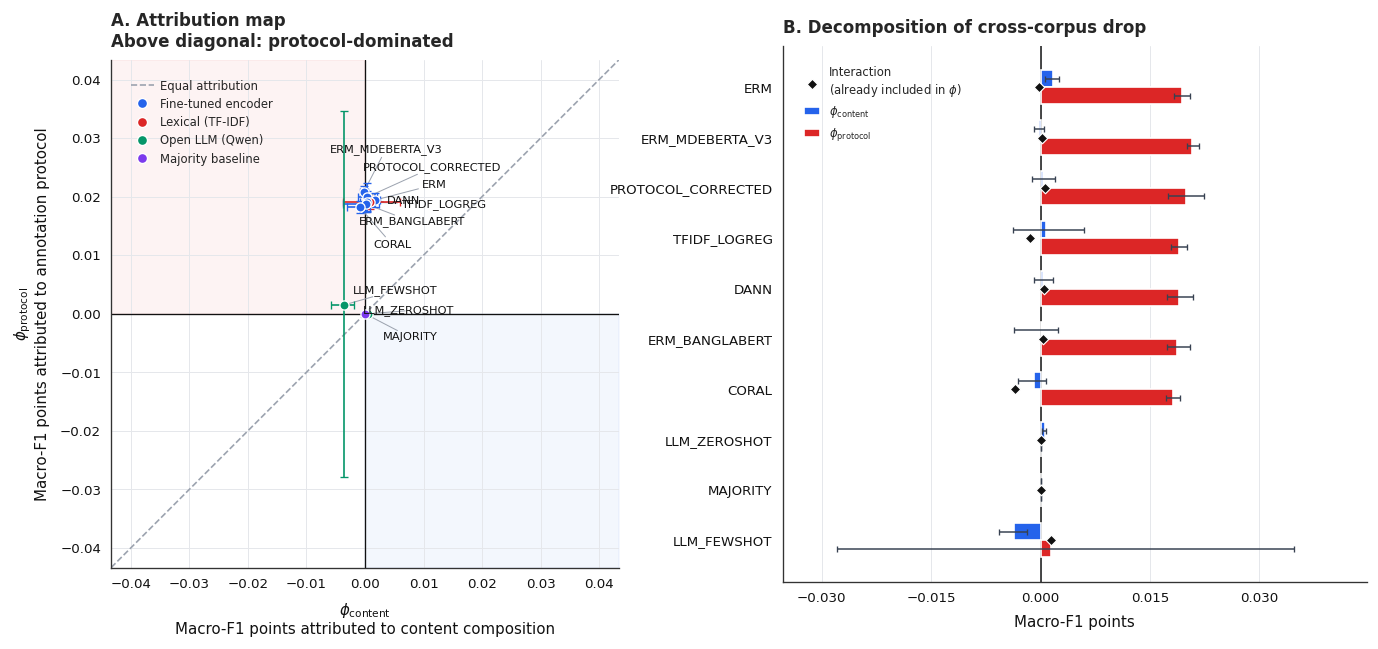

In [ ]:
# ===================== CELL 111: Headline Attribution Figure =====================


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
from pathlib import Path

try:
    from adjustText import adjust_text
    ADJUSTTEXT_AVAILABLE = True
except ImportError:
    ADJUSTTEXT_AVAILABLE = False
    print(
        "Warning: adjustText not installed. "
        "Labels may overlap. Install with: pip install adjustText"
    )

HEADLINE_RC = {
    "font.family": "DejaVu Sans",
    "font.size": 8,
    "axes.titlesize": 10,
    "axes.titleweight": "bold",
    "axes.labelsize": 9,
    "axes.edgecolor": "#333333",
    "axes.linewidth": 0.8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "xtick.color": "#111111",
    "ytick.color": "#111111",
    "legend.frameon": False,
    "legend.fontsize": 7.5,
    "legend.title_fontsize": 8,
}

plt.rcParams.update(HEADLINE_RC)

FAMILY_COLORS = {
    "Classical": "#2563EB",
    "Transformer": "#DC2626",
    "LLM": "#059669",
    "Multimodal": "#7C3AED",
    "Other": "#EA580C",
}

FALLBACK_COLORS = [
    "#2563EB", "#DC2626", "#059669",
    "#7C3AED", "#EA580C", "#0891B2",
    "#65A30D", "#DB2777", "#9333EA", "#0F766E",
]

CONTENT_COLOR = "#2563EB"
PROTOCOL_COLOR = "#DC2626"
INTERACTION_COLOR = "#111111"


def _s(model, q, col):
    return float(SUMM_MF1[(col, q)].loc[model])


def _ci_errors(model, q):
    """Return lower and upper non-negative error distances for asymmetric CI."""
    mean = _s(model, q, "mean")
    lo = _s(model, q, "ci_low")
    hi = _s(model, q, "ci_high")

    lower = max(mean - lo, 0.0)
    upper = max(hi - mean, 0.0)
    return lower, upper



models = sorted(
    SUMM_MF1.index,
    key=lambda m: _s(m, "total_drop", "mean"),
    reverse=True,
)

families = []
for m in models:
    fam = MODEL_FAMILY.get(m, "Other")
    if fam not in families:
        families.append(fam)

palette = {}
for i, fam in enumerate(families):
    palette[fam] = FAMILY_COLORS.get(
        fam,
        FALLBACK_COLORS[i % len(FALLBACK_COLORS)],
    )


fig, axes = plt.subplots(
    1,
    2,
    figsize=(13.5, 5.8),
    gridspec_kw={
        "width_ratios": [1.0, 1.15],
        "wspace": 0.30,
    },
)

a = axes[0]

phi_values = [
    _s(m, q, c)
    for m in models
    for q in ["phi_content", "phi_protocol"]
    for c in ["mean", "ci_low", "ci_high"]
]

lim = max(abs(v) for v in phi_values) * 1.25
lim = max(lim, 1e-6)

a.plot(
    [-lim, lim], [-lim, lim],
    color="#9CA3AF",
    lw=1.0,
    ls="--",
    zorder=1,
    label="Equal attribution",
)

a.axhline(0, color="#111111", lw=0.8, zorder=1)
a.axvline(0, color="#111111", lw=0.8, zorder=1)

a.fill_between(
    [-lim, 0], 0, lim,
    color=PROTOCOL_COLOR,
    alpha=0.05,
    zorder=0,
)
a.fill_between(
    [0, lim], -lim, 0,
    color=CONTENT_COLOR,
    alpha=0.05,
    zorder=0,
)

label_texts = []
label_x = []
label_y = []

for m in models:
    x = _s(m, "phi_content", "mean")
    y = _s(m, "phi_protocol", "mean")

    x_lower, x_upper = _ci_errors(m, "phi_content")
    y_lower, y_upper = _ci_errors(m, "phi_protocol")

    color = palette[MODEL_FAMILY.get(m, "Other")]

    a.errorbar(
        x,
        y,
        xerr=[[x_lower], [x_upper]],
        yerr=[[y_lower], [y_upper]],
        fmt="o",
        ms=5.5,
        mfc=color,
        mec="white",
        mew=0.8,
        ecolor=color,
        elinewidth=1.0,
        capsize=2.5,
        capthick=0.9,
        zorder=4,
    )

    text = a.text(
        x,
        y,
        m,
        fontsize=6.8,
        color="#111111",
        zorder=6,
    )

    label_texts.append(text)
    label_x.append(x)
    label_y.append(y)

a.set_xlim(-lim, lim)
a.set_ylim(-lim, lim)
a.set_aspect("equal", adjustable="box")

a.set_xlabel(
    r"$\phi_{\mathrm{content}}$"
    "\nMacro-F1 points attributed to content composition",
    labelpad=6,
)
a.set_ylabel(
    r"$\phi_{\mathrm{protocol}}$"
    "\nMacro-F1 points attributed to annotation protocol",
    labelpad=6,
)

a.set_title(
    "A. Attribution map\nAbove diagonal: protocol-dominated",
    loc="left",
    pad=8,
)

a.grid(True, color="#E5E7EB", lw=0.6, zorder=0)
a.set_axisbelow(True)
a.tick_params(length=2.5, width=0.7)

for spine in ["top", "right"]:
    a.spines[spine].set_visible(False)

family_handles = [
    Line2D(
        [0], [0],
        marker="o",
        color="none",
        markerfacecolor=palette[fam],
        markeredgecolor="white",
        markeredgewidth=0.8,
        markersize=6,
        label=fam,
    )
    for fam in families
]

equal_handle = Line2D(
    [0], [0],
    color="#9CA3AF",
    lw=1.0,
    ls="--",
    label="Equal attribution",
)

a.legend(
    handles=[equal_handle] + family_handles,
    loc="upper left",
    bbox_to_anchor=(0.02, 0.98),
    fontsize=7,
    labelspacing=0.45,
    handletextpad=0.5,
    borderpad=0.3,
)

if ADJUSTTEXT_AVAILABLE:
    adjust_text(
        label_texts,
        x=label_x,
        y=label_y,
        ax=a,
        arrowprops={
            "arrowstyle": "-",
            "color": "#9CA3AF",
            "lw": 0.6,
        },
        expand=(1.3, 1.4),
        force_text=(0.3, 0.5),
        force_static=(0.3, 0.5),
    )


b = axes[1]

y = np.arange(len(models))
bar_height = 0.34

content_mu = np.array([_s(m, "phi_content", "mean") for m in models])
protocol_mu = np.array([_s(m, "phi_protocol", "mean") for m in models])
interaction_mu = np.array([_s(m, "interaction", "mean") for m in models])

content_err = np.array([
    _ci_errors(m, "phi_content") for m in models
]).T

protocol_err = np.array([
    _ci_errors(m, "phi_protocol") for m in models
]).T

b.barh(
    y - bar_height / 2,
    content_mu,
    height=bar_height,
    color=CONTENT_COLOR,
    label=r"$\phi_{\mathrm{content}}$",
    xerr=content_err,
    error_kw={
        "ecolor": "#374151",
        "elinewidth": 0.9,
        "capsize": 2.0,
        "capthick": 0.8,
    },
    zorder=3,
)

b.barh(
    y + bar_height / 2,
    protocol_mu,
    height=bar_height,
    color=PROTOCOL_COLOR,
    label=r"$\phi_{\mathrm{protocol}}$",
    xerr=protocol_err,
    error_kw={
        "ecolor": "#374151",
        "elinewidth": 0.9,
        "capsize": 2.0,
        "capthick": 0.8,
    },
    zorder=3,
)

b.scatter(
    interaction_mu,
    y,
    marker="D",
    s=20,
    facecolor=INTERACTION_COLOR,
    edgecolor="white",
    linewidth=0.7,
    label="Interaction\n(already included in $\\phi$)",
    zorder=5,
)

b.axvline(0, color="#111111", lw=0.9, zorder=2)

b.set_yticks(y)
b.set_yticklabels(models, fontsize=8)
b.invert_yaxis()

b.set_xlabel("Macro-F1 points", labelpad=6)
b.set_title(
    "B. Decomposition of cross-corpus drop",
    loc="left",
    pad=8,
)

b.xaxis.set_major_locator(MaxNLocator(nbins=6, prune="lower"))
b.grid(True, axis="x", color="#E5E7EB", lw=0.6, zorder=0)
b.set_axisbelow(True)
b.tick_params(axis="both", length=2.5, width=0.7)

for spine in ["top", "right"]:
    b.spines[spine].set_visible(False)

all_x = np.concatenate([
    content_mu, protocol_mu, interaction_mu,
    content_mu + content_err[1],
    content_mu - content_err[0],
    protocol_mu + protocol_err[1],
    protocol_mu - protocol_err[0],
])

xmin, xmax = np.nanmin(all_x), np.nanmax(all_x)
span = max(abs(xmax - xmin), 1e-6)
b.set_xlim(xmin - 0.12 * span, xmax + 0.16 * span)

b.legend(
    loc="upper left",
    bbox_to_anchor=(0.02, 0.98),
    fontsize=7,
    labelspacing=0.5,
    handlelength=1.4,
    borderpad=0.3,
)


FIG_DIR = Path(FIG_DIR)
FIG_DIR.mkdir(parents=True, exist_ok=True)

fig.tight_layout(pad=0.8)

fig.savefig(
    FIG_DIR / "fig_attribution_map.pdf",
    bbox_inches="tight",
)
fig.savefig(
    FIG_DIR / "fig_attribution_map.png",
    dpi=600,
    bbox_inches="tight",
)

plt.show()

In [ ]:
# ===================== CELL 112 =====================


def exact_signflip_p(d, max_exact=16, n_mc=200000, seed=0):
    d = np.asarray(d, float); d = d[np.isfinite(d)]; n = len(d)
    if n == 0: return np.nan
    obs = abs(d.mean())
    if n <= max_exact:
        signs = np.array(list(itertools.product([-1.0, 1.0], repeat=n)))
        return float((np.abs((signs * d).mean(1)) >= obs - 1e-12).mean())
    rng = np.random.default_rng(seed)
    signs = rng.choice([-1.0, 1.0], size=(n_mc, n))
    return float((1 + (np.abs((signs * d).mean(1)) >= obs - 1e-12).sum()) / (1 + n_mc))

def holm(p):
    p = np.asarray(p, float); out = np.full_like(p, np.nan); ok = np.isfinite(p)
    idx = np.argsort(p[ok]); m = ok.sum(); run = 0.0; tmp = np.empty(m)
    for rank, i in enumerate(idx):
        run = max(run, (m - rank) * p[ok][i]); tmp[rank] = min(1.0, run)
    res = np.empty(m); res[idx] = tmp; out[ok] = res
    return out

_rows = []
for model, g in ATTR_MF1.groupby("model"):
    d = (g["phi_protocol"] - g["phi_content"]).to_numpy()
    mean, lo, hi = bootstrap_ci(d)
    n = len(d)
    _rows.append({"model": model, "n_seeds": n, "mean_protocol_minus_content": mean, "ci_low": lo, "ci_high": hi,
                "seeds_protocol_gt_content": int((d > 0).sum()),
                "cohen_dz": float(d.mean() / d.std(ddof=1)) if n > 1 and d.std(ddof=1) > 0 else np.nan,
                "p_diff": exact_signflip_p(d),
                "p_phi_protocol_ne_0": exact_signflip_p(g["phi_protocol"]),
                "p_phi_content_ne_0": exact_signflip_p(g["phi_content"]),
                "min_attainable_p": 2.0 / 2 ** n if n <= 16 else 0.0})
TESTS = pd.DataFrame(_rows)
for c in ["p_diff", "p_phi_protocol_ne_0", "p_phi_content_ne_0"]:
    TESTS[c + "_holm"] = holm(TESTS[c].to_numpy())
TESTS.to_csv(TAB_DIR / "shapley_tests_holm.csv", index=False)
display(TESTS.round(4))
print("\nRead-out: if min_attainable_p > 0.05 for a model, report its CI and 'k of n seeds' instead of claiming significance.")

,model,n_seeds,mean_protocol_minus_content,ci_low,ci_high,seeds_protocol_gt_content,cohen_dz,p_diff,p_phi_protocol_ne_0,p_phi_content_ne_0,min_attainable_p,p_diff_holm,p_phi_protocol_ne_0_holm,p_phi_content_ne_0_holm
0,CORAL,5,0.0190,0.0174,0.0217,5,6.4762,0.0625,0.0625,0.6250,0.0625,0.625,0.625,1.000
1,DANN,5,0.0187,0.0173,0.0207,5,8.0476,0.0625,0.0625,0.7500,0.0625,0.625,0.625,1.000
2,ERM,5,0.0177,0.0164,0.0191,5,10.2334,0.0625,0.0625,0.1250,0.0625,0.625,0.625,1.000
3,ERM_BANGLABERT,5,0.0186,0.0157,0.0226,5,4.1698,0.0625,0.0625,1.0000,0.0625,0.625,0.625,1.000
4,ERM_MDEBERTA_V3,5,0.0210,0.0198,0.0222,5,12.9091,0.0625,0.0625,0.5000,0.0625,0.625,0.625,1.000
5,LLM_FEWSHOT,5,0.0051,-0.0226,0.0368,2,0.1284,0.8750,1.0000,0.0625,0.0625,1.000,1.000,0.625
6,LLM_ZEROSHOT,5,-0.0006,-0.0008,-0.0003,1,-1.6347,0.1250,1.0000,0.1250,0.0625,0.625,1.000,1.000
7,MAJORITY,5,0.0000,0.0000,0.0000,0,NaN,1.0000,1.0000,1.0000,0.0625,1.000,1.000,1.000
8,PROTOCOL_CORRECTED,5,0.0195,0.0168,0.0224,5,5.4810,0.0625,0.0625,0.6875,0.0625,0.625,0.625,1.000
9,TFIDF_LOGREG,5,0.0182,0.0118,0.0238,5,2.4098,0.0625,0.0625,0.8125,0.0625,0.625,0.625,1.000



Read-out: if min_attainable_p > 0.05 for a model, report its CI and 'k of n seeds' instead of claiming significance.


,macro_f1,f1_pos,balanced_accuracy,auroc,auprc,ece,share_of_metrics_agreeing_with_macro_f1
model,,,,,,,
CORAL,protocol,protocol,protocol,protocol,protocol,protocol,1.000000
DANN,protocol,protocol,protocol,protocol,protocol,protocol,1.000000
ERM,protocol,protocol,protocol,protocol,protocol,protocol,1.000000
ERM_BANGLABERT,protocol,protocol,protocol,protocol,protocol,protocol,1.000000
ERM_MDEBERTA_V3,protocol,protocol,protocol,protocol,protocol,protocol,1.000000
LLM_FEWSHOT,protocol,content,protocol,content,content,protocol,0.500000
LLM_ZEROSHOT,content,content,content,content,content,content,1.000000
MAJORITY,content,content,content,content,content,protocol,0.833333
PROTOCOL_CORRECTED,protocol,protocol,protocol,protocol,protocol,protocol,1.000000



Models whose dominant factor is identical under ALL 6 metrics: 8 / 10

Kendall tau between model orderings by phi_protocol, per metric pair:


,macro_f1,f1_pos,balanced_accuracy,auroc,auprc,ece
macro_f1,1.00,0.77,0.86,0.73,0.55,0.04
f1_pos,0.77,1.00,0.82,0.68,0.68,0.27
balanced_accuracy,0.86,0.82,1.00,0.86,0.59,0.09
auroc,0.73,0.68,0.86,1.00,0.64,0.13
auprc,0.55,0.68,0.59,0.64,1.00,0.40
ece,0.04,0.27,0.09,0.13,0.40,1.00


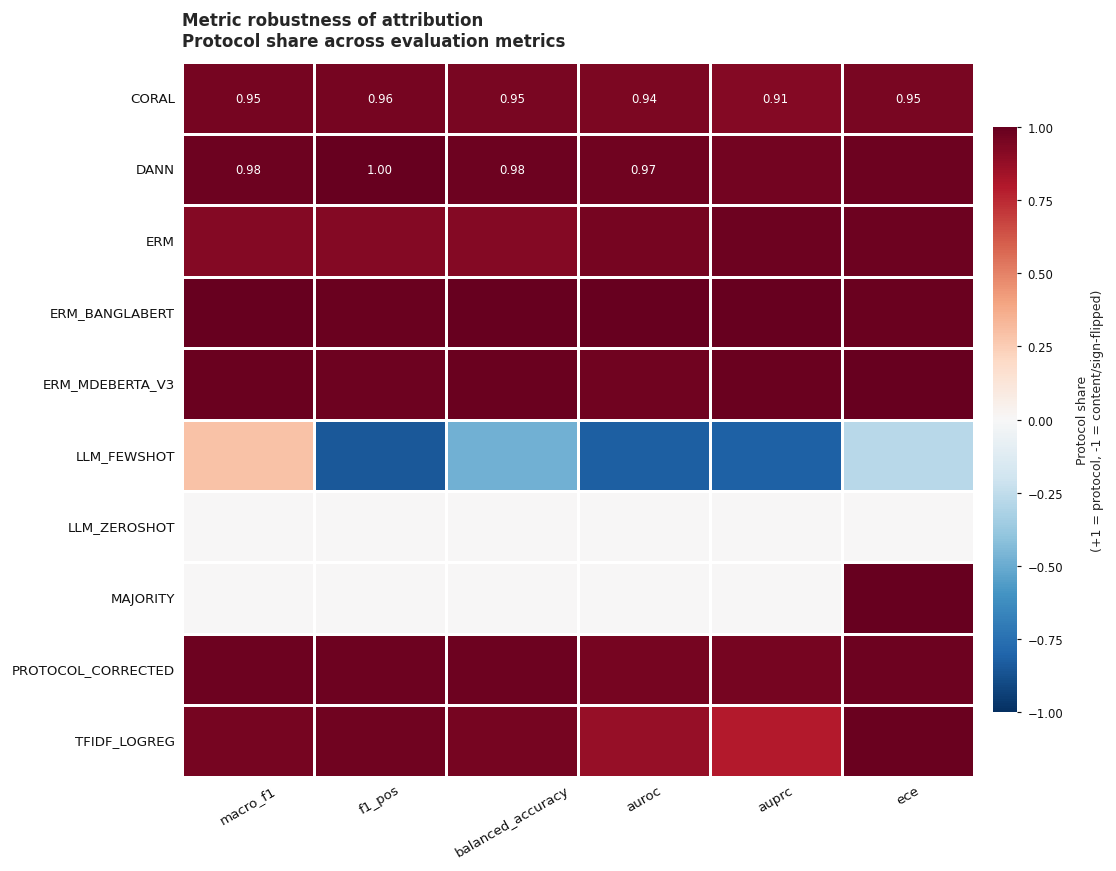


Saved:
- E:\Research\Attributing Cross-Corpus Failure\results\tables\metric_robustness_protocol_share.csv
- E:\Research\Attributing Cross-Corpus Failure\results\tables\metric_robustness_dominant_factor.csv
- E:\Research\Attributing Cross-Corpus Failure\results\tables\metric_robustness_agreement.csv
- E:\Research\Attributing Cross-Corpus Failure\results\tables\metric_robustness_kendall_tau.csv
- E:\Research\Attributing Cross-Corpus Failure\results\figures\fig_metric_robustness.pdf
- E:\Research\Attributing Cross-Corpus Failure\results\figures\fig_metric_robustness.png


In [ ]:
# ===================== CELL 113: Metric Robustness =====================
# Is the dominant-factor conclusion metric-dependent?

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kendalltau
from pathlib import Path


METRIC_RC = {
    "font.family": "DejaVu Sans",
    "font.size": 8,
    "axes.titlesize": 10,
    "axes.titleweight": "bold",
    "axes.labelsize": 9,
    "axes.edgecolor": "#333333",
    "axes.linewidth": 0.8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "xtick.color": "#111111",
    "ytick.color": "#111111",
    "legend.frameon": False,
    "legend.fontsize": 7.5,
}

sns.set_theme(style="white", rc=METRIC_RC)

FIG_DIR = Path(FIG_DIR)
TAB_DIR = Path(TAB_DIR)
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)


_m = (
    SUMM_ALL[
        SUMM_ALL["quantity"].isin(["phi_content", "phi_protocol"])
    ]
    .pivot_table(
        index=["model", "metric"],
        columns="quantity",
        values="mean",
    )
    .reset_index()
)

# Protocol share:
# +1 => attribution entirely protocol
#  0 => equal absolute attribution
# -1 => attribution entirely content with opposite sign
_m["protocol_share"] = _m["phi_protocol"] / (
    _m["phi_protocol"].abs()
    + _m["phi_content"].abs()
    + 1e-12
)

_m["dominant"] = np.where(
    _m["phi_protocol"] > _m["phi_content"],
    "protocol",
    "content",
)

available_metrics = list(_m["metric"].unique())
METRICS_PRESENT = [
    m for m in METRICS_PRESENT if m in available_metrics
]

if not METRICS_PRESENT:
    raise ValueError("No requested metrics are present in SUMM_ALL.")


share = _m.pivot(
    index="model",
    columns="metric",
    values="protocol_share",
)[METRICS_PRESENT]

dom = _m.pivot(
    index="model",
    columns="metric",
    values="dominant",
)[METRICS_PRESENT]

agree = (
    dom.eq(dom["macro_f1"], axis=0)
    .mean(axis=1)
    .rename("share_of_metrics_agreeing_with_macro_f1")
)

dominance_table = pd.concat([dom, agree], axis=1)

display(dominance_table)

n_full_agreement = int((agree == 1).sum())
print(
    f"\nModels whose dominant factor is identical under ALL "
    f"{len(METRICS_PRESENT)} metrics: "
    f"{n_full_agreement} / {len(agree)}"
)


rank_tbl = _m.pivot(
    index="model",
    columns="metric",
    values="phi_protocol",
)[METRICS_PRESENT]

tau = pd.DataFrame(
    index=METRICS_PRESENT,
    columns=METRICS_PRESENT,
    dtype=float,
)

for metric_a in METRICS_PRESENT:
    for metric_b in METRICS_PRESENT:
        result = kendalltau(
            rank_tbl[metric_a],
            rank_tbl[metric_b],
            nan_policy="omit",
        )
        tau.loc[metric_a, metric_b] = result.statistic

print(
    "\nKendall tau between model orderings by phi_protocol, "
    "per metric pair:"
)
display(tau.round(2))

tau.round(4).to_csv(
    TAB_DIR / "metric_robustness_kendall_tau.csv"
)


def plot_metric_robustness_heatmap(
    share,
    fig_dir=FIG_DIR,
    filename="fig_metric_robustness",
    vmin=-1.0,
    vmax=1.0,
    cmap="RdBu_r",
    annotate=True,
    fmt=".2f",
):
    fig_width = max(1.05 * len(share.columns) + 3.2, 6.0)
    fig_height = max(0.48 * len(share.index) + 2.4, 3.6)

    fig, ax = plt.subplots(figsize=(fig_width, fig_height))

    sns.heatmap(
        share,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        center=0.0,
        annot=annotate,
        fmt=fmt,
        linewidths=0.8,
        linecolor="white",
        square=False,
        cbar_kws={
            "label": (
                "Protocol share of "
                r"$|\phi_{\mathrm{content}}| + |\phi_{\mathrm{protocol}}|$"
                "\n(+1 = protocol-dominated, -1 = content-dominated)"
            ),
            "shrink": 0.82,
            "pad": 0.02,
            "aspect": 24,
        },
        annot_kws={
            "fontsize": 7.0,
            "fontweight": "medium",
        },
        ax=ax,
    )

    if annotate:
        norm = plt.Normalize(vmin=vmin, vmax=vmax)
        values = share.to_numpy()

        for text, value in zip(ax.texts, values.ravel()):
            if not np.isfinite(value):
                text.set_text("")
                continue

            text.set_color("white" if abs(norm(value) - 0.5) > 0.32 else "#111111")

    ax.set_xlabel("")
    ax.set_ylabel("")

    ax.set_title(
        "Metric robustness of attribution\n"
        "Protocol share across evaluation metrics",
        loc="left",
        pad=10,
    )

    ax.tick_params(
        axis="x",
        rotation=30,
        length=0,
        pad=4,
    )
    ax.tick_params(
        axis="y",
        rotation=0,
        length=0,
        pad=4,
    )

    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(labelsize=7, length=2.5, width=0.7)
    cbar.outline.set_visible(False)
    cbar.set_label(
        "Protocol share\n"
        r"(+1 = protocol, -1 = content/sign-flipped)",
        fontsize=7.5,
        labelpad=8,
    )

    fig.tight_layout(pad=0.6)

    fig.savefig(
        fig_dir / f"{filename}.pdf",
        bbox_inches="tight",
    )
    fig.savefig(
        fig_dir / f"{filename}.png",
        dpi=600,
        bbox_inches="tight",
    )

    plt.show()


plot_metric_robustness_heatmap(
    share=share,
    fig_dir=FIG_DIR,
    filename="fig_metric_robustness",
    vmin=-1.0,
    vmax=1.0,
    cmap="RdBu_r",
    annotate=True,
    fmt=".2f",
)

share.round(6).to_csv(
    TAB_DIR / "metric_robustness_protocol_share.csv"
)

dom.round(6).to_csv(
    TAB_DIR / "metric_robustness_dominant_factor.csv"
)

agree.round(6).to_csv(
    TAB_DIR / "metric_robustness_agreement.csv"
)

print("\nSaved:")
print(f"- {TAB_DIR / 'metric_robustness_protocol_share.csv'}")
print(f"- {TAB_DIR / 'metric_robustness_dominant_factor.csv'}")
print(f"- {TAB_DIR / 'metric_robustness_agreement.csv'}")
print(f"- {TAB_DIR / 'metric_robustness_kendall_tau.csv'}")
print(f"- {FIG_DIR / 'fig_metric_robustness.pdf'}")
print(f"- {FIG_DIR / 'fig_metric_robustness.png'}")

In [ ]:
# ===================== CELL 114 =====================

_zs = [m for m in ATTR_MF1["model"].unique() if str(m).upper().endswith("ZEROSHOT")]
_rows = []
for m in _zs:
    g = ATTR_MF1[ATTR_MF1["model"] == m]
    _rows.append({"model": m, "n_seeds": len(g), "max_abs_phi_protocol": float(g["phi_protocol"].abs().max()),
                  "mean_phi_content": float(g["phi_content"].mean()),
                  "negative_control_passed": bool(g["phi_protocol"].abs().max() < 1e-9)})
NEG_CONTROL = pd.DataFrame(_rows)
if len(NEG_CONTROL):
    display(NEG_CONTROL)
    NEG_CONTROL.to_csv(TAB_DIR / "negative_control_zeroshot.csv", index=False)
    print("All zero-shot arms pass the null control." if NEG_CONTROL["negative_control_passed"].all()
          else "WARNING: a zero-shot arm shows non-zero phi_protocol -> investigate leakage / non-determinism "
               "(Gemini temperature=0 is near- but not perfectly deterministic; tiny non-zeros may be API noise).")
else:
    print("No *_ZEROSHOT arm in the results yet.")

_fs = [m for m in ATTR_MF1["model"].unique() if str(m).upper().endswith("FEWSHOT")]
if _fs:
    display(ATTR_MF1[ATTR_MF1["model"].isin(_fs)].groupby("model")[["phi_content", "phi_protocol"]].agg(["mean", "std"]).round(4))

_rob = globals().get("ROBUSTNESS_RESULTS")
if _rob is not None:
    print("\nROBUSTNESS_RESULTS columns (use these for a dose-response plot):", list(_rob.columns))

,model,n_seeds,max_abs_phi_protocol,mean_phi_content,negative_control_passed
0,LLM_ZEROSHOT,5,0.0,0.000584,True


All zero-shot arms pass the null control.


phi_content         phi_protocol        
                   mean     std         mean     std
model                                               
LLM_FEWSHOT     -0.0036  0.0026       0.0015  0.0419


ROBUSTNESS_RESULTS columns (use these for a dose-response plot): ['content_strength', 'protocol_noise_scale', 'model', 'seed', 'phi_content', 'phi_protocol']


,remedy,targeted_factor,quantity,delta_vs_ERM,ci_low,ci_high,n_seeds,p_exact,is_target
0,DANN,phi_content,phi_content,-0.0014,-0.0022,-0.0006,5,0.0625,True
1,DANN,phi_content,phi_protocol,-0.0004,-0.0018,0.0010,5,0.6875,False
2,DANN,phi_content,total_drop,-0.0017,-0.0035,0.0001,5,0.1875,False
3,CORAL,phi_content,phi_content,-0.0025,-0.0038,-0.0016,5,0.0625,True
4,CORAL,phi_content,phi_protocol,-0.0012,-0.0030,0.0003,5,0.2500,False
5,CORAL,phi_content,total_drop,-0.0038,-0.0054,-0.0027,5,0.0625,False
6,PROTOCOL_CORRECTED,phi_protocol,phi_content,-0.0013,-0.0023,-0.0002,5,0.2500,False
7,PROTOCOL_CORRECTED,phi_protocol,phi_protocol,0.0005,-0.0019,0.0028,5,0.6875,True
8,PROTOCOL_CORRECTED,phi_protocol,total_drop,-0.0007,-0.0028,0.0013,5,0.5000,False


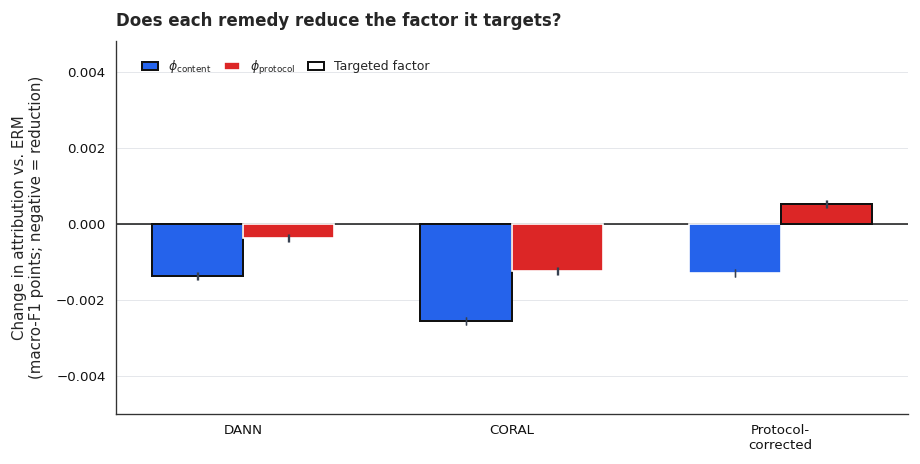

In [ ]:
# ===================== CELL 115: Remedy Targeting Diagnostic =====================
# Does each remedy reduce the attribution factor it targets?

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator
from pathlib import Path


BASE = "ERM"

REMEDIES = {
    "DANN": "phi_content",
    "CORAL": "phi_content",
    "PROTOCOL_CORRECTED": "phi_protocol",
}

QUANTITIES = ["phi_content", "phi_protocol"]

QUANTITY_LABELS = {
    "phi_content": r"$\phi_{\mathrm{content}}$",
    "phi_protocol": r"$\phi_{\mathrm{protocol}}$",
}

REMEDY_LABELS = {
    "DANN": "DANN",
    "CORAL": "CORAL",
    "PROTOCOL_CORRECTED": "Protocol-\ncorrected",
}

CONTENT_COLOR = "#2563EB"
PROTOCOL_COLOR = "#DC2626"
TARGET_EDGE_COLOR = "#111111"

PLOT_RC = {
    "font.family": "DejaVu Sans",
    "font.size": 8,
    "axes.titlesize": 10,
    "axes.titleweight": "bold",
    "axes.labelsize": 9,
    "axes.edgecolor": "#333333",
    "axes.linewidth": 0.8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "xtick.color": "#111111",
    "ytick.color": "#111111",
    "legend.frameon": False,
    "legend.fontsize": 7.5,
    "legend.title_fontsize": 8,
}

plt.rcParams.update(PLOT_RC)

FIG_DIR = Path(FIG_DIR)
FIG_DIR.mkdir(parents=True, exist_ok=True)



def ci_distances(mean, lo, hi):
    lower = max(float(mean) - float(lo), 0.0)
    upper = max(float(hi) - float(mean), 0.0)
    return lower, upper


_wide = ATTR_MF1.pivot(
    index="seed",
    columns="model",
    values=["phi_content", "phi_protocol", "total_drop"],
)

_rows = []

if BASE in ATTR_MF1["model"].values:
    for remedy, target in REMEDIES.items():
        if remedy not in ATTR_MF1["model"].values:
            continue

        for quantity in ["phi_content", "phi_protocol", "total_drop"]:
            delta = (
                _wide[quantity][remedy]
                - _wide[quantity][BASE]
            ).dropna().to_numpy()

            if len(delta) == 0:
                continue

            mean, lo, hi = bootstrap_ci(delta)

            _rows.append({
                "remedy": remedy,
                "targeted_factor": target,
                "quantity": quantity,
                "delta_vs_ERM": mean,
                "ci_low": lo,
                "ci_high": hi,
                "n_seeds": len(delta),
                "p_exact": exact_signflip_p(delta),
                "is_target": quantity == target,
            })

REMEDY_DF = pd.DataFrame(_rows)


if len(REMEDY_DF):
    display(REMEDY_DF.round(4))
    REMEDY_DF.to_csv(TAB_DIR / "remedy_targeting.csv", index=False)

    sub = REMEDY_DF[
        REMEDY_DF["quantity"].isin(QUANTITIES)
    ].copy()

    remedies_present = [
        r for r in REMEDIES.keys()
        if r in sub["remedy"].unique()
    ]

    if not remedies_present:
        print("No remedy arms available for the targeting figure.")
    else:
        x = np.arange(len(remedies_present))
        bar_width = 0.34

        fig, ax = plt.subplots(figsize=(7.6, 3.8))

        offsets = {
            "phi_content": -bar_width / 2,
            "phi_protocol": +bar_width / 2,
        }

        colors = {
            "phi_content": CONTENT_COLOR,
            "phi_protocol": PROTOCOL_COLOR,
        }

        for quantity in QUANTITIES:
            q_sub = (
                sub[sub["quantity"] == quantity]
                .set_index("remedy")
                .reindex(remedies_present)
            )

            means = q_sub["delta_vs_ERM"].to_numpy(dtype=float)
            lows = q_sub["ci_low"].to_numpy(dtype=float)
            highs = q_sub["ci_high"].to_numpy(dtype=float)

            lower_err = np.array([
                ci_distances(m, lo, hi)[0]
                for m, lo, hi in zip(means, lows, highs)
            ])

            upper_err = np.array([
                ci_distances(m, lo, hi)[1]
                for m, lo, hi in zip(means, lows, highs)
            ])

            bars = ax.bar(
                x + offsets[quantity],
                means,
                width=bar_width,
                color=colors[quantity],
                label=QUANTITY_LABELS[quantity],
                xerr=[lower_err, upper_err],
                error_kw={
                    "ecolor": "#374151",
                    "elinewidth": 0.9,
                    "capsize": 2.5,
                    "capthick": 0.8,
                },
                zorder=3,
            )

            for xi, remedy in zip(x, remedies_present):
                if REMEDIES.get(remedy) == quantity:
                    bars[
                        remedies_present.index(remedy)
                    ].set_edgecolor(TARGET_EDGE_COLOR)
                    bars[
                        remedies_present.index(remedy)
                    ].set_linewidth(1.2)

        ax.axhline(0, color="#111111", lw=0.9, zorder=2)

        ax.set_xticks(x)
        ax.set_xticklabels(
            [REMEDY_LABELS.get(r, r) for r in remedies_present],
            fontsize=8,
        )

        ax.set_ylabel(
            "Change in attribution vs. ERM\n"
            "(macro-F1 points; negative = reduction)",
            labelpad=7,
        )

        ax.set_title(
            "Does each remedy reduce the factor it targets?",
            loc="left",
            pad=9,
        )

        all_values = np.concatenate([
            sub["delta_vs_ERM"].to_numpy(dtype=float),
            sub["ci_low"].to_numpy(dtype=float),
            sub["ci_high"].to_numpy(dtype=float),
        ])

        ymin = np.nanmin(all_values)
        ymax = np.nanmax(all_values)
        span = max(abs(ymax - ymin), 1e-6)

        ax.set_ylim(
            ymin - 0.18 * span,
            ymax + 0.30 * span,
        )

        ax.yaxis.set_major_locator(MaxNLocator(nbins=6, prune="lower"))
        ax.grid(True, axis="y", color="#E5E7EB", lw=0.6, zorder=0)
        ax.set_axisbelow(True)
        ax.tick_params(axis="both", length=2.5, width=0.7)

        for spine in ["top", "right"]:
            ax.spines[spine].set_visible(False)

        handles, labels_ = ax.get_legend_handles_labels()
        handles.append(
            Patch(
                facecolor="white",
                edgecolor=TARGET_EDGE_COLOR,
                linewidth=1.2,
                label="Targeted factor",
            )
        )

        ax.legend(
            handles=handles,
            loc="upper left",
            bbox_to_anchor=(0.02, 0.98),
            ncol=3,
            columnspacing=1.0,
            handlelength=1.3,
            labelspacing=0.45,
            borderpad=0.3,
        )

        fig.tight_layout(pad=0.6)

        fig.savefig(
            FIG_DIR / "fig_remedy_targeting.pdf",
            bbox_inches="tight",
        )
        fig.savefig(
            FIG_DIR / "fig_remedy_targeting.png",
            dpi=600,
            bbox_inches="tight",
        )

        plt.show()

else:
    print("ERM and at least one remedy arm are required.")

Models: 9 | seeds common to all: [13, 42, 2024, 3407, 9001]
Kendall tau (ranking at (0,0), ranking at (1,1)) per seed = [0.889 0.889 0.722 0.611 0.667]
Mean tau = 0.756  95% CI [0.656, 0.856]  (1 = identical ranking)


,macro_f1_clean,rank_clean,macro_f1_shifted,rank_shifted,rank_change
model,,,,,
ERM_BANGLABERT,0.934,1.0,0.915,2.0,-1.0
ERM,0.933,2.0,0.912,3.0,-1.0
ERM_MDEBERTA_V3,0.933,3.0,0.912,4.0,-1.0
CORAL,0.933,4.0,0.915,1.0,3.0
DANN,0.931,5.0,0.912,5.0,0.0
PROTOCOL_CORRECTED,0.931,6.0,0.910,6.0,0.0
TFIDF_LOGREG,0.771,7.0,0.752,7.0,0.0
LLM_FEWSHOT,0.624,8.0,0.626,8.0,0.0
LLM_ZEROSHOT,0.341,9.0,0.341,9.0,0.0


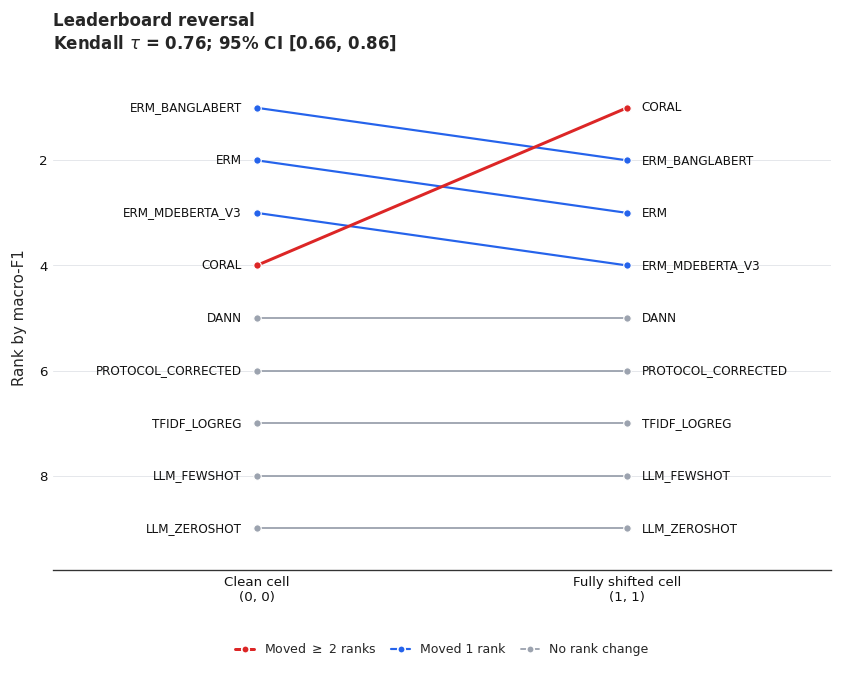

In [ ]:
# ===================== CELL 116: Leaderboard Reversal =====================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pathlib import Path


RANK_RC = {
    "font.family": "DejaVu Sans",
    "font.size": 8,
    "axes.titlesize": 10,
    "axes.titleweight": "bold",
    "axes.labelsize": 9,
    "axes.edgecolor": "#333333",
    "axes.linewidth": 0.8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "xtick.color": "#111111",
    "ytick.color": "#111111",
    "legend.frameon": False,
    "legend.fontsize": 7.5,
}

plt.rcParams.update(RANK_RC)

FIG_DIR = Path(FIG_DIR)
FIG_DIR.mkdir(parents=True, exist_ok=True)

NEUTRAL_COLOR = "#9CA3AF"
BIG_MOVE_COLOR = "#DC2626"
SMALL_MOVE_COLOR = "#2563EB"


def declutter_positions(values, min_gap=0.8):
    """
    Adjust sorted rank positions so adjacent labels remain separated.
    Values should already be rank positions (1 = best).
    Returns adjusted positions in the same order as input values.
    """
    order = np.argsort(values)
    adjusted = np.array(values, dtype=float, copy=True)

    for i in range(1, len(order)):
        curr = order[i]
        prev = order[i - 1]

        if adjusted[curr] - adjusted[prev] < min_gap:
            adjusted[curr] = adjusted[prev] + min_gap

    return adjusted



_cand = [
    m for m in ALL_RESULTS["model"].unique()
    if m != "MAJORITY"
]

_seed_sets = [
    set(ALL_RESULTS.loc[ALL_RESULTS["model"] == m, "seed"])
    for m in _cand
]

_seeds = sorted(set.intersection(*_seed_sets))

print(f"Models: {len(_cand)} | seeds common to all: {_seeds}")

_piv = ALL_RESULTS[
    ALL_RESULTS["model"].isin(_cand)
    & ALL_RESULTS["seed"].isin(_seeds)
].pivot_table(
    index=["seed", "model"],
    columns=["content_on", "protocol_on"],
    values="macro_f1",
)


taus = []

for seed in _seeds:
    sub = _piv.loc[seed]
    tau = kendalltau(
        sub[(0, 0)],
        sub[(1, 1)],
    ).statistic

    taus.append(tau)

taus = np.asarray(taus, dtype=float)
tau_mean, tau_lo, tau_hi = bootstrap_ci(taus)

print(
    f"Kendall tau (ranking at (0,0), ranking at (1,1)) per seed = "
    f"{np.round(taus, 3)}"
)
print(
    f"Mean tau = {tau_mean:.3f}  "
    f"95% CI [{tau_lo:.3f}, {tau_hi:.3f}]  "
    f"(1 = identical ranking)"
)


_mean = _piv.groupby("model").mean()
_rank = _mean.rank(ascending=False)

RANK_TBL = pd.DataFrame({
    "macro_f1_clean": _mean[(0, 0)],
    "rank_clean": _rank[(0, 0)],
    "macro_f1_shifted": _mean[(1, 1)],
    "rank_shifted": _rank[(1, 1)],
})

RANK_TBL["rank_change"] = (
    RANK_TBL["rank_clean"] - RANK_TBL["rank_shifted"]
)

RANK_TBL = RANK_TBL.sort_values("rank_clean")

display(RANK_TBL.round(3))
RANK_TBL.to_csv(TAB_DIR / "leaderboard_reversal.csv")


fig, ax = plt.subplots(figsize=(7.0, 5.6))

x_clean, x_shifted = 0.0, 1.0

clean_ranks = RANK_TBL["rank_clean"].to_numpy(dtype=float)
shifted_ranks = RANK_TBL["rank_shifted"].to_numpy(dtype=float)

clean_label_y = declutter_positions(clean_ranks, min_gap=0.85)
shifted_label_y = declutter_positions(shifted_ranks, min_gap=0.85)

for model, row in RANK_TBL.iterrows():
    r_clean = float(row["rank_clean"])
    r_shifted = float(row["rank_shifted"])
    change = abs(float(row["rank_change"]))

    if change >= 2:
        color = BIG_MOVE_COLOR
        linewidth = 1.8
        zorder = 4
    elif change == 1:
        color = SMALL_MOVE_COLOR
        linewidth = 1.3
        zorder = 3
    else:
        color = NEUTRAL_COLOR
        linewidth = 1.1
        zorder = 2

    ax.plot(
        [x_clean, x_shifted],
        [r_clean, r_shifted],
        color=color,
        lw=linewidth,
        marker="o",
        markersize=4.5,
        markerfacecolor=color,
        markeredgecolor="white",
        markeredgewidth=0.7,
        zorder=zorder,
    )

for model, row, label_y in zip(
    RANK_TBL.index,
    RANK_TBL.itertuples(),
    clean_label_y,
):
    ax.text(
        x_clean - 0.04,
        label_y,
        model,
        ha="right",
        va="center",
        fontsize=7.2,
        color="#111111",
    )

    if abs(label_y - row.rank_clean) > 1e-6:
        ax.plot(
            [x_clean - 0.015, x_clean],
            [label_y, row.rank_clean],
            color="#D1D5DB",
            lw=0.6,
            zorder=1,
        )

for model, row, label_y in zip(
    RANK_TBL.index,
    RANK_TBL.itertuples(),
    shifted_label_y,
):
    ax.text(
        x_shifted + 0.04,
        label_y,
        model,
        ha="left",
        va="center",
        fontsize=7.2,
        color="#111111",
    )

    if abs(label_y - row.rank_shifted) > 1e-6:
        ax.plot(
            [x_shifted, x_shifted + 0.015],
            [row.rank_shifted, label_y],
            color="#D1D5DB",
            lw=0.6,
            zorder=1,
        )

ax.set_xlim(-0.55, 1.55)
ax.set_ylim(
    min(clean_ranks.min(), shifted_ranks.min()) - 0.8,
    max(clean_ranks.max(), shifted_ranks.max()) + 0.8,
)

ax.invert_yaxis()

ax.set_xticks([x_clean, x_shifted])
ax.set_xticklabels(
    ["Clean cell\n(0, 0)", "Fully shifted cell\n(1, 1)"],
    fontsize=8,
)

ax.set_ylabel("Rank by macro-F1", labelpad=7)

ax.set_title(
    f"Leaderboard reversal\n"
    f"Kendall $\\tau$ = {tau_mean:.2f}; "
    f"95% CI [{tau_lo:.2f}, {tau_hi:.2f}]",
    loc="left",
    pad=10,
)

ax.grid(True, axis="y", color="#E5E7EB", lw=0.6, zorder=0)
ax.set_axisbelow(True)
ax.tick_params(axis="both", length=0)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

legend_handles = [
    Line2D(
        [0], [0],
        color=BIG_MOVE_COLOR, lw=1.8,
        marker="o", markersize=4.5,
        markerfacecolor=BIG_MOVE_COLOR,
        markeredgecolor="white",
        label="Moved $\\geq$ 2 ranks",
    ),
    Line2D(
        [0], [0],
        color=SMALL_MOVE_COLOR, lw=1.3,
        marker="o", markersize=4.5,
        markerfacecolor=SMALL_MOVE_COLOR,
        markeredgecolor="white",
        label="Moved 1 rank",
    ),
    Line2D(
        [0], [0],
        color=NEUTRAL_COLOR, lw=1.1,
        marker="o", markersize=4.5,
        markerfacecolor=NEUTRAL_COLOR,
        markeredgecolor="white",
        label="No rank change",
    ),
]

ax.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=3,
    columnspacing=1.2,
    handlelength=1.5,
    labelspacing=0.45,
)

fig.tight_layout(pad=0.8)

fig.savefig(
    FIG_DIR / "fig_leaderboard_reversal.pdf",
    bbox_inches="tight",
)
fig.savefig(
    FIG_DIR / "fig_leaderboard_reversal.png",
    dpi=600,
    bbox_inches="tight",
)

plt.show()

Models: 9 | seeds common to all: [13, 42, 2024, 3407, 9001]
Kendall tau (ranking at (0,0), ranking at (1,1)) per seed = [0.889 0.889 0.722 0.611 0.667]
Mean tau = 0.756  95% CI [0.656, 0.856]  (1 = identical ranking)  ~12% of model pairs swap order


,macro_f1_clean,f1_clean_lo,f1_clean_hi,rank_clean,rank_clean_min,rank_clean_max,macro_f1_shifted,f1_shifted_lo,f1_shifted_hi,rank_shifted,rank_shifted_min,rank_shifted_max,delta_f1,delta_f1_lo,delta_f1_hi,rank_change
model,,,,,,,,,,,,,,,,
ERM_BANGLABERT,0.934,0.932,0.935,1.0,1.0,5.0,0.915,0.912,0.917,2.0,1.0,6.0,-0.019,-0.022,-0.015,-1.0
ERM,0.933,0.932,0.935,2.0,1.0,6.0,0.912,0.910,0.914,3.0,3.0,4.0,-0.021,-0.023,-0.019,-1.0
ERM_MDEBERTA_V3,0.933,0.932,0.934,3.0,1.0,5.0,0.912,0.910,0.914,4.0,2.0,6.0,-0.020,-0.022,-0.020,-1.0
CORAL,0.933,0.931,0.934,4.0,1.0,3.0,0.915,0.913,0.917,1.0,1.0,3.0,-0.017,-0.019,-0.015,3.0
DANN,0.931,0.931,0.932,5.0,4.0,6.0,0.912,0.910,0.914,5.0,3.0,5.0,-0.019,-0.022,-0.017,0.0
PROTOCOL_CORRECTED,0.931,0.929,0.932,6.0,2.0,6.0,0.910,0.908,0.912,6.0,5.0,6.0,-0.020,-0.023,-0.017,0.0
TFIDF_LOGREG,0.771,0.771,0.771,7.0,7.0,7.0,0.752,0.748,0.756,7.0,7.0,7.0,-0.020,-0.024,-0.016,0.0
LLM_FEWSHOT,0.624,0.614,0.633,8.0,8.0,8.0,0.626,0.599,0.650,8.0,8.0,8.0,0.002,-0.033,0.034,0.0
LLM_ZEROSHOT,0.341,0.341,0.341,9.0,9.0,9.0,0.341,0.341,0.341,9.0,9.0,9.0,-0.001,-0.001,-0.000,0.0


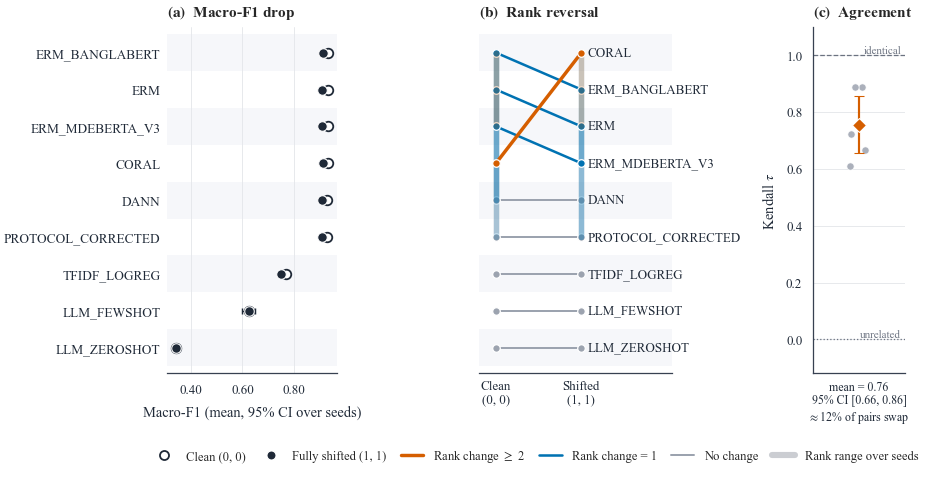

In [ ]:
# ===================== CELL 116: Leaderboard Reversal =====================


import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FormatStrFormatter
from pathlib import Path
from scipy.stats import kendalltau


FIG_DIR = Path(globals().get("FIG_DIR", Path(globals().get("OUT_ROOT", ".")) / "figures"))
TAB_DIR = Path(globals().get("TAB_DIR", FIG_DIR.parent / "tables"))
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

display = globals().get("display", print)

LAYOUTS = globals().get("LAYOUTS", {
    "ieee_single":     3.50,
    "ieee_double":     7.16,
    "elsevier_single": 3.54,
    "elsevier_1p5":    5.51,
    "elsevier_double": 7.48,
    "springer_double": 6.85,
})
LAYOUT = globals().get("LAYOUT", "ieee_double")


INK, MUTED, GRID, BAND = "#1F2937", "#6B7280", "#E5E7EB", "#F6F7FA"
COL_BIG, COL_SMALL, COL_NONE = "#D55E00", "#0072B2", "#9CA3AF"   

mpl.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.03,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Nimbus Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.titlesize": 8.5,
    "axes.labelsize": 8,
    "axes.labelcolor": INK,
    "axes.edgecolor": "#374151",
    "axes.linewidth": 0.7,
    "axes.axisbelow": True,
    "xtick.labelsize": 7.2,
    "ytick.labelsize": 7.2,
    "xtick.color": INK,
    "ytick.color": INK,
    "grid.color": GRID,
    "grid.linewidth": 0.5,
    "legend.frameon": False,
    "legend.fontsize": 7,
})


def _boot_ci(x, n_boot=10_000, alpha=0.05, seed=0):
    """Percentile bootstrap CI of the mean. Returns (mean, lo, hi)."""
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    if len(x) == 0:
        return np.nan, np.nan, np.nan
    if len(x) == 1:
        return float(x[0]), np.nan, np.nan
    rng = np.random.default_rng(seed)
    means = x[rng.integers(0, len(x), (n_boot, len(x)))].mean(axis=1)
    return (float(x.mean()),
            float(np.quantile(means, alpha / 2)),
            float(np.quantile(means, 1 - alpha / 2)))


_ci = globals().get("bootstrap_ci", _boot_ci)


def _kendall_tau(a, b):
    res = kendalltau(a, b)
    return float(getattr(res, "statistic", res[0]))


def declutter_positions(values, min_gap=0.85):
    """Push adjacent labels apart (values = rank positions, 1 = best)."""
    order = np.argsort(values)
    adjusted = np.array(values, dtype=float, copy=True)
    for i in range(1, len(order)):
        cur, prev = order[i], order[i - 1]
        if adjusted[cur] - adjusted[prev] < min_gap:
            adjusted[cur] = adjusted[prev] + min_gap
    return adjusted


def _move_style(change):
    a = abs(float(change))
    if a >= 2 - 1e-9:
        return COL_BIG, 1.9, 4
    if a >= 1 - 1e-9:
        return COL_SMALL, 1.4, 3
    return COL_NONE, 1.1, 2


def _bands(ax, n):
    for r in range(1, n + 1):
        if r % 2 == 1:
            ax.axhspan(r - 0.5, r + 0.5, color=BAND, lw=0, zorder=0)


def _save(fig, stem, formats=("pdf", "png", "svg")):
    for ext in formats:
        kw = {"dpi": 600} if ext == "png" else {}
        fig.savefig(FIG_DIR / f"{stem}.{ext}", **kw)


_cand = [m for m in ALL_RESULTS["model"].unique() if m != "MAJORITY"]
_seeds = sorted(set.intersection(*[
    set(ALL_RESULTS.loc[ALL_RESULTS["model"] == m, "seed"]) for m in _cand
]))
print(f"Models: {len(_cand)} | seeds common to all: {_seeds}")

_piv = (
    ALL_RESULTS[ALL_RESULTS["model"].isin(_cand) & ALL_RESULTS["seed"].isin(_seeds)]
    .pivot_table(index=["seed", "model"],
                 columns=["content_on", "protocol_on"],
                 values="macro_f1")
)
_clean = _piv[(0, 0)]
_shift = _piv[(1, 1)]

taus = np.array([
    _kendall_tau(_clean.loc[s].reindex(_cand), _shift.loc[s].reindex(_cand))
    for s in _seeds
], dtype=float)

tau_mean, tau_lo, tau_hi = _ci(taus[np.isfinite(taus)])
pct_swapped = 100 * (1 - tau_mean) / 2   
print(f"Kendall tau (ranking at (0,0), ranking at (1,1)) per seed = {np.round(taus, 3)}")
print(f"Mean tau = {tau_mean:.3f}  95% CI [{tau_lo:.3f}, {tau_hi:.3f}]  "
      f"(1 = identical ranking)  ~{pct_swapped:.0f}% of model pairs swap order")

_mean_c = _clean.groupby(level="model").mean()
_mean_s = _shift.groupby(level="model").mean()
_rank_c = _mean_c.rank(ascending=False)
_rank_s = _mean_s.rank(ascending=False)

_rk_c_seed = _clean.groupby(level="seed").rank(ascending=False)
_rk_s_seed = _shift.groupby(level="seed").rank(ascending=False)
_rng_c = _rk_c_seed.groupby(level="model").agg(["min", "max"])
_rng_s = _rk_s_seed.groupby(level="model").agg(["min", "max"])

rows = []
for m in _mean_c.index:
    c_vals = _clean.xs(m, level="model")
    s_vals = _shift.xs(m, level="model")
    _, c_lo, c_hi = _ci(c_vals.to_numpy())
    _, s_lo, s_hi = _ci(s_vals.to_numpy())
    d_mean, d_lo, d_hi = _ci((s_vals - c_vals).to_numpy())
    rows.append({
        "model": m,
        "macro_f1_clean": _mean_c[m], "f1_clean_lo": c_lo, "f1_clean_hi": c_hi,
        "rank_clean": _rank_c[m],
        "rank_clean_min": _rng_c.loc[m, "min"], "rank_clean_max": _rng_c.loc[m, "max"],
        "macro_f1_shifted": _mean_s[m], "f1_shifted_lo": s_lo, "f1_shifted_hi": s_hi,
        "rank_shifted": _rank_s[m],
        "rank_shifted_min": _rng_s.loc[m, "min"], "rank_shifted_max": _rng_s.loc[m, "max"],
        "delta_f1": d_mean, "delta_f1_lo": d_lo, "delta_f1_hi": d_hi,
    })

RANK_TBL = pd.DataFrame(rows).set_index("model")
RANK_TBL["rank_change"] = RANK_TBL["rank_clean"] - RANK_TBL["rank_shifted"]
RANK_TBL = RANK_TBL.sort_values(["rank_clean", "macro_f1_clean"], ascending=[True, False])

display(RANK_TBL.round(3))
RANK_TBL.to_csv(TAB_DIR / "leaderboard_reversal.csv")

n = len(RANK_TBL)
width = LAYOUTS[LAYOUT]
narrow = width < 4.5
main_h = max(2.6, 0.27 * n + 0.9)

if narrow:
    fig = plt.figure(figsize=(width, main_h + 1.6 + 0.4), constrained_layout=True)
    gs = fig.add_gridspec(3, 2, height_ratios=[main_h, 1.6, 0.4], width_ratios=[1.0, 1.1])
    ax_a = fig.add_subplot(gs[0, 0])
    ax_b = fig.add_subplot(gs[0, 1], sharey=ax_a)
    ax_c = fig.add_subplot(gs[1, :])
    ax_leg = fig.add_subplot(gs[2, :])
else:
    fig = plt.figure(figsize=(width, main_h + 0.4), constrained_layout=True)
    gs = fig.add_gridspec(2, 3, height_ratios=[main_h, 0.4], width_ratios=[1.15, 1.3, 0.62])
    ax_a = fig.add_subplot(gs[0, 0])
    ax_b = fig.add_subplot(gs[0, 1], sharey=ax_a)
    ax_c = fig.add_subplot(gs[0, 2])
    ax_leg = fig.add_subplot(gs[1, :])

ypos = RANK_TBL["rank_clean"].to_numpy(float)

_bands(ax_a, n)
for (model, row), y in zip(RANK_TBL.iterrows(), ypos):
    col, lw, z = _move_style(row["rank_change"])
    ax_a.plot([row["macro_f1_shifted"], row["macro_f1_clean"]], [y, y],
              color=col, lw=lw, zorder=z, solid_capstyle="round")
    for val, lo, hi in ((row["macro_f1_clean"], row["f1_clean_lo"], row["f1_clean_hi"]),
                        (row["macro_f1_shifted"], row["f1_shifted_lo"], row["f1_shifted_hi"])):
        if np.isfinite(lo) and np.isfinite(hi):
            ax_a.errorbar(val, y, xerr=[[max(val - lo, 0)], [max(hi - val, 0)]],
                          fmt="none", ecolor=INK, elinewidth=0.8,
                          capsize=1.8, capthick=0.8, zorder=5)

ax_a.scatter(RANK_TBL["macro_f1_clean"], ypos, s=28, facecolor="white",
             edgecolor=INK, linewidth=1.0, zorder=6)
ax_a.scatter(RANK_TBL["macro_f1_shifted"], ypos, s=28, facecolor=INK,
             edgecolor="white", linewidth=0.6, zorder=6)

lows = np.nanmin(np.r_[RANK_TBL["f1_clean_lo"], RANK_TBL["f1_shifted_lo"],
                       RANK_TBL["macro_f1_clean"], RANK_TBL["macro_f1_shifted"]])
highs = np.nanmax(np.r_[RANK_TBL["f1_clean_hi"], RANK_TBL["f1_shifted_hi"],
                        RANK_TBL["macro_f1_clean"], RANK_TBL["macro_f1_shifted"]])
pad = 0.06 * max(highs - lows, 1e-6)
ax_a.set_xlim(lows - pad, highs + pad)
ax_a.set_ylim(n + 0.7, 0.3)
ax_a.set_yticks(ypos)
ax_a.set_yticklabels(RANK_TBL.index, fontsize=7.4)
ax_a.xaxis.set_major_formatter(FormatStrFormatter("%.2f"))
ax_a.set_xlabel("Macro-F1" if narrow else "Macro-F1 (mean, 95% CI over seeds)")
ax_a.set_title(r"$\mathbf{(a)}$  Macro-F1 drop", loc="left", pad=6)
ax_a.grid(True, axis="x", color=GRID, lw=0.5, zorder=0)
ax_a.tick_params(axis="y", length=0)
for side in ("top", "right", "left"):
    ax_a.spines[side].set_visible(False)

_bands(ax_b, n)
x0, x1 = 0.0, 1.0
shifted_label_y = declutter_positions(RANK_TBL["rank_shifted"].to_numpy(float), 0.85)

for (model, row), ly in zip(RANK_TBL.iterrows(), shifted_label_y):
    col, lw, z = _move_style(row["rank_change"])
    rc, rs = float(row["rank_clean"]), float(row["rank_shifted"])

    ax_b.plot([x0, x0], [row["rank_clean_min"], row["rank_clean_max"]],
              color=col, lw=3.0, alpha=0.22, solid_capstyle="round", zorder=z - 0.5)
    ax_b.plot([x1, x1], [row["rank_shifted_min"], row["rank_shifted_max"]],
              color=col, lw=3.0, alpha=0.22, solid_capstyle="round", zorder=z - 0.5)

    ax_b.plot([x0, x1], [rc, rs], color=col, lw=lw, zorder=z, marker="o", ms=4.2,
              mfc=col, mec="white", mew=0.7)

    ax_b.text(x1 + 0.07, ly, model, ha="left", va="center", fontsize=7.2, color=INK)
    if abs(ly - rs) > 1e-6:
        ax_b.plot([x1 + 0.015, x1 + 0.055], [rs, ly], color="#D1D5DB", lw=0.6, zorder=1)

max_len = max(len(str(m)) for m in RANK_TBL.index)
ax_b.set_xlim(-0.2, 1.12 + 0.052 * max_len)
ax_b.set_xticks([x0, x1])
ax_b.set_xticklabels(["Clean\n(0, 0)", "Shifted\n(1, 1)"])
ax_b.set_title(r"$\mathbf{(b)}$  Rank reversal", loc="left", pad=6)
ax_b.tick_params(axis="both", length=0)
ax_b.tick_params(axis="y", labelleft=False)
ax_b.grid(False)
for side in ("top", "right", "left"):
    ax_b.spines[side].set_visible(False)

rng_j = np.random.default_rng(0)
jit = rng_j.uniform(-0.12, 0.12, len(taus))
tau_ok = np.isfinite(taus)
has_ci = np.isfinite(tau_lo) and np.isfinite(tau_hi)
err = [[max(tau_mean - tau_lo, 0)], [max(tau_hi - tau_mean, 0)]] if has_ci else None

if narrow:
    ax_c.scatter(taus[tau_ok], jit[tau_ok], s=16, color=COL_NONE, alpha=0.85,
                 edgecolor="white", linewidth=0.4, zorder=3)
    ax_c.errorbar(tau_mean, 0, xerr=err, fmt="D", ms=5.2, color=COL_BIG, mec="white",
                  mew=0.6, ecolor=COL_BIG, elinewidth=1.2, capsize=2.6, capthick=1.2, zorder=5)
    ax_c.axvline(1, color=MUTED, ls="--", lw=0.7, zorder=1)
    ax_c.axvline(0, color=MUTED, ls=":", lw=0.7, zorder=1)
    ax_c.set_xlim(min(0, np.nanmin(taus), tau_lo if has_ci else 0) - 0.12, 1.08)
    ax_c.set_ylim(-0.5, 0.5)
    ax_c.set_yticks([])
    ax_c.set_xlabel(r"Kendall $\tau$ (clean vs. shifted, one dot per seed)" "\n"
                    f"mean = {tau_mean:.2f}, 95% CI [{tau_lo:.2f}, {tau_hi:.2f}]; "
                    rf"$\approx${pct_swapped:.0f}% of model pairs swap",
                    linespacing=1.4)
    ax_c.grid(True, axis="x", color=GRID, lw=0.5)
    for side in ("top", "right", "left"):
        ax_c.spines[side].set_visible(False)
else:
    ax_c.scatter(jit[tau_ok], taus[tau_ok], s=16, color=COL_NONE, alpha=0.85,
                 edgecolor="white", linewidth=0.4, zorder=3)
    ax_c.errorbar(0, tau_mean, yerr=err, fmt="D", ms=5.2, color=COL_BIG, mec="white",
                  mew=0.6, ecolor=COL_BIG, elinewidth=1.2, capsize=2.6, capthick=1.2, zorder=5)
    ax_c.axhline(1, color=MUTED, ls="--", lw=0.7, zorder=1)
    ax_c.axhline(0, color=MUTED, ls=":", lw=0.7, zorder=1)
    ax_c.text(0.55, 1.0, "identical", ha="right", va="bottom", fontsize=6.2, color=MUTED)
    ax_c.text(0.55, 0.0, "unrelated", ha="right", va="bottom", fontsize=6.2, color=MUTED)
    ax_c.set_xlim(-0.6, 0.6)
    ax_c.set_ylim(min(0, np.nanmin(taus), tau_lo if has_ci else 0) - 0.12, 1.1)
    ax_c.set_xticks([])
    ax_c.set_ylabel(r"Kendall $\tau$")
    ax_c.set_xlabel(f"mean = {tau_mean:.2f}\n95% CI [{tau_lo:.2f}, {tau_hi:.2f}]\n"
                    rf"$\approx${pct_swapped:.0f}% of pairs swap",
                    fontsize=6.6, labelpad=4)
    ax_c.grid(True, axis="y", color=GRID, lw=0.5)
    for side in ("top", "right"):
        ax_c.spines[side].set_visible(False)

ax_c.set_title(r"$\mathbf{(c)}$  Agreement", loc="left", pad=6)

handles = [
    Line2D([], [], marker="o", ls="", mfc="white", mec=INK, mew=1.0, ms=5, label="Clean (0, 0)"),
    Line2D([], [], marker="o", ls="", mfc=INK, mec="white", mew=0.6, ms=5, label="Fully shifted (1, 1)"),
    Line2D([], [], color=COL_BIG, lw=1.9, label=r"Rank change $\geq$ 2"),
    Line2D([], [], color=COL_SMALL, lw=1.4, label="Rank change = 1"),
    Line2D([], [], color=COL_NONE, lw=1.1, label="No change"),
    Line2D([], [], color=MUTED, lw=3.4, alpha=0.35, solid_capstyle="round",
           label="Rank range over seeds"),
]
ax_leg.axis("off")
ax_leg.legend(handles=handles, loc="center", ncol=3 if narrow else 6,
              handlelength=1.8, columnspacing=1.1, labelspacing=0.4)

_save(fig, "fig_leaderboard_reversal")
plt.show()

Common seeds across ERM and remedies: [13, 42, 2024, 3407, 9001]

Paired remedy-vs-ERM bootstrap results:


,remedy,quantity,delta_vs_ERM,ci_low,ci_high,n_seeds,p_paired_wilcoxon,cohens_dz,p_holm
0,DANN,phi_content,-0.0014,-0.0022,-0.0006,5,0.0625,-1.3708,0.1875
1,DANN,phi_protocol,-0.0004,-0.0018,0.0010,5,0.8125,-0.2050,0.8125
2,DANN,total_drop,-0.0017,-0.0034,0.0001,5,0.1875,-0.7706,0.3750
3,CORAL,phi_content,-0.0025,-0.0038,-0.0016,5,0.0625,-1.8240,0.1875
4,CORAL,phi_protocol,-0.0012,-0.0030,0.0002,5,0.3125,-0.6134,0.3125
5,CORAL,total_drop,-0.0038,-0.0054,-0.0027,5,0.0625,-2.1258,0.1875
6,PROTOCOL_CORRECTED,phi_content,-0.0013,-0.0023,-0.0002,5,0.3125,-0.9133,0.9375
7,PROTOCOL_CORRECTED,phi_protocol,0.0005,-0.0021,0.0028,5,0.8125,0.1729,1.0000
8,PROTOCOL_CORRECTED,total_drop,-0.0007,-0.0028,0.0013,5,0.6250,-0.2844,1.0000



Uncertainty-aware dominant-factor classification:


,protocol_minus_content,ci_low,ci_high,dominant_uncertainty_aware,p_paired_wilcoxon,n_seeds
model,,,,,,
CORAL,0.0190,0.0174,0.0217,protocol,0.0625,5
DANN,0.0187,0.0173,0.0208,protocol,0.0625,5
ERM,0.0177,0.0164,0.0191,protocol,0.0625,5
ERM_BANGLABERT,0.0186,0.0157,0.0226,protocol,0.0625,5
ERM_MDEBERTA_V3,0.0210,0.0197,0.0222,protocol,0.0625,5
LLM_FEWSHOT,0.0051,-0.0226,0.0390,ambiguous,1.0000,5
LLM_ZEROSHOT,-0.0006,-0.0008,-0.0003,content,0.1250,5
MAJORITY,0.0000,0.0000,0.0000,ambiguous,1.0000,5
PROTOCOL_CORRECTED,0.0195,0.0168,0.0224,protocol,0.0625,5



Remedy selectivity: targeted minus non-targeted attribution change


,remedy,targeted_factor,non_targeted_factor,selectivity_delta,ci_low,ci_high,p_one_sided_wilcoxon,n_seeds,p_holm
0,DANN,phi_content,phi_protocol,-0.0010,-0.0025,0.0005,0.2188,5,0.6562
1,CORAL,phi_content,phi_protocol,-0.0013,-0.0038,0.0007,0.3125,5,0.6562
2,PROTOCOL_CORRECTED,phi_protocol,phi_content,0.0018,-0.0013,0.0047,0.9062,5,0.9062



Leaderboard reversal validation:


,kendall_tau_mean,kendall_tau_ci_low,kendall_tau_ci_high,kendall_tau_permutation_p,n_seeds,n_models
0,0.7556,0.6556,0.8556,0.0008,5,9



Consolidated statistical claims:
{
  "n_common_seeds": 5,
  "n_models_protocol_dominant_ci_excludes_zero": 7,
  "n_models_content_dominant_ci_excludes_zero": 1,
  "n_remedies_with_significant_selectivity_holm": 0,
  "remedies_with_significant_selectivity": [],
  "leaderboard_kendall_tau_mean": 0.7555555555555555,
  "leaderboard_kendall_tau_permutation_p": 0.0007999200079992001
}

Saved:
- E:\Research\Attributing Cross-Corpus Failure\results\tables\remedy_targeting_paired_bootstrap.csv
- E:\Research\Attributing Cross-Corpus Failure\results\tables\dominant_factor_uncertainty_aware.csv
- E:\Research\Attributing Cross-Corpus Failure\results\tables\remedy_selectivity.csv
- E:\Research\Attributing Cross-Corpus Failure\results\tables\statistical_claims.json


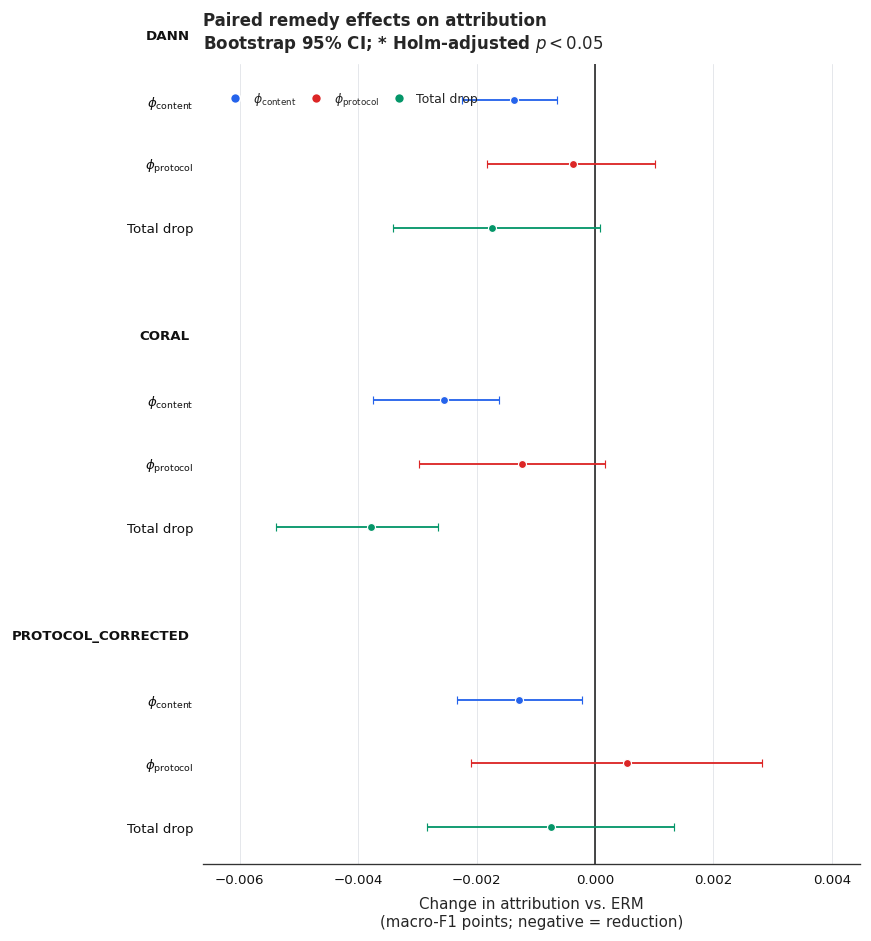

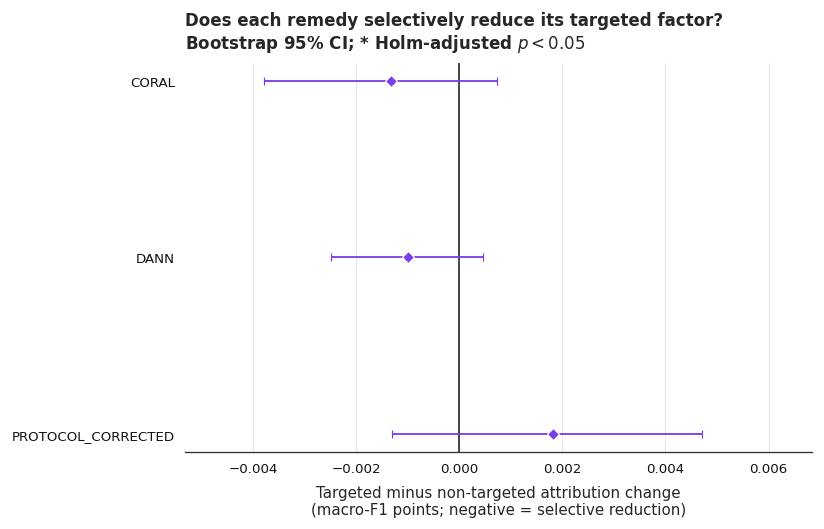

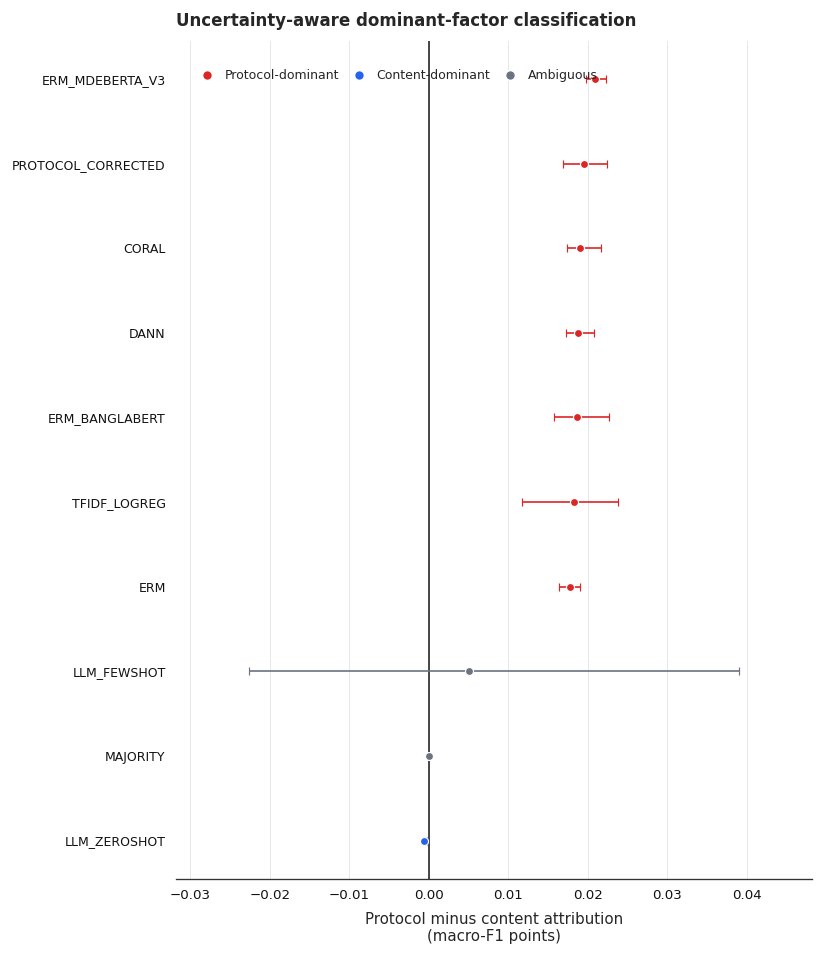

In [ ]:
# ===================== CELL 116 b: Statistical Validation + Diagnostic Plots =====================


import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon, kendalltau
from statsmodels.stats.multitest import multipletests
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
from pathlib import Path

TAB_DIR = Path(TAB_DIR)
FIG_DIR = Path(FIG_DIR)
TAB_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

N_BOOT = 10000
RNG_SEED = 2026
ALPHA = 0.05

BASE = "ERM"
REMEDIES = {
    "DANN": "phi_content",
    "CORAL": "phi_content",
    "PROTOCOL_CORRECTED": "phi_protocol",
}

QUANTITIES = ["phi_content", "phi_protocol", "total_drop"]

QUANTITY_LABELS = {
    "phi_content": r"$\phi_{\mathrm{content}}$",
    "phi_protocol": r"$\phi_{\mathrm{protocol}}$",
    "total_drop": "Total drop",
}

QUANTITY_COLORS = {
    "phi_content": "#2563EB",
    "phi_protocol": "#DC2626",
    "total_drop": "#059669",
}

SELECTIVITY_COLOR = "#7C3AED"
NEUTRAL_COLOR = "#6B7280"

PLOT_RC = {
    "font.family": "DejaVu Sans",
    "font.size": 8,
    "axes.titlesize": 10,
    "axes.titleweight": "bold",
    "axes.labelsize": 9,
    "axes.edgecolor": "#333333",
    "axes.linewidth": 0.8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "xtick.color": "#111111",
    "ytick.color": "#111111",
    "legend.frameon": False,
    "legend.fontsize": 7.5,
}

plt.rcParams.update(PLOT_RC)

def ci_distances(mean, lo, hi):
    """Non-negative lower and upper CI distances for Matplotlib."""
    lower = max(float(mean) - float(lo), 0.0)
    upper = max(float(hi) - float(mean), 0.0)
    return lower, upper


def bootstrap_mean_ci(values, n_boot=N_BOOT, seed=RNG_SEED):
    values = np.asarray(values, dtype=float)
    values = values[~np.isnan(values)]

    if len(values) == 0:
        return np.nan, np.nan, np.nan

    rng = np.random.default_rng(seed)
    boot = np.empty(n_boot, dtype=float)

    for b in range(n_boot):
        idx = rng.integers(0, len(values), size=len(values))
        boot[b] = values[idx].mean()

    lo, hi = np.quantile(boot, [0.025, 0.975])
    return float(values.mean()), float(lo), float(hi)


def paired_wilcoxon_p(values, alternative="two-sided"):
    values = np.asarray(values, dtype=float)
    values = values[~np.isnan(values)]

    if len(values) == 0 or np.allclose(values, 0):
        return 1.0

    return float(
        wilcoxon(
            values,
            alternative=alternative,
            zero_method="wilcox",
        ).pvalue
    )


def save_and_show(fig, filename):
    fig.tight_layout(pad=0.6)
    fig.savefig(FIG_DIR / f"{filename}.pdf", bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{filename}.png", dpi=600, bbox_inches="tight")
    plt.show()


models_needed = [BASE] + list(REMEDIES.keys())
models_needed = [
    m for m in models_needed
    if m in ATTR_MF1["model"].unique()
]

common_seeds = None

for model in models_needed:
    seeds = set(
        ATTR_MF1.loc[ATTR_MF1["model"] == model, "seed"]
    )
    common_seeds = seeds if common_seeds is None else common_seeds & seeds

COMMON_SEEDS = sorted(common_seeds)

if not COMMON_SEEDS:
    raise ValueError("No common seeds across ERM and remedy arms.")

_wide = ATTR_MF1[
    ATTR_MF1["seed"].isin(COMMON_SEEDS)
].pivot(
    index="seed",
    columns="model",
    values=["phi_content", "phi_protocol", "total_drop"],
)

print(f"Common seeds across ERM and remedies: {COMMON_SEEDS}")

BOOT_ROWS = []

for remedy in REMEDIES:
    if remedy not in _wide["phi_content"].columns:
        continue

    for quantity in QUANTITIES:
        delta = (
            _wide[quantity][remedy]
            - _wide[quantity][BASE]
        ).dropna().to_numpy(dtype=float)

        if len(delta) == 0:
            continue

        mean, lo, hi = bootstrap_mean_ci(delta)

        BOOT_ROWS.append({
            "remedy": remedy,
            "quantity": quantity,
            "delta_vs_ERM": mean,
            "ci_low": lo,
            "ci_high": hi,
            "n_seeds": len(delta),
            "p_paired_wilcoxon": paired_wilcoxon_p(delta),
            "cohens_dz": (
                delta.mean() / delta.std(ddof=1)
                if delta.std(ddof=1) > 0 else np.nan
            ),
        })

REMEDY_BOOT = pd.DataFrame(BOOT_ROWS)

REMEDY_BOOT["p_holm"] = np.nan

for remedy, group in REMEDY_BOOT.groupby("remedy"):
    _, p_adj, _, _ = multipletests(
        group["p_paired_wilcoxon"].to_numpy(),
        alpha=ALPHA,
        method="holm",
    )
    REMEDY_BOOT.loc[group.index, "p_holm"] = p_adj

print("\nPaired remedy-vs-ERM bootstrap results:")
display(REMEDY_BOOT.round(4))

REMEDY_BOOT.to_csv(
    TAB_DIR / "remedy_targeting_paired_bootstrap.csv",
    index=False,
)

DOM_ROWS = []

for model in _wide["phi_content"].columns:
    if model not in _wide["phi_protocol"].columns:
        continue

    diff = (
        _wide["phi_protocol"][model]
        - _wide["phi_content"][model]
    ).dropna()

    if len(diff) == 0:
        continue

    mean, lo, hi = bootstrap_mean_ci(diff)

    if mean > 0 and lo > 0:
        dominant = "protocol"
    elif mean < 0 and hi < 0:
        dominant = "content"
    else:
        dominant = "ambiguous"

    DOM_ROWS.append({
        "model": model,
        "protocol_minus_content": mean,
        "ci_low": lo,
        "ci_high": hi,
        "dominant_uncertainty_aware": dominant,
        "p_paired_wilcoxon": paired_wilcoxon_p(diff),
        "n_seeds": len(diff),
    })

DOMINANCE_DF = pd.DataFrame(DOM_ROWS).set_index("model")

print("\nUncertainty-aware dominant-factor classification:")
display(DOMINANCE_DF.round(4))

DOMINANCE_DF.to_csv(
    TAB_DIR / "dominant_factor_uncertainty_aware.csv"
)

SEL_ROWS = []

for remedy, target in REMEDIES.items():
    if remedy not in _wide["phi_content"].columns:
        continue

    non_target = (
        "phi_protocol" if target == "phi_content"
        else "phi_content"
    )

    d_target = (
        _wide[target][remedy] - _wide[target][BASE]
    ).dropna()

    d_non_target = (
        _wide[non_target][remedy] - _wide[non_target][BASE]
    ).dropna()

    common = d_target.index.intersection(d_non_target.index)

    selectivity = (
        d_target.loc[common] - d_non_target.loc[common]
    ).to_numpy(dtype=float)

    mean, lo, hi = bootstrap_mean_ci(selectivity)

    SEL_ROWS.append({
        "remedy": remedy,
        "targeted_factor": target,
        "non_targeted_factor": non_target,
        "selectivity_delta": mean,
        "ci_low": lo,
        "ci_high": hi,
        "p_one_sided_wilcoxon": paired_wilcoxon_p(
            selectivity,
            alternative="less",
        ),
        "n_seeds": len(selectivity),
    })

REMEDY_SELECTIVITY = pd.DataFrame(SEL_ROWS)

if len(REMEDY_SELECTIVITY):
    _, p_holm, _, _ = multipletests(
        REMEDY_SELECTIVITY["p_one_sided_wilcoxon"].to_numpy(),
        alpha=ALPHA,
        method="holm",
    )
    REMEDY_SELECTIVITY["p_holm"] = p_holm

print("\nRemedy selectivity: targeted minus non-targeted attribution change")
display(REMEDY_SELECTIVITY.round(4))

REMEDY_SELECTIVITY.to_csv(
    TAB_DIR / "remedy_selectivity.csv",
    index=False,
)

LEADERBOARD_VALIDATION = None

if "ALL_RESULTS" in globals():
    candidate_models = [
        m for m in ALL_RESULTS["model"].unique()
        if m != "MAJORITY"
    ]

    seed_sets = [
        set(ALL_RESULTS.loc[ALL_RESULTS["model"] == m, "seed"])
        for m in candidate_models
    ]

    leaderboard_seeds = sorted(set.intersection(*seed_sets))

    rank_pivot = ALL_RESULTS[
        ALL_RESULTS["model"].isin(candidate_models)
        & ALL_RESULTS["seed"].isin(leaderboard_seeds)
    ].pivot_table(
        index=["seed", "model"],
        columns=["content_on", "protocol_on"],
        values="macro_f1",
    )

    seed_taus = []

    for seed in leaderboard_seeds:
        sub = rank_pivot.loc[seed]
        seed_taus.append(
            kendalltau(sub[(0, 0)], sub[(1, 1)]).statistic
        )

    seed_taus = np.asarray(seed_taus, dtype=float)
    tau_mean, tau_lo, tau_hi = bootstrap_mean_ci(seed_taus)

    mean_clean = rank_pivot.groupby("model").mean()[(0, 0)]
    mean_shifted = rank_pivot.groupby("model").mean()[(1, 1)]

    rng = np.random.default_rng(RNG_SEED)
    observed_tau = kendalltau(mean_clean, mean_shifted).statistic

    n_perm = 10000
    count = 0

    for _ in range(n_perm):
        permuted = rng.permutation(mean_shifted)
        if abs(kendalltau(mean_clean, permuted).statistic) >= abs(observed_tau):
            count += 1

    tau_perm_p = (count + 1) / (n_perm + 1)

    LEADERBOARD_VALIDATION = {
        "kendall_tau_mean": tau_mean,
        "kendall_tau_ci_low": tau_lo,
        "kendall_tau_ci_high": tau_hi,
        "kendall_tau_permutation_p": tau_perm_p,
        "n_seeds": len(seed_taus),
        "n_models": len(candidate_models),
    }

    print("\nLeaderboard reversal validation:")
    display(pd.DataFrame([LEADERBOARD_VALIDATION]).round(4))

    pd.DataFrame([LEADERBOARD_VALIDATION]).to_csv(
        TAB_DIR / "leaderboard_reversal_validation.csv",
        index=False,
    )
else:
    print("\nLeaderboard validation skipped: ALL_RESULTS not available.")

protocol_dominant = DOMINANCE_DF[
    DOMINANCE_DF["dominant_uncertainty_aware"] == "protocol"
]

content_dominant = DOMINANCE_DF[
    DOMINANCE_DF["dominant_uncertainty_aware"] == "content"
]

significant_selectivity = REMEDY_SELECTIVITY[
    REMEDY_SELECTIVITY["p_holm"] < ALPHA
] if len(REMEDY_SELECTIVITY) else pd.DataFrame()

STATISTICAL_CLAIMS = {
    "n_common_seeds": len(COMMON_SEEDS),
    "n_models_protocol_dominant_ci_excludes_zero": int(len(protocol_dominant)),
    "n_models_content_dominant_ci_excludes_zero": int(len(content_dominant)),
    "n_remedies_with_significant_selectivity_holm": int(len(significant_selectivity)),
    "remedies_with_significant_selectivity": (
        significant_selectivity["remedy"].tolist()
        if len(significant_selectivity) else []
    ),
    "leaderboard_kendall_tau_mean": (
        float(LEADERBOARD_VALIDATION["kendall_tau_mean"])
        if LEADERBOARD_VALIDATION else None
    ),
    "leaderboard_kendall_tau_permutation_p": (
        float(LEADERBOARD_VALIDATION["kendall_tau_permutation_p"])
        if LEADERBOARD_VALIDATION else None
    ),
}

with open(TAB_DIR / "statistical_claims.json", "w", encoding="utf-8") as f:
    json.dump(STATISTICAL_CLAIMS, f, indent=2, ensure_ascii=False)

print("\nConsolidated statistical claims:")
print(json.dumps(STATISTICAL_CLAIMS, indent=2, ensure_ascii=False))

print("\nSaved:")
print(f"- {TAB_DIR / 'remedy_targeting_paired_bootstrap.csv'}")
print(f"- {TAB_DIR / 'dominant_factor_uncertainty_aware.csv'}")
print(f"- {TAB_DIR / 'remedy_selectivity.csv'}")
print(f"- {TAB_DIR / 'statistical_claims.json'}")

def plot_remedy_bootstrap_forest(
    remedy_boot,
    filename="fig_remedy_targeting_forest",
):
    if remedy_boot is None or not len(remedy_boot):
        print("No paired bootstrap results available for forest plot.")
        return

    df = remedy_boot[
        remedy_boot["quantity"].isin(QUANTITIES)
    ].copy()

    remedies = list(df["remedy"].unique())

    fig, ax = plt.subplots(
        figsize=(7.2, 0.62 * len(df) + 2.2)
    )

    y_index = 0
    y_positions = []
    y_labels = []

    for remedy in remedies:
        ax.text(
            -0.02,
            y_index,
            remedy,
            transform=ax.get_yaxis_transform(),
            ha="right",
            va="center",
            fontsize=8,
            fontweight="bold",
            color="#111111",
        )

        y_index += 1

        for quantity in QUANTITIES:
            row = df[
                (df["remedy"] == remedy)
                & (df["quantity"] == quantity)
            ]

            if not len(row):
                continue

            row = row.iloc[0]
            mean = float(row["delta_vs_ERM"])
            lo = float(row["ci_low"])
            hi = float(row["ci_high"])

            lower, upper = ci_distances(mean, lo, hi)
            color = QUANTITY_COLORS[quantity]

            ax.errorbar(
                mean,
                y_index,
                xerr=[[lower], [upper]],
                fmt="o",
                ms=4.8,
                mfc=color,
                mec="white",
                mew=0.7,
                ecolor=color,
                elinewidth=1.1,
                capsize=2.5,
                capthick=0.8,
                zorder=4,
            )

            if float(row["p_holm"]) < ALPHA:
                ax.text(
                    hi,
                    y_index,
                    "*",
                    ha="left",
                    va="center",
                    fontsize=9,
                    color="#111111",
                    zorder=5,
                )

            y_positions.append(y_index)
            y_labels.append(QUANTITY_LABELS[quantity])
            y_index += 1

        y_index += 0.7

    ax.axvline(0, color="#111111", lw=0.9, zorder=2)
    ax.set_yticks(y_positions)
    ax.set_yticklabels(y_labels)
    ax.invert_yaxis()

    ax.set_xlabel(
        "Change in attribution vs. ERM\n"
        "(macro-F1 points; negative = reduction)",
        labelpad=6,
    )
    ax.set_title(
        "Paired remedy effects on attribution\n"
        "Bootstrap 95% CI; * Holm-adjusted $p<0.05$",
        loc="left",
        pad=9,
    )

    ax.grid(True, axis="x", color="#E5E7EB", lw=0.6, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(axis="both", length=2.5, width=0.7)

    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)

    all_vals = np.concatenate([
        df["delta_vs_ERM"].to_numpy(dtype=float),
        df["ci_low"].to_numpy(dtype=float),
        df["ci_high"].to_numpy(dtype=float),
    ])

    xmin, xmax = np.nanmin(all_vals), np.nanmax(all_vals)
    span = max(abs(xmax - xmin), 1e-6)
    ax.set_xlim(xmin - 0.15 * span, xmax + 0.20 * span)

    handles = [
        Line2D(
            [0], [0],
            marker="o", color="none",
            markerfacecolor=QUANTITY_COLORS[q],
            markeredgecolor="white",
            markersize=6,
            label=QUANTITY_LABELS[q],
        )
        for q in QUANTITIES
    ]

    ax.legend(
        handles=handles,
        loc="upper left",
        bbox_to_anchor=(0.02, 0.98),
        ncol=3,
        columnspacing=1.0,
        handlelength=1.2,
        labelspacing=0.45,
    )

    save_and_show(fig, filename)


plot_remedy_bootstrap_forest(
    remedy_boot=REMEDY_BOOT,
    filename="fig_remedy_targeting_forest",
)

def plot_remedy_selectivity_forest(
    selectivity_df,
    filename="fig_remedy_selectivity_forest",
):
    if selectivity_df is None or not len(selectivity_df):
        print("No remedy selectivity results available for forest plot.")
        return

    df = selectivity_df.copy().sort_values(
        "selectivity_delta", ascending=True
    )

    y = np.arange(len(df))

    lower_err = np.array([
        ci_distances(m, lo, hi)[0]
        for m, lo, hi in zip(
            df["selectivity_delta"],
            df["ci_low"],
            df["ci_high"],
        )
    ])

    upper_err = np.array([
        ci_distances(m, lo, hi)[1]
        for m, lo, hi in zip(
            df["selectivity_delta"],
            df["ci_low"],
            df["ci_high"],
        )
    ])

    fig, ax = plt.subplots(
        figsize=(6.8, 0.65 * len(df) + 2.4)
    )

    ax.errorbar(
        df["selectivity_delta"],
        y,
        xerr=[lower_err, upper_err],
        fmt="D",
        ms=5.0,
        mfc=SELECTIVITY_COLOR,
        mec="white",
        mew=0.7,
        ecolor=SELECTIVITY_COLOR,
        elinewidth=1.1,
        capsize=2.5,
        capthick=0.8,
        zorder=4,
    )

    for yi, (_, row) in zip(y, df.iterrows()):
        if float(row["p_holm"]) < ALPHA:
            ax.text(
                float(row["ci_high"]),
                yi,
                "*",
                ha="left",
                va="center",
                fontsize=9,
                color="#111111",
                zorder=5,
            )

    ax.axvline(0, color="#111111", lw=0.9, zorder=2)
    ax.set_yticks(y)
    ax.set_yticklabels(df["remedy"], fontsize=8)
    ax.invert_yaxis()

    ax.set_xlabel(
        "Targeted minus non-targeted attribution change\n"
        "(macro-F1 points; negative = selective reduction)",
        labelpad=6,
    )
    ax.set_title(
        "Does each remedy selectively reduce its targeted factor?\n"
        "Bootstrap 95% CI; * Holm-adjusted $p<0.05$",
        loc="left",
        pad=9,
    )

    ax.grid(True, axis="x", color="#E5E7EB", lw=0.6, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(axis="both", length=2.5, width=0.7)

    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)

    all_vals = np.concatenate([
        df["selectivity_delta"].to_numpy(dtype=float),
        df["ci_low"].to_numpy(dtype=float),
        df["ci_high"].to_numpy(dtype=float),
    ])

    xmin, xmax = np.nanmin(all_vals), np.nanmax(all_vals)
    span = max(abs(xmax - xmin), 1e-6)
    ax.set_xlim(xmin - 0.18 * span, xmax + 0.25 * span)

    save_and_show(fig, filename)


plot_remedy_selectivity_forest(
    selectivity_df=REMEDY_SELECTIVITY,
    filename="fig_remedy_selectivity_forest",
)

def plot_dominance_forest(
    dominance_df,
    filename="fig_dominance_forest",
):
    if dominance_df is None or not len(dominance_df):
        print("No dominance results available for forest plot.")
        return

    df = dominance_df.copy().sort_values(
        "protocol_minus_content", ascending=False
    )

    y = np.arange(len(df))

    lower_err = np.array([
        ci_distances(m, lo, hi)[0]
        for m, lo, hi in zip(
            df["protocol_minus_content"],
            df["ci_low"],
            df["ci_high"],
        )
    ])

    upper_err = np.array([
        ci_distances(m, lo, hi)[1]
        for m, lo, hi in zip(
            df["protocol_minus_content"],
            df["ci_low"],
            df["ci_high"],
        )
    ])

    # Map each model to its color
    color_map = {
        "protocol": QUANTITY_COLORS["phi_protocol"],
        "content": QUANTITY_COLORS["phi_content"],
        "ambiguous": NEUTRAL_COLOR,
    }

    fig, ax = plt.subplots(
        figsize=(6.8, 0.55 * len(df) + 2.4)
    )

    # Draw each model separately so each can have its own color
    for yi, (model, row) in zip(y, df.iterrows()):
        mean = float(row["protocol_minus_content"])
        lo = float(row["ci_low"])
        hi = float(row["ci_high"])

        lower, upper = ci_distances(mean, lo, hi)

        color = color_map.get(
            row["dominant_uncertainty_aware"],
            NEUTRAL_COLOR,
        )

        ax.errorbar(
            mean,
            yi,
            xerr=[[lower], [upper]],
            fmt="o",
            ms=4.8,
            mfc=color,
            mec="white",
            mew=0.7,
            ecolor=color,
            elinewidth=1.0,
            capsize=2.2,
            capthick=0.8,
            zorder=4,
        )

    ax.axvline(0, color="#111111", lw=0.9, zorder=2)

    ax.set_yticks(y)
    ax.set_yticklabels(df.index, fontsize=7.5)
    ax.invert_yaxis()

    ax.set_xlabel(
        r"Protocol minus content attribution"
        "\n(macro-F1 points)",
        labelpad=6,
    )
    ax.set_title(
        "Uncertainty-aware dominant-factor classification",
        loc="left",
        pad=9,
    )

    ax.grid(True, axis="x", color="#E5E7EB", lw=0.6, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(axis="both", length=2.5, width=0.7)

    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)

    all_vals = np.concatenate([
        df["protocol_minus_content"].to_numpy(dtype=float),
        df["ci_low"].to_numpy(dtype=float),
        df["ci_high"].to_numpy(dtype=float),
    ])

    xmin, xmax = np.nanmin(all_vals), np.nanmax(all_vals)
    span = max(abs(xmax - xmin), 1e-6)
    ax.set_xlim(xmin - 0.15 * span, xmax + 0.15 * span)

    handles = [
        Line2D(
            [0], [0], marker="o", color="none",
            markerfacecolor=QUANTITY_COLORS["phi_protocol"],
            markeredgecolor="white", markersize=6,
            label="Protocol-dominant",
        ),
        Line2D(
            [0], [0], marker="o", color="none",
            markerfacecolor=QUANTITY_COLORS["phi_content"],
            markeredgecolor="white", markersize=6,
            label="Content-dominant",
        ),
        Line2D(
            [0], [0], marker="o", color="none",
            markerfacecolor=NEUTRAL_COLOR,
            markeredgecolor="white", markersize=6,
            label="Ambiguous",
        ),
    ]

    ax.legend(
        handles=handles,
        loc="upper left",
        bbox_to_anchor=(0.02, 0.98),
        ncol=3,
        columnspacing=1.0,
        handlelength=1.2,
        labelspacing=0.45,
    )

    save_and_show(fig, filename)


plot_dominance_forest(
    dominance_df=DOMINANCE_DF,
    filename="fig_dominance_forest",
)

In [ ]:
# ===================== CELL 117 =====================

import json

def _fmt(mean, lo, hi, scale=100.0):
    return f"{mean*scale:+.1f} [{lo*scale:+.1f}, {hi*scale:+.1f}]"

_lines = [r"\begin{tabular}{llcccc}", r"\toprule",
          r"Model & Family & $\phi_{\text{content}}$ & $\phi_{\text{protocol}}$ & Total drop & Interaction \\", r"\midrule"]
for m in sorted(SUMM_MF1.index, key=lambda k: (MODEL_FAMILY[k], k)):
    cells = [_fmt(_s(m, q, "mean"), _s(m, q, "ci_low"), _s(m, q, "ci_high")) for q in ["phi_content", "phi_protocol", "total_drop", "interaction"]]
    _lines.append(" & ".join([m.replace("_", r"\_"), MODEL_FAMILY[m]] + cells) + r" \\")
_lines += [r"\bottomrule", r"\end{tabular}"]
(TAB_DIR / "table_main_attribution.tex").write_text("\n".join(_lines), encoding="utf-8")

enc = [m for m in SUMM_MF1.index if MODEL_FAMILY[m] == "Fine-tuned encoder"]
claims = {
    "n_models": int(len(SUMM_MF1)),
    "n_models_protocol_dominant_macroF1": int(sum(_s(m, "phi_protocol", "mean") > _s(m, "phi_content", "mean") for m in SUMM_MF1.index)),
    "n_models_protocol_CI_excludes_zero": int(sum(_s(m, "phi_protocol", "ci_low") > 0 or _s(m, "phi_protocol", "ci_high") < 0 for m in SUMM_MF1.index)),
    "metric_stable_dominant_factor_models": int((agree == 1).sum()) if "agree" in globals() else None,
    "leaderboard_kendall_tau_mean": float(tau_mean) if "tau_mean" in globals() else None,
    "negative_control_all_passed": bool(NEG_CONTROL["negative_control_passed"].all()) if "NEG_CONTROL" in globals() and len(NEG_CONTROL) else None,
    "encoder_mean_phi_content": float(np.mean([_s(m, "phi_content", "mean") for m in enc])) if enc else None,
    "encoder_mean_phi_protocol": float(np.mean([_s(m, "phi_protocol", "mean") for m in enc])) if enc else None,
}
(TAB_DIR / "claims_ledger.json").write_text(json.dumps(claims, indent=2), encoding="utf-8")
print(json.dumps(claims, indent=2))
print("\nWrote:", [p.name for p in [TAB_DIR / "table_main_attribution.tex", TAB_DIR / "claims_ledger.json"]])
print("Figures:", sorted(p.name for p in FIG_DIR.glob("fig_*.png")))

{
  "n_models": 10,
  "n_models_protocol_dominant_macroF1": 8,
  "n_models_protocol_CI_excludes_zero": 7,
  "metric_stable_dominant_factor_models": 8,
  "leaderboard_kendall_tau_mean": 0.7555555555555555,
  "negative_control_all_passed": true,
  "encoder_mean_phi_content": 0.00022973041666666432,
  "encoder_mean_phi_protocol": 0.01932683698333333
}

Wrote: ['table_main_attribution.tex', 'claims_ledger.json']
Figures: ['fig_attribution_map.png', 'fig_calibration_reliability.png', 'fig_correction_efficiency.png', 'fig_crosslanguage_shapley.png', 'fig_dominance_forest.png', 'fig_leaderboard_reversal.png', 'fig_metric_robustness.png', 'fig_model_panel_macro_f1.png', 'fig_remedy_selectivity_forest.png', 'fig_remedy_targeting.png', 'fig_remedy_targeting_forest.png', 'fig_robustness_curve.png', 'fig_topic_error_heatmap.png']


**HateXplain replication (second language) — CELL 120–124**

Run after the main notebook state exists (CFG, CELL 12, 17, 20, 25, 26, 42, 80, 83/83b). Writes only `*_hx_*` files; never touches YouTube-BN results or checkpoints.

Order: 120 -> 121 -> 122 -> 123 (classical arms) -> 123 again with `ONLY_MODELS=["ERM_XLMR"]`, `["ERM_ROBERTA"]`, `["ERM_MDEBERTA_V3"]`, `["LLM_FEWSHOT"]` -> 124.

In [ ]:
# ===================== CELL 120 =====================

import urllib.request
from collections import Counter

HX_JSON_URL = "https://raw.githubusercontent.com/hate-alert/HateXplain/master/Data/dataset.json"
HX_JSON_CANDIDATES = [Path(CFG.HATEXPLAIN_DIR) / "dataset.json", OUT_ROOT / "hx_data" / "dataset.json"]

HX_PROTOCOL_MODE = "annotator"   
                                 
                                 
HX_MAX_LENGTH = 96               
HX_TARGET_TOPICS = ["Religion", "Geopolitical", "Gender/Sexuality"]   
HX_TOPIC_MAP = {
    "Islam": "Religion", "Jewish": "Religion", "Christian": "Religion", "Hindu": "Religion",
    "Buddhism": "Religion", "Nonreligious": "Religion",
    "Women": "Gender/Sexuality", "Men": "Gender/Sexuality", "Homosexual": "Gender/Sexuality",
    "Heterosexual": "Gender/Sexuality", "Bisexual": "Gender/Sexuality", "Asexual": "Gender/Sexuality",
    "Refugee": "Geopolitical", "Indian": "Geopolitical", "Minority": "Geopolitical",
    "African": "Race/Ethnicity", "Caucasian": "Race/Ethnicity", "Asian": "Race/Ethnicity",
    "Hispanic": "Race/Ethnicity", "Arab": "Race/Ethnicity", "Indigenous": "Race/Ethnicity",
}   

def hx_locate_json():
    for p in HX_JSON_CANDIDATES:
        if p.exists():
            return p
    dst = HX_JSON_CANDIDATES[1]
    dst.parent.mkdir(parents=True, exist_ok=True)
    try:
        urllib.request.urlretrieve(HX_JSON_URL, dst)
    except Exception as exc:
        raise FileNotFoundError(
            "HateXplain dataset.json not found and download failed "
            f"({exc!r}). Download it from {HX_JSON_URL} and place it in {HX_JSON_CANDIDATES[0]}."
        )
    return dst

def hx_load_full(path):
    """All 20,148 posts with the three annotator labels (binary vote: 0 = normal, 1 = hatespeech/offensive)."""
    D = json.load(open(path, encoding="utf-8"))
    rows = []
    for pid, r in D.items():
        ann = r["annotators"]
        labs = [a["label"] for a in ann]
        if len(labs) != 3:
            continue
        cls, n = Counter(labs).most_common(1)[0]
        tg = Counter(t for a in ann for t in a["target"] if t != "None")
        rows.append({
            "post_id": pid,
            "text": " ".join(r["post_tokens"]),
            "lab0": labs[0], "lab1": labs[1], "lab2": labs[2],
            "v0": int(labs[0] != "normal"), "v1": int(labs[1] != "normal"), "v2": int(labs[2] != "normal"),
            "maj3": cls if n >= 2 else None,                     
            "top_target": tg.most_common(1)[0][0] if tg else None,
        })
    return pd.DataFrame(rows)

HX_JSON_PATH = hx_locate_json()
HX_FULL = hx_load_full(HX_JSON_PATH)
HX_KEPT = HX_FULL[HX_FULL["maj3"].notna()].copy().reset_index(drop=True)
print(f"dataset.json: {HX_JSON_PATH}")
print(f"posts with 3 annotators: {len(HX_FULL)} | retained (2/3 majority): {len(HX_KEPT)} | three-way ties dropped: {len(HX_FULL) - len(HX_KEPT)}")

HX_KEPT["true_label"] = (HX_KEPT["maj3"] != "normal").astype(float)
assert (HX_KEPT["true_label"].to_numpy() == ((HX_KEPT[["v0", "v1", "v2"]].sum(axis=1) >= 2).astype(float)).to_numpy()).all()

def _hx_topic(row):
    if row["true_label"] == 0.0:
        return "Non-abusive"
    return HX_TOPIC_MAP.get(row["top_target"], "Other")

HX = pd.DataFrame({
    "text": HX_KEPT["text"].astype(str).str.replace(r"\s+", " ", regex=True).str.strip(),
    "source": "HateXplain",
    "true_label": HX_KEPT["true_label"].astype(float),
    "topic": HX_KEPT.apply(_hx_topic, axis=1),
    "target_group": HX_KEPT["top_target"].fillna("None"),
    "language": "en",
    "platform": np.where(HX_KEPT["post_id"].str.endswith("_gab"), "Gab", "Twitter"),
    "is_reliable": True,
    "official_split": "__none__",
    "post_id": HX_KEPT["post_id"],
    "maj3": HX_KEPT["maj3"],
    "v0": HX_KEPT["v0"], "v1": HX_KEPT["v1"], "v2": HX_KEPT["v2"],
})
HX["text_hash"] = HX["text"].map(text_hash)
HX = HX[HX["text"].str.len() > 0].reset_index(drop=True)

_nun = HX.groupby("text_hash")["true_label"].nunique()
_conflict = set(_nun[_nun > 1].index)
if _conflict:
    print(f"Dropping {int(HX['text_hash'].isin(_conflict).sum())} rows in {len(_conflict)} exact-text groups with conflicting labels.")
    HX = HX[~HX["text_hash"].isin(_conflict)].reset_index(drop=True)


_before = len(HX)
HX = HX.drop_duplicates("text_hash", keep="first").reset_index(drop=True)
print(f"Dropped {_before - len(HX)} exact-duplicate rows (same label).")

print(f"HX analysis corpus: n={len(HX)} | positive (hate or offensive) rate={HX['true_label'].mean():.3f}")
display(pd.crosstab(HX["topic"], HX["true_label"].astype(int)))

HX_SPLITS = group_stratified_split(HX, [CFG.TRAIN_FRAC, CFG.VAL_FRAC, CFG.ADAPT_FRAC, CFG.TEST_FRAC, CFG.RESERVE_FRAC], CFG.SEEDS[0])
print({k: len(v) for k, v in HX_SPLITS.items()})
pd.concat([v.assign(split=k)[["post_id", "text_hash", "true_label", "topic", "split"]] for k, v in HX_SPLITS.items()],
          ignore_index=True).to_csv(OUT_ROOT / "manifests" / "hx_split_manifest.csv", index=False)

dataset.json: E:\Research\Attributing Cross-Corpus Failure\results\hx_data\dataset.json
posts with 3 annotators: 20148 | retained (2/3 majority): 19229 | three-way ties dropped: 919
Dropping 22 rows in 5 exact-text groups with conflicting labels.
Dropped 20 exact-duplicate rows (same label).
HX analysis corpus: n=19187 | positive (hate or offensive) rate=0.594


true_label,0,1
topic,,
Gender/Sexuality,0,2449
Geopolitical,0,492
Non-abusive,7788,0
Other,0,1276
Race/Ethnicity,0,4167
Religion,0,3015


{'train': 10552, 'val': 2878, 'adapt': 1919, 'test': 2878, 'reserve': 960}


In [ ]:
# ===================== CELL 121 =====================
def hx_fleiss_kappa(counts):
    M = np.asarray(counts, dtype=float)
    N, _ = M.shape
    n = M[0].sum()
    P_i = ((M ** 2).sum(axis=1) - n) / (n * (n - 1))
    p_j = M.sum(axis=0) / (N * n)
    Pe = float((p_j ** 2).sum())
    return float((P_i.mean() - Pe) / (1 - Pe))

def hx_counts_3class(df):
    cats = ["normal", "offensive", "hatespeech"]
    labs = df[["lab0", "lab1", "lab2"]].to_numpy()
    return np.stack([(labs == c).sum(axis=1) for c in cats], axis=1)

def hx_counts_binary(df):
    s = df[["v0", "v1", "v2"]].sum(axis=1).to_numpy()
    return np.stack([3 - s, s], axis=1)

def hx_loo_contrib(df):
    """Per post: 2x2 counts of (reference, annotator vote), where the reference is the label on which the OTHER two
    annotators agree (the annotator's own vote never enters its reference). Returned shape (N, 4) = [00, 01, 10, 11]."""
    V = df[["v0", "v1", "v2"]].to_numpy(dtype=int)
    out = np.zeros((len(V), 4), dtype=float)
    for i in range(3):
        o = V[:, [j for j in range(3) if j != i]]
        ok = o[:, 0] == o[:, 1]
        idx = (o[:, 0] * 2 + V[:, i])
        for k in range(4):
            out[:, k] += (ok & (idx == k)).astype(float)
    return out

def hx_vs_majority_contrib(df):
    """Same layout, but the reference is the (binary) majority label, which includes the annotator's own vote (optimistic)."""
    V = df[["v0", "v1", "v2"]].to_numpy(dtype=int)
    g = (V.sum(axis=1) >= 2).astype(int)
    out = np.zeros((len(V), 4), dtype=float)
    for i in range(3):
        idx = g * 2 + V[:, i]
        for k in range(4):
            out[:, k] += (idx == k).astype(float)
    return out

def hx_T_from_counts(c):
    M = np.array([[c[0], c[1]], [c[2], c[3]]], dtype=float)
    return M / M.sum(axis=1, keepdims=True)

def hx_T_bootstrap(contrib, n_boot=1000, seed=7):
    rng = np.random.default_rng(seed)
    N = len(contrib)
    boots = np.empty((n_boot, 2, 2))
    for b in range(n_boot):
        boots[b] = hx_T_from_counts(contrib[rng.integers(0, N, size=N)].sum(axis=0))
    return np.quantile(boots, 0.025, axis=0), np.quantile(boots, 0.975, axis=0)

AGREE_ROWS = []
for name, frame in [("all_posts", HX_FULL), ("retained_posts", HX_KEPT)]:
    n_unanimous3 = float((frame[["lab0", "lab1", "lab2"]].nunique(axis=1) == 1).mean())
    n_unanimous_bin = float((frame[["v0", "v1", "v2"]].nunique(axis=1) == 1).mean())
    AGREE_ROWS.append({
        "subset": name, "n_posts": len(frame),
        "fleiss_kappa_3class": hx_fleiss_kappa(hx_counts_3class(frame)),
        "fleiss_kappa_binary": hx_fleiss_kappa(hx_counts_binary(frame)),
        "unanimous_3class": n_unanimous3, "unanimous_binary": n_unanimous_bin,
    })
AGREEMENT_DF = pd.DataFrame(AGREE_ROWS)
display(AGREEMENT_DF)
AGREEMENT_DF.to_csv(OUT_ROOT / "tables" / "hx_agreement_audit.csv", index=False)

_V = HX_KEPT[["v0", "v1", "v2"]].to_numpy(dtype=int)
_g = HX_KEPT["true_label"].to_numpy(dtype=int)
SINGLE_VS_GOLD = pd.DataFrame([{
    "annotator_slot": k,
    "accuracy_vs_gold": float((_V[:, k] == _g).mean()),
    "macro_f1_vs_gold": float(f1_score(_g, _V[:, k], average="macro")),
    "positive_rate": float(_V[:, k].mean()),
} for k in range(3)])
SINGLE_VS_GOLD.loc["mean"] = SINGLE_VS_GOLD.mean()
display(SINGLE_VS_GOLD)
SINGLE_VS_GOLD.to_csv(OUT_ROOT / "tables" / "hx_single_annotator_vs_gold.csv", index=False)

TR_ROWS = []
HX_T_BY_NAME = {}
for name, contrib in [("leave_one_out_agreeing_pair", hx_loo_contrib(HX_KEPT)),
                      ("vs_majority_incl_self", hx_vs_majority_contrib(HX_KEPT))]:
    T = hx_T_from_counts(contrib.sum(axis=0))
    lo, hi = hx_T_bootstrap(contrib)
    HX_T_BY_NAME[name] = T
    TR_ROWS.append({"estimator": name,
                    "P(obs=1|ref=0)": T[0, 1], "ci_low_01": lo[0, 1], "ci_high_01": hi[0, 1],
                    "P(obs=0|ref=1)": T[1, 0], "ci_low_10": lo[1, 0], "ci_high_10": hi[1, 0]})
TR_ROWS.append({"estimator": "declared_CFG.PROTOCOL_TRANSITION",
                "P(obs=1|ref=0)": CFG.PROTOCOL_TRANSITION[0, 1], "P(obs=0|ref=1)": CFG.PROTOCOL_TRANSITION[1, 0]})
TRANSITION_DF = pd.DataFrame(TR_ROWS)
display(TRANSITION_DF)
TRANSITION_DF.to_csv(OUT_ROOT / "tables" / "hx_transition_matrix.csv", index=False)


HX_T_HAT = HX_T_BY_NAME["leave_one_out_agreeing_pair"]
print("HX_T_HAT (rows=reference, cols=observed):\n", np.round(HX_T_HAT, 4))

,subset,n_posts,fleiss_kappa_3class,fleiss_kappa_binary,unanimous_3class,unanimous_binary
0,all_posts,20148,0.459670,0.561321,0.488634,0.682996
1,retained_posts,19229,0.505804,0.607531,0.511987,0.715638


,annotator_slot,accuracy_vs_gold,macro_f1_vs_gold,positive_rate
0,0.0,0.902647,0.899222,0.590722
1,1.0,0.907744,0.904684,0.585522
2,2.0,0.905247,0.901553,0.600083
mean,1.0,0.905213,0.901820,0.592109


,estimator,P(obs=1|ref=0),ci_low_01,ci_high_01,P(obs=0|ref=1),ci_low_10,ci_high_10
0,leave_one_out_agreeing_pair,0.148931,0.143255,0.155081,0.096832,0.092943,0.100743
1,vs_majority_incl_self,0.114751,0.111351,0.118368,0.081121,0.078374,0.083848
2,declared_CFG.PROTOCOL_TRANSITION,0.100000,NaN,NaN,0.200000,NaN,NaN


HX_T_HAT (rows=reference, cols=observed):
 [[0.8511 0.1489]
 [0.0968 0.9032]]


In [ ]:
# ===================== CELL 122 =====================
def hx_content_shift_pools(base_adapt, base_test, reserve, on, seed, target_topics, strength=None):
    """Identical to content_shift_pools() in CELL 20 except that the up-weighted topics are an explicit argument
    (CFG.CONTENT_TARGET_TOPICS is Bangla-specific and must not be changed)."""
    if not on:
        return base_adapt.copy().reset_index(drop=True), base_test.copy().reset_index(drop=True)
    strength = CFG.CONTENT_STRENGTH if strength is None else float(strength)
    candidate = pd.concat([base_adapt, base_test, reserve], ignore_index=True)
    rng = np.random.default_rng(seed)
    adapt_parts, test_parts = [], []
    for y in [0, 1]:
        sub = candidate[candidate["true_label"].astype(int) == y].copy()
        n_adapt = int((base_adapt["true_label"].astype(int) == y).sum())
        n_test = int((base_test["true_label"].astype(int) == y).sum())
        assert len(sub) >= n_adapt + n_test
        topic = sub["topic"].fillna("__unknown__").astype(str)
        weights = np.ones(len(sub), dtype=float)
        weights[topic.isin(target_topics).to_numpy()] *= (1.0 + strength)
        weights = weights / weights.sum()
        chosen = rng.choice(np.arange(len(sub)), size=n_adapt + n_test, replace=False, p=weights)
        picked = sub.iloc[chosen].reset_index(drop=True)
        adapt_parts.append(picked.iloc[:n_adapt])
        test_parts.append(picked.iloc[n_adapt:n_adapt + n_test])
    adapt = pd.concat(adapt_parts, ignore_index=True).sample(frac=1.0, random_state=seed).reset_index(drop=True)
    test = pd.concat(test_parts, ignore_index=True).sample(frac=1.0, random_state=seed + 1).reset_index(drop=True)
    assert len(adapt) == len(base_adapt) and len(test) == len(base_test)
    assert adapt["true_label"].value_counts().sort_index().equals(base_adapt["true_label"].value_counts().sort_index())
    assert test["true_label"].value_counts().sort_index().equals(base_test["true_label"].value_counts().sort_index())
    assert set(adapt["text_hash"]).isdisjoint(set(test["text_hash"]))
    return adapt, test

def hx_protocol_shift(df, on, seed, mode=None):
    mode = mode or HX_PROTOCOL_MODE
    out = df.copy().reset_index(drop=True)
    out["observed_label"] = out["true_label"].astype(float)
    if not on:
        return out
    rng = np.random.default_rng(seed)
    y = out["true_label"].astype(int).to_numpy()
    if mode == "annotator":
        votes = out[["v0", "v1", "v2"]].to_numpy(dtype=int)
        pick = rng.integers(0, 3, size=len(out))                 
        obs = votes[np.arange(len(out)), pick]
    elif mode in ("matrix_est", "declared"):
        T = HX_T_HAT if mode == "matrix_est" else CFG.PROTOCOL_TRANSITION
        obs = (rng.random(len(out)) < T[y, 1]).astype(int)       
    else:
        raise ValueError(mode)
    out["observed_label"] = obs.astype(float)
    out["protocol_on"] = 1
    return out

def build_cell_hx(content_on, protocol_on, seed):
    train = hx_protocol_shift(HX_SPLITS["train"], protocol_on, seed + 101)
    val = hx_protocol_shift(HX_SPLITS["val"], protocol_on, seed + 102)
    adapt, test = hx_content_shift_pools(HX_SPLITS["adapt"], HX_SPLITS["test"], HX_SPLITS["reserve"],
                                         content_on, seed + 103, HX_TARGET_TOPICS)
    for frame in [train, val]:
        frame["observed_label"] = frame["observed_label"].astype(int)
    return {"train": train, "val": val, "adapt": adapt, "test": test,
            "content_on": int(content_on), "protocol_on": int(protocol_on), "seed": int(seed)}

for seed in CFG.SEEDS[:2]:
    for c, p in itertools.product([0, 1], repeat=2):
        cell = build_cell_hx(c, p, seed)
        assert len(cell["train"]) == len(HX_SPLITS["train"]) and len(cell["test"]) == len(HX_SPLITS["test"])
        assert cell["test"]["true_label"].mean() == HX_SPLITS["test"]["true_label"].mean()
        assert set(cell["adapt"]["text_hash"]).isdisjoint(set(cell["test"]["text_hash"]))
        assert set(cell["adapt"]["text_hash"]).isdisjoint(set(cell["train"]["text_hash"]))
        assert set(cell["test"]["text_hash"]).isdisjoint(set(cell["train"]["text_hash"]))
        if p == 0:
            assert np.array_equal(cell["train"]["observed_label"], cell["train"]["true_label"])
print("HateXplain intervention unit tests passed.")

def _tv(a, b):
    idx = a.index.union(b.index)
    return float(0.5 * (a.reindex(idx, fill_value=0) - b.reindex(idx, fill_value=0)).abs().sum())

_base_test = build_cell_hx(0, 0, CFG.SEEDS[0])["test"]
_pos_topic_off = _base_test[_base_test["true_label"] == 1]["topic"].value_counts(normalize=True)
HX_AUDIT = []
for c, p in itertools.product([0, 1], repeat=2):
    cell = build_cell_hx(c, p, CFG.SEEDS[0])
    t = cell["test"]; tr = cell["train"]
    pos_topic = t[t["true_label"] == 1]["topic"].value_counts(normalize=True)
    HX_AUDIT.append({
        "content_on": c, "protocol_on": p, "train_n": len(tr), "test_n": len(t),
        "train_label_flip_rate": float((tr["observed_label"] != tr["true_label"]).mean()),
        "train_true_pos_rate": float(tr["true_label"].mean()), "train_observed_pos_rate": float(tr["observed_label"].mean()),
        "test_pos_rate": float(t["true_label"].mean()),
        "share_target_topics_among_positives": float(pos_topic.reindex(HX_TARGET_TOPICS, fill_value=0).sum()),
        "topic_TV_vs_content_off": _tv(pos_topic, _pos_topic_off),
    })
HX_AUDIT_DF = pd.DataFrame(HX_AUDIT)
display(HX_AUDIT_DF)
HX_AUDIT_DF.to_csv(OUT_ROOT / "tables" / "hx_intervention_audit.csv", index=False)

HateXplain intervention unit tests passed.


,content_on,protocol_on,train_n,test_n,train_label_flip_rate,train_true_pos_rate,train_observed_pos_rate,test_pos_rate,share_target_topics_among_positives,topic_TV_vs_content_off
0,0,0,10552,2878,0.000000,0.594105,0.594105,0.594163,0.523977,0.000000
1,0,1,10552,2878,0.093632,0.594105,0.588040,0.594163,0.523977,0.000000
2,1,0,10552,2878,0.000000,0.594105,0.594105,0.594163,0.520468,0.020468
3,1,1,10552,2878,0.093632,0.594105,0.588040,0.594163,0.520468,0.020468


In [ ]:
# ===================== CELL 123 =====================
# Arms: MAJORITY, TFIDF_LOGREG (CPU, seconds) | ERM_XLMR / ERM_ROBERTA / ERM_MDEBERTA_V3 (GPU) | LLM_FEWSHOT (GPU, Qwen).
# Key order = product(arms, CFG.SEEDS, (c,p)): 20 keys per arm, 1-4 = seed 13, 5-8 = seed 42, ... exactly like CELL 87.
HX_ENCODERS = {
    "ERM_XLMR": "xlm-roberta-base",             
    "ERM_ROBERTA": "roberta-base",             
    "ERM_MDEBERTA_V3": "microsoft/mdeberta-v3-base",
}
HX_ALL_ARMS = ["MAJORITY", "TFIDF_LOGREG"] + list(HX_ENCODERS) + ["LLM_FEWSHOT"]
HX_KEYS = ["run_id", "model", "seed", "content_on", "protocol_on"]

HX_PROMPT_SYSTEM = (
    "You are a careful content-moderation classifier for English social-media posts (Twitter and Gab). "
    "Reply HATE if the post is hateful or offensive towards a person or a group, otherwise reply CLEAN. "
    "Reply with exactly one token: HATE or CLEAN. Do not explain."
)

ONLY_MODELS = ["MAJORITY", "TFIDF_LOGREG"]     
KEY_FROM, KEY_TO = None, None                  

_tag = "all" if KEY_FROM is None else f"{KEY_FROM}-{KEY_TO}"
HX_RESULTS_PATH = OUT_ROOT / "tables" / f"factorial_results_hx_{HX_PROTOCOL_MODE}_{'_'.join(ONLY_MODELS) if ONLY_MODELS else 'all'}_{_tag}.csv"
HX_RESULTS_GLOB = f"factorial_results_hx_{HX_PROTOCOL_MODE}*.csv"

def hx_classical_run(model_kind, cell, seed, result_path):
    """Same estimator as train_classical_run() (CELL 26) but WITHOUT pickling, so the YouTube-BN checkpoints can never be overwritten."""
    t0 = time.time()
    train_df, val_df, test_df = cell["train"], cell["val"], cell["test"]
    y_train = train_df["observed_label"].astype(int).to_numpy()
    y_test = test_df["true_label"].astype(int).to_numpy()
    if model_kind == "MAJORITY":
        val_prob = np.full(len(val_df), float(y_train.mean()))
        prob = np.full(len(test_df), float(y_train.mean()))
        threshold = select_threshold(val_df["true_label"].astype(int).to_numpy(), val_prob)
    else:
        vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=100000, sublinear_tf=True)
        X_train = vectorizer.fit_transform(train_df["text"].astype(str))
        X_val = vectorizer.transform(val_df["text"].astype(str))
        estimator = LogisticRegression(max_iter=500, solver="liblinear", random_state=seed)
        estimator.fit(X_train, y_train)
        val_prob = estimator.predict_proba(X_val)[:, 1]
        threshold = select_threshold(val_df["true_label"].astype(int).to_numpy(), val_prob)
        prob = estimator.predict_proba(vectorizer.transform(test_df["text"].astype(str)))[:, 1]
    result = {
        "run_id": RUN_ID, "run_name": f"HX_{model_kind}_c{cell['content_on']}_p{cell['protocol_on']}_s{seed}",
        "model": model_kind, "seed": seed, "content_on": cell["content_on"], "protocol_on": cell["protocol_on"],
        "best_epoch": 0, "n_train": len(train_df), "n_test": len(test_df),
        "decision_threshold": float(threshold), **metric_dict(y_test, prob, threshold=threshold),
        "dataset": "HateXplain", "protocol_mode": HX_PROTOCOL_MODE, "run_seconds": time.time() - t0,
    }
    append_deduplicated(pd.DataFrame([result]), result_path, HX_KEYS)
    return result

def hx_encoder_run(arm, backbone, cell, seed, result_path):
    """ERM with a swapped backbone. run_name carries an 'HX_' prefix so no YouTube-BN checkpoint is overwritten;
    the (large) checkpoint is deleted right after the run because only the metrics are needed."""
    import gc
    t0 = time.time()
    orig_bb, orig_tok, orig_ml = CFG.BACKBONE, globals()["TOKENIZER"], CFG.MAX_LENGTH
    run_name = f"HX_{arm}_c{cell['content_on']}_p{cell['protocol_on']}_s{seed}"
    try:
        CFG.BACKBONE, CFG.MAX_LENGTH = backbone, HX_MAX_LENGTH
        globals()["TOKENIZER"] = AutoTokenizer.from_pretrained(backbone, use_fast=True)
        globals()["COLLATE"] = make_collate(globals()["TOKENIZER"])
        result = train_one_run("ERM", cell, seed, run_name=run_name, persist=False)
        result.update({"model": arm, "backbone": backbone, "dataset": "HateXplain",
                       "protocol_mode": HX_PROTOCOL_MODE, "run_seconds": time.time() - t0})
        append_deduplicated(pd.DataFrame([result]), result_path, HX_KEYS)
        return result
    finally:
        CFG.BACKBONE, CFG.MAX_LENGTH = orig_bb, orig_ml
        globals()["TOKENIZER"] = orig_tok
        globals()["COLLATE"] = make_collate(orig_tok) if orig_tok is not None else None
        try:
            (OUT_ROOT / "checkpoints" / f"{run_name}.pt").unlink()
        except FileNotFoundError:
            pass
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

def hx_llm_run(cell, seed, result_path):
    """Few-shot Qwen with an English prompt. Exemplars are drawn from cell['train'] observed_label, so this is the only LLM
    arm that can react to the protocol factor. Zero-shot is intentionally not run here (negative control already shown on YouTube-BN;
    it would also write English texts into the Bangla zero-shot cache)."""
    global PROMPT_SYSTEM
    t0 = time.time()
    old_prompt = PROMPT_SYSTEM
    try:
        PROMPT_SYSTEM = HX_PROMPT_SYSTEM
        res = train_llm_run("LLM_FEWSHOT", cell, seed, result_path)
    finally:
        PROMPT_SYSTEM = old_prompt
    res.update({"dataset": "HateXplain", "protocol_mode": HX_PROTOCOL_MODE, "run_seconds": time.time() - t0})
    append_deduplicated(pd.DataFrame([res]), result_path, HX_KEYS)      # same keys -> replaces the row with the extra columns
    return res

done_hx = set()
for _p in sorted((OUT_ROOT / "tables").glob(HX_RESULTS_GLOB)):
    _d = pd.read_csv(_p)
    if len(_d):
        done_hx |= set(zip(_d["model"], _d["seed"].astype(int), _d["content_on"].astype(int), _d["protocol_on"].astype(int)))

keys_hx = [{"model": m, "seed": s, "content_on": c, "protocol_on": p}
           for m, s, (c, p) in itertools.product(ONLY_MODELS or HX_ALL_ARMS, CFG.SEEDS, itertools.product([0, 1], repeat=2))]
if KEY_FROM is not None:
    keys_hx = keys_hx[KEY_FROM - 1:KEY_TO]
pending_hx = [k for k in keys_hx if (k["model"], k["seed"], k["content_on"], k["protocol_on"]) not in done_hx]
print(f"[HX/{HX_PROTOCOL_MODE}] {len(keys_hx) - len(pending_hx)} / {len(keys_hx)} selected runs already done; {len(pending_hx)} pending -> {HX_RESULTS_PATH.name}")

for key in tqdm(pending_hx, desc=f"HateXplain factorial ({HX_PROTOCOL_MODE})", unit="run"):
    cell = build_cell_hx(key["content_on"], key["protocol_on"], key["seed"])
    if key["model"] in {"MAJORITY", "TFIDF_LOGREG"}:
        hx_classical_run(key["model"], cell, key["seed"], HX_RESULTS_PATH)
    elif key["model"] in HX_ENCODERS:
        hx_encoder_run(key["model"], HX_ENCODERS[key["model"]], cell, key["seed"], HX_RESULTS_PATH)
    elif key["model"] == "LLM_FEWSHOT":
        hx_llm_run(cell, key["seed"], HX_RESULTS_PATH)
    else:
        raise ValueError(key["model"])
print("Done. Seconds per run (this session):")
if HX_RESULTS_PATH.exists():
    display(pd.read_csv(HX_RESULTS_PATH).groupby("model")["run_seconds"].agg(["count", "mean", "max"]).round(1))

[HX/annotator] 40 / 40 selected runs already done; 0 pending -> factorial_results_hx_annotator_MAJORITY_TFIDF_LOGREG_all.csv


HateXplain factorial (annotator): 0run [00:00, ?run/s]

Done. Seconds per run (this session):


YouTube-BN input directory: E:\Research\Attributing Cross-Corpus Failure\results\tables
HateXplain/output directory: E:\Research\Attributing Cross-Corpus Failure\results\tables
Figure directory: E:\Research\Attributing Cross-Corpus Failure\results\figures

HateXplain files:
 - factorial_results_hx_annotator_ERM_XLMR_MAJORITY_TFIDF_LOGREG_all.csv

HateXplain complete seeds per model:


model,ERM_XLMR,MAJORITY,TFIDF_LOGREG
n_complete_seeds,5,5,5



HateXplain Shapley summary:


metric,phi_content,phi_protocol,interaction,total_drop,phi_content_ci95,phi_protocol_ci95
model,,,,,,
ERM_XLMR,-0.0061,0.0042,0.0012,-0.0019,"[-0.008, -0.004]","[-0.001, +0.011]"
MAJORITY,0.0000,0.0000,0.0000,0.0000,"[+0.000, +0.000]","[+0.000, +0.000]"
TFIDF_LOGREG,-0.0048,0.0059,-0.0048,0.0011,"[-0.009, -0.001]","[+0.001, +0.011]"



HateXplain paired sign-flip tests:


,model,n_seeds,p_signflip_phi_content,p_signflip_phi_protocol
0,ERM_XLMR,5,0.0909,0.3939
1,MAJORITY,5,1.0000,1.0000
2,TFIDF_LOGREG,5,0.1515,0.0909



YouTube-BN files:
 - factorial_results.csv
 - factorial_results_v2.csv
 - factorial_results_v2_llm.csv
 - factorial_results_v2_llm_LLM_FEWSHOT_all.csv

YouTube-BN complete seeds per model:


model,CORAL,DANN,ERM,ERM_BANGLABERT,ERM_MDEBERTA_V3,LLM_FEWSHOT,LLM_ZEROSHOT,MAJORITY,PROTOCOL_CORRECTED,TFIDF_LOGREG
n_complete_seeds,5,5,5,5,5,5,5,5,5,5


Skipping English (HateXplain), model ERM_MDEBERTA_V3: no matching attribution rows.
Skipping English (HateXplain), model LLM_FEWSHOT: no matching attribution rows.

Cross-language Shapley comparison:


,arm,language,n_seeds,phi_content,phi_content_lo,phi_content_hi,phi_protocol,phi_protocol_lo,phi_protocol_hi
0,ERM_XLMR,Bangla (YouTube-BN),5,0.0017,0.0006,0.0025,0.0194,0.0183,0.0206
1,ERM_XLMR,English (HateXplain),5,-0.0061,-0.0085,-0.0037,0.0042,-0.0007,0.0105
2,ERM_MDEBERTA_V3,Bangla (YouTube-BN),5,-0.0002,-0.0008,0.0004,0.0207,0.0201,0.0218
3,TFIDF_LOGREG,Bangla (YouTube-BN),5,0.0008,-0.0038,0.0060,0.0190,0.0179,0.0201
4,TFIDF_LOGREG,English (HateXplain),5,-0.0048,-0.0090,-0.0006,0.0059,0.0012,0.0106
5,MAJORITY,Bangla (YouTube-BN),5,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
6,MAJORITY,English (HateXplain),5,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
7,LLM_FEWSHOT,Bangla (YouTube-BN),5,-0.0036,-0.0057,-0.0019,0.0015,-0.0278,0.0347


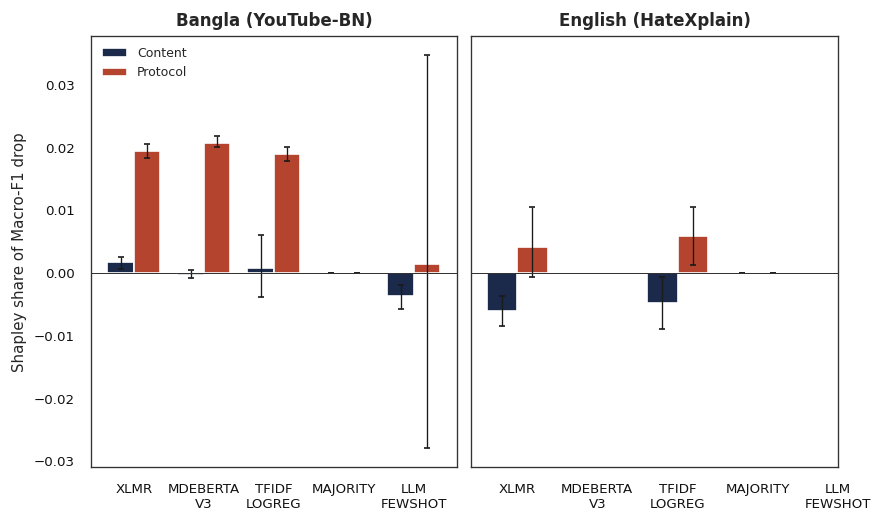


CELL 124 completed.
Tables saved to: E:\Research\Attributing Cross-Corpus Failure\results\tables
Figures saved to: E:\Research\Attributing Cross-Corpus Failure\results\figures

Generated table files:
 - anchor_overlap.csv
 - control_protocol_matrix_raw.csv
 - control_protocol_matrix_summary.csv
 - corpus_summary.csv
 - correction_efficiency.csv
 - cross_anchor_consistency.csv
 - crosslanguage_shapley.csv
 - diag_protocol_corrected_vs_erm.csv
 - dominant_factor_uncertainty_aware.csv
 - factorial_results.csv
 - factorial_results_hx_annotator_ERM_XLMR_MAJORITY_TFIDF_LOGREG_all.csv
 - factorial_results_power.csv
 - factorial_results_v2.csv
 - factorial_results_v2_llm.csv
 - factorial_results_v2_llm_LLM_FEWSHOT_all.csv
 - hx_agreement_audit.csv
 - hx_intervention_audit.csv
 - hx_shapley_seed_level.csv
 - hx_shapley_summary.csv
 - hx_shapley_table.csv
 - hx_signflip_tests.csv
 - hx_single_annotator_vs_gold.csv
 - hx_transition_matrix.csv
 - intervention_audit.csv
 - leaderboard_reversal.csv

In [ ]:

# ===================== CELL 124 =====================


from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



INPUT_ROOT = Path(
    r"E:\Research\Attributing Cross-Corpus Failure\results"
)

OUT_ROOT = Path(
    r"E:\Research\Attributing Cross-Corpus Failure\results"
)

TABLE_DIR = OUT_ROOT / "tables"
FIG_DIR = OUT_ROOT / "figures"

TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

BN_TABLE_DIR = INPUT_ROOT / "tables"

print("YouTube-BN input directory:", BN_TABLE_DIR)
print("HateXplain/output directory:", TABLE_DIR)
print("Figure directory:", FIG_DIR)



def complete_groups(df, n_cells=4):
    """Keep (model, seed) groups containing all four factorial cells."""

    required = {"model", "seed", "content_on", "protocol_on"}
    missing = required - set(df.columns)

    if missing:
        raise ValueError(
            f"Missing required factorial columns: {sorted(missing)}"
        )

    df = df.drop_duplicates(
        ["model", "seed", "content_on", "protocol_on"],
        keep="last"
    ).copy()

    cell_counts = df.groupby(["model", "seed"]).size()
    valid_groups = cell_counts[cell_counts == n_cells].index

    result = (
        df.set_index(["model", "seed"])
          .loc[valid_groups]
          .reset_index()
    )

    return result




def hx_load_results(mode=None):
    mode = mode or HX_PROTOCOL_MODE

    patterns = [
        f"factorial_results_hx_{mode}*.csv",
    ]

    files = []
    for pattern in patterns:
        files.extend(TABLE_DIR.glob(pattern))

    files = sorted(set(files))

    if not files:
        raise FileNotFoundError(
            "No HateXplain result files found.\n"
            f"Directory checked: {TABLE_DIR}\n"
            f"Protocol mode: {mode}\n"
            "Run CELL 123 first, or change the directory if its "
            "result files are stored elsewhere."
        )

    print("\nHateXplain files:")
    for path in files:
        print(" -", path.name)

    frames = [pd.read_csv(path) for path in files]

    df = pd.concat(frames, ignore_index=True)
    df = df.drop_duplicates(
        ["model", "seed", "content_on", "protocol_on"],
        keep="last"
    )

    return df


HX_RAW = hx_load_results()
HX_RES = complete_groups(HX_RAW)

if HX_RES.empty:
    raise ValueError(
        "HateXplain results contain no complete four-cell "
        "(model, seed) groups."
    )

print("\nHateXplain complete seeds per model:")
display(
    HX_RES.groupby("model")["seed"]
    .nunique()
    .rename("n_complete_seeds")
    .to_frame()
    .T
)



HX_ATTR = attribution_table(HX_RES)
HX_ATTR_SUMMARY = summarize_attribution(HX_ATTR)

required_metrics = [
    "phi_content",
    "phi_protocol",
    "interaction",
    "total_drop",
]

_piv = HX_ATTR_SUMMARY.pivot(
    index="model",
    columns="metric",
    values="mean"
)[required_metrics]

_ci = (
    HX_ATTR_SUMMARY.assign(
        ci=lambda d: d.apply(
            lambda r: f"[{r.ci_low:+.3f}, {r.ci_high:+.3f}]",
            axis=1
        )
    )
    .pivot(index="model", columns="metric", values="ci")
    [["phi_content", "phi_protocol"]]
    .add_suffix("_ci95")
)

HX_TABLE = _piv.join(_ci)

print("\nHateXplain Shapley summary:")
display(HX_TABLE.round(4))

HX_ATTR.to_csv(
    TABLE_DIR / "hx_shapley_seed_level.csv",
    index=False
)

HX_ATTR_SUMMARY.to_csv(
    TABLE_DIR / "hx_shapley_summary.csv",
    index=False
)

HX_TABLE.to_csv(
    TABLE_DIR / "hx_shapley_table.csv"
)


_rows = []

for model, group in HX_ATTR.groupby("model"):
    _rows.append({
        "model": model,
        "n_seeds": len(group),
        "p_signflip_phi_content": paired_randomization_p(
            group["phi_content"].to_numpy()
        ),
        "p_signflip_phi_protocol": paired_randomization_p(
            group["phi_protocol"].to_numpy()
        ),
    })

HX_TESTS = pd.DataFrame(_rows)

print("\nHateXplain paired sign-flip tests:")
display(HX_TESTS.round(4))

HX_TESTS.to_csv(
    TABLE_DIR / "hx_signflip_tests.csv",
    index=False
)



BN_TO_HX = {
    "ERM": "ERM_XLMR",
    "ERM_MDEBERTA_V3": "ERM_MDEBERTA_V3",
    "TFIDF_LOGREG": "TFIDF_LOGREG",
    "MAJORITY": "MAJORITY",
    "LLM_FEWSHOT": "LLM_FEWSHOT",
}

bn_files = []

base_file = BN_TABLE_DIR / "factorial_results.csv"

if base_file.exists():
    bn_files.append(base_file)

bn_files.extend(
    sorted(BN_TABLE_DIR.glob("factorial_results_v2*.csv"))
)

bn_files = sorted(set(bn_files))

if not bn_files:
    available = (
        sorted(p.name for p in BN_TABLE_DIR.glob("*.csv"))
        if BN_TABLE_DIR.exists()
        else []
    )

    raise FileNotFoundError(
        "No YouTube-BN factorial result files found.\n"
        f"Directory checked: {BN_TABLE_DIR}\n"
        f"Directory exists: {BN_TABLE_DIR.exists()}\n"
        f"CSV files available: {available}\n"
        "Check the input dataset path and filenames."
    )

print("\nYouTube-BN files:")
for path in bn_files:
    print(" -", path.name)

_bn_parts = [pd.read_csv(path) for path in bn_files]

BN_RAW = pd.concat(_bn_parts, ignore_index=True)

BN_RAW = BN_RAW.drop_duplicates(
    ["model", "seed", "content_on", "protocol_on"],
    keep="last"
)

BN_RES = complete_groups(BN_RAW)

if BN_RES.empty:
    raise ValueError(
        "YouTube-BN files were found, but no complete four-cell "
        "(model, seed) groups remain."
    )

print("\nYouTube-BN complete seeds per model:")
display(
    BN_RES.groupby("model")["seed"]
    .nunique()
    .rename("n_complete_seeds")
    .to_frame()
    .T
)

BN_ATTR = attribution_table(BN_RES)



XL_ROWS = []

for bn_arm, hx_arm in BN_TO_HX.items():

    for lang, attr, arm in [
        ("Bangla (YouTube-BN)", BN_ATTR, bn_arm),
        ("English (HateXplain)", HX_ATTR, hx_arm),
    ]:

        group = attr[attr["model"] == arm]

        if group.empty:
            print(
                f"Skipping {lang}, model {arm}: "
                "no matching attribution rows."
            )
            continue

        mc, lc, hc = bootstrap_ci(
            group["phi_content"].to_numpy()
        )

        mp, lp, hp = bootstrap_ci(
            group["phi_protocol"].to_numpy()
        )

        XL_ROWS.append({
            "arm": hx_arm,
            "language": lang,
            "n_seeds": len(group),
            "phi_content": mc,
            "phi_content_lo": lc,
            "phi_content_hi": hc,
            "phi_protocol": mp,
            "phi_protocol_lo": lp,
            "phi_protocol_hi": hp,
        })

XLANG = pd.DataFrame(
    XL_ROWS,
    columns=[
        "arm",
        "language",
        "n_seeds",
        "phi_content",
        "phi_content_lo",
        "phi_content_hi",
        "phi_protocol",
        "phi_protocol_lo",
        "phi_protocol_hi",
    ]
)

print("\nCross-language Shapley comparison:")
display(XLANG.round(4))

XLANG.to_csv(
    TABLE_DIR / "crosslanguage_shapley.csv",
    index=False
)


if not XLANG.empty:

    fig, axes = plt.subplots(
        1, 2,
        figsize=FIG_STYLE_2COL,
        sharey=True
    )

    arms = list(dict.fromkeys(XLANG["arm"]))
    x = np.arange(len(arms))
    w = 0.38

    languages = [
        "Bangla (YouTube-BN)",
        "English (HateXplain)",
    ]

    for ax, lang in zip(axes, languages):

        d = (
            XLANG[XLANG["language"] == lang]
            .set_index("arm")
            .reindex(arms)
        )

        for offset, key, col, label in [
            (-w / 2, "phi_content", FIG_STYLE_PALETTE[0], "Content"),
            (+w / 2, "phi_protocol", FIG_STYLE_PALETTE[1], "Protocol"),
        ]:

            values = d[key].to_numpy(dtype=float)
            lower = d[key + "_lo"].to_numpy(dtype=float)
            upper = d[key + "_hi"].to_numpy(dtype=float)

            valid = (
                np.isfinite(values)
                & np.isfinite(lower)
                & np.isfinite(upper)
            )

            if not valid.any():
                continue

            yerr = np.vstack([
                np.maximum(values[valid] - lower[valid], 0),
                np.maximum(upper[valid] - values[valid], 0),
            ])

            ax.bar(
                x[valid] + offset,
                values[valid],
                w,
                color=col,
                label=label,
                yerr=yerr,
                error_kw={
                    "elinewidth": 0.8,
                    "capsize": 2,
                },
            )

        ax.axhline(0, color="#333333", lw=0.6)

        ax.set_xticks(x)
        ax.set_xticklabels(
            [
                arm.replace("ERM_", "").replace("_", "\n")
                for arm in arms
            ],
            rotation=0,
        )

        ax.set_title(lang)

    axes[0].set_ylabel("Shapley share of Macro-F1 drop")
    axes[0].legend(frameon=False)

    fig.tight_layout()

    fig.savefig(
        FIG_DIR / "fig_crosslanguage_shapley.png",
        dpi=300,
        bbox_inches="tight",
    )

    fig.savefig(
        FIG_DIR / "fig_crosslanguage_shapley.pdf",
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

else:
    print(
        "No matching models were available for the cross-language "
        "comparison; the figure was not generated."
    )



print("\nCELL 124 completed.")
print("Tables saved to:", TABLE_DIR)
print("Figures saved to:", FIG_DIR)

print("\nGenerated table files:")
for path in sorted(TABLE_DIR.glob("*.csv")):
    print(" -", path.name)

print("\nGenerated cross-language figures:")
for name in [
    "fig_crosslanguage_shapley.png",
    "fig_crosslanguage_shapley.pdf",
]:
    path = FIG_DIR / name
    if path.exists():
        print(" -", path)


### 12.1 Control experiment: Is the protocol effect driven by noise rate or asymmetry?

The primary factorial applies a single declared transition matrix $T$ (asymmetric, mean flip rate 15%). A reviewer might reasonably ask whether the observed protocol contribution $\phi_p$ is an artifact of this specific matrix, or whether it is driven by the *noise rate* itself. To answer this, we run a control experiment on the fast TF--IDF arm across **three noise structures**:

1. **Declared asymmetric (0.10/0.20):** the primary matrix, mean flip rate 15%, asymmetric.
2. **Symmetric 15% (0.15/0.15):** same mean flip rate, no asymmetry (no label-prior shift).
3. **Symmetric 10% (0.10/0.10):** lower noise rate, no asymmetry.

We report both Macro-F1 and AUROC. This is because a prior shift (asymmetry) moves the decision threshold and therefore Macro-F1, but it does not change the ranking of examples (AUROC); pure label noise degrades both. The control is run with **20 seeds** (the 5 primary seeds plus the 15 power-extension seeds), identical to the seed count used for the TF--IDF arm in the main factorial.

In [ ]:
# ===================== CELL 125 =====================

import itertools, time
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, f1_score

CTRL_SEEDS = [11, 17, 23, 29, 31, 37, 41, 43, 47, 53, 59, 61, 67, 71, 73]   
CTRL_MATRICES = {   
    "declared_asym_10_20": np.array([[0.90, 0.10], [0.20, 0.80]]),   
    "symmetric_15_15":     np.array([[0.85, 0.15], [0.15, 0.85]]),   
    "symmetric_10_10":     np.array([[0.90, 0.10], [0.10, 0.90]]),   
}

def _tfidf_run(cell, seed):
    tr, va, te = cell["train"], cell["val"], cell["test"]
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=100000, sublinear_tf=True)
    X = vec.fit_transform(tr["text"].astype(str))
    clf = LogisticRegression(max_iter=500, solver="liblinear", random_state=seed).fit(X, tr["observed_label"].astype(int))
    pv = clf.predict_proba(vec.transform(va["text"].astype(str)))[:, 1]
    pt = clf.predict_proba(vec.transform(te["text"].astype(str)))[:, 1]
    thr = select_threshold(va["true_label"].astype(int).to_numpy(), pv)  
    y = te["true_label"].astype(int).to_numpy()
    return {"macro_f1": f1_score(y, (pt >= thr).astype(int), average="macro"), "auroc": roc_auc_score(y, pt),
            "train_obs_pos": float(tr["observed_label"].mean()), "train_true_pos": float(tr["true_label"].mean())}

def _shapley(g, metric):
    m = {(int(c), int(p)): v for c, p, v in zip(g["content_on"], g["protocol_on"], g[metric])}
    phi_c = 0.5 * ((m[0, 0] - m[1, 0]) + (m[0, 1] - m[1, 1]))
    phi_p = 0.5 * ((m[0, 0] - m[0, 1]) + (m[1, 0] - m[1, 1]))
    return phi_c, phi_p, m[0, 0] - m[1, 1], m[0, 0] - m[1, 0] - m[0, 1] + m[1, 1]

def _boot(x, n=5000, seed=7):
    x = np.asarray(x, float); rng = np.random.default_rng(seed)
    b = rng.choice(x, size=(n, len(x)), replace=True).mean(1)
    return float(x.mean()), float(np.percentile(b, 2.5)), float(np.percentile(b, 97.5))

def run_control(name, build_fn, set_mode=None):
    saved_T = CFG.PROTOCOL_TRANSITION.copy(); rows = []; t0 = time.time()
    try:
        clean = {}
        for s in CTRL_SEEDS:
            for c in (0, 1):
                clean[(s, c)] = _tfidf_run(build_fn(c, 0, s), s)
        for mname, T in CTRL_MATRICES.items():
            CFG.PROTOCOL_TRANSITION = T.copy()
            if set_mode: set_mode("declared")
            for s in CTRL_SEEDS:
                for c in (0, 1):
                    rows.append({"dataset": name, "matrix": mname, "seed": s, "content_on": c, "protocol_on": 0, **clean[(s, c)]})
                    rows.append({"dataset": name, "matrix": mname, "seed": s, "content_on": c, "protocol_on": 1, **_tfidf_run(build_fn(c, 1, s), s)})
            print(f"[{name}] {mname} done ({time.time() - t0:.0f}s)")
    finally:
        CFG.PROTOCOL_TRANSITION = saved_T
    return pd.DataFrame(rows)

CTRL_FRAMES = []
CTRL_FRAMES.append(run_control("YouTube-BN", build_factorial_cell))
if "build_cell_hx" in globals() and "HX_SPLITS" in globals():
    _old_mode = HX_PROTOCOL_MODE
    def _set_hx_mode(m):
        globals()["HX_PROTOCOL_MODE"] = m
    try:
        CTRL_FRAMES.append(run_control("HateXplain", build_cell_hx, set_mode=_set_hx_mode))
    finally:
        globals()["HX_PROTOCOL_MODE"] = _old_mode
else:
    print("HateXplain cells (120-122) not found in this session -> HateXplain control skipped.")

CTRL_RAW = pd.concat(CTRL_FRAMES, ignore_index=True)
out = []
for (ds, mn), g in CTRL_RAW.groupby(["dataset", "matrix"]):
    pr = g[g.protocol_on == 1]
    for metric in ("macro_f1", "auroc"):
        per_seed = np.array([_shapley(gs, metric) for _, gs in g.groupby("seed")])
        row = {"dataset": ds, "matrix": mn, "metric": metric, "n_seeds": per_seed.shape[0],
               "train_true_pos": pr.train_true_pos.mean(), "train_obs_pos": pr.train_obs_pos.mean()}
        for k, nm in enumerate(["phi_content", "phi_protocol", "total_drop", "interaction"]):
            mean, lo, hi = _boot(per_seed[:, k]); row.update({nm: mean, nm + "_lo": lo, nm + "_hi": hi})
        out.append(row)
CTRL_SUMMARY = pd.DataFrame(out)
(OUT_ROOT / "tables").mkdir(parents=True, exist_ok=True)
CTRL_RAW.to_csv(OUT_ROOT / "tables" / "control_protocol_matrix_raw.csv", index=False)
CTRL_SUMMARY.to_csv(OUT_ROOT / "tables" / "control_protocol_matrix_summary.csv", index=False)
display(CTRL_SUMMARY[["dataset", "matrix", "metric", "n_seeds", "train_true_pos", "train_obs_pos",
                      "phi_protocol", "phi_protocol_lo", "phi_protocol_hi", "phi_content", "phi_content_lo", "phi_content_hi"]].round(4))
print("Saved: control_protocol_matrix_raw.csv / control_protocol_matrix_summary.csv in", OUT_ROOT / "tables")

loaded factorial_results.csv                                   rows= 120
loaded factorial_results_v2.csv                                rows=  40
loaded factorial_results_v2_llm.csv                            rows=  20
loaded factorial_results_v2_llm_LLM_FEWSHOT_all.csv            rows=  20


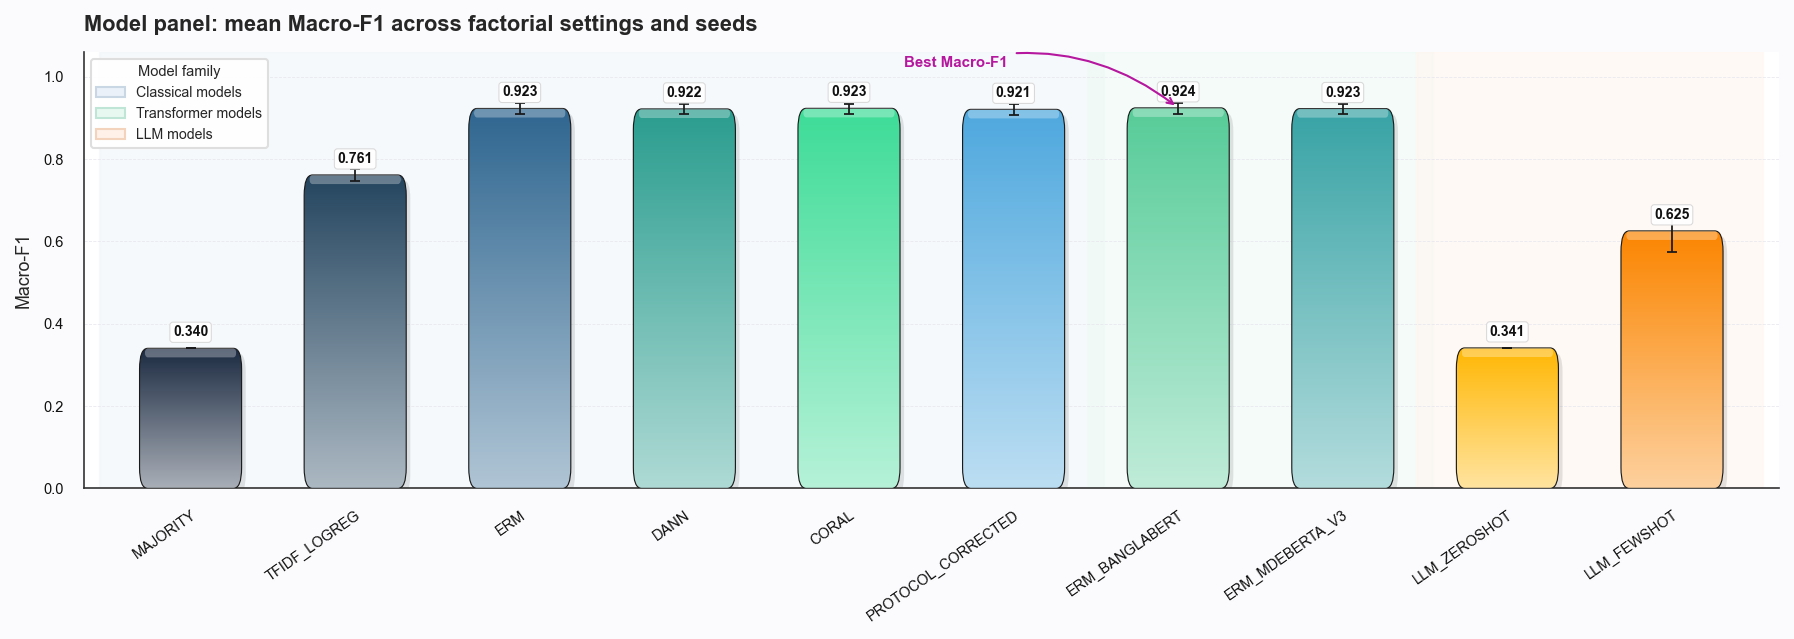


Saved ultimate premium figures:
- E:\Research\Attributing Cross-Corpus Failure\results\figures\fig_model_panel_macro_f1.pdf
- E:\Research\Attributing Cross-Corpus Failure\results\figures\fig_model_panel_macro_f1.svg
- E:\Research\Attributing Cross-Corpus Failure\results\figures\fig_model_panel_macro_f1.png


In [ ]:
# ===================== CELL 40 (ULTIMATE PREMIUM STYLE) =====================
# Model-panel Macro-F1 comparison
# Rounded gradient bars + soft shadows + category legend + value pills

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyBboxPatch, Rectangle
from matplotlib.ticker import MultipleLocator
from matplotlib.transforms import Bbox

TABLES_DIR = OUT_ROOT / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# 1. Load all factorial result files
_frames = []
_candidates = [TABLES_DIR / "factorial_results.csv"] + \
              sorted(TABLES_DIR.glob("factorial_results_v2*.csv"))

for p in _candidates:
    if p.exists() and p.stat().st_size > 0:
        d = pd.read_csv(p)
        d["source_file"] = p.name
        _frames.append(d)

        print(
            f"loaded {p.name:55s} "
            f"rows={len(d):4d}"
        )

if not _frames:
    print("No factorial result files found yet.")

else:
    ALL = pd.concat(_frames, ignore_index=True)

    for c in ["seed", "content_on", "protocol_on"]:
        ALL[c] = ALL[c].astype(int)

    ALL = ALL.drop_duplicates(
        ["model", "seed", "content_on", "protocol_on"],
        keep="last"
    ).reset_index(drop=True)

    cell_counts = ALL.groupby(["model", "seed"]).size()
    complete_keys = cell_counts[cell_counts == 4].index.to_frame(index=False)
    ALL = ALL.merge(complete_keys, on=["model", "seed"], how="inner")

    DESIRED_ORDER = [
        "MAJORITY",
        "TFIDF_LOGREG",
        "ERM",
        "DANN",
        "CORAL",
        "PROTOCOL_CORRECTED",
        "ERM_BANGLABERT",
        "ERM_MDEBERTA_V3",
        "LLM_ZEROSHOT",
        "LLM_FEWSHOT",
        "GEMINI_ZEROSHOT",
        "GEMINI_FEWSHOT",
    ]

    present = [m for m in DESIRED_ORDER if m in ALL["model"].unique()]
    extra = [m for m in ALL["model"].unique() if m not in DESIRED_ORDER]
    order = present + sorted(extra)

    stats_df = (
        ALL.groupby("model")["macro_f1"]
        .agg(
            mean="mean",
            lo=lambda x: np.percentile(x, 2.5),
            hi=lambda x: np.percentile(x, 97.5)
        )
        .reindex(order)
    )

    model_means = stats_df["mean"]

    base_colors = [
        "#1B2A41",  # MAJORITY — deep navy
        "#24455F",  # TFIDF_LOGREG — dark slate
        "#2F6690",  # ERM — royal blue
        "#2A9D8F",  # DANN — deep teal
        "#3DDC97",  # CORAL — emerald
        "#4EA8DE",  # PROTOCOL_CORRECTED — sky blue
        "#57CC99",  # ERM_BANGLABERT — mint
        "#38A3A5",  # ERM_MDEBERTA_V3 — ocean teal
        "#FFB703",  # LLM_ZEROSHOT — golden amber
        "#FB8500",  # LLM_FEWSHOT — vivid orange
        "#E63946",  # GEMINI_ZEROSHOT — crimson
        "#7B2CBF"   # GEMINI_FEWSHOT — royal purple
    ]

    if len(order) > len(base_colors):
        extra_cmap = plt.cm.viridis

        for i in range(len(order) - len(base_colors)):
            rgba = extra_cmap(i / max(1, len(order) - len(base_colors)))

            base_colors.append(
                "#{:02x}{:02x}{:02x}".format(
                    int(rgba[0] * 255),
                    int(rgba[1] * 255),
                    int(rgba[2] * 255)
                )
            )

    base_colors = base_colors[:len(order)]

    gradient_colors = []

    for hex_color in base_colors:
        r = int(hex_color[1:3], 16) / 255
        g = int(hex_color[3:5], 16) / 255
        b = int(hex_color[5:7], 16) / 255

        light = (
            min(1, r * 0.38 + 0.62),
            min(1, g * 0.38 + 0.62),
            min(1, b * 0.38 + 0.62)
        )

        dark = (r, g, b)

        gradient_colors.append((light, dark))

    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
        "font.size": 8,
        "axes.titlesize": 10.5,
        "axes.labelsize": 8.5,
        "xtick.labelsize": 7,
        "ytick.labelsize": 7,
        "axes.linewidth": 0.8,
        "xtick.major.width": 0.7,
        "ytick.major.width": 0.7,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.facecolor": "#FBFBFD",
        "axes.facecolor": "#FFFFFF",
        "figure.dpi": 150,
        "savefig.dpi": 600,
        "savefig.bbox": "tight"
    })

    fig, ax = plt.subplots(figsize=(12.0, 4.3))

    x_positions = np.arange(len(order))
    bar_width = 0.62
    N_SEGMENTS = 100

    group_spans = [
        (0, 5, "#F2F6FA", "Classical models"),
        (6, 7, "#EFFAF5", "Transformer models"),
        (8, 11, "#FFF6F0", "LLM models")
    ]

    for start, end, color, label in group_spans:
        if start < len(order):
            ax.axvspan(
                start - 0.55,
                min(end, len(order) - 1) + 0.55,
                color=color,
                alpha=0.65,
                zorder=0
            )

    for x, value, (light, dark) in zip(
        x_positions, model_means.values, gradient_colors
    ):
        cmap = LinearSegmentedColormap.from_list(
            "premium_gradient",
            [light, dark]
        )

        shadow = FancyBboxPatch(
            (x - bar_width / 2 + 0.025, -0.012),
            bar_width,
            value,
            boxstyle="round,pad=0,rounding_size=0.045",
            facecolor="#000000",
            alpha=0.10,
            edgecolor="none",
            zorder=2
        )
        ax.add_patch(shadow)

        rounded_bar = FancyBboxPatch(
            (x - bar_width / 2, 0),
            bar_width,
            value,
            boxstyle="round,pad=0,rounding_size=0.05",
            facecolor="none",
            edgecolor="#1A1A1A",
            linewidth=0.55,
            zorder=4
        )
        ax.add_patch(rounded_bar)

        gradient = np.linspace(0, 1, 256).reshape(-1, 1)

        im = ax.imshow(
            gradient,
            extent=[
                x - bar_width / 2,
                x + bar_width / 2,
                0,
                value
            ],
            aspect="auto",
            cmap=cmap,
            origin="lower",
            zorder=3
        )

        im.set_clip_path(rounded_bar)

        glow = FancyBboxPatch(
            (x - bar_width / 2 + 0.03, value - min(0.022, value * 0.07)),
            bar_width - 0.06,
            min(0.022, value * 0.07),
            boxstyle="round,pad=0,rounding_size=0.02",
            facecolor="white",
            alpha=0.30,
            edgecolor="none",
            zorder=5
        )
        ax.add_patch(glow)

    for i, row in enumerate(stats_df.itertuples()):
        ax.errorbar(
            i,
            row.mean,
            yerr=[[row.mean - row.lo], [row.hi - row.mean]],
            fmt="none",
            ecolor="#1A1A1A",
            elinewidth=0.85,
            capsize=2.5,
            capthick=0.85,
            zorder=7
        )

    for x, value in zip(x_positions, model_means.values):
        ax.text(
            x,
            value + 0.022,
            f"{value:.3f}",
            ha="center",
            va="bottom",
            fontsize=6.8,
            fontweight="bold",
            color="#111111",
            bbox=dict(
                boxstyle="round,pad=0.22",
                facecolor="white",
                edgecolor="#D8D8D8",
                linewidth=0.5,
                alpha=0.97
            ),
            zorder=8
        )

    best_index = int(np.argmax(model_means.values))
    best_value = model_means.values[best_index]

    ax.annotate(
        "Best Macro-F1",
        xy=(best_index, best_value),
        xytext=(best_index - 1.35, best_value + 0.10),
        fontsize=7.2,
        fontweight="bold",
        color="#B5179E",
        ha="center",
        arrowprops=dict(
            arrowstyle="->",
            color="#B5179E",
            linewidth=1.0,
            connectionstyle="arc3,rad=-0.25"
        ),
        zorder=9
    )

    ax.set_xlim(-0.65, len(order) - 0.35)
    ax.set_ylim(0, 1.06)

    ax.set_xticks(x_positions)
    ax.set_xticklabels(
        order,
        rotation=35,
        ha="right",
        rotation_mode="anchor"
    )

    ax.set_ylabel("Macro-F1", labelpad=5)

    ax.set_title(
        "Model panel: mean Macro-F1 across factorial settings and seeds",
        loc="left",
        fontsize=10.5,
        fontweight="bold",
        pad=10
    )

    ax.yaxis.set_major_locator(MultipleLocator(0.2))

    ax.grid(
        axis="y",
        linestyle="--",
        linewidth=0.4,
        color="#E8E8EE",
        alpha=0.95,
        zorder=1
    )

    ax.set_axisbelow(True)

    legend_handles = [
        plt.Rectangle((0, 0), 1, 1, facecolor="#EAF1F8", edgecolor="#C9D6E3", label="Classical models"),
        plt.Rectangle((0, 0), 1, 1, facecolor="#E7F8F1", edgecolor="#BFE5D6", label="Transformer models"),
        plt.Rectangle((0, 0), 1, 1, facecolor="#FFF1E8", edgecolor="#F3D3BC", label="LLM models"),
    ]

    ax.legend(
        handles=legend_handles,
        loc="upper left",
        frameon=True,
        framealpha=0.95,
        edgecolor="#DDDDDD",
        fontsize=6.8,
        title="Model family",
        title_fontsize=7
    )
    plt.tight_layout()
    fig.savefig(FIG_DIR / "fig_model_panel_macro_f1.pdf")
    fig.savefig(FIG_DIR / "fig_model_panel_macro_f1.svg")
    fig.savefig(
        FIG_DIR / "fig_model_panel_macro_f1.png",
        dpi=600,
        bbox_inches="tight"
    )

    plt.show()

    print(
        f"\nSaved ultimate premium figures:\n"
        f"- {FIG_DIR / 'fig_model_panel_macro_f1.pdf'}\n"
        f"- {FIG_DIR / 'fig_model_panel_macro_f1.svg'}\n"
        f"- {FIG_DIR / 'fig_model_panel_macro_f1.png'}"
    )

In [ ]:
# ===================== CELL 126- we run this cell in kaggle =====================
import itertools
from pathlib import Path
from sklearn.metrics import roc_auc_score, f1_score

DIAG_MODELS = ["ERM", "PROTOCOL_CORRECTED"]
CKPT_DIR = Path("/kaggle/input/datasets/slytherin401533/checkpoints/checkpoints")
DIAG_CELLS = [(0, 1)]
DIAG_SEEDS = list(CFG.SEEDS)[:3]

_need = [f"{m}_c{c}_p{p}_s{s}.pt" for m in DIAG_MODELS for s in DIAG_SEEDS for c, p in DIAG_CELLS]
_missing = [n for n in _need if not (CKPT_DIR / n).exists()]
print(f"checkpoints found: {len(_need) - len(_missing)} / {len(_need)}")
if _missing:
    print("MISSING:", _missing)
    print("Files actually present (first 10):", [p.name for p in sorted(CKPT_DIR.glob('*.pt'))][:10] if CKPT_DIR.exists() else "CKPT_DIR does not exist")
    raise FileNotFoundError("Fix CKPT_DIR / seeds before continuing.")

def _load_ckpt(path):
    return torch.load(path, map_location=DEVICE, weights_only=False)

@torch.no_grad()
def _probs(model, loader):
    model.eval(); ys, ps = [], []
    for batch in loader:
        batch = move_batch(batch)
        logits, _, _ = model(batch["input_ids"], batch["attention_mask"])
        ps.append(logits.float().softmax(-1)[:, 1].cpu().numpy()); ys.append(batch["labels"].cpu().numpy())
    return np.concatenate(ys), np.concatenate(ps)

def _macro(y, p, t):
    return f1_score(y, (p >= t).astype(int), average="macro")

rows = []
for model_kind, seed in itertools.product(DIAG_MODELS, DIAG_SEEDS):
    for c, p in DIAG_CELLS:
        ck = CKPT_DIR / f"{model_kind}_c{c}_p{p}_s{seed}.pt"
        if not ck.exists():
            print("missing:", ck.name); continue
        cell = build_factorial_cell(c, p, seed)
        model = ShiftModel(CFG.BACKBONE).to(DEVICE)
        payload = _load_ckpt(ck)
        print("checkpoint keys:", list(payload.keys())) if not rows else None
        model.load_state_dict(payload["state_dict"]); model.eval()
        del payload
        val_obs = make_loader(cell["val"], "observed_label", domain=0, shuffle=False, batch_size=CFG.EVAL_BATCH_SIZE)
        test_ld = make_loader(cell["test"].assign(observed_label=cell["test"]["true_label"]), "observed_label", domain=1, shuffle=False, batch_size=CFG.EVAL_BATCH_SIZE)
        yv_obs, pv = _probs(model, val_obs)
        yv_clean = cell["val"]["true_label"].astype(int).to_numpy()
        yt, pt = _probs(model, test_ld)
        t_noisy, t_clean = select_threshold(yv_obs, pv), select_threshold(yv_clean, pv)
        rows.append({"model": model_kind, "seed": seed, "content_on": c, "protocol_on": p,
                     "auroc": roc_auc_score(yt, pt),
                     "f1_thr_noisy_val": _macro(yt, pt, t_noisy), "f1_thr_0.5": _macro(yt, pt, 0.5),
                     "f1_thr_clean_val_oracle": _macro(yt, pt, t_clean),
                     "thr_noisy": t_noisy, "thr_clean": t_clean, "mean_prob_test": float(pt.mean())})
        print(f"done {model_kind} seed {seed}")
        del model
        if torch.cuda.is_available(): torch.cuda.empty_cache()

DIAG = pd.DataFrame(rows)
DIAG.to_csv(OUT_ROOT / "tables" / "diag_protocol_corrected_vs_erm.csv", index=False)
cols = ["auroc", "f1_thr_noisy_val", "f1_thr_0.5", "f1_thr_clean_val_oracle", "thr_noisy", "thr_clean"]
display(DIAG.groupby(["protocol_on", "model"])[cols].mean().round(4))
if {"ERM", "PROTOCOL_CORRECTED"}.issubset(set(DIAG.model)):
    piv = DIAG[DIAG.protocol_on == 1].pivot(index="seed", columns="model", values=cols)
    for m in cols[:4]:
        d = (piv[m]["PROTOCOL_CORRECTED"] - piv[m]["ERM"]).dropna()
        print(f"PC - ERM  {m:26s} mean {d.mean():+.4f}   per-seed {np.round(d.to_numpy(), 4).tolist()}")

In [139]:
# PART 1: TF-IDF 
print("--- PART 1: TF-IDF (20 seeds from two files) ---")

df_main = pd.read_csv('./results/tables/factorial_results.csv')
tfidf_main = df_main[df_main['model'] == 'TFIDF_LOGREG']


df_summary = pd.read_csv('./results/tables/control_protocol_matrix_summary.csv')
tfidf_extra = df_summary[
    (df_summary['dataset'] == 'YouTube-BN') & 
    (df_summary['matrix'] == 'declared_asym_10_20') & 
    (df_summary['metric'] == 'macro_f1')
]

phi_c_main, phi_p_main = [], []
for seed in tfidf_main['seed'].unique():
    s = tfidf_main[tfidf_main['seed'] == seed]
    v00 = s[(s['content_on']==0) & (s['protocol_on']==0)]['macro_f1'].values[0]
    v10 = s[(s['content_on']==1) & (s['protocol_on']==0)]['macro_f1'].values[0]
    v01 = s[(s['content_on']==0) & (s['protocol_on']==1)]['macro_f1'].values[0]
    v11 = s[(s['content_on']==1) & (s['protocol_on']==1)]['macro_f1'].values[0]
    phi_c_main.append(0.5 * ((v00 - v10) + (v01 - v11)))
    phi_p_main.append(0.5 * ((v00 - v01) + (v10 - v11)))


phi_c_extra = tfidf_extra['phi_content'].values
phi_p_extra = tfidf_extra['phi_protocol'].values

phi_c_all = phi_c_main + list(phi_c_extra)
phi_p_all = phi_p_main + list(phi_p_extra)

def get_ci(data, n_boot=5000, seed=42):
    rng = np.random.default_rng(seed)
    data = np.array(data)
    boot_means = [rng.choice(data, size=len(data), replace=True).mean() for _ in range(n_boot)]
    return np.mean(data), np.percentile(boot_means, 2.5), np.percentile(boot_means, 97.5)

tfidf_c_mean, tfidf_c_lo, tfidf_c_hi = get_ci(phi_c_all)
tfidf_p_mean, tfidf_p_lo, tfidf_p_hi = get_ci(phi_p_all)

print(f"TF-IDF φ_c: {tfidf_c_mean:.4f} [{tfidf_c_lo:.4f}, {tfidf_c_hi:.4f}]")
print(f"TF-IDF φ_p: {tfidf_p_mean:.4f} [{tfidf_p_lo:.4f}, {tfidf_p_hi:.4f}]")
print("-" * 50)


# PART 2: BanglaBERT and mDeBERTa 
print("\n--- PART 2: BanglaBERT & mDeBERTa (5 seeds) ---")
df_v2 = pd.read_csv('./results/tables/factorial_results_v2.csv')
def calculate_shapley_from_v2(model_name):
    model_df = df_v2[df_v2['model'] == model_name]
    phi_c_list, phi_p_list = [], []
    for seed in model_df['seed'].unique():
        s = model_df[model_df['seed'] == seed]
        v00 = s[(s['content_on']==0) & (s['protocol_on']==0)]['macro_f1'].values[0]
        v10 = s[(s['content_on']==1) & (s['protocol_on']==0)]['macro_f1'].values[0]
        v01 = s[(s['content_on']==0) & (s['protocol_on']==1)]['macro_f1'].values[0]
        v11 = s[(s['content_on']==1) & (s['protocol_on']==1)]['macro_f1'].values[0]
        phi_c_list.append(0.5 * ((v00 - v10) + (v01 - v11)))
        phi_p_list.append(0.5 * ((v00 - v01) + (v10 - v11)))
    c_mean, c_lo, c_hi = get_ci(phi_c_list)
    p_mean, p_lo, p_hi = get_ci(phi_p_list)
    print(f"{model_name} φ_c: {c_mean:.4f} [{c_lo:.4f}, {c_hi:.4f}]")
    print(f"{model_name} φ_p: {p_mean:.4f} [{p_lo:.4f}, {p_hi:.4f}]")
calculate_shapley_from_v2('ERM_BANGLABERT')
calculate_shapley_from_v2('ERM_MDEBERTA_V3')

--- PART 1: TF-IDF (20 seeds from two files) ---
TF-IDF φ_c: 0.0010 [-0.0033, 0.0051]
TF-IDF φ_p: 0.0195 [0.0183, 0.0209]
--------------------------------------------------

--- PART 2: BanglaBERT & mDeBERTa (5 seeds) ---
ERM_BANGLABERT φ_c: 0.0001 [-0.0037, 0.0025]
ERM_BANGLABERT φ_p: 0.0187 [0.0173, 0.0204]
ERM_MDEBERTA_V3 φ_c: -0.0002 [-0.0009, 0.0005]
ERM_MDEBERTA_V3 φ_p: 0.0207 [0.0201, 0.0218]
